In [512]:
# Carga de librerías

# Librerías generales
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import talib

# Librerías de Aprendizaje Automático
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


from sklearn.neural_network import MLPClassifier

# Metricas de evaluación
from sklearn.metrics import (
    accuracy_score, 
    balanced_accuracy_score, 
    precision_score,
    recall_score, 
    f1_score, 
    roc_auc_score, 
    classification_report,
    precision_recall_fscore_support
)

# APIs datos financieros
import yfinance as yf


from IPython.display import display
plt.style.use('seaborn-v0_8-darkgrid')



In [513]:
df_close.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2460 entries, 2020-01-06 to 2026-09-30
Freq: D
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Cardano                 2460 non-null   float64
 1   Bitcoin_Cash            2460 non-null   float64
 2   Bitcoin                 2460 non-null   float64
 3   Petroleo_WTI            2460 non-null   float64
 4   Yuan_Chino              2460 non-null   float64
 5   Indice_Dolar_DXY        2460 non-null   float64
 6   Ethereum                2460 non-null   float64
 7   Euro                    2460 non-null   float64
 8   Oro                     2460 non-null   float64
 9   Chainlink               2460 non-null   float64
 10  Litecoin                2460 non-null   float64
 11  Gas_Natural             2460 non-null   float64
 12  Bono_EEUU_5A            2460 non-null   float64
 13  S&P_500                 2460 non-null   float64
 14  Bono_EEUU_3M            2

# Obtención de los datos

In [514]:
# Lista de activos
tickers  = ["BTC-USD", # Precio de Bitcoin,
        "ETH-USD",
        "LTC-USD",
        "BCH-USD",
        "ADA-USD",
        "LINK-USD",
                        

        # Variables Macroeconomicas

        "^TNX", # Rendimiento de Bonos del Tesoro a 10 años
        "^IRX", # Rendimiento de Bonos del Tesoro a 3  meses
        "^FVX", # Rendimiento de Bonos del Tesoro a 5 años

        # Indices de Mercado
        "^GSPC", # Indice de Mercado SP500
        "^IXIC", # Indice de Mercado Sector Tecnologico
        "^N225", # Indice de Mercado Asiatico
        "^VIX", # Indice de Miedo

        # Divisas y Materias Primas
        "DX-Y.NYB", # Indice del Dolar
        "EURUSD=X", # Euro
        "CNYUSD=X", # Yuan Chino

        # Materias Primas
        "GC=F", # Oro
        "CL=F", # Petroleo
        "NG=F"
]

# Descarga de datos
df_raw = yf.download(tickers, start =  "2020-01-01", end  =  "2026-10-1", interval  =  "1d")
df_raw.head()


[*********************100%***********************]  19 of 19 completed


Price          Close                           ... Volume          
Ticker       ADA-USD     BCH-USD      BTC-USD  ...  ^N225 ^TNX ^VIX
Date                                           ...                 
2020-01-01  0.033458  204.397537  7200.174316  ...    NaN  NaN  NaN
2020-01-02  0.032751  195.698563  6985.470215  ...    NaN  0.0  0.0
2020-01-03  0.034180  222.412979  7344.884277  ...    NaN  0.0  0.0
2020-01-04  0.034595  226.018692  7410.656738  ...    NaN  NaN  NaN
2020-01-05  0.034721  224.096527  7411.317383  ...    NaN  NaN  NaN

[5 rows x 95 columns]

# Preperación de los datos

In [515]:
# Guardar precios de Bitcoin para el calculo de indicadores técnicos
df_btc = df_raw.xs('BTC-USD', level=1, axis=1).copy()
# Guardar precios de cierre
df_close = df_raw["Close"].copy()
# Renombre de columnas de precio de cierre
nombres = {
    # Bitcoin y Ethereum
    "BTC-USD": "Bitcoin",
    "ETH-USD": "Ethereum",
    
    # Altcoins
    "ADA-USD": "Cardano",
    "BCH-USD": "Bitcoin_Cash",
    "LINK-USD": "Chainlink",
    "LTC-USD": "Litecoin",
    "SOL-USD": "Solana",
    
    # Commodities
    "CL=F": "Petroleo_WTI",
    "GC=F": "Oro",
    "NG=F": "Gas_Natural",
    
    # Divisas e Índices de Dólar
    "CNYUSD=X": "Yuan_Chino",
    "EURUSD=X": "Euro",
    "DX-Y.NYB": "Indice_Dolar_DXY",
    
    # Índices Bursátiles y Volatilidad
    "^GSPC": "S&P_500",
    "^IXIC": "NASDAQ_Tecnologico",
    "^N225": "Nikkei_Asia",
    "^VIX": "Indice_Volatilidad_VIX",
    
    # Bonos del Tesoro de EE. UU.
    "^IRX": "Bono_EEUU_3M",
    "^FVX": "Bono_EEUU_5A",
    "^TNX": "Bono_EEUU_10A",
}

df_close.rename(columns=nombres, inplace=True)
df_close


df_close.rename(columns  =  nombres, inplace  =  True)
df_close

Ticker,Cardano,Bitcoin_Cash,Bitcoin,Petroleo_WTI,Yuan_Chino,Indice_Dolar_DXY,Ethereum,Euro,Oro,Chainlink,Litecoin,Gas_Natural,Bono_EEUU_5A,S&P_500,Bono_EEUU_3M,NASDAQ_Tecnologico,Nikkei_Asia,Bono_EEUU_10A,Indice_Volatilidad_VIX
Date,,,,,,,,,,,,,,,,,,,
2020-01-01,0.033458,204.397537,7200.174316,NaN,0.143631,NaN,130.802002,1.122083,NaN,1.806640,42.017719,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,0.032751,195.698563,6985.470215,61.180000,0.143633,96.849998,127.410179,1.122083,1524.500000,1.741144,39.823013,2.122,1.671,3257.850098,1.495,9092.190430,NaN,1.882,12.470000
2020-01-03,0.034180,222.412979,7344.884277,63.049999,0.143608,96.839996,134.171707,1.117144,1549.199951,1.809708,42.415573,2.130,1.586,3234.850098,1.473,9020.769531,NaN,1.788,14.020000
2020-01-04,0.034595,226.018692,7410.656738,NaN,NaN,NaN,135.069366,NaN,NaN,1.840133,43.326607,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-05,0.034721,224.096527,7411.317383,NaN,NaN,NaN,136.276779,NaN,NaN,1.807787,43.553207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-26,0.254308,335.880829,84406.453125,NaN,NaN,NaN,2695.213135,NaN,NaN,14.154918,72.634254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-27,0.255515,332.838501,84458.085938,NaN,NaN,NaN,2686.926758,NaN,NaN,14.037887,71.325241,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-09-28,0.247124,310.383514,83502.609375,92.599998,0.148969,101.199997,2688.668701,1.137799,4168.399902,15.442647,69.224548,3.000,5.068,7683.689941,4.057,26820.380859,65877.617188,5.240,16.070000


In [516]:
df_close.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2465 entries, 2020-01-01 to 2026-09-30
Freq: D
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Cardano                 2465 non-null   float64
 1   Bitcoin_Cash            2465 non-null   float64
 2   Bitcoin                 2465 non-null   float64
 3   Petroleo_WTI            1697 non-null   float64
 4   Yuan_Chino              1756 non-null   float64
 5   Indice_Dolar_DXY        1697 non-null   float64
 6   Ethereum                2465 non-null   float64
 7   Euro                    1756 non-null   float64
 8   Oro                     1698 non-null   float64
 9   Chainlink               2465 non-null   float64
 10  Litecoin                2465 non-null   float64
 11  Gas_Natural             1698 non-null   float64
 12  Bono_EEUU_5A            1695 non-null   float64
 13  S&P_500                 1695 non-null   float64
 14  Bono_EEUU_3M            1

In [517]:
print("Número de valores faltantes")
df_close.isnull().sum()

Número de valores faltantes


Ticker
Cardano                     0
Bitcoin_Cash                0
Bitcoin                     0
Petroleo_WTI              768
Yuan_Chino                709
Indice_Dolar_DXY          768
Ethereum                    0
Euro                      709
Oro                       767
Chainlink                   0
Litecoin                    0
Gas_Natural               767
Bono_EEUU_5A              770
S&P_500                   770
Bono_EEUU_3M              770
NASDAQ_Tecnologico        770
Nikkei_Asia               820
Bono_EEUU_10A             770
Indice_Volatilidad_VIX    768
dtype: int64

In [518]:
# Limpieza de valores faltantes
df_close.ffill(inplace = True)
df_close.dropna(inplace  =  True)
print("Número de valores faltantes después de la imputación")
df_close.isnull().sum()

Número de valores faltantes después de la imputación


Ticker
Cardano                   0
Bitcoin_Cash              0
Bitcoin                   0
Petroleo_WTI              0
Yuan_Chino                0
Indice_Dolar_DXY          0
Ethereum                  0
Euro                      0
Oro                       0
Chainlink                 0
Litecoin                  0
Gas_Natural               0
Bono_EEUU_5A              0
S&P_500                   0
Bono_EEUU_3M              0
NASDAQ_Tecnologico        0
Nikkei_Asia               0
Bono_EEUU_10A             0
Indice_Volatilidad_VIX    0
dtype: int64

In [519]:
# Creación de características
df_btc  = df_btc["2020-01-06":"2026-09-30"]
def crear_variables(df, precios):
    df =  df.copy()


    op =  precios["Open"].values.astype(np.float64)
    hi =  precios["High"].values.astype(np.float64)
    lo =  precios["Low"].values.astype(np.float64)
    cl =  precios["Close"].values.astype(np.float64)
    vol =  precios["Volume"].values.astype(np.float64)

    df["BTC_Volume"] = vol
    
    # Creación de retornos logaritmicos
    rendimiento_log_variables =  ['Bitcoin', 'Petroleo_WTI', 'Yuan_Chino', 'Indice_Dolar_DXY', 'Euro','Oro', 'Gas_Natural', 'S&P_500', 'NASDAQ_Tecnologico', 'Nikkei_Asia',
                                  'Cardano', 'Bitcoin_Cash', 'Ethereum', 'Chainlink', 'Litecoin']
    for activo in rendimiento_log_variables:
        df[f"{activo}_log_ret"] = np.log(df[activo] / df[activo].shift(1))


    # Creación de diferencias
    diferencia_variables = ["Bono_EEUU_5A", "Bono_EEUU_3M", "Bono_EEUU_10A", "Indice_Volatilidad_VIX", "BTC_Volume"]
    for activo in diferencia_variables:
        df[f"{activo}_diff"] =  df[activo].diff(1)

    # Indicadores tecnicos
    df["BTC_Close"] =  cl


    # Indicadores de Superposición
    df['SMA'] = talib.SMA(cl, timeperiod=30)
    df['EMA'] = talib.EMA(cl, timeperiod=30)
    df['WMA'] = talib.WMA(cl, timeperiod=30)
    df['TRIMA'] = talib.TRIMA(cl, timeperiod=30)
    df['KAMA'] = talib.KAMA(cl, timeperiod=30)
    df['MAMA'], df['FAMA'] = talib.MAMA(cl)
    df['T3'] =  talib.T3(cl, timeperiod=15, vfactor=0.7)
    df['DEMA'] = talib.DEMA(cl, timeperiod=30)
    df['TEMA'] = talib.TEMA(cl, timeperiod=30)

    # Indicadores de Momento
    df['MACD'], df['MACD_Signal'], df['MACD_Hist'] = talib.MACD(cl, fastperiod=12, slowperiod=26, signalperiod=9)
    df['MACDEXT'], df['MACDEXT_Signal'], df['MACDEXT_Hist'] = talib.MACDEXT(cl, fastperiod=12, fastmatype=0, slowperiod=26, slowmatype=0, signalperiod=9, signalmatype=0)
    df['STOCH_SlowK'], df['STOCH_SlowD'] = talib.STOCH(hi, lo, cl, fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
    df['STOCHF_FastK'], df['STOCHF_FastD'] = talib.STOCHF(hi, lo, cl, fastk_period=5, fastd_period=3, fastd_matype=0)
    df['RSI'] = talib.RSI(cl, timeperiod=14)
    df['STOCHRSI_FastK'], df['STOCHRSI_FastD'] = talib.STOCHRSI(cl, timeperiod=14, fastk_period=5, fastd_period=3, fastd_matype=0)
    df['WILLR'] = talib.WILLR(hi, lo, cl, timeperiod=14)
    df['ADX'] = talib.ADX(hi, lo, cl, timeperiod=14)
    df['ADXR'] = talib.ADXR(hi, lo, cl, timeperiod=14)
    df['APO'] = talib.APO(cl, fastperiod=12, slowperiod=26, matype=0)
    df['PPO'] = talib.PPO(cl, fastperiod=12, slowperiod=26, matype=0)
    df['MOM'] = talib.MOM(cl, timeperiod=10)
    df['BOP'] = talib.BOP(op, hi, lo, cl)
    df['CCI'] = talib.CCI(hi, lo, cl, timeperiod=14)
    df['CMO'] = talib.CMO(cl, timeperiod=14)
    df['ROC'] = talib.ROC(cl, timeperiod=10)
    df['ROCR'] = talib.ROCR(cl, timeperiod=10)
    df['AROON_Down'], df['AROON_Up'] = talib.AROON(hi, lo, timeperiod=14)
    df['AROONOSC'] = talib.AROONOSC(hi, lo, timeperiod=14)
    df['MFI'] = talib.MFI(hi, lo, cl, vol, timeperiod=14)
    df['ULTOSC'] = talib.ULTOSC(hi, lo, cl, timeperiod1=7, timeperiod2=14, timeperiod3=28)
    df['TRIX'] = talib.TRIX(cl, timeperiod=15)


    # Indicadores de volatilidad
    df['BB_Upper'], df['BB_Middle'], df['BB_Lower'] = talib.BBANDS(cl, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
    df['MIDPOINT'] = talib.MIDPOINT(cl, timeperiod=14)
    df['MIDPRICE'] = talib.MIDPRICE(hi, lo, timeperiod=14)
    df['SAR'] = talib.SAR(hi, lo, acceleration=0.02, maximum=0.2)
    df['TRANGE'] = talib.TRANGE(hi, lo, cl)
    df['ATR'] = talib.ATR(hi, lo, cl, timeperiod=14)
    df['NATR'] = talib.NATR(hi, lo, cl, timeperiod=14)

    # Indicadores de volatilidad
    df['AD'] = talib.AD(hi, lo, cl, vol)
    df['ADOSC'] = talib.ADOSC(hi, lo, cl, vol, fastperiod=3, slowperiod=10)
    df['OBV'] = talib.OBV(cl, vol)

    df.dropna(inplace =  True)
    df.drop(columns  =  ['Bitcoin', 
                         'Petroleo_WTI', 
                         'Yuan_Chino',
                         'Indice_Dolar_DXY',
                         'Euro',
                         'Oro', 
                         'Gas_Natural', 
                         'Bono_EEUU_5A', 
                         'S&P_500', 
                         'Bono_EEUU_3M',
                         'NASDAQ_Tecnologico', 
                         'Nikkei_Asia', 
                         'Bono_EEUU_10A',
                         'Indice_Volatilidad_VIX',
                         "BTC_Volume",
                         'Cardano', 
                         'Bitcoin_Cash', 
                         'Ethereum', 
                         'Chainlink',
                         'Litecoin'],
                         inplace =  True
                         )


    return df


Alpha Vantage fue la inspiración para utilizar los indicadores técnicos, es cierto que varios capturan caracteristicas similares del mercado financiero por lo que puede haber multicolinealidad.

In [520]:
df_bitcoin = crear_variables(df_close, df_btc).dropna()
df_bitcoin.head()


Ticker,Bitcoin_log_ret,Petroleo_WTI_log_ret,Yuan_Chino_log_ret,Indice_Dolar_DXY_log_ret,Euro_log_ret,Oro_log_ret,Gas_Natural_log_ret,S&P_500_log_ret,NASDAQ_Tecnologico_log_ret,Nikkei_Asia_log_ret,Cardano_log_ret,Bitcoin_Cash_log_ret,Ethereum_log_ret,Chainlink_log_ret,Litecoin_log_ret,Bono_EEUU_5A_diff,Bono_EEUU_3M_diff,Bono_EEUU_10A_diff,Indice_Volatilidad_VIX_diff,BTC_Volume_diff,BTC_Close,SMA,EMA,WMA,TRIMA,KAMA,MAMA,FAMA,T3,DEMA,TEMA,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,ULTOSC,TRIX,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-04-02,0.027889,0.220481,-0.002525,0.005104,-0.006638,0.029654,-0.022301,0.022573,0.017071,-0.013749,0.035937,0.037808,0.046068,0.010240,0.012450,0.017,0.002,-0.008,-6.150002,7.314220e+09,6793.624512,6672.733008,6828.587819,6340.281758,6229.477368,6444.821408,6470.097046,6573.930184,5735.514020,6003.866656,6151.455867,-265.514273,-435.332320,169.818047,120.323734,-487.591792,607.915526,78.146020,63.590703,75.137572,78.146020,50.698224,100.000000,100.000000,-22.606913,30.550577,38.621998,120.323734,1.903909,377.309570,0.379519,129.108810,1.396447,5.880471,1.058805,0.000000,100.000000,100.000000,62.724523,49.341264,-0.964385,7233.404070,6096.403296,4959.402522,6311.939697,6436.625977,5072.781116,492.329102,489.674911,7.207860,2.945689e+11,1.410134e+10,-3.930219e+10
2020-04-03,-0.008906,0.112680,0.002270,0.003985,-0.009745,0.004909,0.043499,-0.015253,-0.015374,0.000082,0.009677,0.013493,0.000438,0.001458,0.012089,-0.019,-0.007,-0.040,-4.110001,-8.684141e+09,6733.387207,6605.337712,6822.445844,6344.194932,6196.451860,6454.429671,6483.261554,6571.663469,5770.384157,6045.186780,6227.654133,-223.287504,-392.923357,169.635852,248.458953,-327.307794,575.766747,81.458198,77.471390,70.054312,81.458198,49.868951,82.964239,94.321413,-27.229021,28.932635,37.162420,248.458953,3.964590,-1.416504,-0.194035,103.537097,-0.262097,-0.021033,0.999790,21.428571,92.857143,71.428571,54.460562,50.740031,-0.879416,7263.853335,6173.054346,5082.255357,6311.939697,6436.625977,5193.709102,329.884766,478.261329,7.102834,2.697828e+11,5.419446e+09,-7.827869e+10
2020-04-04,0.019726,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006481,0.012667,0.021776,0.009132,0.007810,0.000,0.000,0.000,0.000000,-5.790516e+09,6867.527344,6531.629867,6825.354328,6361.110393,6176.896360,6470.288431,6502.474843,6569.933753,5815.827778,6100.961850,6321.112954,-176.958629,-349.730411,172.771782,326.679878,-180.417606,507.097484,73.425451,77.676556,75.084469,73.425451,51.761203,100.000000,94.321413,-16.936227,27.430259,35.866429,326.679878,5.246747,186.464355,0.707762,92.735889,3.522405,2.790938,1.027909,14.285714,85.714286,71.428571,61.430514,54.292720,-0.790312,7315.752599,6246.814966,5177.877333,6348.891113,6436.625977,5307.381410,182.468750,457.133288,6.656447,2.988125e+11,1.061182e+10,-4.509271e+10
2020-04-05,-0.011187,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.015564,-0.028979,-0.011586,-0.021240,-0.000133,0.000,0.000,0.000,0.000000,-3.675579e+09,6791.129395,6453.915983,6823.146268,6377.852298,6171.866058,6483.461977,6646.802119,6589.150844,5869.801532,6143.423183,6391.158488,-144.738878,-308.732105,163.993226,374.396766,-47.145213,421.541979,70.533077,75.138909,66.460450,70.533077,50.589968,66.943806,83.302681,-22.798367,26.023514,34.569112,374.396766,6.054958,74.688965,-0.426356,78.545655,1.179935,1.112032,1.011120,7.142857,78.571429,71.428571,62.139303,60.244911,-0.702551,7266.554826,6335.647437,5404.740047,6394.785156,6436.625977,5414.233379,167.484863,436.444114,6.426679,2.958023e+11,1.081346e+10,-7.460312e+10
2020-04-06,0.068384,-0.083106,-0.001143,0.001093,-0.003735,0.0

# Análisis Exploratorio

Text(0, 0.5, 'Precio USD')

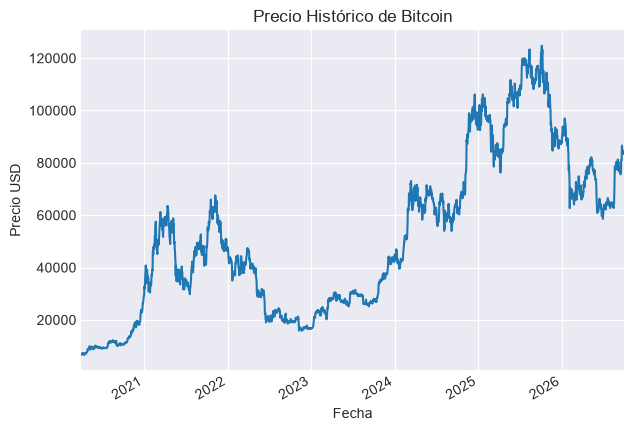

In [521]:
fig, ax  =  plt.subplots(figsize =  (7, 5))

df_bitcoin["BTC_Close"].plot(ax =  ax)
ax.set_title("Precio Histórico de Bitcoin")
ax.set_xlim(df_bitcoin.index.min(), df_bitcoin.index.max())
ax.set_xlabel("Fecha")
ax.set_ylabel("Precio USD")

Text(0, 0.5, 'Rendimiento')

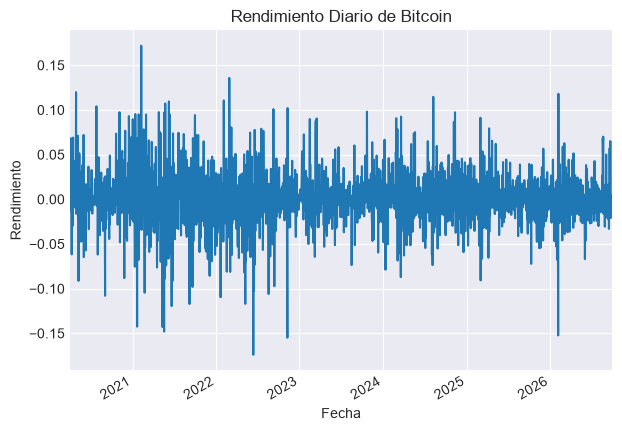

In [522]:
fig, ax  =  plt.subplots(figsize =  (7, 5))
df_bitcoin["Bitcoin_log_ret"].plot(ax =  ax)
ax.set_xlim(df_bitcoin.index.min(), df_bitcoin.index.max())
ax.set_title("Rendimiento Diario de Bitcoin")
ax.set_xlabel("Fecha")
ax.set_ylabel("Rendimiento")

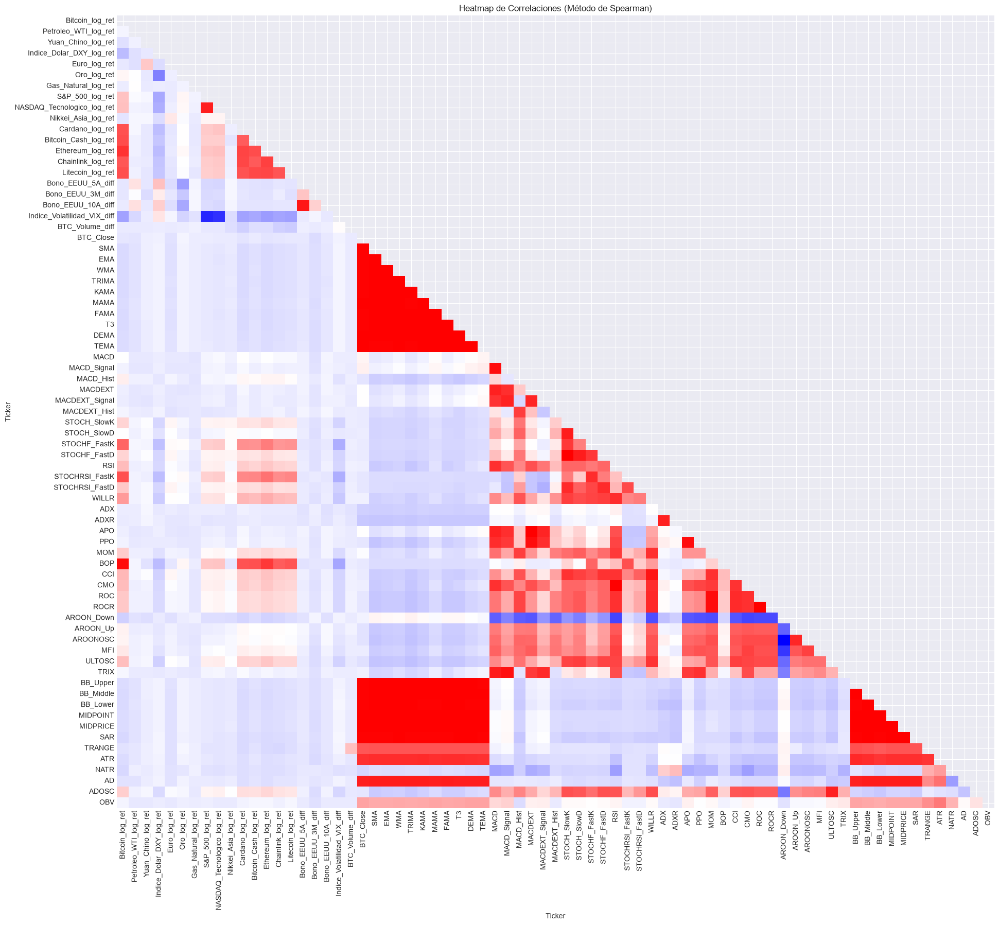

In [523]:

matriz_corr =  df_bitcoin.corr(method  =  "spearman")
mascara =  np.triu(np.ones_like(matriz_corr, dtype  =  bool))
plt.figure(figsize =  (22, 20))
sns.heatmap(
    matriz_corr, 
    cmap = "bwr",
    fmt  =  ".2f",
    annot  =  False, 
    mask  =  mascara,
    cbar =  False
)
plt.title("Heatmap de Correlaciones (Método de Spearman)")
plt.show()

Se confirma la presencia de multicolinealidad. Por lo que se decide trabajar con modelos basados en arboles de decision con la finalidad de que encuentre la mejor combinación de variables.

# Procesamiento de Datos

In [525]:
# Selección de los ultimos 4 años de datos
df  =  df_bitcoin.loc["2022-09-28":].copy()
print("Dimensiones del cojunto de datos:", df.shape)
print("Primer registro:", df.index.min())
print("Ultimo registro:", df.index.max())

Dimensiones del cojunto de datos: (1464, 73)
Primer registro: 2022-09-28 00:00:00
Ultimo registro: 2026-09-30 00:00:00


In [526]:
# Preperación de variables
feature_cols  =  ["Indice_Dolar_DXY_log_ret",
                "Oro_log_ret", "S&P_500_log_ret",
                "NASDAQ_Tecnologico_log_ret",
                "Cardano_log_ret",
                "Bitcoin_Cash_log_ret",
                "Ethereum_log_ret",
                "Chainlink_log_ret",
                "Litecoin_log_ret",
                "Indice_Volatilidad_VIX_diff",
                "SMA",
                "EMA",
                "WMA",
                "DEMA",
                "TEMA",
                "TRIMA",
                "KAMA",
                "MAMA",
                "FAMA",
                "T3",
                "MACD",
                "MACD_Signal",
                "MACD_Hist",
                "MACDEXT",
                "MACDEXT_Signal",
                "MACDEXT_Hist",
                "STOCH_SlowK",
                "STOCH_SlowD",
                "STOCHF_FastK",
                "STOCHF_FastD",
                "RSI",
                "STOCHRSI_FastK",
                "STOCHRSI_FastD",
                "WILLR",
                "ADX",
                "ADXR",
                "APO",
                "PPO",
                "MOM",
                "BOP",
                "CCI",
                "CMO",
                "ROC",
                "ROCR",
                "AROON_Down",
                "AROON_Up",
                "AROONOSC",
                "MFI",
                "TRIX",
                "ULTOSC",
                "BB_Upper",
                "BB_Middle",
                "BB_Lower",
                "MIDPOINT",
                "MIDPRICE",
                "SAR",
                "TRANGE",
                "ATR",
                "NATR",
                "AD",
                "ADOSC",
                "OBV"              
]
# Features originales
X_unshifted =  df[feature_cols].copy()
# Features rezagadas para predecir con información disponible hasta el periodo t-1
X_all = X_unshifted.shift(1)
# Número de features
print("Número de variables explicativas:", X_all.shape[1])


Número de variables explicativas: 62


In [527]:
# Generación de etiqueta mediante el método de triple barrera
def generar_triple_barrera(data, close_col, pt_multiplier=1.5, sl_multiplier=1.5, max_holding_bars=10, volatility_window=20
):
    """
    Genera 3 clases:

        0 = Baja
        1 = Neutral
        2 = Sube cuando el precio 

    La volatilidad usa únicamente información pasada.
    """

    prices = data[close_col].astype(float)
    dates = data.index
    returns = prices.pct_change()
    volatility = (returns.rolling(volatility_window).std().shift(1))
    n = len(data)
    labels = np.full(n, np.nan)
    t1_values = np.full(n, np.datetime64("NaT"), dtype="datetime64[ns]")

    # Validación datos suficientes para generar etiqueta
    for i in range(n):
        if (i + max_holding_bars >= n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (i + max_holding_bars)
        upper_barrier = (pt_multiplier * current_vol)
        lower_barrier = (-sl_multiplier * current_vol)

        future_prices = prices.iloc[i + 1: vertical_end + 1]
        future_returns = (future_prices / prices.iloc[i] - 1.0)

        upper_hits = np.where(future_returns.values >= upper_barrier)[0]
        lower_hits = np.where(future_returns.values <= lower_barrier)[0]
        first_upper = (upper_hits[0] if len(upper_hits) > 0 else np.inf)
        first_lower = (lower_hits[0] if len(lower_hits) > 0 else np.inf)

        if first_upper < first_lower:
            hit_position = (i + 1 + int(first_upper))
            labels[i] = 2
            t1_values[i] = dates[hit_position]

        elif first_lower < first_upper:
            hit_position = (i + 1 + int(first_lower))
            labels[i] = 0
            t1_values[i] = dates[hit_position]
            
        else:
            labels[i] = 1
            t1_values[i] = dates[vertical_end]

    return pd.DataFrame({"target": labels, "t1": pd.to_datetime(t1_values)}, index=dates)

In [547]:
# Clase para generación de cojuntos de entrenamiento y validación 
# de series temporales con purga (eliminación de etiquetas solapadas) y embargo (eliminación de observaciones despues del entrenamiento) para evitar autocorrelación 

class PurgedWalkForwardEmbargo:
    def __init__(self, n_splits=5, embargo_bars=10, reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars
        self.reference_index = pd.Index(reference_index)

    def split(self, X, t1):
        n_samples = len(X)
        validation_size = n_samples // (self.n_splits + 1)

        for fold in range(self.n_splits):
            val_start = (fold + 1) * validation_size
            val_end = val_start + validation_size

            if fold == (self.n_splits - 1):
                val_end = n_samples

            val_positions = np.arange(val_start, val_end)
            if len(val_positions) == 0:
                continue

            val_start_time = X.index[val_start]

            raw_val_start = self.reference_index.searchsorted(
                val_start_time,
                side="left"
            )

            # Embargo 
            raw_embargo_start = max(
                0,
                raw_val_start - self.embargo_bars
            )

            embargo_start_time = self.reference_index[raw_embargo_start]

            candidate_train_positions = np.where(
                X.index < embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:
                event_end = t1.iloc[pos]

                if pd.isna(event_end):
                    continue

                # Purga
                if event_end >= val_start_time:
                    continue

                train_positions.append(pos)

            train_positions = np.asarray(train_positions, dtype=int)

            if len(train_positions) == 0:
                continue

            yield train_positions, val_positions

    def get_n_splits(self):
        return self.n_splits



In [531]:
# Funciones auxiliares para la preperación de los conjuntos de datos y verificar alineación temporal
# Generación del conjunto de datos de prueba
n_total =  len(df)
test_start_position =  int(n_total *  (1.0 - 0.2))
test_start_position =  min(max(test_start_position, 1), n_total - 1)
test_start_time  =  df.index[test_start_position]
print("Inicio del test:", test_start_time)

def validar_alineacion(X, y, t1, nombre):
    if not X.index.equals(y.index):
        raise ValueError(f"{nombre}: X e y no están alineados.")
    if not X.index.equals(t1.index):
        raise ValueError(f"{nombre}: X y t1 no están alineados.")
    if not X.index.is_monotonic_increasing:
        raise ValueError(f"{nombre}: índice no ordenado.")
    if X.index.has_duplicates:
        raise ValueError(f"{nombre}: índices duplicados.")
    if y.isna().any():
        raise ValueError(f"{nombre}: y contiene NaN.")
    if t1.isna().any():
        raise ValueError(f"{nombre}: t1 contiene NaN.")


def preparar_datos(tb_params):
    tb_result = generar_triple_barrera(data=df, close_col=CLOSE_COL, pt_multiplier=tb_params["pt_multiplier"],
                                         sl_multiplier=tb_params["sl_multiplier"],
                                         max_holding_bars=tb_params["max_holding_bars"],
                                         volatility_window=tb_params["volatility_window"])
    
    development_mask = ((df.index < test_start_time) & (tb_result["target"].notna()) & (tb_result["t1"] < test_start_time))
    test_mask = ((df.index >= test_start_time) & (tb_result["target"].notna()))
    
    X_dev = X_all.loc[development_mask].copy()
    y_dev = (tb_result.loc[development_mask, "target"].astype(int))
    t1_dev = tb_result.loc[development_mask, "t1"]
    
    X_test = X_all.loc[test_mask].copy()
    y_test = (tb_result.loc[test_mask, "target"].astype(int))
    t1_test = tb_result.loc[test_mask, "t1"]
    
    validar_alineacion(X_dev, y_dev, t1_dev, "Desarrollo")
    validar_alineacion(X_test, y_test, t1_test, "Test")
    
    return (X_dev, y_dev, t1_dev, X_test, y_test, t1_test)


# Funciones auxiliares para balanceo de clases en la validación cruzada y optimización de etiquetas triple barrera
TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

def calcular_puntuacion_balance(y, target_fractions = TARGET_CLASS_FRACTIONS, min_class_fraction = 0.15, min_class_count = 30):
    labels = list(target_fractions.keys())
    counts = (y.value_counts().reindex(labels, fill_value = 0))
    total = counts.sum()

    # Se rechazan configuraciones con clases vacías o desproporcionadas
    if total == 0:
        return -1.0
    if (counts == 0).any():
        return -1.0
    if (counts < min_class_count).any():
        return -1.0
    proportions = counts / total 
    if (proportions < min_class_fraction).any():
        return -1.0
    target = pd.Series(target_fractions, dtype = float).reindex(labels)
    mean_absolute_error = np.abs(proportions - target).mean()
    max_error = (1.0 / len(labels))
    score = (1.0 - mean_absolute_error / max_error)
    return float(max(-1.0, score))

def obtener_distribucion_clases(y):
    counts = (y.value_counts().reindex(TARGET_LABELS, fill_value = 0))
    proportions = (counts / counts.sum())
    return pd.DataFrame({"Clase": [TARGET_NAMES[label] for label in TARGET_LABELS],
    "Codigo": TARGET_LABELS, 
    "Observaciones": counts.values,
    "Proporcion": proportions.values})

def evaluar_balance_por_fold( X, y, t1, splitter
):
    scores = []
    rows = []

    for fold_number, ( train_idx, val_idx
    ) in enumerate(
        splitter.split( X, t1
        ), start=1
    ):

        y_train = y.iloc[train_idx]

        y_val = y.iloc[val_idx]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(score)

        train_counts = (y_train.value_counts().reindex(TARGET_LABELS, fill_value=0))

        val_counts = (y_val.value_counts().reindex(TARGET_LABELS, fill_value=0))

        train_proportions = (train_counts / train_counts.sum())

        val_proportions = (val_counts / val_counts.sum())

        rows.append(
            {
                "Fold": fold_number,
                "Entrenamiento inicio": X.index[train_idx[0]],
                "Entrenamiento fin": X.index[train_idx[-1]],
                "Validación inicio": X.index[val_idx[0]],
                "Validación fin": X.index[val_idx[-1]],
                "Observaciones Entrenamiento": len(train_idx),
                "Observaciones Validación": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(rows)

    # Penalización por partición, se descartan si tienen un score negativo
    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(scores)

    std_score = np.std(scores)

    final_score = (mean_score - 0.25 * std_score )

    return float( final_score), table



Inicio del test: 2025-12-12 00:00:00


In [532]:
# Optimización de etiqueta (Triple Barrera)
# Se buscan distribuciones entre clases que sean relativamente balanceadas

def objetivo_triple_barrera(trial):
    params = {
        "pt_multiplier": trial.suggest_float("pt_multiplier", 0.50, 3.00),
        "sl_multiplier": trial.suggest_float("sl_multiplier", 0.50, 3.00),
        "max_holding_bars": trial.suggest_int("max_holding_bars", 3, 40),
        "volatility_window": trial.suggest_int("volatility_window", 10, 80, step = 5)
    }

    try:
        tb_result = generar_triple_barrera(
            data = df, close_col = CLOSE_COL, 
            pt_multiplier = params["pt_multiplier"],
            sl_multiplier = params["sl_multiplier"],
            max_holding_bars = params["max_holding_bars"],
            volatility_window = params["volatility_window"]
        )

        development_mask = ((df.index < test_start_time) & (tb_result["target"].notna()) & (tb_result["t1"] < test_start_time))
        X_tb = X_all.loc[development_mask].copy()
        y_tb = (tb_result.loc[development_mask, "target"].astype(int))
        t1_tb = tb_result.loc[development_mask, "t1"]
        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(X_tb, y_tb, t1_tb, "Triple Barrera")
        splitter_tb = PurgedWalkForwardEmbargo(n_splits = 5, 
                                             embargo_bars = EMBARGO_BARS, 
                                             reference_index = df.index)
        score, _ = evaluar_balance_por_fold(X = X_tb, y = y_tb, t1 = t1_tb, splitter = splitter_tb)

        return float(score)
    except Exception:
        return -1.0


print("Optización de Target (Barrera Triple). Buscando distribuciones balanceadas")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study_tb = optuna.create_study(direction = "maximize", sampler = optuna.samplers.TPESampler(seed = RANDOM_STATE))
study_tb.optimize(objetivo_triple_barrera, n_trials = N_TRIALS_TRIPLE_BARRIER, show_progress_bar = True)

if study_tb.best_value < 0:
    raise RuntimeError("No se encontró una configuración valida para Triple Barrera")

best_tb_params = study_tb.best_params
print("Mejor configuracion de Triple Barrera:")
print(best_tb_params)
print("Score de balance usando Walk-Forward con purga y embargo:",
      round(study_tb.best_value, 4))

Optización de Target (Barrera Triple). Buscando distribuciones balanceadas


Best trial: 64. Best value: 0.813145: 100%|██████████| 80/80 [00:26<00:00,  3.06it/s]

Mejor configuracion de Triple Barrera:
{'pt_multiplier': 2.58193567248558, 'sl_multiplier': 1.9556644063755302, 'max_holding_bars': 11, 'volatility_window': 20}
Score de balance usando Walk-Forward con purga y embargo: 0.8131


La clase sube es 2.5819 multiplicada por la volatilidad de los ultimos 20 días. Baja es -1.95 multiplicada por la volatilida de los ultimos 20 días y neutral cuando no se toca ninguna de las  barreras anteriores en 11 días. 

In [555]:
# Preperación del conjunto de datos definitivo
(X_dev, y_dev, t1_dev, X_test, y_test, t1_test) =  preparar_datos(best_tb_params)
print("\nTamaño del conjunto de datos de desarrollo (Entrenamiento y Validacíon):", len(X_dev))
print("Tamaño del conjunto de prueba:",len(X_test))

print("\nDistribución de clases en desarrollo:")
display(obtener_distribucion_clases(y_dev).style.format({"Proporción": "{:.2%}"}))

print("\nDistribución de clases en test:")
display(obtener_distribucion_clases(y_test).style.format({"Proporción": "{:.2%}"}))

splitter_diagnostic  =  PurgedWalkForwardEmbargo(n_splits  =  5, embargo_bars=  EMBARGO_BARS, reference_index =  df.index)
balance_score, tabla_balance =  (evaluar_balance_por_fold(X =  X_dev, y =  y_dev, t1 =  t1_dev, splitter =  splitter_diagnostic))

print("\nBalance por fold:")

display(tabla_balance.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)



Tamaño del conjunto de datos de desarrollo (Entrenamiento y Validacíon): 1140
Tamaño del conjunto de prueba: 282

Distribución de clases en desarrollo:


,Clase,Codigo,Observaciones,Proporcion
0,Baja,0,390,0.342105
1,Neutral,1,363,0.318421
2,Sube,2,387,0.339474



Distribución de clases en test:


,Clase,Codigo,Observaciones,Proporcion
0,Baja,0,92,0.326241
1,Neutral,1,107,0.379433
2,Sube,2,83,0.294326



Balance por fold:


,Fold,Entrenamiento inicio,Entrenamiento fin,Validación inicio,Validación fin,Observaciones Entrenamiento,Observaciones Validación,Score balance,Train Baja,Train Neutral,Train Sube,Val Baja,Val Neutral,Val Sube
0,1,2022-10-19 00:00:00,2023-04-16 00:00:00,2023-04-27 00:00:00,2023-11-02 00:00:00,180,190,0.8912,30.56%,38.33%,31.11%,27.89%,38.42%,33.68%
1,2,2022-10-19 00:00:00,2023-10-23 00:00:00,2023-11-03 00:00:00,2024-05-10 00:00:00,370,190,0.8351,30.00%,37.30%,32.70%,25.26%,33.16%,41.58%
2,3,2022-10-19 00:00:00,2024-04-29 00:00:00,2024-05-11 00:00:00,2024-11-16 00:00:00,559,190,0.8702,28.44%,36.31%,35.24%,35.79%,26.84%,37.37%
3,4,2022-10-19 00:00:00,2024-11-06 00:00:00,2024-11-17 00:00:00,2025-05-25 00:00:00,750,190,0.9754,30.27%,34.40%,35.33%,34.21%,33.68%,32.11%
4,5,2022-10-19 00:00:00,2025-05-15 00:00:00,2025-05-26 00:00:00,2025-12-01 00:00:00,940,190,0.6351,30.74%,34.04%,35.21%,51.58%,21.05%,27.37%


Después encontrar la mejor configuración, se confirma que las clases están relativamente balanceadas. Asimismo, se confirma que que no existe solapamiento entre entrenamientoy validación para todos los folds.

# Entrenamiento

In [554]:
# Funciones auxiliares para el calculo de metricas de clasificación

def obtener_probabilidades(model, X):
    """
    Devuelve probabilidades en orden:
        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """
    raw_proba = np.asarray(model.predict_proba(X))
    if raw_proba.ndim != 2:
        raise ValueError("predict_proba necesita una matriz 2D.")

    model_classes = np.asarray(model.classes_ if hasattr(model, "classes_") else TARGET_LABELS).astype(int)
    ordered_proba = np.zeros((len(X), len(TARGET_LABELS)), dtype=float)

    for source_column, class_label in enumerate(model_classes):
        if class_label not in TARGET_LABELS:
            continue
        target_column = TARGET_LABELS.index(int(class_label))
        ordered_proba[:, target_column] = raw_proba[:, source_column]

    row_sums = ordered_proba.sum(axis=1)
    if np.any(row_sums <= 0):
        raise ValueError("Existen filas con probabilidades nulas!.")

    ordered_proba = ordered_proba / row_sums.reshape(-1, 1)
    return ordered_proba



def normalizar_predicciones(y_pred, expected_length, model_name):
    """
    Convierte formas (n,) o (n, 1) a (n,)
    """
    y_pred_array = np.asarray(y_pred).reshape(-1)
    if len(y_pred_array) != expected_length:
        raise ValueError(f"{model_name}: se recibieron {len(y_pred_array)} predicciones, pero se esperaban {expected_length}.")

    y_pred_array = y_pred_array.astype(int)
    invalid_classes = np.setdiff1d(np.unique(y_pred_array), np.asarray(TARGET_LABELS))
    if len(invalid_classes) > 0:
        raise ValueError(f"{model_name}: clases inválidas: {invalid_classes.tolist()}")

    return y_pred_array


def calcular_metricas(y_true, y_pred, y_proba=None):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }

    if y_proba is not None:
        try:
            metrics["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr", labels=TARGET_LABELS)
        except Exception:
            metrics["roc_auc_ovr"] = np.nan
    else:
        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=TARGET_LABELS, zero_division=0
    )

    for i, label in enumerate(TARGET_LABELS):
        class_name = TARGET_NAMES[label]
        metrics[f"precision_{class_name}"] = precision_class[i]
        metrics[f"recall_{class_name}"] = recall_class[i]
        metrics[f"f1_{class_name}"] = f1_class[i]

    return metrics

In [559]:
MODELOS = ["Random Forest", "Extra Trees", "Gradient Boosting", "MLP", "XGBoost"]

def construir_modelo(trial, model_name):
    requires_scaling = False

    if model_name == "Random Forest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 200, 500, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 25),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif model_name == "Extra Trees":
        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int("n_estimators", 200, 750, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 25),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 30),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),
            max_features=trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
            class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int("n_estimators", 50, 450, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.30, log=True),
            max_depth=trial.suggest_int("max_depth", 1, 6),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 30),
            subsample=trial.suggest_float("subsample", 0.60, 1.00),
            random_state=RANDOM_STATE
        )

    elif model_name == "MLP":
        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical("hidden_layer_sizes", [(8,), (16,), (32,), (16, 8), (32, 16)]),
            alpha=trial.suggest_float("alpha", 1e-5, 10.0, log=True),
            learning_rate_init=trial.suggest_float("learning_rate_init", 1e-4, 1e-1, log=True),
            batch_size=trial.suggest_categorical("batch_size", [16, 32, 64]),
            max_iter=trial.suggest_int("max_iter", 300, 1500, step=100),
            early_stopping=False,
            random_state=RANDOM_STATE
        )
        requires_scaling = True

    elif model_name == "XGBoost":
        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,
            n_estimators=trial.suggest_int("n_estimators", 100, 600, step=50),
            max_depth=trial.suggest_int("max_depth", 2, 10),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.30, log=True),
            min_child_weight=trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
            subsample=trial.suggest_float("subsample", 0.60, 1.00),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.60, 1.00),
            gamma=trial.suggest_float("gamma", 1e-8, 5.0, log=True),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-5, 10.0, log=True),
            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )

    else:
        raise ValueError(f"Modelo no reconocido: {model_name}")

    steps = []
    if requires_scaling:
        steps.append(("scaler", StandardScaler())) # Standarización para MLP
    steps.append(("model", model))

    return Pipeline(steps=steps)

# Evaluación de modelos por fold

def evaluar_cv_modelo(model, X, y, t1, splitter, devolver_folds=False):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """
    scores = []
    rows = []

    for fold_number, (train_idx, val_idx) in enumerate(splitter.split(X, t1), start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        if y_train.nunique() < 3 or y_val.nunique() < 2:
            continue

        model_fold = clone(model)
        model_fold.fit(X_train, y_train)

        y_pred = np.asarray(model_fold.predict(X_val)).reshape(-1)

        if len(np.unique(y_pred)) < 2:
            if devolver_folds:
                return 0.0, pd.DataFrame(rows)
            return 0.0

        score = f1_score(y_val, y_pred, average="macro", zero_division=0)
        scores.append(score)

        rows.append({
            "Fold": fold_number,
            "F1 macro": score,
            "N train": len(train_idx),
            "N validation": len(val_idx),
            "Clases reales": y_val.nunique(),
            "Clases predichas": len(np.unique(y_pred))
        })

    if not scores:
        if devolver_folds:
            return -1.0, pd.DataFrame(rows)
        return -1.0

    final_score = float(np.mean(scores))
    if devolver_folds:
        return final_score, pd.DataFrame(rows)

    return final_score


Se eligen estos modelos ya que son adecuados para datos con ruido y con alta multicolinealidad. La elección final proviene de prueba y error de modelos y configuraciones que produjeran los mejores resultados. 

In [560]:
# Entrenamiento y búsqueda de mejores configuraciones de hiperparametros por modelo
splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:
    print("\nOptimizando modelo:", model_name)

    def objective_model(trial, current_model_name=model_name):
        model = construir_modelo(trial=trial, model_name=current_model_name)
        try:
            return evaluar_cv_modelo(model=model, X=X_dev, y=y_dev, t1=t1_dev, splitter=splitter_model)
        except Exception:
            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )

    study_model.optimize(objective_model, n_trials=N_TRIALS_MODELO, show_progress_bar=True)

    if study_model.best_value < 0:
        print("No se encontró configuración válida.")
        continue

    best_trial = study_model.best_trial
    best_model = construir_modelo(trial=best_trial, model_name=model_name)

    best_models[model_name] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }
    optimization_results[model_name] = study_model

if not best_models:
    raise RuntimeError("Ningún modelo obtuvo una configuración válida.")


Optimizando modelo: Random Forest


Best trial: 38. Best value: 0.296677: 100%|██████████| 50/50 [04:19<00:00,  5.20s/it]



Optimizando modelo: Extra Trees


Best trial: 41. Best value: 0.284158: 100%|██████████| 50/50 [04:31<00:00,  5.44s/it]



Optimizando modelo: Gradient Boosting


Best trial: 35. Best value: 0.336254: 100%|██████████| 50/50 [14:13<00:00, 17.06s/it]



Optimizando modelo: MLP


Best trial: 43. Best value: 0.326877: 100%|██████████| 50/50 [08:22<00:00, 10.05s/it]



Optimizando modelo: XGBoost


Best trial: 36. Best value: 0.353606: 100%|██████████| 50/50 [03:00<00:00,  3.60s/it]


Se procede directamente a la optimización de hiperparametros para poder validar rapidamente diferentes modelos.

In [561]:
# Mejor configuración de hiperparametros
for model_name, info in best_models.items():
    print(f"==={model_name}===")
    print(f"Mejor F1 Macro CV: {info['cv_f1_macro']:.4f}")
    print("Mejores hiperparametros:")
    for param, val in info["best_params"].items():
        print(f"-{param}: {val}")
    print()

===Random Forest===
Mejor F1 Macro CV: 0.2967
Mejores hiperparametros:
-n_estimators: 450
-max_depth: 13
-min_samples_split: 3
-min_samples_leaf: 3
-max_features: log2
-class_weight: None

===Extra Trees===
Mejor F1 Macro CV: 0.2842
Mejores hiperparametros:
-n_estimators: 650
-max_depth: 16
-min_samples_split: 9
-min_samples_leaf: 5
-max_features: None
-class_weight: balanced

===Gradient Boosting===
Mejor F1 Macro CV: 0.3363
Mejores hiperparametros:
-n_estimators: 200
-learning_rate: 0.2567376062353293
-max_depth: 4
-min_samples_leaf: 5
-subsample: 0.7622353137398685

===MLP===
Mejor F1 Macro CV: 0.3269
Mejores hiperparametros:
-hidden_layer_sizes: (16, 8)
-alpha: 0.0031628892311055586
-learning_rate_init: 0.0041505417908132254
-batch_size: 32
-max_iter: 300

===XGBoost===
Mejor F1 Macro CV: 0.3536
Mejores hiperparametros:
-n_estimators: 500
-max_depth: 3
-learning_rate: 0.2828402341543013
-min_child_weight: 7.920983853762752
-subsample: 0.6588499094648518
-colsample_bytree: 0.6114303

# Evaluación

In [564]:
# Evaluación de después de ajuste de hiperparametros | Reporte de Clasificación

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():
    print("\nEvaluando en test:", model_name)

    final_model = clone(model_info["model"])
    final_model.fit(X_dev, y_dev)

    y_pred = np.asarray(final_model.predict(X_test)).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(f"{model_name}: predicciones y X_test tienen distinta longitud.")

    y_pred = y_pred.astype(int)
    invalid_classes = np.setdiff1d(np.unique(y_pred), np.asarray(TARGET_LABELS))
    if len(invalid_classes) > 0:
        raise ValueError(f"{model_name}: clases inválidas: {invalid_classes.tolist()}")

    y_proba = obtener_probabilidades(final_model, X_test)

    final_models[model_name] = final_model
    test_predictions[model_name] = pd.Series(y_pred, index=X_test.index, name="prediction", dtype=int)

    if y_proba is not None:
        test_probabilities[model_name] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[f"prob_{TARGET_NAMES[label]}" for label in TARGET_LABELS]
        )

    metrics = calcular_metricas(y_true=y_test, y_pred=y_pred, y_proba=y_proba)

    global_results.append({
        "Modelo": model_name,
        "F1 Validación CV": model_info["cv_f1_macro"],
        "Accuracy Test": metrics["accuracy"],
        "Balanced Accuracy Test": metrics["balanced_accuracy"],
        "Precision Macro Test": metrics["precision_macro"],
        "Recall Macro Test": metrics["recall_macro"],
        "F1 Macro Test": metrics["f1_macro"],
        "ROC-AUC OVR Test": metrics["roc_auc_ovr"]
    })

    class_results.append({
        "Modelo": model_name,
        "Precision Baja": metrics["precision_Baja"],
        "Recall Baja": metrics["recall_Baja"],
        "F1 Baja": metrics["f1_Baja"],
        "Precision Neutral": metrics["precision_Neutral"],
        "Recall Neutral": metrics["recall_Neutral"],
        "F1 Neutral": metrics["f1_Neutral"],
        "Precision Sube": metrics["precision_Sube"],
        "Recall Sube": metrics["recall_Sube"],
        "F1 Sube": metrics["f1_Sube"]
    })

    print(classification_report(
        y_test, y_pred,
        labels=TARGET_LABELS,
        target_names=[TARGET_NAMES[label] for label in TARGET_LABELS],
        zero_division=0
    ))


Evaluando en test: Random Forest
              precision    recall  f1-score   support

        Baja       0.43      0.21      0.28        92
     Neutral       0.56      0.29      0.38       107
        Sube       0.37      0.82      0.51        83

    accuracy                           0.42       282
   macro avg       0.46      0.44      0.39       282
weighted avg       0.46      0.42      0.39       282


Evaluando en test: Extra Trees
              precision    recall  f1-score   support

        Baja       0.60      0.47      0.52        92
     Neutral       0.54      0.36      0.43       107
        Sube       0.40      0.67      0.50        83

    accuracy                           0.49       282
   macro avg       0.51      0.50      0.49       282
weighted avg       0.52      0.49      0.48       282


Evaluando en test: Gradient Boosting
              precision    recall  f1-score   support

        Baja       0.42      0.15      0.22        92
     Neutral       0.62  

In [569]:
# Comparativo final por modelo
tabla_global  =  pd.DataFrame(global_results).sort_values("F1 Macro Test", ascending  =  False).reset_index(drop  =  True)
tabla_clases = pd.DataFrame(class_results).sort_values("Modelo").reset_index(drop  =  True)
tabla_final =  tabla_global.merge(tabla_clases, on =  "Modelo", how  = "left")
tabla_final

,Modelo,F1 Validación CV,Accuracy Test,Balanced Accuracy Test,Precision Macro Test,Recall Macro Test,F1 Macro Test,ROC-AUC OVR Test,Precision Baja,Recall Baja,F1 Baja,Precision Neutral,Recall Neutral,F1 Neutral,Precision Sube,Recall Sube,F1 Sube
0,Extra Trees,0.284158,0.485816,0.499077,0.511770,0.499077,0.485287,0.672701,0.597222,0.467391,0.524390,0.535211,0.355140,0.426966,0.402878,0.674699,0.504505
1,MLP,0.326877,0.400709,0.394172,0.392267,0.394172,0.392398,0.570736,0.345679,0.304348,0.323699,0.457627,0.504673,0.480000,0.373494,0.373494,0.373494
2,Random Forest,0.296677,0.418440,0.438506,0.455680,0.438506,0.391135,0.636889,0.431818,0.206522,0.279412,0.563636,0.289720,0.382716,0.371585,0.819277,0.511278
3,XGBoost,0.353606,0.411348,0.430915,0.486870,0.430915,0.367063,0.601105,0.550000,0.119565,0.196429,0.557377,0.317757,0.404762,0.353234,0.855422,0.500000
4,Gradient Boosting,0.336254,0.372340,0.397270,0.455824,0.397270,0.330557,0.610541,0.424242,0.152174,0.224000,0.617647,0.196262,0.297872,0.325581,0.843373,0.469799


In [572]:
# Comparativo con modelo ingenuo
majority_class  =  y_dev.mode().iloc[0]
y_pred_naive  =  np.full(len(y_test), majority_class)
naive_metrics  =  calcular_metricas(y_true=  y_test, y_pred  =  y_pred_naive, y_proba =  None)
print("\n" + "=" * 50)
print("Modelo Ingenuo")
print("=" * 50)
print("Clase Mayoritaria:", majority_class, TARGET_NAMES[majority_class])
print("Accuracy:", round(naive_metrics["accuracy"], 4))
print("F1 Macro:", round(naive_metrics["f1_macro"], 4))


Modelo Ingenuo
Clase Mayoritaria: 0 Baja
Accuracy: 0.3262
F1 Macro: 0.164


# Simulación  de Compra y Venta de Bitcoin

,Estrategia,Retorno total,Ratio Sharpe,Máximo drawdown
0,Comprar y Mantener,-10.15%,-0.0769,-39.59%
1,Random Forest Triple Barrera,2.71%,0.2836,-31.33%
2,Extra Trees Triple Barrera,39.55%,1.5805,-18.41%
3,Gradient Boosting Triple Barrera,-6.57%,0.0019,-39.28%
4,MLP Triple Barrera,-3.51%,0.0046,-23.95%
5,XGBoost Triple Barrera,-4.73%,0.0509,-37.32%


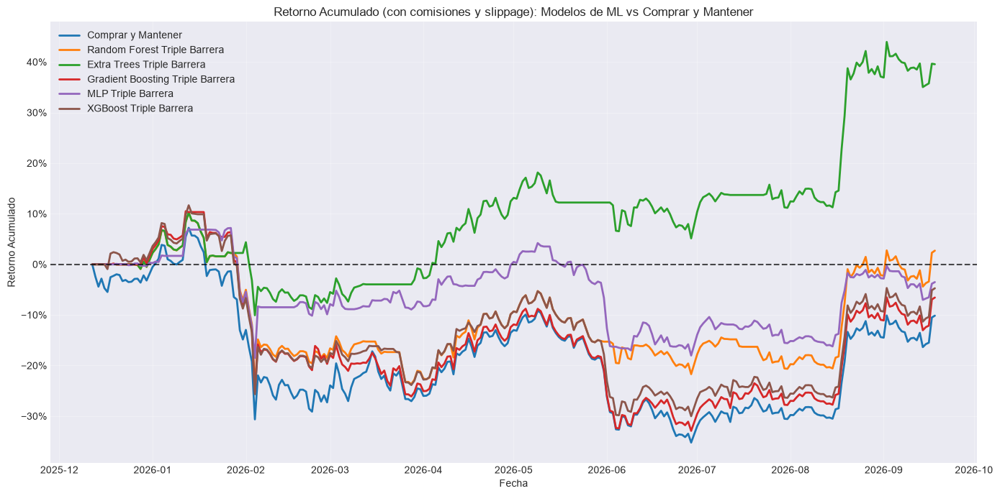

In [ ]:

PERIODOS = 365              

FEE_PER_SIDE = 0.0010       # Comisión al abrir una posición
SLIPPAGE_PER_SIDE = 0.0005   # Comisión al cerrar una posición

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)  


indice_test = X_test.index.copy()

precios_test = (
    df.loc[indice_test, CLOSE_COL]
    .astype(float)
    .rename("precio")
    .reindex(indice_test)
)

retornos_futuros = (
    precios_test.shift(-1)
    / precios_test
    - 1.0
).rename("retorno_futuro")


def calcular_drawdown(patrimonio):
    return patrimonio / patrimonio.cummax() - 1.0

def ejecutar_backtest_simplificado(nombre_estrategia, posicion, precios, retornos_futuros):
    indice_comun = precios.index.intersection(retornos_futuros.dropna().index).intersection(posicion.index).sort_values()
    
    precios = precios.loc[indice_comun]
    retornos_futuros = retornos_futuros.loc[indice_comun]
    posicion = posicion.loc[indice_comun].astype(float)
    
    posicion_anterior = posicion.shift(1).fillna(0.0)
    rotacion = (posicion - posicion_anterior).abs()
    retorno_bruto = posicion * retornos_futuros

    valores_patrimonio = []
    patrimonio_previo = INITIAL_CAPITAL

    for marca_tiempo in indice_comun:
        rotacion_actual = float(rotacion.loc[marca_tiempo])
        retorno_bruto_actual = float(retorno_bruto.loc[marca_tiempo])
        
        coste_dolares_actual = patrimonio_previo * rotacion_actual * COST_PER_TURNOVER
        
        patrimonio_actual = (patrimonio_previo * (1.0 + retorno_bruto_actual)) - coste_dolares_actual
        valores_patrimonio.append(patrimonio_actual)
        patrimonio_previo = patrimonio_actual

    patrimonio = pd.Series(valores_patrimonio, index=indice_comun, name="patrimonio")
    drawdown = calcular_drawdown(patrimonio)
    retornos_netos = patrimonio.pct_change().dropna()
    
    desviacion_std = retornos_netos.std(ddof=1)
    sharpe = (retornos_netos.mean() / desviacion_std * np.sqrt(PERIODOS)) if desviacion_std > 0 and np.isfinite(desviacion_std) else np.nan
    retorno_total = (patrimonio.iloc[-1] / INITIAL_CAPITAL) - 1.0
    maximo_drawdown = float(drawdown.min())

    metricas = {
        "Estrategia": nombre_estrategia,
        "Retorno total": retorno_total,
        "Ratio Sharpe": sharpe,
        "Máximo drawdown": maximo_drawdown
    }

    return patrimonio, metricas


def convertir_prediccion_a_exposicion(y_pred):
    arreglo_pred = np.asarray(y_pred).reshape(-1).astype(int)
    serie_pred = pd.Series(arreglo_pred, index=X_test.index)
    
    exposicion = np.select(
        [serie_pred == 0, serie_pred == 1, serie_pred == 2],
        [0.0, 0.5, 1.0],
        default=0.0
    )
    return pd.Series(exposicion, index=X_test.index, dtype=float)


resultados_backtest = {}
metricas_backtest = []

patrimonio_bh, metricas_bh = ejecutar_backtest_simplificado(
    nombre_estrategia="Comprar y Mantener",
    posicion=pd.Series(1.0, index=X_test.index),
    precios=precios_test,
    retornos_futuros=retornos_futuros
)
resultados_backtest["Comprar y Mantener"] = patrimonio_bh
metricas_backtest.append(metricas_bh)

for nombre_modelo in best_models:
    y_pred_model = test_predictions[nombre_modelo]
    posicion_modelo = convertir_prediccion_a_exposicion(y_pred_model)
    nombre_estrategia = f"{nombre_modelo} Triple Barrera"
    
    patrimonio_modelo, metricas_modelo = ejecutar_backtest_simplificado(
        nombre_estrategia=nombre_estrategia,
        posicion=posicion_modelo,
        precios=precios_test,
        retornos_futuros=retornos_futuros
    )
    resultados_backtest[nombre_estrategia] = patrimonio_modelo
    metricas_backtest.append(metricas_modelo)


tabla_metricas = pd.DataFrame(metricas_backtest)
display(
    tabla_metricas.style.format({
        "Retorno total": "{:.2%}",
        "Ratio Sharpe": "{:.4f}",
        "Máximo drawdown": "{:.2%}"
    })
)


plt.figure(figsize=(14, 7))

for nombre_estrategia, patrimonio in resultados_backtest.items():
    retorno_acumulado = (patrimonio / INITIAL_CAPITAL) - 1.0
    plt.plot(
        retorno_acumulado.index,
        retorno_acumulado.values,
        linewidth=2,
        label=nombre_estrategia
    )

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Retorno Acumulado (con comisiones y slippage): Modelos de ML vs Comprar y Mantener")
plt.xlabel("Fecha")
plt.ylabel("Retorno Acumulado")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Dimensiones del dataframe: (1464, 73)
Primer registro: 2022-09-28 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-12 00:00:00

Optimizando Triple Barrier...


Best trial: 64. Best value: 0.813145: 100%|██████████| 80/80 [00:27<00:00,  2.86it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.58193567248558, 'sl_multiplier': 1.9556644063755302, 'max_holding_bars': 11, 'volatility_window': 20}
Score de balance walk-forward: 0.8131

Tamaño desarrollo: 1140
Tamaño test: 282

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,390,34.21%
1,Neutral,1,363,31.84%
2,Sube,2,387,33.95%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,92,32.62%
1,Neutral,1,107,37.94%
2,Sube,2,83,29.43%


... (18 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.3262
Balanced accuracy: 0.3333
F1 macro: 0.164

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        44
Neutral     55
Sube       183
Name: count, dtype: int64
Exposición media: 74.65%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        72
Neutral     71
Sube       139
Name: count, dtype: int64
Exposición media: 61.88%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        33
Neutral     34
Sube       215
Name: count, dtype: int64
Exposición media: 82.27%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        81
Neutral    118
Sube        83
Name: count, dtype: int64
Exposición media: 50.35%

XGBoost - Exposición dinámica
Distribución de predicciones:
prediction
Baja        20
Neutral     61
Sube       201
Name: count, dtype: int64
Exposición media: 82.09%

MÉTRICAS DE RENTA

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,985.43",-10.15%,-12.88%,45.33%,-0.0802,-0.1139,-39.59%,-0.3254,48.75%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$13,954.81",39.55%,54.40%,30.34%,1.5777,2.1862,-18.41%,2.9544,38.08%,61.92%,$284.26,17.00,24
2,Random Forest - Exposición dinámica,"$10,270.50",2.71%,3.54%,38.73%,0.2831,0.3613,-31.33%,0.1130,40.57%,74.56%,$280.66,21.00,26
3,MLP - Exposición dinámica,"$9,648.52",-3.51%,-4.56%,31.16%,0.0046,0.0056,-23.95%,-0.1902,35.94%,50.36%,$836.29,59.00,102
4,XGBoost - Exposición dinámica,"$9,527.15",-4.73%,-6.12%,40.88%,0.0508,0.0651,-37.32%,-0.1640,45.91%,82.03%,$281.70,22.00,33
5,Gradient Boosting - Exposición dinámica,"$9,343.49",-6.57%,-8.47%,42.19%,0.0019,0.0025,-39.28%,-0.2156,43.42%,82.21%,$390.54,28.00,41



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,39.55%,-10.15%,49.69%,1.5777,-0.0802,1.6578,-18.41%,-39.59%,21.17%,True,True,True
1,Random Forest - Exposición dinámica,2.71%,-10.15%,12.85%,0.2831,-0.0802,0.3632,-31.33%,-39.59%,8.26%,True,True,True
2,MLP - Exposición dinámica,-3.51%,-10.15%,6.63%,0.0046,-0.0802,0.0848,-23.95%,-39.59%,15.63%,True,True,True
3,XGBoost - Exposición dinámica,-4.73%,-10.15%,5.42%,0.0508,-0.0802,0.1309,-37.32%,-39.59%,2.26%,True,True,True
4,Gradient Boosting - Exposición dinámica,-6.57%,-10.15%,3.58%,0.0019,-0.0802,0.0820,-39.28%,-39.59%,0.30%,True,True,True


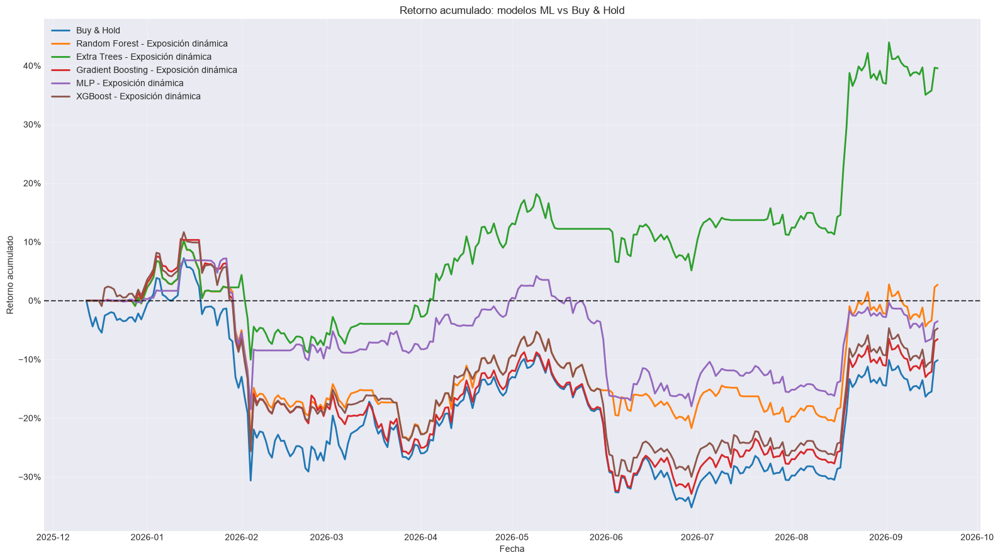

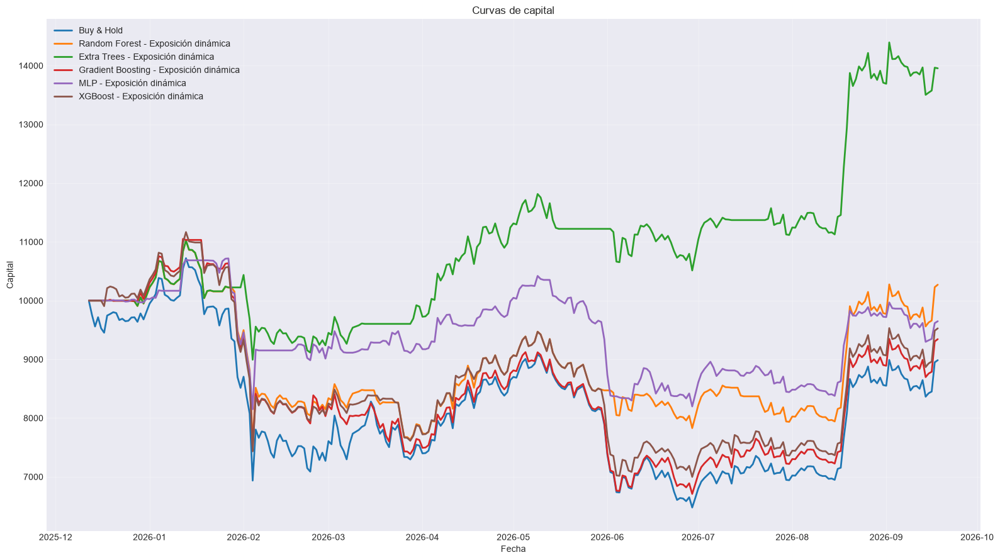

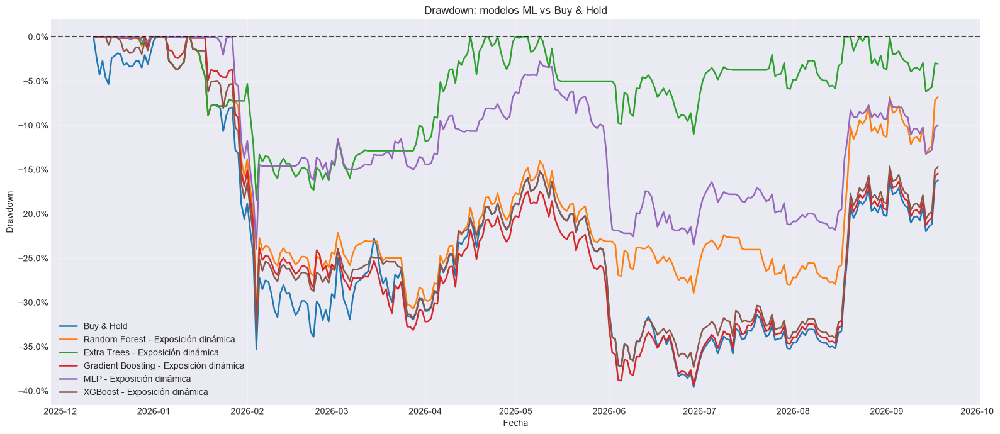


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,XGBoost,0.3536
1,Gradient Boosting,0.3363
2,MLP,0.3269
3,Random Forest,0.2967
4,Extra Trees,0.2842



COMPROBACIONES FINALES
X_dev: 1140
y_dev: 1140
t1_dev: 1140
X_test: 282
y_test: 282
t1_test: 282
test_prices: 282
forward_returns válidos: 281
Random Forest shape: (282,) | índice correcto: True
Extra Trees shape: (282,) | índice correcto: True
Gradient Boosting shape: (282,) | índice correcto: True
MLP shape: (282,) | índice correcto: True
XGBoost shape: (282,) | índice correcto: True

Pipeline terminado correctamente.


In [ ]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN 
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-09-28":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    #"HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-10-19 00:00:00

Optimizando Triple Barrier...


Best trial: 54. Best value: 0.870113: 100%|██████████| 80/80 [01:33<00:00,  1.17s/it]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.576805871922983, 'sl_multiplier': 1.7302606631848583, 'max_holding_bars': 10, 'volatility_window': 10}
Score de balance walk-forward: 0.8701

Tamaño desarrollo: 1371
Tamaño test: 337

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,521,38.00%
1,Neutral,1,414,30.20%
2,Sube,2,436,31.80%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,148,43.92%
1,Neutral,1,95,28.19%
2,Sube,2,94,27.89%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4392
Balanced accuracy: 0.3333
F1 macro: 0.2034

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        10
Neutral    181
Sube       146
Name: count, dtype: int64
Exposición media: 70.18%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        56
Neutral     57
Sube       224
Name: count, dtype: int64
Exposición media: 74.93%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        36
Neutral     75
Sube       226
Name: count, dtype: int64
Exposición media: 78.19%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     82
Sube       230
Name: count, dtype: int64
Exposición media: 80.42%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        43
Neutral     77
Sube       217
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,456.10",-25.44%,-28.63%,45.02%,-0.4831,-0.6926,-48.84%,-0.5862,48.21%,100.00%,$15.00,1.00,1
1,XGBoost - Exposición dinámica,"$10,634.09",6.34%,5.99%,38.78%,0.3665,0.4708,-29.87%,0.2007,44.94%,75.74%,$465.23,31.50,49
2,HistGradient Boosting - Exposición dinámica,"$10,041.58",0.42%,-0.43%,39.30%,0.2079,0.2755,-31.71%,-0.0134,41.96%,75.74%,$726.16,51.50,75
3,CatBoost - Exposición dinámica,"$10,004.61",0.05%,-0.82%,39.45%,0.1987,0.2554,-35.39%,-0.0233,44.94%,77.98%,$424.60,29.50,44
4,MLP - Exposición dinámica,"$9,903.38",-0.97%,-1.92%,36.98%,0.1540,0.2348,-31.96%,-0.0600,45.54%,78.72%,$549.21,39.50,67
5,LightGBM - Exposición dinámica,"$9,087.41",-9.13%,-10.69%,38.71%,-0.0745,-0.0967,-36.29%,-0.2946,43.15%,76.79%,$464.57,33.50,52
6,Gradient Boosting - Exposición dinámica,"$8,877.92",-11.22%,-12.16%,39.19%,-0.1336,-0.1759,-35.27%,-0.3448,44.64%,80.36%,$421.52,32.00,53
7,Extra Trees - Exposición dinámica,"$8,574.75",-14.25%,-16.89%,37.44%,-0.2569,-0.3084,-44.05%,-0.3835,43.45%,78.12%,$187.69,14.00,22
8,Random Forest - Exposición dinámica,"$8,471.86",-15.28%,-17.98%,38.25%,-0.2791,-0.3438,-39.62%,-0.4538,41.37%,74.85%,$431.83,32.00,49
9,Logistic Regression - Exposición dinámica,"$7,585.38",-24.15%,-27.28%,31.42%,-0.7982,-1.0673,-44.19%,-0.6174,45.83%,70.24%,$330.20,27.50,53



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,XGBoost - Exposición dinámica,6.34%,-25.44%,31.78%,0.3665,-0.4831,0.8496,-29.87%,-48.84%,18.98%,True,True,True
1,HistGradient Boosting - Exposición dinámica,0.42%,-25.44%,25.85%,0.2079,-0.4831,0.6910,-31.71%,-48.84%,17.13%,True,True,True
2,CatBoost - Exposición dinámica,0.05%,-25.44%,25.49%,0.1987,-0.4831,0.6818,-35.39%,-48.84%,13.45%,True,True,True
3,MLP - Exposición dinámica,-0.97%,-25.44%,24.47%,0.1540,-0.4831,0.6371,-31.96%,-48.84%,16.88%,True,True,True
4,LightGBM - Exposición dinámica,-9.13%,-25.44%,16.31%,-0.0745,-0.4831,0.4086,-36.29%,-48.84%,12.56%,True,True,True
5,Gradient Boosting - Exposición dinámica,-11.22%,-25.44%,14.22%,-0.1336,-0.4831,0.3495,-35.27%,-48.84%,13.57%,True,True,True
6,Extra Trees - Exposición dinámica,-14.25%,-25.44%,11.19%,-0.2569,-0.4831,0.2262,-44.05%,-48.84%,4.80%,True,True,True
7,Random Forest - Exposición dinámica,-15.28%,-25.44%,10.16%,-0.2791,-0.4831,0.2040,-39.62%,-48.84%,9.23%,True,True,True
8,Logistic Regression - Exposición dinámica,-24.15%,-25.44%,1.29%,-0.7982,-0.4831,-0.3151,-44.19%,-48.84%,4.65%,True,False,True


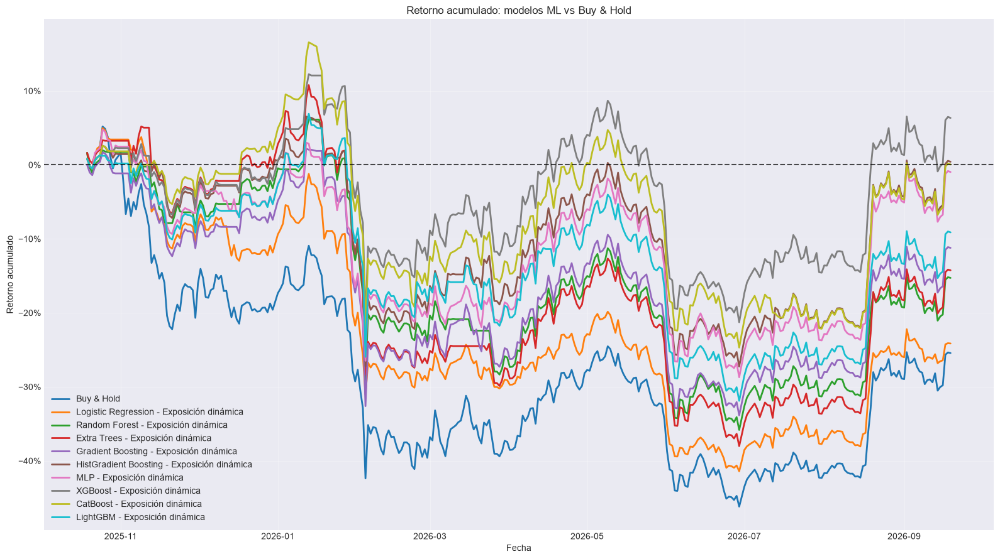

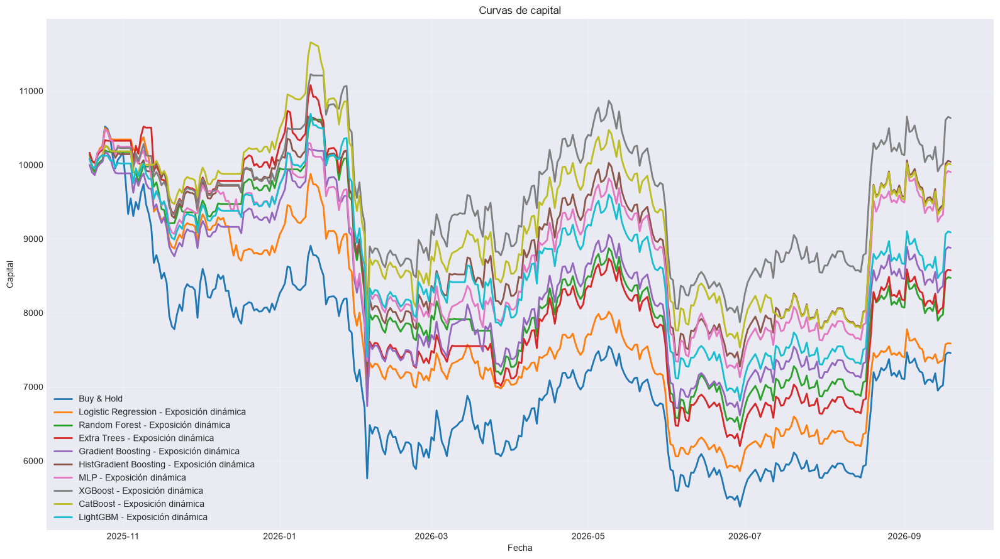

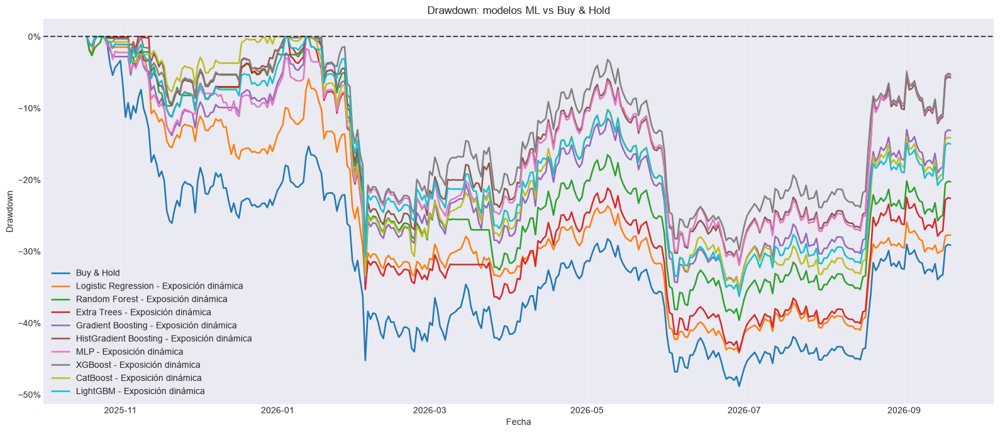


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,Logistic Regression,0.3622
1,MLP,0.3620
2,Gradient Boosting,0.3526
3,LightGBM,0.3425
4,CatBoost,0.3387
5,XGBoost,0.3386
6,HistGradient Boosting,0.3316
7,Random Forest,0.3291
8,Extra Trees,0.2803



COMPROBACIONES FINALES
X_dev: 1371
y_dev: 1371
t1_dev: 1371
X_test: 337
y_test: 337
t1_test: 337
test_prices: 337
forward_returns válidos: 336
Logistic Regression shape: (337,) | índice correcto: True
Random Forest shape: (337,) | índice correcto: True
Extra Trees shape: (337,) | índice correcto: True
Gradient Boosting shape: (337,) | índice correcto: True
HistGradient Boosting shape: (337,) | índice correcto: True
MLP shape: (337,) | índice correcto: True
XGBoost shape: (337,) | índice correcto: True
CatBoost shape: (337,) | índice correcto: True
LightGBM shape: (337,) | índice correcto: True

Pipeline terminado correctamente.


In [469]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1464, 73)
Primer registro: 2022-09-28 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-12 00:00:00

Optimizando Triple Barrier...


Best trial: 64. Best value: 0.813145: 100%|██████████| 80/80 [01:46<00:00,  1.34s/it]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.58193567248558, 'sl_multiplier': 1.9556644063755302, 'max_holding_bars': 11, 'volatility_window': 20}
Score de balance walk-forward: 0.8131

Tamaño desarrollo: 1140
Tamaño test: 282

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,390,34.21%
1,Neutral,1,363,31.84%
2,Sube,2,387,33.95%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,92,32.62%
1,Neutral,1,107,37.94%
2,Sube,2,83,29.43%


... (18 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.3262
Balanced accuracy: 0.3333
F1 macro: 0.164

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        44
Neutral     55
Sube       183
Name: count, dtype: int64
Exposición media: 74.65%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        72
Neutral     71
Sube       139
Name: count, dtype: int64
Exposición media: 61.88%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        33
Neutral     34
Sube       215
Name: count, dtype: int64
Exposición media: 82.27%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        81
Neutral    118
Sube        83
Name: count, dtype: int64
Exposición media: 50.35%

XGBoost - Exposición dinámica
Distribución de predicciones:
prediction
Baja        20
Neutral     61
Sube       201
Name: count, dtype: int64
Exposición media: 82.09%

MÉTRICAS DE RENTA

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,985.43",-10.15%,-12.88%,45.33%,-0.0802,-0.1139,-39.59%,-0.3254,48.75%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$13,954.81",39.55%,54.40%,30.34%,1.5777,2.1862,-18.41%,2.9544,38.08%,61.92%,$284.26,17.00,24
2,Random Forest - Exposición dinámica,"$10,270.50",2.71%,3.54%,38.73%,0.2831,0.3613,-31.33%,0.1130,40.57%,74.56%,$280.66,21.00,26
3,MLP - Exposición dinámica,"$9,648.52",-3.51%,-4.56%,31.16%,0.0046,0.0056,-23.95%,-0.1902,35.94%,50.36%,$836.29,59.00,102
4,XGBoost - Exposición dinámica,"$9,527.15",-4.73%,-6.12%,40.88%,0.0508,0.0651,-37.32%,-0.1640,45.91%,82.03%,$281.70,22.00,33
5,Gradient Boosting - Exposición dinámica,"$9,343.49",-6.57%,-8.47%,42.19%,0.0019,0.0025,-39.28%,-0.2156,43.42%,82.21%,$390.54,28.00,41



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,39.55%,-10.15%,49.69%,1.5777,-0.0802,1.6578,-18.41%,-39.59%,21.17%,True,True,True
1,Random Forest - Exposición dinámica,2.71%,-10.15%,12.85%,0.2831,-0.0802,0.3632,-31.33%,-39.59%,8.26%,True,True,True
2,MLP - Exposición dinámica,-3.51%,-10.15%,6.63%,0.0046,-0.0802,0.0848,-23.95%,-39.59%,15.63%,True,True,True
3,XGBoost - Exposición dinámica,-4.73%,-10.15%,5.42%,0.0508,-0.0802,0.1309,-37.32%,-39.59%,2.26%,True,True,True
4,Gradient Boosting - Exposición dinámica,-6.57%,-10.15%,3.58%,0.0019,-0.0802,0.0820,-39.28%,-39.59%,0.30%,True,True,True


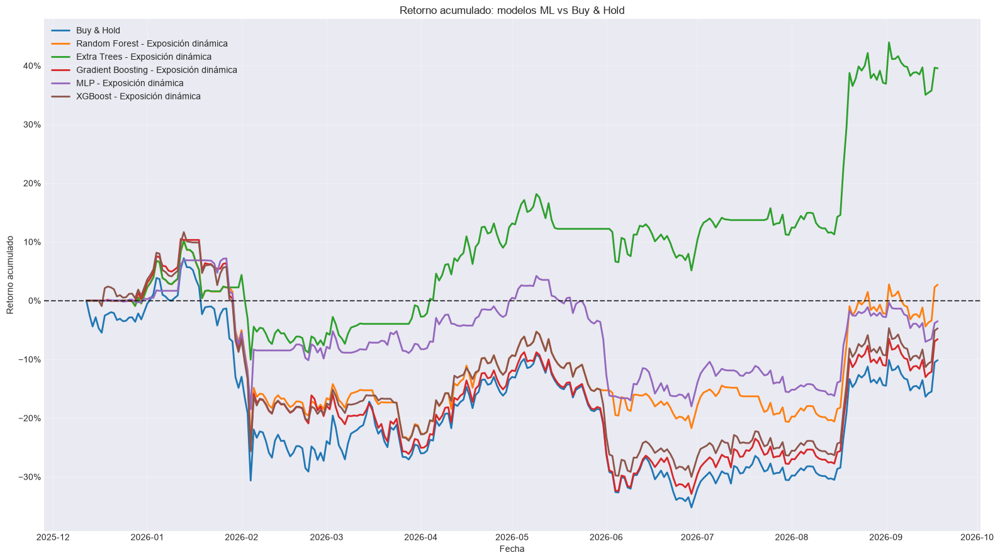

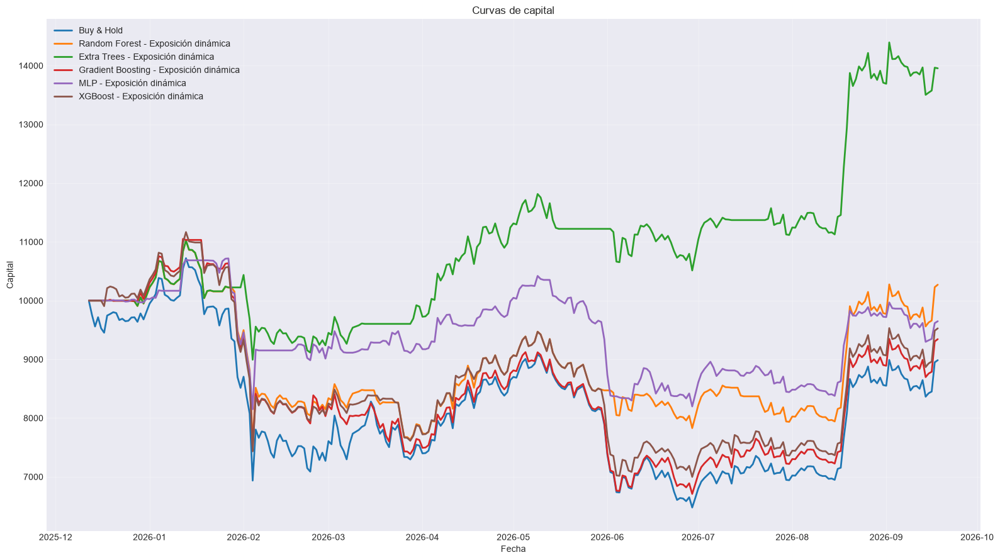

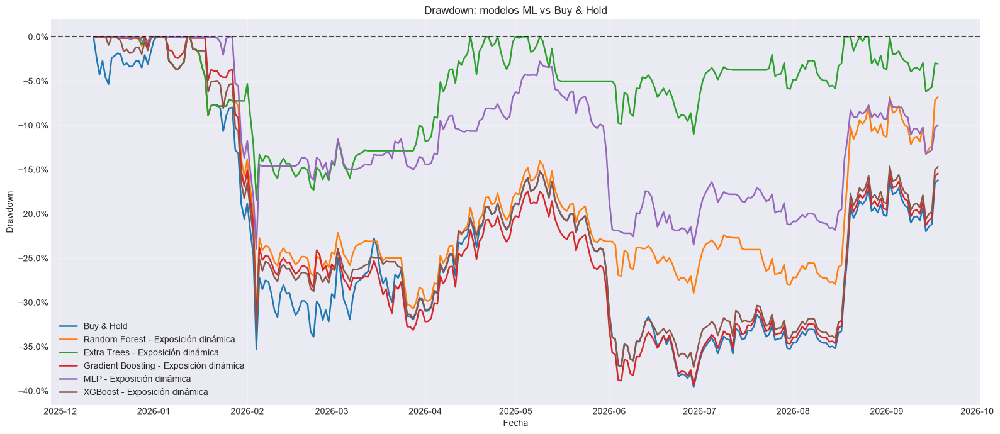


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,XGBoost,0.3536
1,Gradient Boosting,0.3363
2,MLP,0.3269
3,Random Forest,0.2967
4,Extra Trees,0.2842



COMPROBACIONES FINALES
X_dev: 1140
y_dev: 1140
t1_dev: 1140
X_test: 282
y_test: 282
t1_test: 282
test_prices: 282
forward_returns válidos: 281
Random Forest shape: (282,) | índice correcto: True
Extra Trees shape: (282,) | índice correcto: True
Gradient Boosting shape: (282,) | índice correcto: True
MLP shape: (282,) | índice correcto: True
XGBoost shape: (282,) | índice correcto: True

Pipeline terminado correctamente.


In [472]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-09-28":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    #"HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-10-19 00:00:00

Optimizando Triple Barrier...


Best trial: 54. Best value: 0.870113: 100%|██████████| 80/80 [00:34<00:00,  2.30it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.576805871922983, 'sl_multiplier': 1.7302606631848583, 'max_holding_bars': 10, 'volatility_window': 10}
Score de balance walk-forward: 0.8701

Tamaño desarrollo: 1371
Tamaño test: 337

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,521,38.00%
1,Neutral,1,414,30.20%
2,Sube,2,436,31.80%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,148,43.92%
1,Neutral,1,95,28.19%
2,Sube,2,94,27.89%


... (20 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4392
Balanced accuracy: 0.3333
F1 macro: 0.2034

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        56
Neutral     54
Sube       227
Name: count, dtype: int64
Exposición media: 75.37%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        36
Neutral     75
Sube       226
Name: count, dtype: int64
Exposición media: 78.19%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     82
Sube       230
Name: count, dtype: int64
Exposición media: 80.42%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        39
Neutral    101
Sube       197
Name: count, dtype: int64
Exposición media: 73.44%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        36
Neutral    101
Sube       200
Name: count, dtype: int64
Exposición media: 74.33%

XG

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,456.10",-25.44%,-28.63%,45.02%,-0.4831,-0.6926,-48.84%,-0.5862,48.21%,100.00%,$15.00,1.00,1
1,XGBoost - Exposición dinámica,"$10,634.09",6.34%,5.99%,38.78%,0.3665,0.4708,-29.87%,0.2007,44.94%,75.74%,$465.23,31.50,49
2,HistGradient Boosting - Exposición dinámica,"$10,500.01",5.00%,4.54%,35.69%,0.3247,0.4701,-34.30%,0.1323,43.15%,73.36%,$592.87,41.50,61
3,Random Forest - Exposición dinámica,"$9,569.99",-4.30%,-6.33%,38.27%,0.0669,0.0821,-36.25%,-0.1746,42.56%,75.30%,$420.22,30.00,46
4,Gradient Boosting - Exposición dinámica,"$8,877.92",-11.22%,-12.16%,39.19%,-0.1336,-0.1759,-35.27%,-0.3448,44.64%,80.36%,$421.52,32.00,53
5,Extra Trees - Exposición dinámica,"$8,574.75",-14.25%,-16.89%,37.44%,-0.2569,-0.3084,-44.05%,-0.3835,43.45%,78.12%,$187.69,14.00,22
6,MLP - Exposición dinámica,"$7,975.09",-20.25%,-22.53%,38.28%,-0.4501,-0.5790,-43.56%,-0.5173,42.26%,74.26%,$600.59,51.50,81



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,XGBoost - Exposición dinámica,6.34%,-25.44%,31.78%,0.3665,-0.4831,0.8496,-29.87%,-48.84%,18.98%,True,True,True
1,HistGradient Boosting - Exposición dinámica,5.00%,-25.44%,30.44%,0.3247,-0.4831,0.8078,-34.30%,-48.84%,14.54%,True,True,True
2,Random Forest - Exposición dinámica,-4.30%,-25.44%,21.14%,0.0669,-0.4831,0.5500,-36.25%,-48.84%,12.59%,True,True,True
3,Gradient Boosting - Exposición dinámica,-11.22%,-25.44%,14.22%,-0.1336,-0.4831,0.3495,-35.27%,-48.84%,13.57%,True,True,True
4,Extra Trees - Exposición dinámica,-14.25%,-25.44%,11.19%,-0.2569,-0.4831,0.2262,-44.05%,-48.84%,4.80%,True,True,True
5,MLP - Exposición dinámica,-20.25%,-25.44%,5.19%,-0.4501,-0.4831,0.0330,-43.56%,-48.84%,5.29%,True,True,True


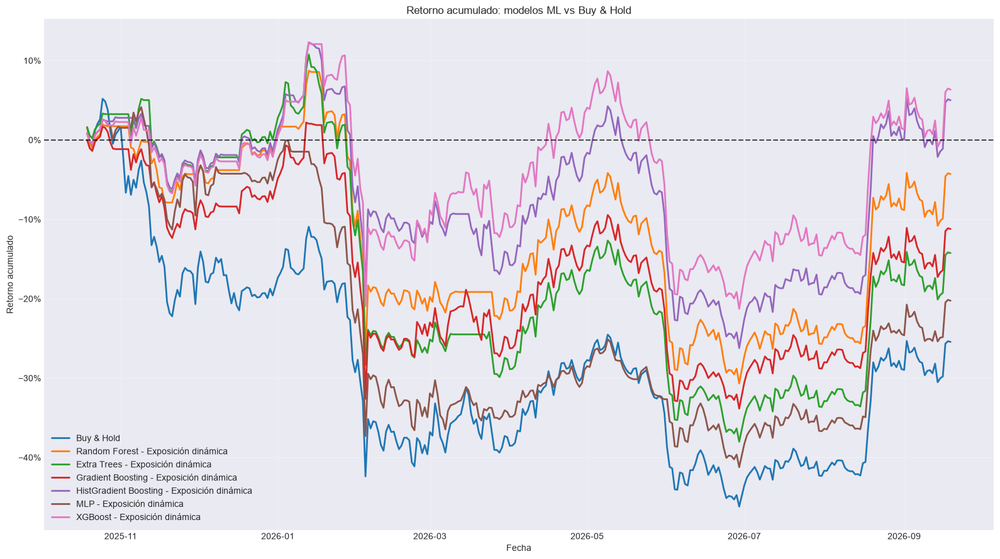

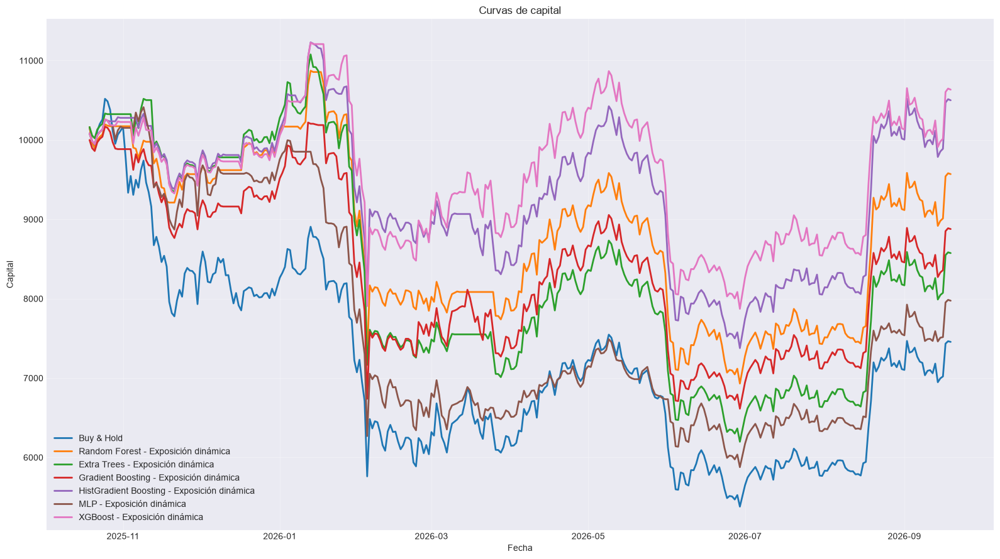

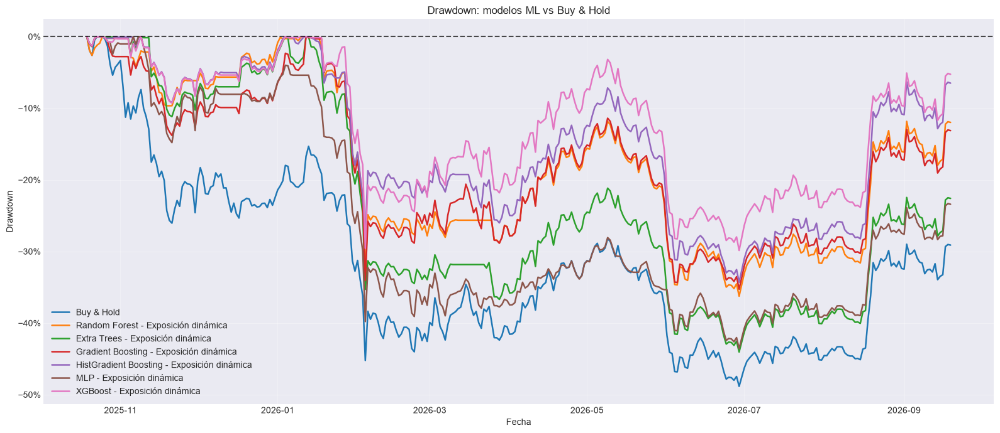


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3740
1,Gradient Boosting,0.3526
2,XGBoost,0.3386
3,HistGradient Boosting,0.3265
4,Random Forest,0.3236
5,Extra Trees,0.2803



COMPROBACIONES FINALES
X_dev: 1371
y_dev: 1371
t1_dev: 1371
X_test: 337
y_test: 337
t1_test: 337
test_prices: 337
forward_returns válidos: 336
Random Forest shape: (337,) | índice correcto: True
Extra Trees shape: (337,) | índice correcto: True
Gradient Boosting shape: (337,) | índice correcto: True
HistGradient Boosting shape: (337,) | índice correcto: True
MLP shape: (337,) | índice correcto: True
XGBoost shape: (337,) | índice correcto: True

Pipeline terminado correctamente.


In [474]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 35

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=15
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2026-01-13 00:00:00

Optimizando Triple Barrier...


Best trial: 39. Best value: 0.826445: 100%|██████████| 80/80 [00:35<00:00,  2.24it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.2702306142487476, 'sl_multiplier': 1.4254829544615102, 'max_holding_bars': 9, 'volatility_window': 25}
Score de balance walk-forward: 0.8264

Tamaño desarrollo: 1440
Tamaño test: 252

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,578,40.14%
1,Neutral,1,433,30.07%
2,Sube,2,429,29.79%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,108,42.86%
1,Neutral,1,75,29.76%
2,Sube,2,69,27.38%


... (20 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4286
Balanced accuracy: 0.3333
F1 macro: 0.2

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja         5
Neutral     85
Sube       162
Name: count, dtype: int64
Exposición media: 81.15%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        26
Neutral     31
Sube       195
Name: count, dtype: int64
Exposición media: 83.53%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        17
Neutral     31
Sube       204
Name: count, dtype: int64
Exposición media: 87.10%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        17
Neutral     41
Sube       194
Name: count, dtype: int64
Exposición media: 85.12%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        62
Neutral     43
Sube       147
Name: count, dtype: int64
Exposición media: 66.87%

XGBoo

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$9,071.92",-9.28%,-15.17%,47.55%,-0.0607,-0.0875,-39.59%,-0.3831,48.21%,100.00%,$15.00,1.00,1
1,Gradient Boosting - Exposición dinámica,"$9,604.02",-3.96%,-7.80%,44.24%,0.0882,0.1187,-36.04%,-0.2165,44.62%,87.05%,$369.56,30.00,45
2,XGBoost - Exposición dinámica,"$9,583.30",-4.17%,-8.09%,45.80%,0.0934,0.1296,-36.18%,-0.2237,47.81%,93.23%,$228.83,18.00,31
3,Extra Trees - Exposición dinámica,"$9,534.27",-4.66%,-8.78%,42.39%,0.0486,0.0617,-35.20%,-0.2494,43.82%,83.47%,$146.25,12.00,20
4,HistGradient Boosting - Exposición dinámica,"$9,019.85",-9.80%,-15.88%,39.12%,-0.1896,-0.2867,-40.01%,-0.3967,43.43%,85.06%,$318.80,26.00,42
5,Random Forest - Exposición dinámica,"$8,936.78",-10.63%,-17.00%,41.55%,-0.1850,-0.2366,-37.61%,-0.4522,47.81%,81.08%,$165.06,14.00,23
6,MLP - Exposición dinámica,"$8,288.24",-17.12%,-25.65%,41.16%,-0.4572,-0.5583,-41.83%,-0.6132,35.46%,66.73%,$496.24,43.00,64



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Gradient Boosting - Exposición dinámica,-3.96%,-9.28%,5.32%,0.0882,-0.0607,0.1490,-36.04%,-39.59%,3.54%,True,True,True
1,XGBoost - Exposición dinámica,-4.17%,-9.28%,5.11%,0.0934,-0.0607,0.1541,-36.18%,-39.59%,3.41%,True,True,True
2,Extra Trees - Exposición dinámica,-4.66%,-9.28%,4.62%,0.0486,-0.0607,0.1094,-35.20%,-39.59%,4.39%,True,True,True
3,HistGradient Boosting - Exposición dinámica,-9.80%,-9.28%,-0.52%,-0.1896,-0.0607,-0.1289,-40.01%,-39.59%,-0.43%,False,False,False
4,Random Forest - Exposición dinámica,-10.63%,-9.28%,-1.35%,-0.1850,-0.0607,-0.1243,-37.61%,-39.59%,1.98%,False,False,True
5,MLP - Exposición dinámica,-17.12%,-9.28%,-7.84%,-0.4572,-0.0607,-0.3965,-41.83%,-39.59%,-2.24%,False,False,False


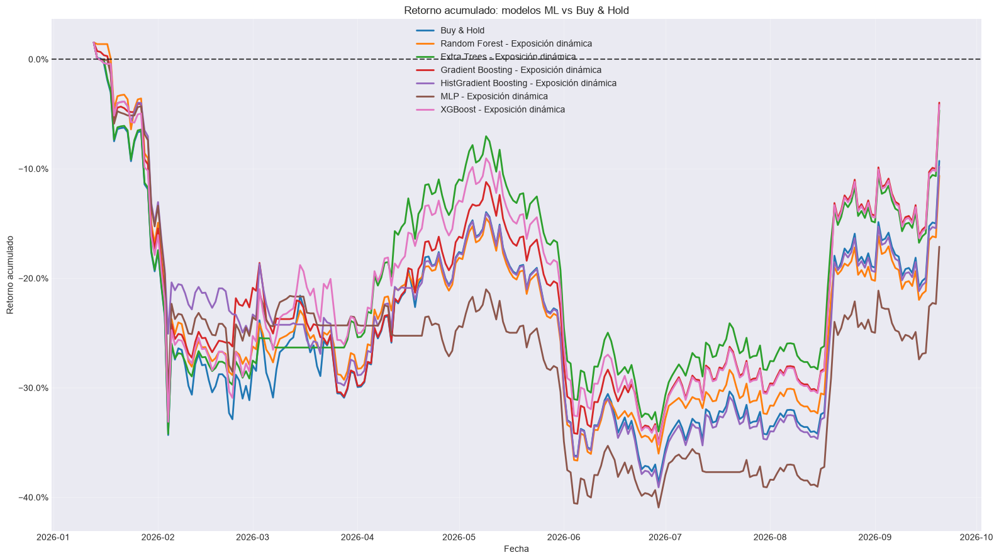

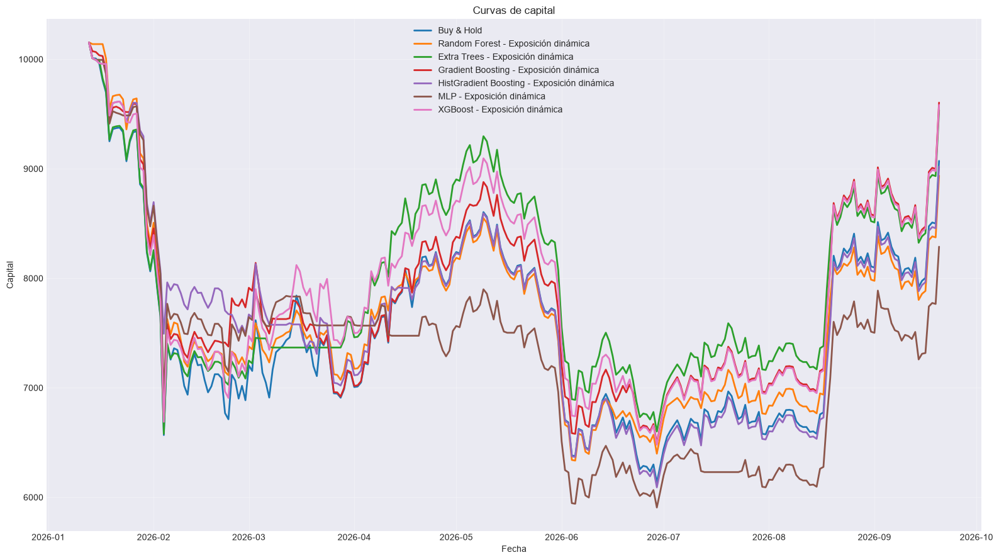

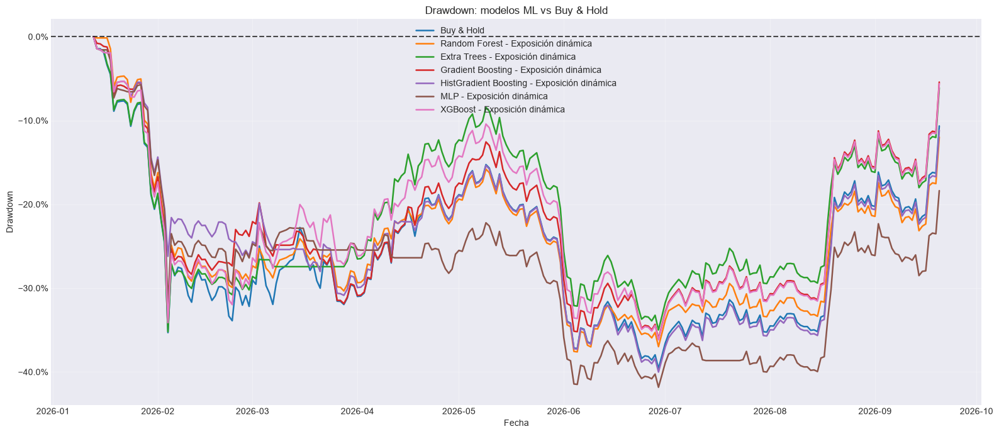


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3356
1,Gradient Boosting,0.3143
2,HistGradient Boosting,0.3025
3,XGBoost,0.3023
4,Random Forest,0.2882
5,Extra Trees,0.2619



COMPROBACIONES FINALES
X_dev: 1440
y_dev: 1440
t1_dev: 1440
X_test: 252
y_test: 252
t1_test: 252
test_prices: 252
forward_returns válidos: 251
Random Forest shape: (252,) | índice correcto: True
Extra Trees shape: (252,) | índice correcto: True
Gradient Boosting shape: (252,) | índice correcto: True
HistGradient Boosting shape: (252,) | índice correcto: True
MLP shape: (252,) | índice correcto: True
XGBoost shape: (252,) | índice correcto: True

Pipeline terminado correctamente.


In [476]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 35

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.15

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=15
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2026-01-13 00:00:00

Optimizando Triple Barrier...


Best trial: 39. Best value: 0.826445: 100%|██████████| 80/80 [00:34<00:00,  2.30it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.2702306142487476, 'sl_multiplier': 1.4254829544615102, 'max_holding_bars': 9, 'volatility_window': 25}
Score de balance walk-forward: 0.8264

Tamaño desarrollo: 1440
Tamaño test: 252

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,578,40.14%
1,Neutral,1,433,30.07%
2,Sube,2,429,29.79%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,108,42.86%
1,Neutral,1,75,29.76%
2,Sube,2,69,27.38%


... (20 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4286
Balanced accuracy: 0.3333
F1 macro: 0.2

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja         5
Neutral     85
Sube       162
Name: count, dtype: int64
Exposición media: 81.15%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        26
Neutral     31
Sube       195
Name: count, dtype: int64
Exposición media: 83.53%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        17
Neutral     31
Sube       204
Name: count, dtype: int64
Exposición media: 87.10%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        17
Neutral     41
Sube       194
Name: count, dtype: int64
Exposición media: 85.12%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        62
Neutral     43
Sube       147
Name: count, dtype: int64
Exposición media: 66.87%

XGBoo

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$9,071.92",-9.28%,-15.17%,47.55%,-0.0607,-0.0875,-39.59%,-0.3831,48.21%,100.00%,$15.00,1.00,1
1,Gradient Boosting - Exposición dinámica,"$9,604.02",-3.96%,-7.80%,44.24%,0.0882,0.1187,-36.04%,-0.2165,44.62%,87.05%,$369.56,30.00,45
2,XGBoost - Exposición dinámica,"$9,583.30",-4.17%,-8.09%,45.80%,0.0934,0.1296,-36.18%,-0.2237,47.81%,93.23%,$228.83,18.00,31
3,Extra Trees - Exposición dinámica,"$9,534.27",-4.66%,-8.78%,42.39%,0.0486,0.0617,-35.20%,-0.2494,43.82%,83.47%,$146.25,12.00,20
4,HistGradient Boosting - Exposición dinámica,"$9,019.85",-9.80%,-15.88%,39.12%,-0.1896,-0.2867,-40.01%,-0.3967,43.43%,85.06%,$318.80,26.00,42
5,Random Forest - Exposición dinámica,"$8,936.78",-10.63%,-17.00%,41.55%,-0.1850,-0.2366,-37.61%,-0.4522,47.81%,81.08%,$165.06,14.00,23
6,MLP - Exposición dinámica,"$8,288.24",-17.12%,-25.65%,41.16%,-0.4572,-0.5583,-41.83%,-0.6132,35.46%,66.73%,$496.24,43.00,64



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Gradient Boosting - Exposición dinámica,-3.96%,-9.28%,5.32%,0.0882,-0.0607,0.1490,-36.04%,-39.59%,3.54%,True,True,True
1,XGBoost - Exposición dinámica,-4.17%,-9.28%,5.11%,0.0934,-0.0607,0.1541,-36.18%,-39.59%,3.41%,True,True,True
2,Extra Trees - Exposición dinámica,-4.66%,-9.28%,4.62%,0.0486,-0.0607,0.1094,-35.20%,-39.59%,4.39%,True,True,True
3,HistGradient Boosting - Exposición dinámica,-9.80%,-9.28%,-0.52%,-0.1896,-0.0607,-0.1289,-40.01%,-39.59%,-0.43%,False,False,False
4,Random Forest - Exposición dinámica,-10.63%,-9.28%,-1.35%,-0.1850,-0.0607,-0.1243,-37.61%,-39.59%,1.98%,False,False,True
5,MLP - Exposición dinámica,-17.12%,-9.28%,-7.84%,-0.4572,-0.0607,-0.3965,-41.83%,-39.59%,-2.24%,False,False,False


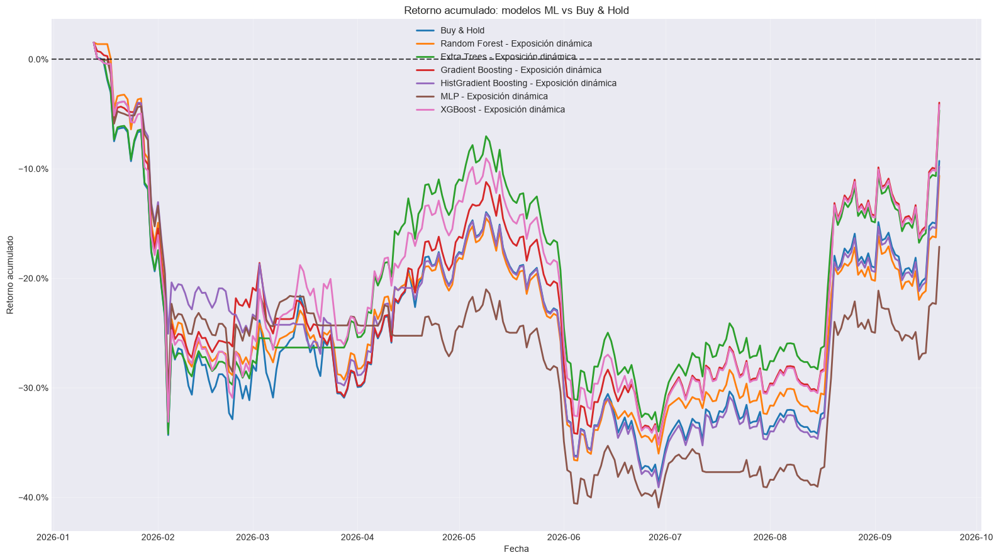

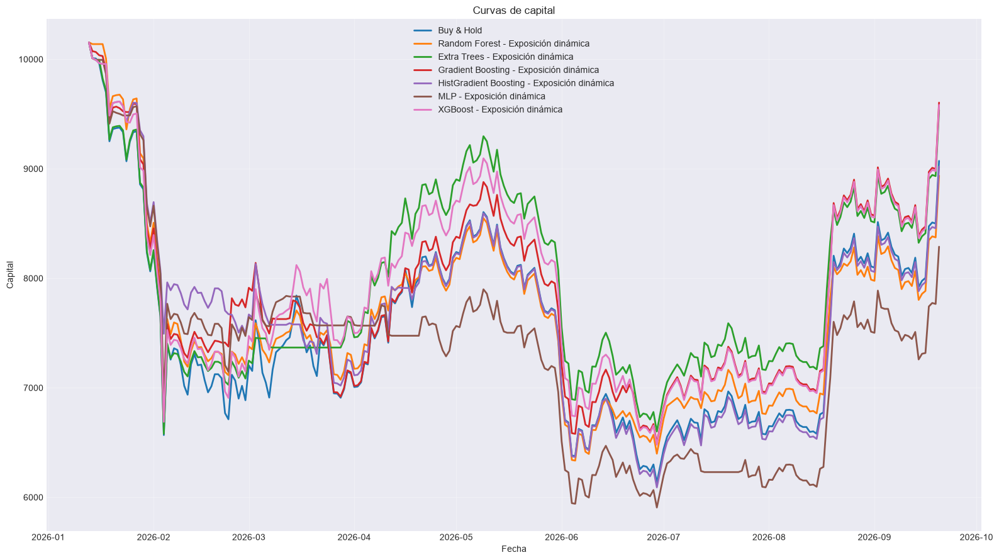

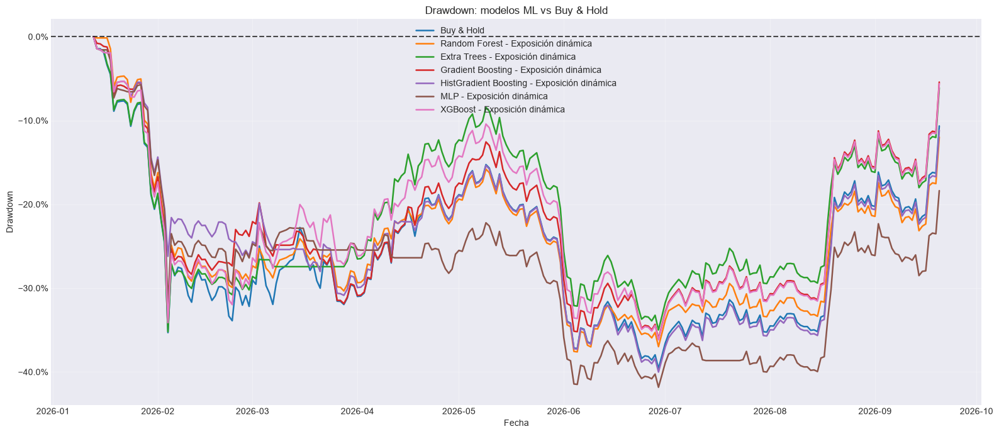


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3356
1,Gradient Boosting,0.3143
2,HistGradient Boosting,0.3025
3,XGBoost,0.3023
4,Random Forest,0.2882
5,Extra Trees,0.2619



COMPROBACIONES FINALES
X_dev: 1440
y_dev: 1440
t1_dev: 1440
X_test: 252
y_test: 252
t1_test: 252
test_prices: 252
forward_returns válidos: 251
Random Forest shape: (252,) | índice correcto: True
Extra Trees shape: (252,) | índice correcto: True
Gradient Boosting shape: (252,) | índice correcto: True
HistGradient Boosting shape: (252,) | índice correcto: True
MLP shape: (252,) | índice correcto: True
XGBoost shape: (252,) | índice correcto: True

Pipeline terminado correctamente.


In [475]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 35

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.15

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=15
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Modelos Prometedores

Dimensiones del dataframe: (1464, 73)
Primer registro: 2022-09-28 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-12 00:00:00

Optimizando Triple Barrier...


Best trial: 57. Best value: 0.792374: 100%|██████████| 80/80 [00:29<00:00,  2.71it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.5033124017537984, 'sl_multiplier': 1.9152741321452795, 'max_holding_bars': 10, 'volatility_window': 58}
Score de balance walk-forward: 0.7924

Tamaño desarrollo: 1102
Tamaño test: 283

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,353,32.03%
1,Neutral,1,392,35.57%
2,Sube,2,357,32.40%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,87,30.74%
1,Neutral,1,120,42.40%
2,Sube,2,76,26.86%


... (18 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 1 Neutral
Accuracy: 0.424
Balanced accuracy: 0.3333
F1 macro: 0.1985

Periodos por año: 365.0

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        48
Neutral      8
Sube       227
Name: count, dtype: int64
Exposición media: 81.63%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        69
Neutral     12
Sube       202
Name: count, dtype: int64
Exposición media: 73.50%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     24
Sube       234
Name: count, dtype: int64
Exposición media: 86.93%

MLP - Exposición dinámica
Distribución de predicciones:
prediction
Baja        61
Neutral     29
Sube       193
Name: count, dtype: int64
Exposición media: 73.32%

XGBoost - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     26
Sube       232
Name: count, dtype: int64
Exposición media: 86.57%

MÉTRICAS DE RE

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,975.36",-10.25%,-12.97%,45.25%,-0.0832,-0.1181,-39.59%,-0.3275,48.58%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$10,128.96",1.29%,1.68%,38.48%,0.2360,0.2721,-36.20%,0.0464,37.59%,73.40%,$332.01,26.00,31
2,XGBoost - Exposición dinámica,"$8,874.56",-11.25%,-14.37%,42.48%,-0.1512,-0.2015,-43.04%,-0.3338,43.97%,86.52%,$495.15,37.00,50
3,Gradient Boosting - Exposición dinámica,"$8,806.68",-11.93%,-15.22%,42.90%,-0.1689,-0.2260,-39.75%,-0.3827,43.97%,86.88%,$499.62,37.00,51
4,MLP - Exposición dinámica,"$8,504.51",-14.95%,-18.97%,35.85%,-0.4064,-0.5423,-37.01%,-0.5127,37.23%,73.40%,$490.98,40.00,57
5,Random Forest - Exposición dinámica,"$7,154.91",-28.45%,-35.26%,41.49%,-0.8356,-1.0296,-53.06%,-0.6647,38.65%,81.56%,$273.44,23.00,29



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,1.29%,-10.25%,11.54%,0.2360,-0.0832,0.3192,-36.20%,-39.59%,3.38%,True,True,True
1,XGBoost - Exposición dinámica,-11.25%,-10.25%,-1.01%,-0.1512,-0.0832,-0.0680,-43.04%,-39.59%,-3.46%,False,False,False
2,Gradient Boosting - Exposición dinámica,-11.93%,-10.25%,-1.69%,-0.1689,-0.0832,-0.0857,-39.75%,-39.59%,-0.17%,False,False,False
3,MLP - Exposición dinámica,-14.95%,-10.25%,-4.71%,-0.4064,-0.0832,-0.3232,-37.01%,-39.59%,2.58%,False,False,True
4,Random Forest - Exposición dinámica,-28.45%,-10.25%,-18.20%,-0.8356,-0.0832,-0.7524,-53.06%,-39.59%,-13.47%,False,False,False


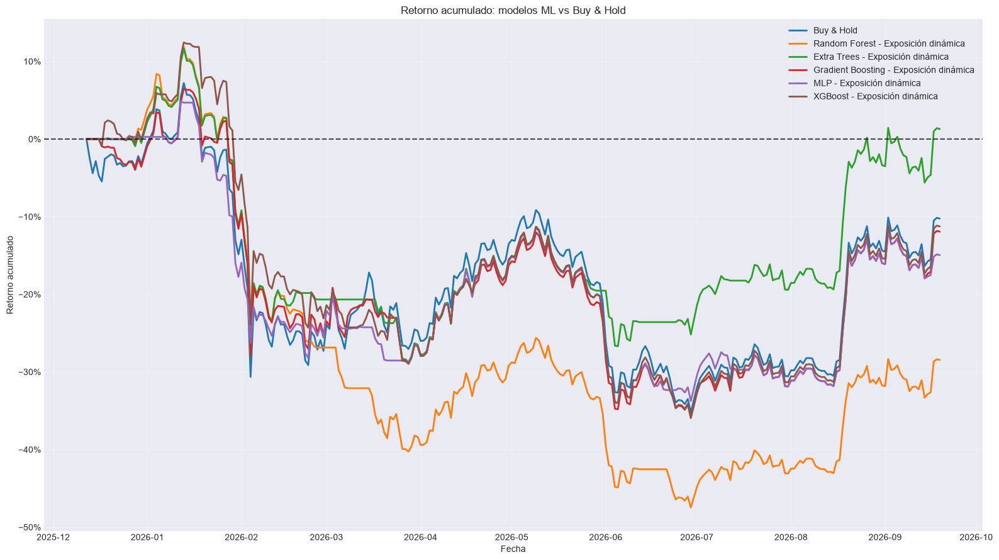

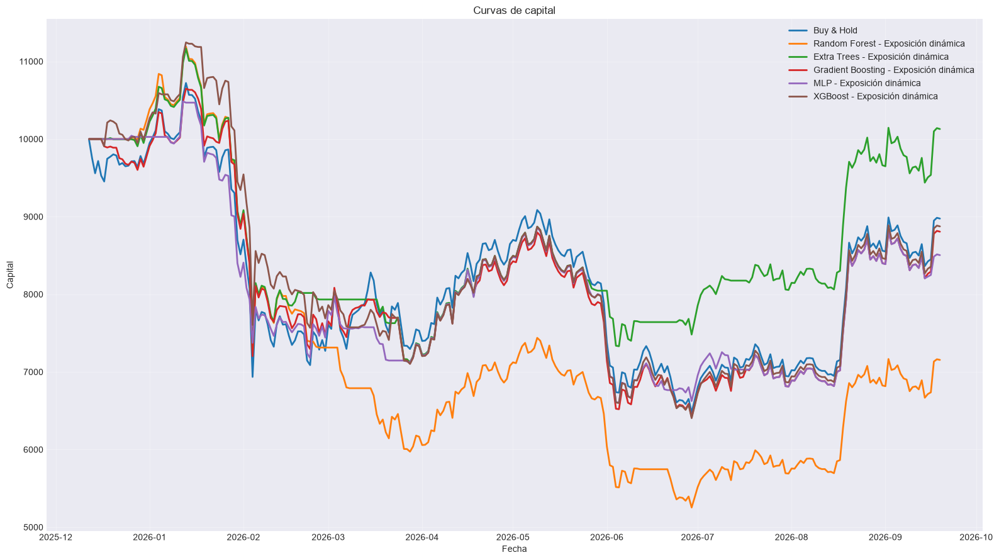

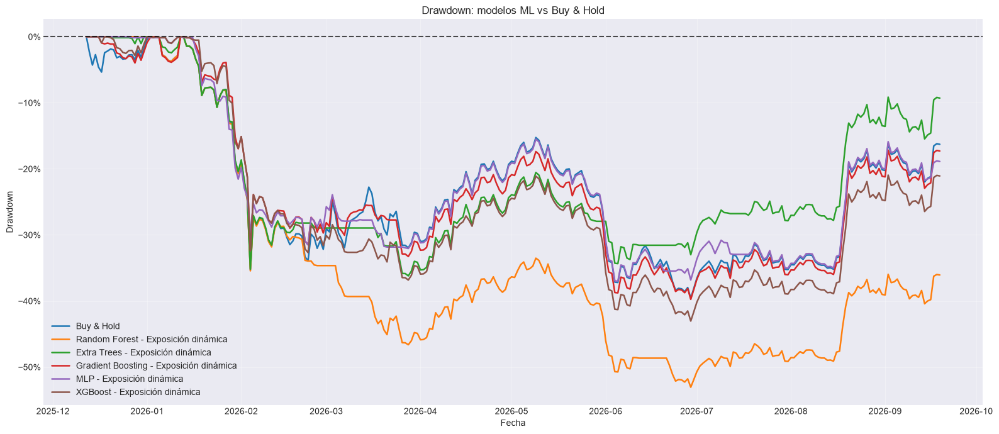


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,XGBoost,0.3507
1,MLP,0.3446
2,Gradient Boosting,0.3352
3,Extra Trees,0.3220
4,Random Forest,0.3129



COMPROBACIONES FINALES
X_dev: 1102
y_dev: 1102
t1_dev: 1102
X_test: 283
y_test: 283
t1_test: 283
test_prices: 283
forward_returns válidos: 282
Random Forest shape: (283,) | índice correcto: True
Extra Trees shape: (283,) | índice correcto: True
Gradient Boosting shape: (283,) | índice correcto: True
MLP shape: (283,) | índice correcto: True
XGBoost shape: (283,) | índice correcto: True

Pipeline terminado correctamente.


In [473]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 15

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-09-28":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=3
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    #"Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    #"HistGradient Boosting",
    "MLP",
    "XGBoost",
    #"CatBoost",
    #"LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                150,
                750,
                step=25
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=25
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                750,
                step=75
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=False,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                650,
                step=35
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

In [449]:
d =  df_bitcoin.drop(columns  =  ["Bono_EEUU_10A_diff", "ADXR", "ADX", "Euro_log_ret", "Gas_Natural_log_ret", "BB_Middle", "MIDPOINT",
                                  "Gas_Natural_log_ret", "MIDPRICE", "MACDEXT_Signal", "ADX", "ROCR", "CMO", "APO", "AD", "OBV", "TRANGE",
                                  "Bono_EEUU_5A_diff", "TEMA", "Bono_EEUU_3M_diff", "MAMA", "Petroleo_WTI_log_ret_7", "Petroleo_WTI_log_ret_14",
                                  "S&P_500_log_ret_7", "Nikkei_Asia_log_ret_7", "MACD_Signal", "MACDEXT", "ATR", "Euro_log_ret_7", "Nikkei_Asia_log_ret_14",
                                  "KAMA", "MACDEXT_Hist", "Yuan_Chino_log_ret_14", "Oro_log_ret_14", "Gas_Natural_log_ret_14", "DEMA", "Euro_log_ret_14",
                                  "Gas_Natural_log_ret_7", "T3", "TRIX", "Petroleo_WTI_log_ret", "Yuan_Chino_log_ret", "Yuan_Chino_log_ret_7", "Indice_Dolar_DXY_log_ret_14",
                                  "Oro_log_ret_7", "Nikkei_Asia_log_ret", "FAMA", "TRIMA", "SMA", "WMA", "PPO", "BTC_Close", "BB_Lower", "SAR", "MOM",
                                  "Indice_Dolar_DXY_log_ret_7", "STOCH_SlowK", "BB_Upper"])
matriz_corr =  d.corr(method  =  "spearman")
mascara =  np.triu(np.ones_like(matriz_corr, dtype  =  bool))
plt.figure(figsize =  (22, 20))
sns.heatmap(
    matriz_corr, 
    cmap = "bwr",
    fmt  =  ".2f",
    annot  =  True, 
    mask  =  mascara,
    cbar =  False
)
plt.title("Heatmap de Correlaciones (Método de Spearman)")
plt.show()

KeyError: "['Petroleo_WTI_log_ret_7', 'Petroleo_WTI_log_ret_14', 'S&P_500_log_ret_7', 'Nikkei_Asia_log_ret_7', 'Euro_log_ret_7', 'Nikkei_Asia_log_ret_14', 'Yuan_Chino_log_ret_14', 'Oro_log_ret_14', 'Gas_Natural_log_ret_14', 'Euro_log_ret_14', 'Gas_Natural_log_ret_7', 'Yuan_Chino_log_ret_7', 'Indice_Dolar_DXY_log_ret_14', 'Oro_log_ret_7', 'Indice_Dolar_DXY_log_ret_7'] not found in axis"

In [456]:
df_bitcoin

Ticker,Bitcoin_log_ret,Petroleo_WTI_log_ret,Yuan_Chino_log_ret,Indice_Dolar_DXY_log_ret,Euro_log_ret,Oro_log_ret,Gas_Natural_log_ret,S&P_500_log_ret,NASDAQ_Tecnologico_log_ret,Nikkei_Asia_log_ret,Cardano_log_ret,Bitcoin_Cash_log_ret,Ethereum_log_ret,Chainlink_log_ret,Litecoin_log_ret,Bono_EEUU_5A_diff,Bono_EEUU_3M_diff,Bono_EEUU_10A_diff,Indice_Volatilidad_VIX_diff,BTC_Volume_diff,BTC_Close,SMA,EMA,WMA,TRIMA,KAMA,MAMA,FAMA,T3,DEMA,TEMA,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,ULTOSC,TRIX,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-04-02,0.027889,0.220481,-0.002525,0.005104,-0.006638,0.029654,-0.022301,0.022573,0.017071,-0.013749,0.035937,0.037808,0.046068,0.010240,0.012450,0.017,0.002,-0.008,-6.150002,7.314220e+09,6793.624512,6672.733008,6828.587819,6340.281758,6229.477368,6444.821408,6470.097046,6573.930184,5735.514020,6003.866656,6151.455867,-265.514273,-435.332320,169.818047,120.323734,-487.591792,607.915526,78.146020,63.590703,75.137572,78.146020,50.698224,100.000000,100.000000,-22.606913,30.550577,38.621998,120.323734,1.903909,377.309570,0.379519,129.108810,1.396447,5.880471,1.058805,0.000000,100.000000,100.000000,62.724523,49.341264,-0.964385,7233.404070,6096.403296,4959.402522,6311.939697,6436.625977,5072.781116,492.329102,489.674911,7.207860,2.945689e+11,1.410134e+10,-3.930219e+10
2020-04-03,-0.008906,0.112680,0.002270,0.003985,-0.009745,0.004909,0.043499,-0.015253,-0.015374,0.000082,0.009677,0.013493,0.000438,0.001458,0.012089,-0.019,-0.007,-0.040,-4.110001,-8.684141e+09,6733.387207,6605.337712,6822.445844,6344.194932,6196.451860,6454.429671,6483.261554,6571.663469,5770.384157,6045.186780,6227.654133,-223.287504,-392.923357,169.635852,248.458953,-327.307794,575.766747,81.458198,77.471390,70.054312,81.458198,49.868951,82.964239,94.321413,-27.229021,28.932635,37.162420,248.458953,3.964590,-1.416504,-0.194035,103.537097,-0.262097,-0.021033,0.999790,21.428571,92.857143,71.428571,54.460562,50.740031,-0.879416,7263.853335,6173.054346,5082.255357,6311.939697,6436.625977,5193.709102,329.884766,478.261329,7.102834,2.697828e+11,5.419446e+09,-7.827869e+10
2020-04-04,0.019726,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.006481,0.012667,0.021776,0.009132,0.007810,0.000,0.000,0.000,0.000000,-5.790516e+09,6867.527344,6531.629867,6825.354328,6361.110393,6176.896360,6470.288431,6502.474843,6569.933753,5815.827778,6100.961850,6321.112954,-176.958629,-349.730411,172.771782,326.679878,-180.417606,507.097484,73.425451,77.676556,75.084469,73.425451,51.761203,100.000000,94.321413,-16.936227,27.430259,35.866429,326.679878,5.246747,186.464355,0.707762,92.735889,3.522405,2.790938,1.027909,14.285714,85.714286,71.428571,61.430514,54.292720,-0.790312,7315.752599,6246.814966,5177.877333,6348.891113,6436.625977,5307.381410,182.468750,457.133288,6.656447,2.988125e+11,1.061182e+10,-4.509271e+10
2020-04-05,-0.011187,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.015564,-0.028979,-0.011586,-0.021240,-0.000133,0.000,0.000,0.000,0.000000,-3.675579e+09,6791.129395,6453.915983,6823.146268,6377.852298,6171.866058,6483.461977,6646.802119,6589.150844,5869.801532,6143.423183,6391.158488,-144.738878,-308.732105,163.993226,374.396766,-47.145213,421.541979,70.533077,75.138909,66.460450,70.533077,50.589968,66.943806,83.302681,-22.798367,26.023514,34.569112,374.396766,6.054958,74.688965,-0.426356,78.545655,1.179935,1.112032,1.011120,7.142857,78.571429,71.428571,62.139303,60.244911,-0.702551,7266.554826,6335.647437,5404.740047,6394.785156,6436.625977,5414.233379,167.484863,436.444114,6.426679,2.958023e+11,1.081346e+10,-7.460312e+10
2020-04-06,0.068384,-0.083106,-0.001143,0.001093,-0.003735,0.0

In [459]:
df_bitcoin.loc["2021-01-01":]

Ticker,Bitcoin_log_ret,Petroleo_WTI_log_ret,Yuan_Chino_log_ret,Indice_Dolar_DXY_log_ret,Euro_log_ret,Oro_log_ret,Gas_Natural_log_ret,S&P_500_log_ret,NASDAQ_Tecnologico_log_ret,Nikkei_Asia_log_ret,Cardano_log_ret,Bitcoin_Cash_log_ret,Ethereum_log_ret,Chainlink_log_ret,Litecoin_log_ret,Bono_EEUU_5A_diff,Bono_EEUU_3M_diff,Bono_EEUU_10A_diff,Indice_Volatilidad_VIX_diff,BTC_Volume_diff,BTC_Close,SMA,EMA,WMA,TRIMA,KAMA,MAMA,FAMA,T3,DEMA,TEMA,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,ULTOSC,TRIX,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2021-01-01,0.012760,0.000000,-0.001456,0.000000,-0.009774,0.000000,0.000000,0.000000,0.000000,0.000000,-0.033904,-0.003115,-0.010129,0.052037,0.012275,0.000,0.000,0.000,0.000000,-6.024663e+09,29374.152344,22428.243750,23382.954772,24317.577373,22020.982161,25593.332045,26954.451063,23778.089147,24531.725655,27107.906132,28379.911601,2523.873120,2083.567586,440.305535,3119.256661,2616.558275,502.698385,94.740233,90.252372,93.732243,94.740233,83.473437,100.000000,100.000000,-3.043498,53.293797,44.953126,3119.256661,13.602867,5591.123047,0.476942,122.318915,66.946874,23.508877,1.235089,21.428571,100.000000,78.571429,93.657280,69.318480,1.442138,30373.474456,24250.427637,18127.380818,26088.617188,25879.997070,26638.814453,797.041016,1229.377650,4.185236,2.207020e+12,7.656874e+10,1.622881e+12
2021-01-02,0.089590,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.011753,0.036221,0.058715,0.028856,0.081470,0.000,0.000,0.000,0.000000,2.713512e+10,32127.267578,22850.972721,23947.103985,24943.320846,22447.296216,26814.996334,27213.091889,23863.964215,25095.379986,27959.488392,29418.317973,2790.061616,2224.866392,565.195224,3398.747634,2794.826899,603.920734,90.691041,91.953654,85.660217,90.691041,87.570593,100.000000,100.000000,-9.347699,55.334068,47.038934,3398.747634,14.506955,8885.921875,0.676884,157.978508,75.141187,38.233250,1.382333,14.285714,100.000000,85.714286,94.092984,68.595046,1.519153,31456.815089,24899.671875,18342.528661,27465.174805,27657.242188,27231.176953,4063.935547,1431.846071,4.456794,2.240557e+12,8.094605e+10,1.690746e+12
2021-01-03,0.020175,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.144449,0.173517,0.230695,0.110667,0.156786,0.000,0.000,0.000,0.000000,1.079981e+10,32782.023438,23320.381315,24517.098788,25584.033795,22895.358724,28160.302806,29997.557663,25397.362577,25704.572987,28803.840631,30425.209129,3019.049518,2383.703017,635.346501,3592.476162,2971.211039,621.265123,84.731183,90.054152,74.801089,84.731183,88.312680,100.000000,100.000000,-14.671918,57.382163,48.304662,3592.476162,14.978269,9046.074219,0.255303,170.542167,76.625360,38.111281,1.381113,7.142857,100.000000,92.857143,94.610251,68.541474,1.603816,32446.594524,25576.440820,18706.287117,27792.552734,28383.962891,28415.965000,2556.242188,1512.160080,4.612772,2.206803e+12,6.463827e+10,1.769411e+12
2021-01-04,-0.025022,-0.018723,-0.000046,-0.000667,0.005766,0.026813,0.016407,-0.014865,-0.014838,-0.006793,0.092056,-0.033395,0.064242,-0.005812,-0.034183,-0.007,0.003,0.000,4.219999,2.498240e+09,31971.914062,23747.637435,24998.054613,26142.197198,23357.273535,28870.520434,30984.735863,26794.205899,26347.905689,29458.158881,31137.100714,3099.426762,2526.847766,572.578996,3803.946677,3133.621891,670.324786,73.101987,82.841404,58.844655,73.101987,81.804905,0.000000,66.666667,-21.650966,56.310852,47.993424,3803.946677,15.525891,7307.123047,-0.177857,102.773993,63.609810,29.625725,1.296257,0.000000,92.857143,92.857143,87.910042,68.989752,1.676689,33002.390816,26204.182715,19405.974613,28011.684570,28519.582031,34608.558594,4717.462891,1741.110280,5.445749,2.237443e+12,

Dimensiones del dataframe: (2099, 73)
Primer registro: 2021-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-08-07 00:00:00

Optimizando Triple Barrier...


Best trial: 78. Best value: 0.837127: 100%|██████████| 80/80 [00:35<00:00,  2.27it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 1.127638230593832, 'sl_multiplier': 0.9325355279998934, 'max_holding_bars': 4, 'volatility_window': 40}
Score de balance walk-forward: 0.8371

Tamaño desarrollo: 1634
Tamaño test: 416

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,589,36.05%
1,Neutral,1,481,29.44%
2,Sube,2,564,34.52%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,179,43.03%
1,Neutral,1,95,22.84%
2,Sube,2,142,34.13%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4303
Balanced accuracy: 0.3333
F1 macro: 0.2006

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        33
Neutral    282
Sube       101
Name: count, dtype: int64
Exposición media: 58.17%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        19
Neutral    295
Sube       102
Name: count, dtype: int64
Exposición media: 59.98%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        62
Neutral     90
Sube       264
Name: count, dtype: int64
Exposición media: 74.28%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        55
Neutral    129
Sube       232
Name: count, dtype: int64
Exposición media: 71.27%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        50
Neutral    146
Sube       220
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,172.87",-28.27%,-24.84%,43.76%,-0.4487,-0.6409,-53.06%,-0.4681,48.19%,100.00%,$15.00,1.00,1
1,XGBoost - Exposición dinámica,"$9,463.51",-5.36%,-4.75%,36.31%,0.0478,0.0630,-35.02%,-0.1355,42.65%,68.67%,"$1,129.97",82.00,147
2,Extra Trees - Exposición dinámica,"$9,149.88",-8.50%,-7.53%,37.49%,-0.0208,-0.0268,-43.46%,-0.1734,41.69%,74.22%,$921.01,65.00,97
3,LightGBM - Exposición dinámica,"$8,342.93",-16.57%,-14.76%,34.93%,-0.2815,-0.3718,-41.58%,-0.3550,44.10%,69.28%,$801.20,63.00,122
4,Logistic Regression - Exposición dinámica,"$8,219.84",-17.80%,-15.87%,31.91%,-0.3801,-0.4837,-33.99%,-0.4670,44.58%,58.19%,$643.82,48.50,88
5,MLP - Exposición dinámica,"$8,070.66",-19.29%,-16.91%,30.35%,-0.4714,-0.6681,-38.72%,-0.4368,39.76%,58.19%,"$1,135.19",93.50,149
6,Gradient Boosting - Exposición dinámica,"$8,043.10",-19.57%,-16.85%,38.32%,-0.3085,-0.4134,-44.27%,-0.3807,40.72%,71.20%,"$1,048.19",86.00,148
7,CatBoost - Exposición dinámica,"$7,835.92",-21.64%,-19.35%,36.55%,-0.4039,-0.5228,-45.50%,-0.4251,44.10%,69.16%,$873.53,71.00,132
8,HistGradient Boosting - Exposición dinámica,"$7,584.19",-24.16%,-21.63%,36.68%,-0.4795,-0.6389,-48.40%,-0.4470,40.96%,70.36%,"$1,174.94",96.00,168
9,Random Forest - Exposición dinámica,"$7,220.64",-27.79%,-24.96%,32.14%,-0.7293,-0.8957,-47.63%,-0.5240,45.30%,60.00%,$436.73,37.50,70



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,XGBoost - Exposición dinámica,-5.36%,-28.27%,22.91%,0.0478,-0.4487,0.4965,-35.02%,-53.06%,18.04%,True,True,True
1,Extra Trees - Exposición dinámica,-8.50%,-28.27%,19.77%,-0.0208,-0.4487,0.4280,-43.46%,-53.06%,9.60%,True,True,True
2,LightGBM - Exposición dinámica,-16.57%,-28.27%,11.70%,-0.2815,-0.4487,0.1673,-41.58%,-53.06%,11.48%,True,True,True
3,Logistic Regression - Exposición dinámica,-17.80%,-28.27%,10.47%,-0.3801,-0.4487,0.0686,-33.99%,-53.06%,19.07%,True,True,True
4,MLP - Exposición dinámica,-19.29%,-28.27%,8.98%,-0.4714,-0.4487,-0.0227,-38.72%,-53.06%,14.34%,True,False,True
5,Gradient Boosting - Exposición dinámica,-19.57%,-28.27%,8.70%,-0.3085,-0.4487,0.1402,-44.27%,-53.06%,8.79%,True,True,True
6,CatBoost - Exposición dinámica,-21.64%,-28.27%,6.63%,-0.4039,-0.4487,0.0448,-45.50%,-53.06%,7.56%,True,True,True
7,HistGradient Boosting - Exposición dinámica,-24.16%,-28.27%,4.11%,-0.4795,-0.4487,-0.0308,-48.40%,-53.06%,4.66%,True,False,True
8,Random Forest - Exposición dinámica,-27.79%,-28.27%,0.48%,-0.7293,-0.4487,-0.2806,-47.63%,-53.06%,5.43%,True,False,True


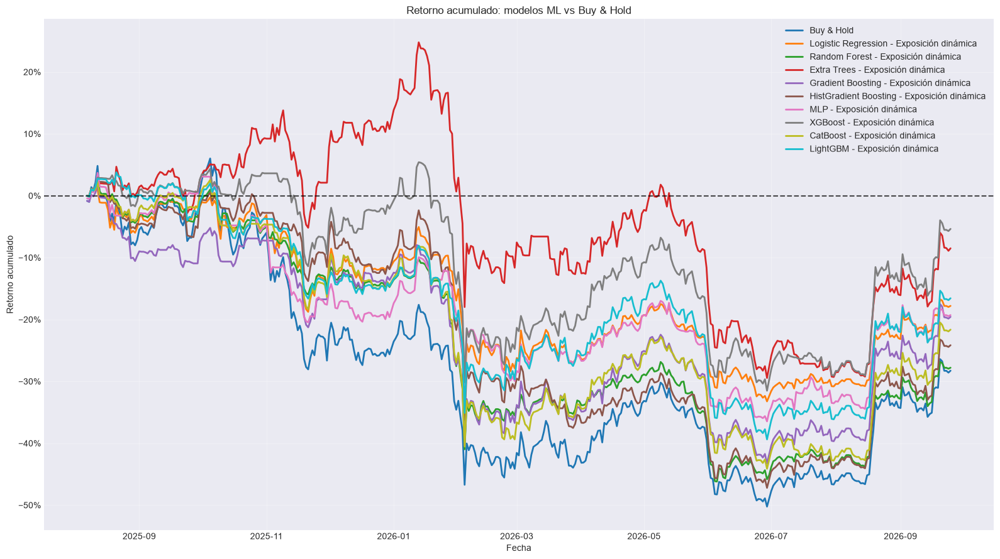

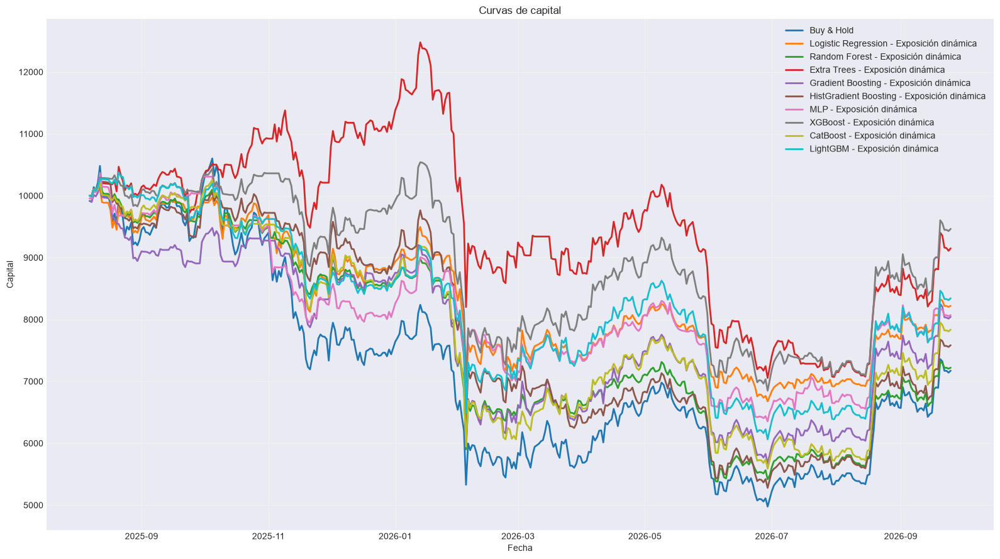

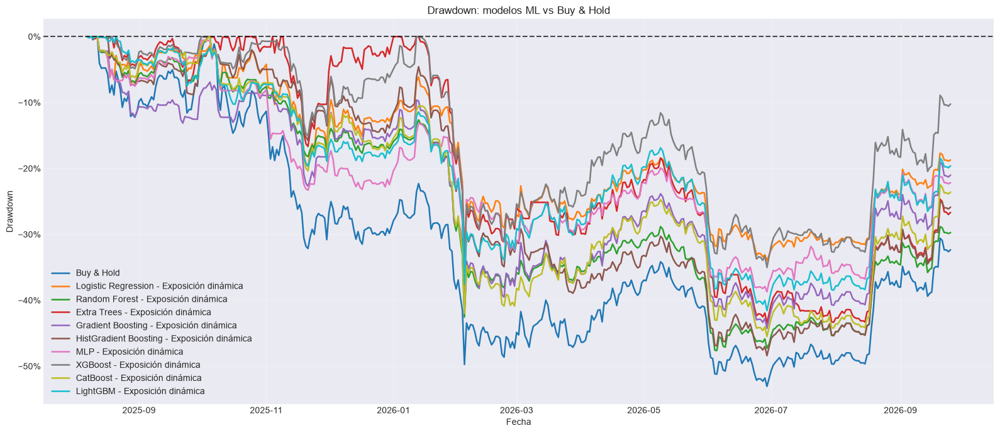


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,LightGBM,0.3482
1,Gradient Boosting,0.3443
2,XGBoost,0.3363
3,CatBoost,0.3346
4,HistGradient Boosting,0.3303
5,MLP,0.2936
6,Logistic Regression,0.2770
7,Random Forest,0.2767
8,Extra Trees,0.2470



COMPROBACIONES FINALES
X_dev: 1634
y_dev: 1634
t1_dev: 1634
X_test: 416
y_test: 416
t1_test: 416
test_prices: 416
forward_returns válidos: 415
Logistic Regression shape: (416,) | índice correcto: True
Random Forest shape: (416,) | índice correcto: True
Extra Trees shape: (416,) | índice correcto: True
Gradient Boosting shape: (416,) | índice correcto: True
HistGradient Boosting shape: (416,) | índice correcto: True
MLP shape: (416,) | índice correcto: True
XGBoost shape: (416,) | índice correcto: True
CatBoost shape: (416,) | índice correcto: True
LightGBM shape: (416,) | índice correcto: True

Pipeline terminado correctamente.


In [460]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2021-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-10-19 00:00:00

Optimizando Triple Barrier...


Best trial: 54. Best value: 0.870113: 100%|██████████| 80/80 [00:45<00:00,  1.76it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.576805871922983, 'sl_multiplier': 1.7302606631848583, 'max_holding_bars': 10, 'volatility_window': 10}
Score de balance walk-forward: 0.8701

Tamaño desarrollo: 1371
Tamaño test: 337

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,521,38.00%
1,Neutral,1,414,30.20%
2,Sube,2,436,31.80%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,148,43.92%
1,Neutral,1,95,28.19%
2,Sube,2,94,27.89%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4392
Balanced accuracy: 0.3333
F1 macro: 0.2034

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        10
Neutral    176
Sube       151
Name: count, dtype: int64
Exposición media: 70.92%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        56
Neutral     62
Sube       219
Name: count, dtype: int64
Exposición media: 74.18%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       134
Neutral     67
Sube       136
Name: count, dtype: int64
Exposición media: 50.30%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     82
Sube       230
Name: count, dtype: int64
Exposición media: 80.42%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        33
Neutral     94
Sube       210
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,456.10",-25.44%,-28.63%,45.02%,-0.4831,-0.6926,-48.84%,-0.5862,48.21%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$12,027.77",20.28%,20.16%,28.92%,0.8371,1.0196,-24.02%,0.8392,30.36%,50.45%,$434.50,30.00,37
2,CatBoost - Exposición dinámica,"$10,428.95",4.29%,3.77%,40.18%,0.3142,0.4147,-33.24%,0.1133,44.05%,78.42%,$355.40,25.00,37
3,XGBoost - Exposición dinámica,"$9,787.40",-2.13%,-3.17%,35.97%,0.1128,0.1624,-33.49%,-0.0946,41.37%,73.36%,$438.52,30.50,44
4,Random Forest - Exposición dinámica,"$9,398.67",-6.01%,-8.16%,37.71%,0.0105,0.0128,-36.47%,-0.2236,42.86%,74.11%,$480.79,35.00,53
5,HistGradient Boosting - Exposición dinámica,"$9,163.87",-8.36%,-9.87%,38.24%,-0.0564,-0.0730,-35.71%,-0.2764,43.15%,76.19%,$609.04,44.50,70
6,MLP - Exposición dinámica,"$9,091.81",-9.08%,-10.64%,36.63%,-0.1016,-0.1555,-38.23%,-0.2784,45.54%,79.91%,$504.72,37.00,58
7,Gradient Boosting - Exposición dinámica,"$8,877.92",-11.22%,-12.16%,39.19%,-0.1336,-0.1759,-35.27%,-0.3448,44.64%,80.36%,$421.52,32.00,53
8,LightGBM - Exposición dinámica,"$8,528.56",-14.71%,-16.66%,36.81%,-0.2879,-0.4334,-37.23%,-0.4475,41.96%,75.74%,$633.84,48.50,75
9,Logistic Regression - Exposición dinámica,"$7,548.99",-24.51%,-27.66%,31.51%,-0.8113,-1.0838,-44.81%,-0.6174,46.13%,70.98%,$291.87,24.50,47



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,20.28%,-25.44%,45.72%,0.8371,-0.4831,1.3202,-24.02%,-48.84%,24.82%,True,True,True
1,CatBoost - Exposición dinámica,4.29%,-25.44%,29.73%,0.3142,-0.4831,0.7973,-33.24%,-48.84%,15.61%,True,True,True
2,XGBoost - Exposición dinámica,-2.13%,-25.44%,23.31%,0.1128,-0.4831,0.5959,-33.49%,-48.84%,15.35%,True,True,True
3,Random Forest - Exposición dinámica,-6.01%,-25.44%,19.43%,0.0105,-0.4831,0.4936,-36.47%,-48.84%,12.38%,True,True,True
4,HistGradient Boosting - Exposición dinámica,-8.36%,-25.44%,17.08%,-0.0564,-0.4831,0.4267,-35.71%,-48.84%,13.14%,True,True,True
5,MLP - Exposición dinámica,-9.08%,-25.44%,16.36%,-0.1016,-0.4831,0.3815,-38.23%,-48.84%,10.62%,True,True,True
6,Gradient Boosting - Exposición dinámica,-11.22%,-25.44%,14.22%,-0.1336,-0.4831,0.3495,-35.27%,-48.84%,13.57%,True,True,True
7,LightGBM - Exposición dinámica,-14.71%,-25.44%,10.72%,-0.2879,-0.4831,0.1952,-37.23%,-48.84%,11.62%,True,True,True
8,Logistic Regression - Exposición dinámica,-24.51%,-25.44%,0.93%,-0.8113,-0.4831,-0.3282,-44.81%,-48.84%,4.04%,True,False,True


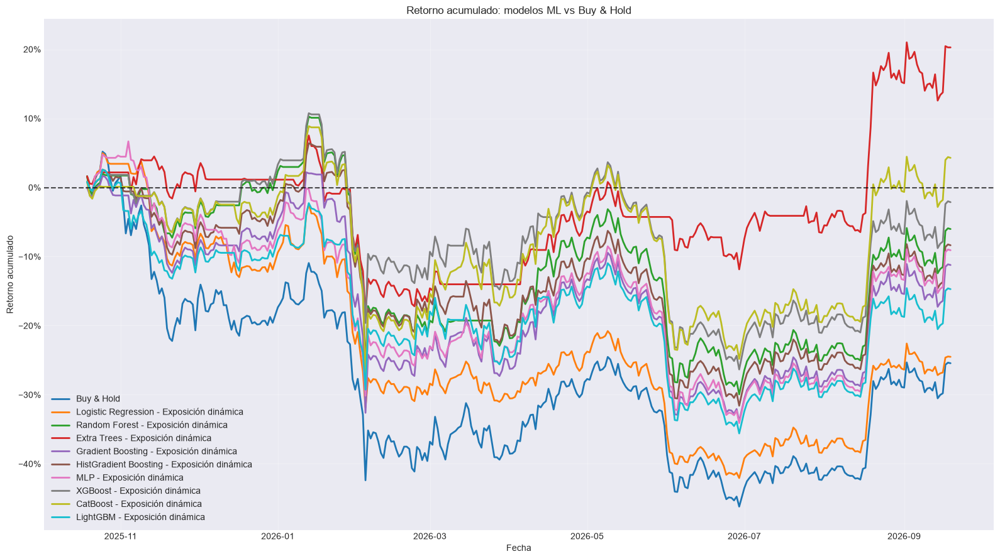

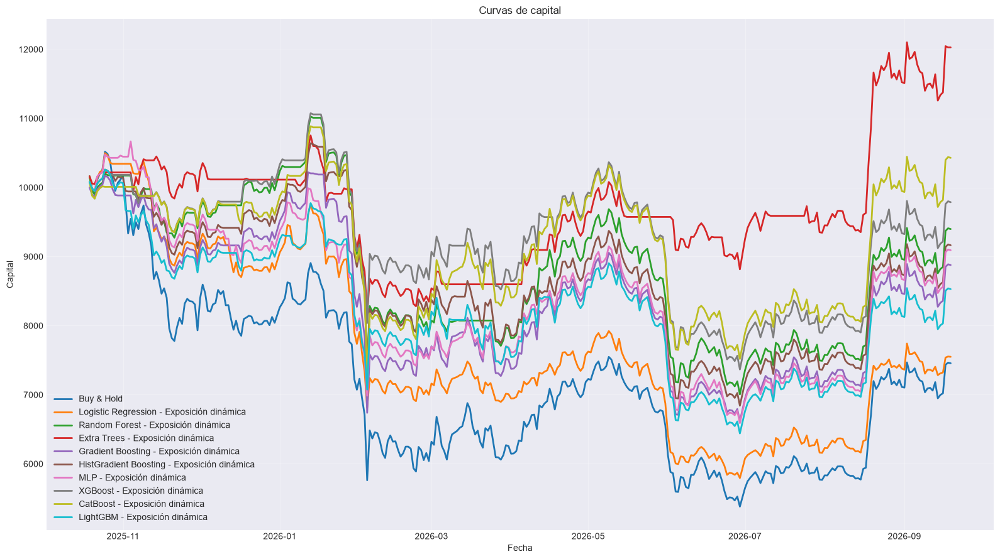

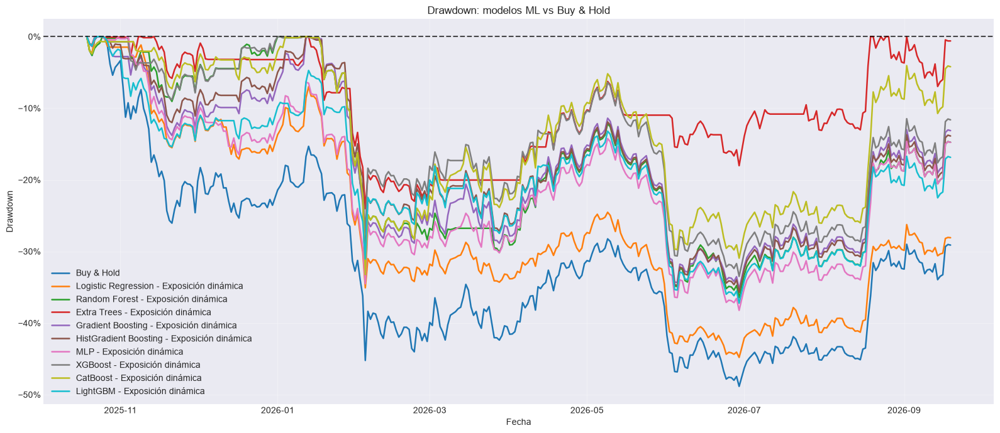


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,Logistic Regression,0.3583
1,MLP,0.3549
2,Gradient Boosting,0.3526
3,XGBoost,0.3332
4,LightGBM,0.3313
5,HistGradient Boosting,0.3247
6,Random Forest,0.3232
7,CatBoost,0.3149
8,Extra Trees,0.0000



COMPROBACIONES FINALES
X_dev: 1371
y_dev: 1371
t1_dev: 1371
X_test: 337
y_test: 337
t1_test: 337
test_prices: 337
forward_returns válidos: 336
Logistic Regression shape: (337,) | índice correcto: True
Random Forest shape: (337,) | índice correcto: True
Extra Trees shape: (337,) | índice correcto: True
Gradient Boosting shape: (337,) | índice correcto: True
HistGradient Boosting shape: (337,) | índice correcto: True
MLP shape: (337,) | índice correcto: True
XGBoost shape: (337,) | índice correcto: True
CatBoost shape: (337,) | índice correcto: True
LightGBM shape: (337,) | índice correcto: True

Pipeline terminado correctamente.


In [461]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 31
FEATURE_LAG: 1
Inicio del test: 2025-10-19 00:00:00

Optimizando Triple Barrier...


Best trial: 54. Best value: 0.870113: 100%|██████████| 80/80 [00:52<00:00,  1.52it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.576805871922983, 'sl_multiplier': 1.7302606631848583, 'max_holding_bars': 10, 'volatility_window': 10}
Score de balance walk-forward: 0.8701

Tamaño desarrollo: 1371
Tamaño test: 337

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,521,38.00%
1,Neutral,1,414,30.20%
2,Sube,2,436,31.80%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,148,43.92%
1,Neutral,1,95,28.19%
2,Sube,2,94,27.89%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4392
Balanced accuracy: 0.3333
F1 macro: 0.2034

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       165
Neutral     71
Sube       101
Name: count, dtype: int64
Exposición media: 40.50%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja       117
Neutral     59
Sube       161
Name: count, dtype: int64
Exposición media: 56.53%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       132
Neutral     82
Sube       123
Name: count, dtype: int64
Exposición media: 48.66%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       129
Neutral     72
Sube       136
Name: count, dtype: int64
Exposición media: 51.04%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       114
Neutral     81
Sube       142
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,456.10",-25.44%,-28.63%,45.02%,-0.4831,-0.6926,-48.84%,-0.5862,48.21%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$8,474.08",-15.26%,-17.95%,30.08%,-0.4477,-0.5121,-41.19%,-0.4358,28.27%,48.81%,$804.27,65.00,76
2,LightGBM - Exposición dinámica,"$7,830.38",-21.70%,-24.06%,30.94%,-0.7063,-0.9815,-35.95%,-0.6693,29.76%,55.06%,"$1,097.61",88.00,114
3,Logistic Regression - Exposición dinámica,"$7,692.60",-23.07%,-24.86%,33.19%,-0.6913,-0.7297,-44.44%,-0.5594,23.21%,40.62%,"$1,070.19",86.00,113
4,MLP - Exposición dinámica,"$6,973.94",-30.26%,-32.48%,27.13%,-1.3067,-1.5866,-33.18%,-0.9788,30.06%,46.73%,"$1,524.44",125.50,181
5,Gradient Boosting - Exposición dinámica,"$6,943.59",-30.56%,-33.38%,29.39%,-1.2009,-1.4627,-40.04%,-0.8337,27.38%,51.19%,"$1,255.78",107.00,129
6,HistGradient Boosting - Exposición dinámica,"$6,819.55",-31.80%,-34.68%,30.68%,-1.2031,-1.5739,-40.66%,-0.8528,28.87%,54.32%,$925.25,76.00,95
7,XGBoost - Exposición dinámica,"$6,155.34",-38.45%,-41.58%,29.84%,-1.6167,-2.0038,-50.25%,-0.8275,25.60%,52.08%,"$1,218.79",103.00,127
8,CatBoost - Exposición dinámica,"$6,155.09",-38.45%,-41.58%,31.68%,-1.5066,-1.9366,-49.34%,-0.8427,27.38%,53.12%,"$1,020.91",92.00,112
9,Random Forest - Exposición dinámica,"$6,121.48",-38.79%,-41.93%,32.55%,-1.4727,-1.6190,-41.76%,-1.0040,28.57%,56.70%,$759.52,64.00,80



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,-15.26%,-25.44%,10.18%,-0.4477,-0.4831,0.0354,-41.19%,-48.84%,7.65%,True,True,True
1,LightGBM - Exposición dinámica,-21.70%,-25.44%,3.74%,-0.7063,-0.4831,-0.2232,-35.95%,-48.84%,12.89%,True,False,True
2,Logistic Regression - Exposición dinámica,-23.07%,-25.44%,2.37%,-0.6913,-0.4831,-0.2082,-44.44%,-48.84%,4.40%,True,False,True
3,MLP - Exposición dinámica,-30.26%,-25.44%,-4.82%,-1.3067,-0.4831,-0.8236,-33.18%,-48.84%,15.66%,False,False,True
4,Gradient Boosting - Exposición dinámica,-30.56%,-25.44%,-5.13%,-1.2009,-0.4831,-0.7178,-40.04%,-48.84%,8.80%,False,False,True
5,HistGradient Boosting - Exposición dinámica,-31.80%,-25.44%,-6.37%,-1.2031,-0.4831,-0.7200,-40.66%,-48.84%,8.18%,False,False,True
6,XGBoost - Exposición dinámica,-38.45%,-25.44%,-13.01%,-1.6167,-0.4831,-1.1336,-50.25%,-48.84%,-1.40%,False,False,False
7,CatBoost - Exposición dinámica,-38.45%,-25.44%,-13.01%,-1.5066,-0.4831,-1.0235,-49.34%,-48.84%,-0.50%,False,False,False
8,Random Forest - Exposición dinámica,-38.79%,-25.44%,-13.35%,-1.4727,-0.4831,-0.9896,-41.76%,-48.84%,7.08%,False,False,True


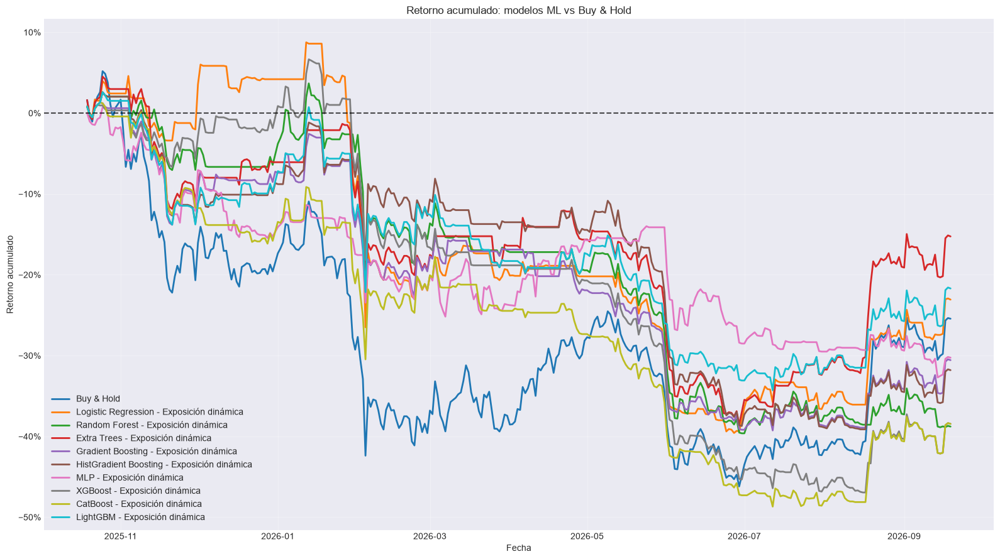

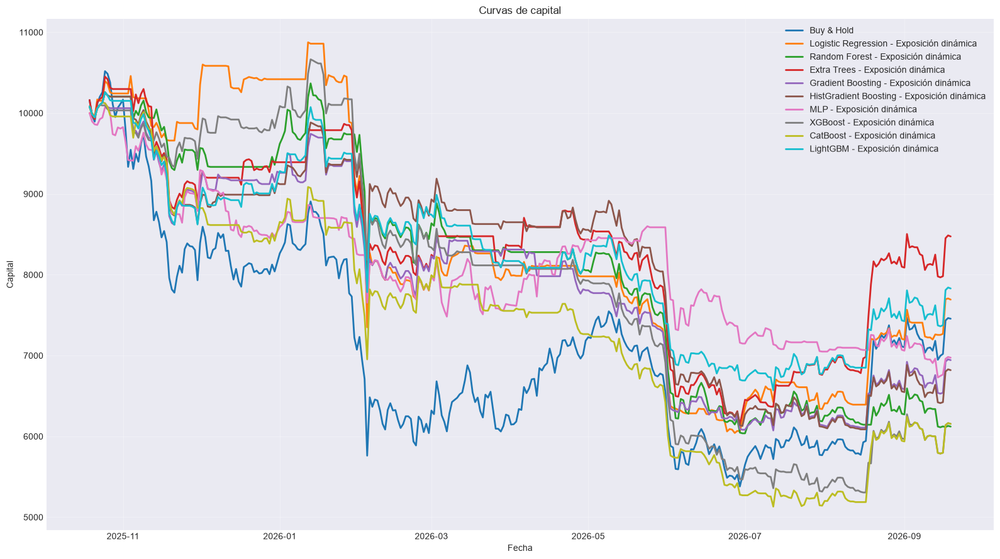

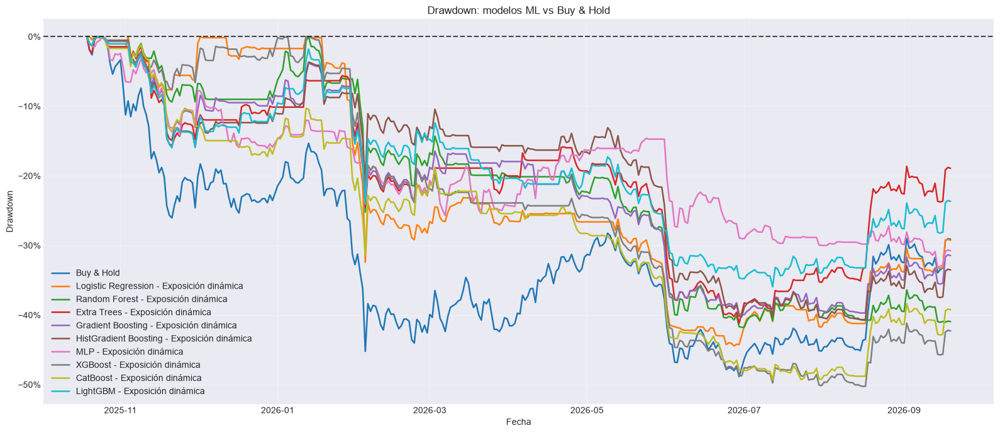


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3275
1,HistGradient Boosting,0.3092
2,Logistic Regression,0.2978
3,Extra Trees,0.2967
4,Random Forest,0.2959
5,Gradient Boosting,0.2944
6,LightGBM,0.2911
7,XGBoost,0.2910
8,CatBoost,0.2843



COMPROBACIONES FINALES
X_dev: 1371
y_dev: 1371
t1_dev: 1371
X_test: 337
y_test: 337
t1_test: 337
test_prices: 337
forward_returns válidos: 336
Logistic Regression shape: (337,) | índice correcto: True
Random Forest shape: (337,) | índice correcto: True
Extra Trees shape: (337,) | índice correcto: True
Gradient Boosting shape: (337,) | índice correcto: True
HistGradient Boosting shape: (337,) | índice correcto: True
MLP shape: (337,) | índice correcto: True
XGBoost shape: (337,) | índice correcto: True
CatBoost shape: (337,) | índice correcto: True
LightGBM shape: (337,) | índice correcto: True

Pipeline terminado correctamente.


In [467]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
     'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC'
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-10-19 00:00:00

Optimizando Triple Barrier...


Best trial: 54. Best value: 0.870113: 100%|██████████| 80/80 [00:39<00:00,  2.01it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.576805871922983, 'sl_multiplier': 1.7302606631848583, 'max_holding_bars': 10, 'volatility_window': 10}
Score de balance walk-forward: 0.8701

Tamaño desarrollo: 1371
Tamaño test: 337

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,521,38.00%
1,Neutral,1,414,30.20%
2,Sube,2,436,31.80%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,148,43.92%
1,Neutral,1,95,28.19%
2,Sube,2,94,27.89%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 0 Baja
Accuracy: 0.4392
Balanced accuracy: 0.3333
F1 macro: 0.2034

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        10
Neutral    181
Sube       146
Name: count, dtype: int64
Exposición media: 70.18%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        58
Neutral     55
Sube       224
Name: count, dtype: int64
Exposición media: 74.63%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        36
Neutral     77
Sube       224
Name: count, dtype: int64
Exposición media: 77.89%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        25
Neutral     81
Sube       231
Name: count, dtype: int64
Exposición media: 80.56%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        48
Neutral     76
Sube       213
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,456.10",-25.44%,-28.63%,45.02%,-0.4831,-0.6926,-48.84%,-0.5862,48.21%,100.00%,$15.00,1.00,1
1,XGBoost - Exposición dinámica,"$10,119.23",1.19%,-0.46%,38.88%,0.2278,0.2909,-34.53%,-0.0132,42.26%,74.11%,$592.87,40.00,55
2,CatBoost - Exposición dinámica,"$10,004.61",0.05%,-0.82%,39.45%,0.1987,0.2554,-35.39%,-0.0233,44.94%,77.98%,$424.60,29.50,44
3,MLP - Exposición dinámica,"$9,787.39",-2.13%,-3.17%,37.67%,0.1240,0.1864,-35.05%,-0.0904,44.94%,80.95%,$496.76,35.00,59
4,LightGBM - Exposición dinámica,"$9,668.23",-3.32%,-4.45%,36.55%,0.0801,0.1213,-31.19%,-0.1428,45.54%,79.46%,$377.11,28.00,47
5,Gradient Boosting - Exposición dinámica,"$9,544.60",-4.55%,-5.78%,40.15%,0.0746,0.1008,-33.33%,-0.1735,44.64%,80.51%,$429.84,32.00,50
6,Extra Trees - Exposición dinámica,"$9,061.73",-9.38%,-11.74%,35.10%,-0.1300,-0.1760,-41.96%,-0.2797,43.45%,77.83%,$212.51,16.00,22
7,Random Forest - Exposición dinámica,"$8,638.16",-13.62%,-16.22%,37.98%,-0.2281,-0.2780,-39.56%,-0.4101,41.37%,74.55%,$430.79,32.00,47
8,HistGradient Boosting - Exposición dinámica,"$8,604.25",-13.96%,-15.85%,38.99%,-0.2234,-0.2857,-39.20%,-0.4043,40.77%,74.40%,$630.09,46.50,67
9,Logistic Regression - Exposición dinámica,"$7,585.38",-24.15%,-27.28%,31.42%,-0.7982,-1.0673,-44.19%,-0.6174,45.83%,70.24%,$330.20,27.50,53



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,XGBoost - Exposición dinámica,1.19%,-25.44%,26.63%,0.2278,-0.4831,0.7109,-34.53%,-48.84%,14.32%,True,True,True
1,CatBoost - Exposición dinámica,0.05%,-25.44%,25.49%,0.1987,-0.4831,0.6818,-35.39%,-48.84%,13.45%,True,True,True
2,MLP - Exposición dinámica,-2.13%,-25.44%,23.31%,0.1240,-0.4831,0.6071,-35.05%,-48.84%,13.79%,True,True,True
3,LightGBM - Exposición dinámica,-3.32%,-25.44%,22.12%,0.0801,-0.4831,0.5632,-31.19%,-48.84%,17.66%,True,True,True
4,Gradient Boosting - Exposición dinámica,-4.55%,-25.44%,20.88%,0.0746,-0.4831,0.5577,-33.33%,-48.84%,15.52%,True,True,True
5,Extra Trees - Exposición dinámica,-9.38%,-25.44%,16.06%,-0.1300,-0.4831,0.3531,-41.96%,-48.84%,6.88%,True,True,True
6,Random Forest - Exposición dinámica,-13.62%,-25.44%,11.82%,-0.2281,-0.4831,0.2550,-39.56%,-48.84%,9.28%,True,True,True
7,HistGradient Boosting - Exposición dinámica,-13.96%,-25.44%,11.48%,-0.2234,-0.4831,0.2597,-39.20%,-48.84%,9.64%,True,True,True
8,Logistic Regression - Exposición dinámica,-24.15%,-25.44%,1.29%,-0.7982,-0.4831,-0.3151,-44.19%,-48.84%,4.65%,True,False,True


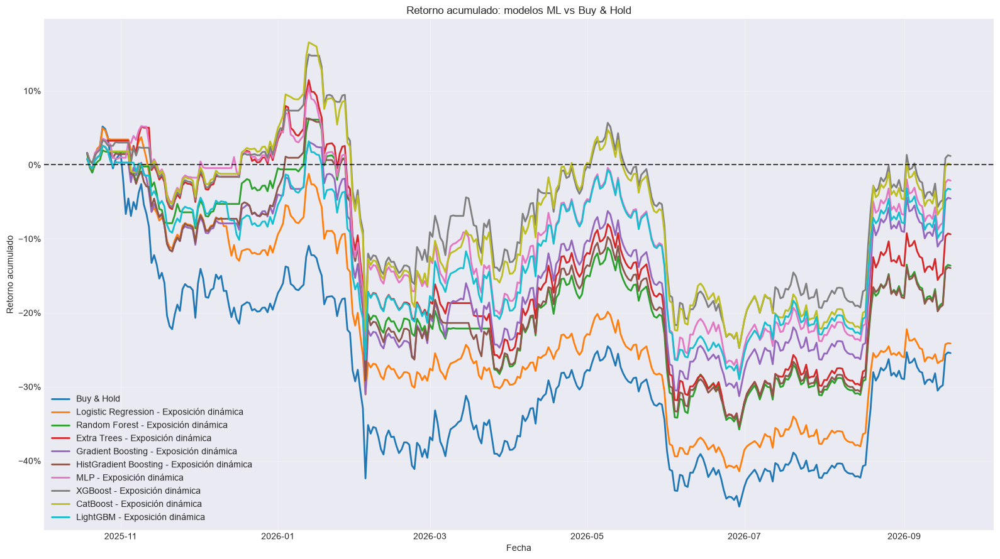

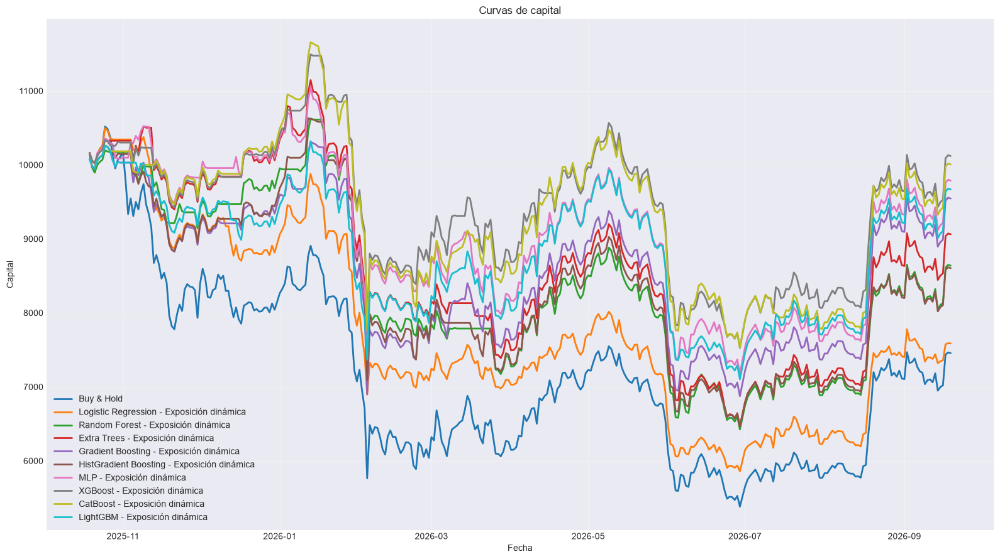

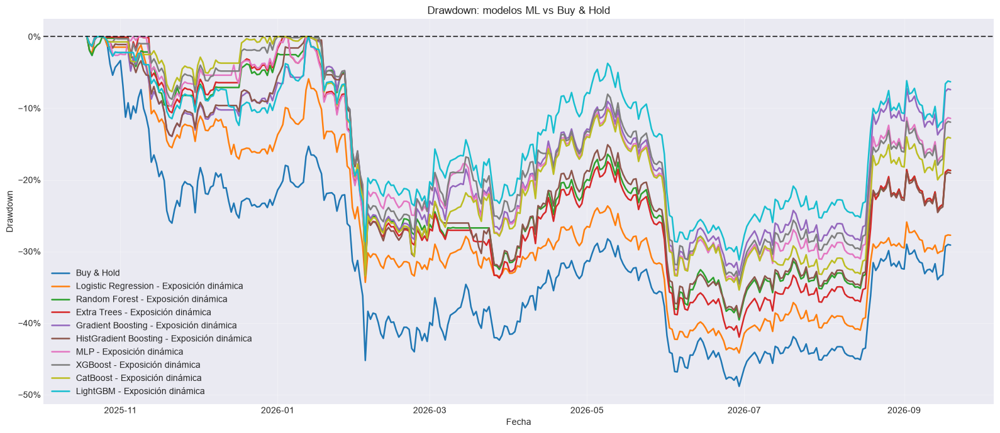


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3810
1,Gradient Boosting,0.3639
2,Logistic Regression,0.3622
3,LightGBM,0.3519
4,XGBoost,0.3517
5,HistGradient Boosting,0.3447
6,CatBoost,0.3387
7,Random Forest,0.3294
8,Extra Trees,0.2992



COMPROBACIONES FINALES
X_dev: 1371
y_dev: 1371
t1_dev: 1371
X_test: 337
y_test: 337
t1_test: 337
test_prices: 337
forward_returns válidos: 336
Logistic Regression shape: (337,) | índice correcto: True
Random Forest shape: (337,) | índice correcto: True
Extra Trees shape: (337,) | índice correcto: True
Gradient Boosting shape: (337,) | índice correcto: True
HistGradient Boosting shape: (337,) | índice correcto: True
MLP shape: (337,) | índice correcto: True
XGBoost shape: (337,) | índice correcto: True
CatBoost shape: (337,) | índice correcto: True
LightGBM shape: (337,) | índice correcto: True

Pipeline terminado correctamente.


In [464]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 200

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1369, 73)
Primer registro: 2023-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-31 00:00:00

Optimizando Triple Barrier...


Best trial: 47. Best value: 0.874488: 100%|██████████| 80/80 [00:33<00:00,  2.41it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.149855537085901, 'sl_multiplier': 1.4069637054649395, 'max_holding_bars': 7, 'volatility_window': 40}
Score de balance walk-forward: 0.8745

Tamaño desarrollo: 1047
Tamaño test: 267

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,370,35.34%
1,Neutral,1,381,36.39%
2,Sube,2,296,28.27%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,99,37.08%
1,Neutral,1,106,39.70%
2,Sube,2,62,23.22%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 1 Neutral
Accuracy: 0.397
Balanced accuracy: 0.3333
F1 macro: 0.1895

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        34
Neutral    147
Sube        86
Name: count, dtype: int64
Exposición media: 59.74%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        39
Neutral     81
Sube       147
Name: count, dtype: int64
Exposición media: 70.22%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       84
Neutral    93
Sube       90
Name: count, dtype: int64
Exposición media: 51.12%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        23
Neutral     83
Sube       161
Name: count, dtype: int64
Exposición media: 75.84%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        40
Neutral    115
Sube       112
Name: count, dtype: int64
Exposición me

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$9,628.53",-3.71%,-6.69%,46.85%,0.1228,0.1768,-39.59%,-0.1689,48.50%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$10,827.91",8.28%,10.63%,29.84%,0.5116,0.6989,-22.08%,0.4813,33.83%,51.13%,$308.49,22.50,35
2,Gradient Boosting - Exposición dinámica,"$10,823.40",8.23%,10.56%,40.97%,0.4690,0.6576,-30.65%,0.3446,44.36%,75.75%,$587.74,42.00,72
3,Logistic Regression - Exposición dinámica,"$10,022.30",0.22%,0.31%,37.64%,0.1963,0.2447,-31.73%,0.0097,42.48%,59.96%,$432.01,32.50,52
4,XGBoost - Exposición dinámica,"$9,929.97",-0.70%,-2.64%,34.53%,0.1451,0.1805,-28.36%,-0.0931,39.47%,58.83%,$687.46,49.00,87
5,LightGBM - Exposición dinámica,"$9,884.52",-1.15%,-2.43%,36.21%,0.1370,0.1715,-31.77%,-0.0764,38.35%,61.28%,$645.30,47.00,84
6,MLP - Exposición dinámica,"$9,734.39",-2.66%,-3.64%,37.35%,0.0882,0.1081,-34.30%,-0.1061,40.98%,62.03%,$551.74,44.00,69
7,Random Forest - Exposición dinámica,"$9,723.30",-2.77%,-5.42%,38.43%,0.0921,0.1170,-33.61%,-0.1613,40.98%,70.49%,$485.27,37.00,57
8,HistGradient Boosting - Exposición dinámica,"$9,336.57",-6.63%,-9.80%,35.79%,-0.0840,-0.1068,-32.00%,-0.3062,40.23%,63.72%,$628.12,48.00,82
9,CatBoost - Exposición dinámica,"$8,349.77",-16.50%,-22.00%,34.14%,-0.5530,-0.6166,-31.65%,-0.6949,33.08%,51.88%,$615.16,48.00,80



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,8.28%,-3.71%,11.99%,0.5116,0.1228,0.3888,-22.08%,-39.59%,17.51%,True,True,True
1,Gradient Boosting - Exposición dinámica,8.23%,-3.71%,11.95%,0.4690,0.1228,0.3462,-30.65%,-39.59%,8.93%,True,True,True
2,Logistic Regression - Exposición dinámica,0.22%,-3.71%,3.94%,0.1963,0.1228,0.0735,-31.73%,-39.59%,7.86%,True,True,True
3,XGBoost - Exposición dinámica,-0.70%,-3.71%,3.01%,0.1451,0.1228,0.0223,-28.36%,-39.59%,11.22%,True,True,True
4,LightGBM - Exposición dinámica,-1.15%,-3.71%,2.56%,0.1370,0.1228,0.0142,-31.77%,-39.59%,7.82%,True,True,True
5,MLP - Exposición dinámica,-2.66%,-3.71%,1.06%,0.0882,0.1228,-0.0346,-34.30%,-39.59%,5.29%,True,False,True
6,Random Forest - Exposición dinámica,-2.77%,-3.71%,0.95%,0.0921,0.1228,-0.0307,-33.61%,-39.59%,5.97%,True,False,True
7,HistGradient Boosting - Exposición dinámica,-6.63%,-3.71%,-2.92%,-0.0840,0.1228,-0.2067,-32.00%,-39.59%,7.59%,False,False,True
8,CatBoost - Exposición dinámica,-16.50%,-3.71%,-12.79%,-0.5530,0.1228,-0.6758,-31.65%,-39.59%,7.93%,False,False,True


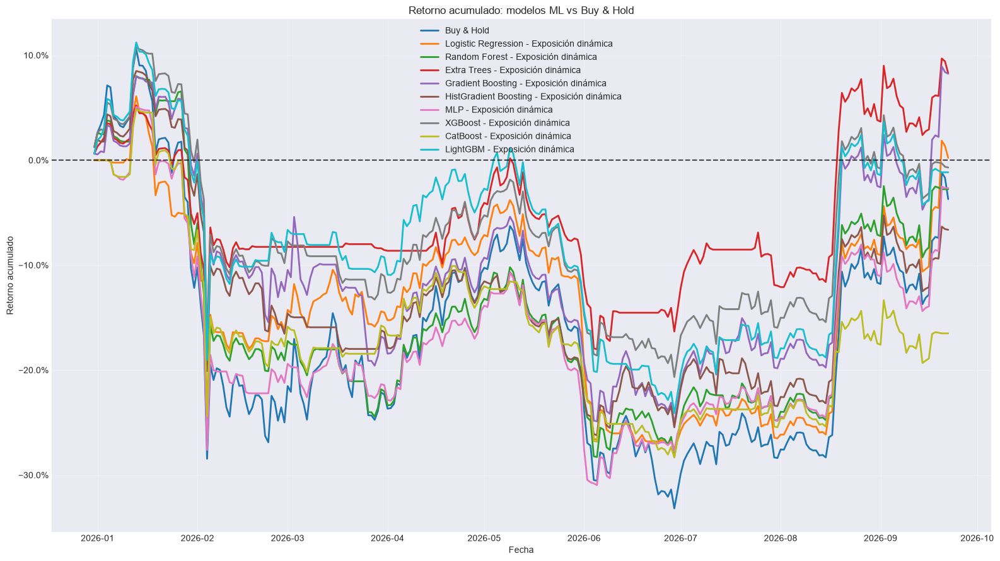

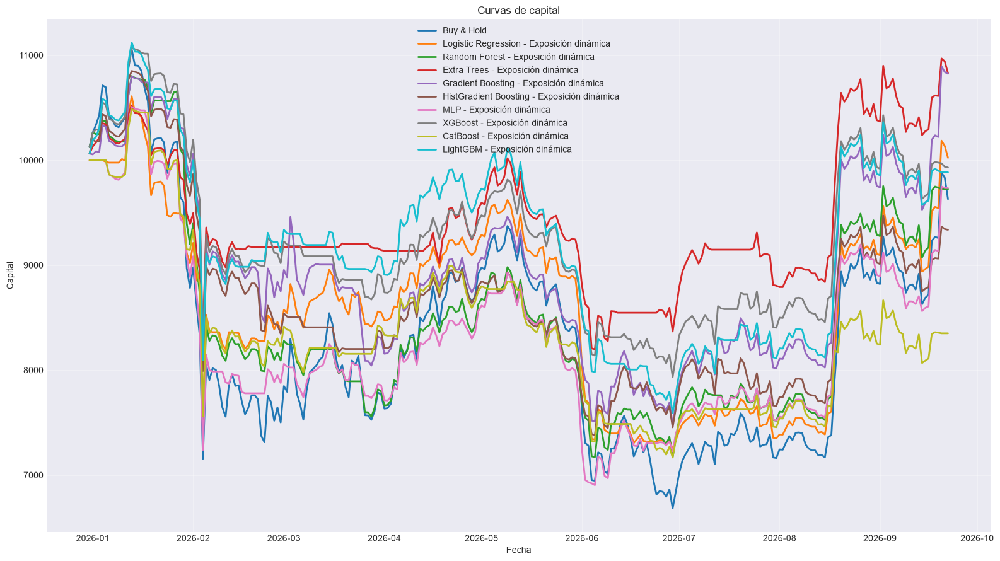

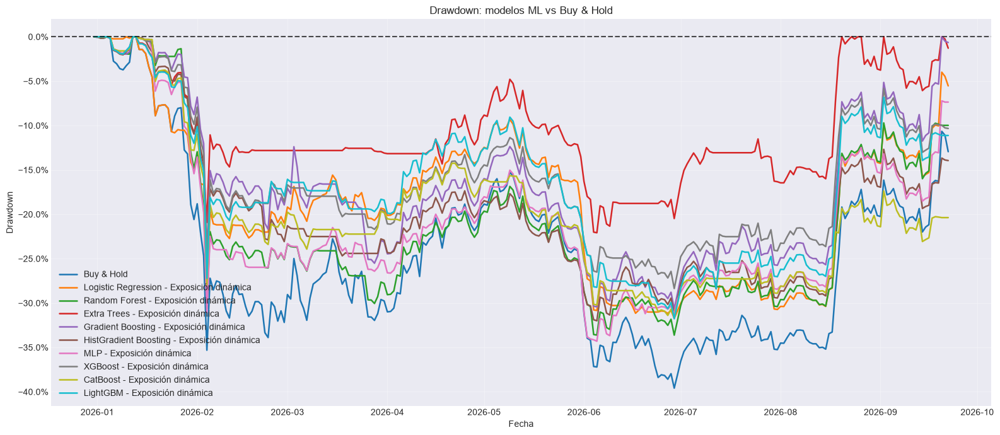


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,Gradient Boosting,0.3379
1,CatBoost,0.3361
2,LightGBM,0.3323
3,XGBoost,0.3318
4,Logistic Regression,0.3311
5,HistGradient Boosting,0.3306
6,MLP,0.3069
7,Random Forest,0.2831
8,Extra Trees,0.2784



COMPROBACIONES FINALES
X_dev: 1047
y_dev: 1047
t1_dev: 1047
X_test: 267
y_test: 267
t1_test: 267
test_prices: 267
forward_returns válidos: 266
Logistic Regression shape: (267,) | índice correcto: True
Random Forest shape: (267,) | índice correcto: True
Extra Trees shape: (267,) | índice correcto: True
Gradient Boosting shape: (267,) | índice correcto: True
HistGradient Boosting shape: (267,) | índice correcto: True
MLP shape: (267,) | índice correcto: True
XGBoost shape: (267,) | índice correcto: True
CatBoost shape: (267,) | índice correcto: True
LightGBM shape: (267,) | índice correcto: True

Pipeline terminado correctamente.


In [463]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2023-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1369, 73)
Primer registro: 2023-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-31 00:00:00

Optimizando Triple Barrier...


Best trial: 47. Best value: 0.874488: 100%|██████████| 80/80 [00:30<00:00,  2.66it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.149855537085901, 'sl_multiplier': 1.4069637054649395, 'max_holding_bars': 7, 'volatility_window': 40}
Score de balance walk-forward: 0.8745

Tamaño desarrollo: 1047
Tamaño test: 267

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,370,35.34%
1,Neutral,1,381,36.39%
2,Sube,2,296,28.27%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,99,37.08%
1,Neutral,1,106,39.70%
2,Sube,2,62,23.22%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 1 Neutral
Accuracy: 0.397
Balanced accuracy: 0.3333
F1 macro: 0.1895

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja        34
Neutral    147
Sube        86
Name: count, dtype: int64
Exposición media: 59.74%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        39
Neutral     81
Sube       147
Name: count, dtype: int64
Exposición media: 70.22%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       84
Neutral    93
Sube       90
Name: count, dtype: int64
Exposición media: 51.12%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        23
Neutral     83
Sube       161
Name: count, dtype: int64
Exposición media: 75.84%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        40
Neutral    115
Sube       112
Name: count, dtype: int64
Exposición me

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$9,628.53",-3.71%,-6.69%,46.85%,0.1228,0.1768,-39.59%,-0.1689,48.50%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$10,827.91",8.28%,10.63%,29.84%,0.5116,0.6989,-22.08%,0.4813,33.83%,51.13%,$308.49,22.50,35
2,Gradient Boosting - Exposición dinámica,"$10,823.40",8.23%,10.56%,40.97%,0.4690,0.6576,-30.65%,0.3446,44.36%,75.75%,$587.74,42.00,72
3,Logistic Regression - Exposición dinámica,"$10,022.30",0.22%,0.31%,37.64%,0.1963,0.2447,-31.73%,0.0097,42.48%,59.96%,$432.01,32.50,52
4,XGBoost - Exposición dinámica,"$9,929.97",-0.70%,-2.64%,34.53%,0.1451,0.1805,-28.36%,-0.0931,39.47%,58.83%,$687.46,49.00,87
5,LightGBM - Exposición dinámica,"$9,884.52",-1.15%,-2.43%,36.21%,0.1370,0.1715,-31.77%,-0.0764,38.35%,61.28%,$645.30,47.00,84
6,MLP - Exposición dinámica,"$9,734.39",-2.66%,-3.64%,37.35%,0.0882,0.1081,-34.30%,-0.1061,40.98%,62.03%,$551.74,44.00,69
7,Random Forest - Exposición dinámica,"$9,723.30",-2.77%,-5.42%,38.43%,0.0921,0.1170,-33.61%,-0.1613,40.98%,70.49%,$485.27,37.00,57
8,HistGradient Boosting - Exposición dinámica,"$9,336.57",-6.63%,-9.80%,35.79%,-0.0840,-0.1068,-32.00%,-0.3062,40.23%,63.72%,$628.12,48.00,82
9,CatBoost - Exposición dinámica,"$8,349.77",-16.50%,-22.00%,34.14%,-0.5530,-0.6166,-31.65%,-0.6949,33.08%,51.88%,$615.16,48.00,80



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,8.28%,-3.71%,11.99%,0.5116,0.1228,0.3888,-22.08%,-39.59%,17.51%,True,True,True
1,Gradient Boosting - Exposición dinámica,8.23%,-3.71%,11.95%,0.4690,0.1228,0.3462,-30.65%,-39.59%,8.93%,True,True,True
2,Logistic Regression - Exposición dinámica,0.22%,-3.71%,3.94%,0.1963,0.1228,0.0735,-31.73%,-39.59%,7.86%,True,True,True
3,XGBoost - Exposición dinámica,-0.70%,-3.71%,3.01%,0.1451,0.1228,0.0223,-28.36%,-39.59%,11.22%,True,True,True
4,LightGBM - Exposición dinámica,-1.15%,-3.71%,2.56%,0.1370,0.1228,0.0142,-31.77%,-39.59%,7.82%,True,True,True
5,MLP - Exposición dinámica,-2.66%,-3.71%,1.06%,0.0882,0.1228,-0.0346,-34.30%,-39.59%,5.29%,True,False,True
6,Random Forest - Exposición dinámica,-2.77%,-3.71%,0.95%,0.0921,0.1228,-0.0307,-33.61%,-39.59%,5.97%,True,False,True
7,HistGradient Boosting - Exposición dinámica,-6.63%,-3.71%,-2.92%,-0.0840,0.1228,-0.2067,-32.00%,-39.59%,7.59%,False,False,True
8,CatBoost - Exposición dinámica,-16.50%,-3.71%,-12.79%,-0.5530,0.1228,-0.6758,-31.65%,-39.59%,7.93%,False,False,True


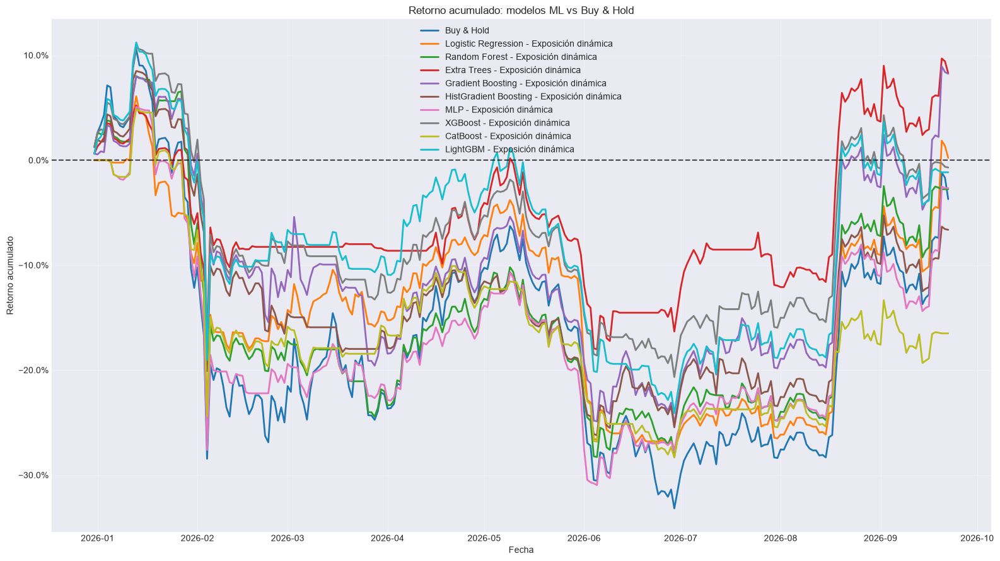

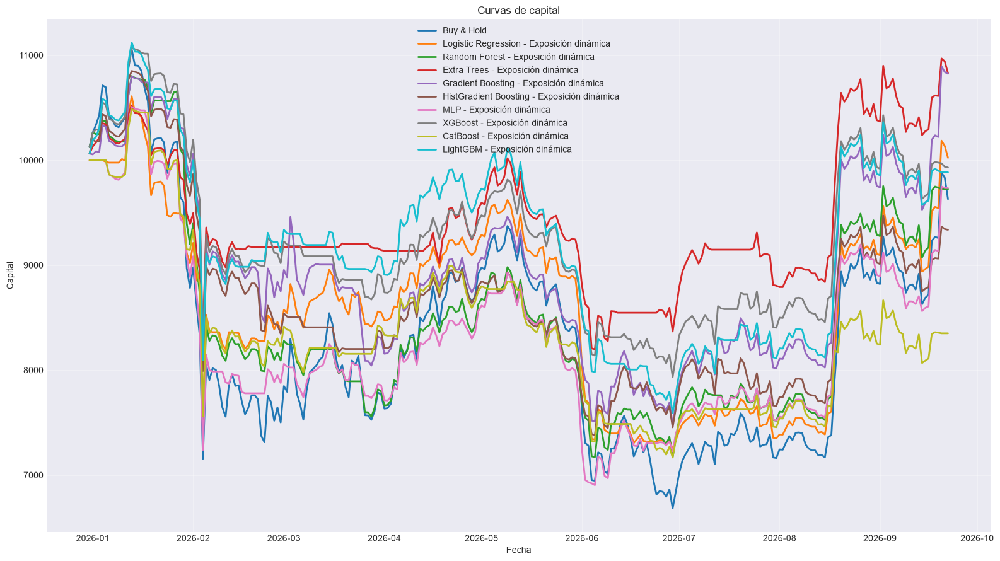

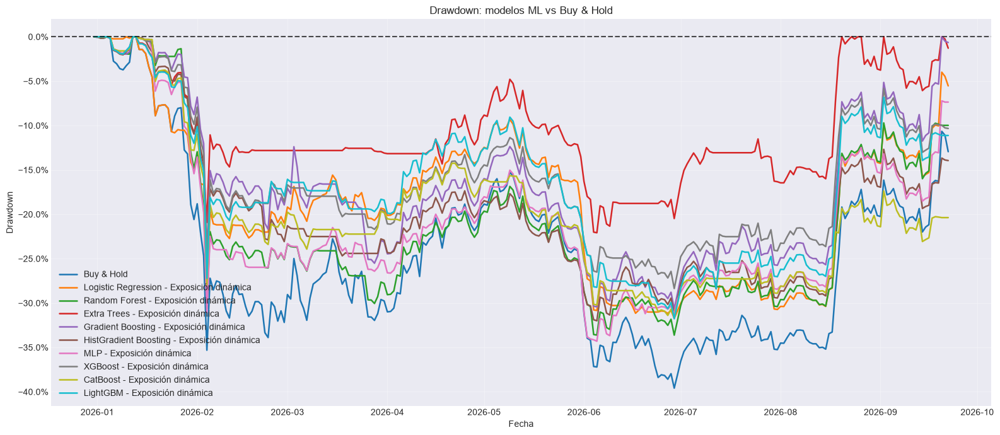


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,Gradient Boosting,0.3379
1,CatBoost,0.3361
2,LightGBM,0.3323
3,XGBoost,0.3318
4,Logistic Regression,0.3311
5,HistGradient Boosting,0.3306
6,MLP,0.3069
7,Random Forest,0.2831
8,Extra Trees,0.2784



COMPROBACIONES FINALES
X_dev: 1047
y_dev: 1047
t1_dev: 1047
X_test: 267
y_test: 267
t1_test: 267
test_prices: 267
forward_returns válidos: 266
Logistic Regression shape: (267,) | índice correcto: True
Random Forest shape: (267,) | índice correcto: True
Extra Trees shape: (267,) | índice correcto: True
Gradient Boosting shape: (267,) | índice correcto: True
HistGradient Boosting shape: (267,) | índice correcto: True
MLP shape: (267,) | índice correcto: True
XGBoost shape: (267,) | índice correcto: True
CatBoost shape: (267,) | índice correcto: True
LightGBM shape: (267,) | índice correcto: True

Pipeline terminado correctamente.


In [462]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2023-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

In [465]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 200

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2023-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1369, 73)
Primer registro: 2023-01-01 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-12-31 00:00:00

Optimizando Triple Barrier...


Best trial: 47. Best value: 0.874488: 100%|██████████| 80/80 [00:28<00:00,  2.82it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.149855537085901, 'sl_multiplier': 1.4069637054649395, 'max_holding_bars': 7, 'volatility_window': 40}
Score de balance walk-forward: 0.8745

Tamaño desarrollo: 1047
Tamaño test: 267

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,370,35.34%
1,Neutral,1,381,36.39%
2,Sube,2,296,28.27%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,99,37.08%
1,Neutral,1,106,39.70%
2,Sube,2,62,23.22%


... (16 outputs left out)


Optimizando modelo: CatBoost


Best trial: 23. Best value: 0.338713:  12%|█▎        | 25/200 [53:39<6:15:38, 128.79s/it] 


[W 2026-10-29 14:03:19,460] Trial 25 failed with parameters: {'iterations': 400, 'depth': 10, 'learning_rate': 0.14406288601994255, 'l2_leaf_reg': 0.0781212269353205, 'random_strength': 9.643375143466769e-08, 'border_count': 173, 'auto_class_weights': 'Balanced'} because of the following error: KeyboardInterrupt('').
Traceback (most recent call last):
  File "c:\Users\reyes\anaconda3\envs\tf_finance\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\reyes\AppData\Local\Temp\ipykernel_38652\1786181167.py", line 2332, in objective_model
    return evaluar_cv_modelo(
           ^^^^^^^^^^^^^^^^^^
  File "C:\Users\reyes\AppData\Local\Temp\ipykernel_38652\1786181167.py", line 2219, in evaluar_cv_modelo
    model_fold.fit(
  File "c:\Users\reyes\anaconda3\envs\tf_finance\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^

KeyboardInterrupt: 

In [466]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
# 
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01":].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC'
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (1734, 73)
Primer registro: 2022-01-01 00:00:00
Último registro: 2026-09-30 00:00:00


ValueError: Faltan estas features:
['Bitcoin_log_ret_7', 'Bitcoin_log_ret_14', 'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14', 'Cardano_log_ret_7', 'Cardano_log_ret_14', 'Bitcoin_Cash_log_ret_7', 'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret_7', 'Ethereum_log_ret_14', 'Chainlink_log_ret_7', 'Chainlink_log_ret_14', 'Litecoin_log_ret_7', 'Litecoin_log_ret_14']

In [392]:
df_bitcoin.corr()*100

Ticker,Bitcoin_log_ret,Petroleo_WTI_log_ret,Yuan_Chino_log_ret,Indice_Dolar_DXY_log_ret,Euro_log_ret,Oro_log_ret,Gas_Natural_log_ret,S&P_500_log_ret,NASDAQ_Tecnologico_log_ret,Nikkei_Asia_log_ret,Cardano_log_ret,Bitcoin_Cash_log_ret,Ethereum_log_ret,Chainlink_log_ret,Litecoin_log_ret,Bono_EEUU_5A_diff,Bono_EEUU_3M_diff,Bono_EEUU_10A_diff,Indice_Volatilidad_VIX_diff,BTC_Volume_diff,BTC_Close,SMA,EMA,WMA,TRIMA,KAMA,MAMA,FAMA,T3,DEMA,TEMA,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,ULTOSC,TRIX,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Bitcoin_log_ret,100.000000,5.074144,-1.543914,-15.494740,0.969553,9.411322,2.506178,34.956561,36.967440,1.379924,67.385530,69.259459,81.470007,67.213412,72.462522,-3.127577,-3.552252,-1.446902,-31.677125,-2.235480,-0.388393,-4.861921,-4.762246,-4.652148,-4.982329,-4.577103,-4.071507,-4.890719,-4.804975,-4.225806,-3.913018,7.918548,3.424609,16.849231,3.526824,1.480830,4.740369,25.024418,10.284795,59.175638,25.024418,35.090786,58.735585,26.147250,43.061762,2.237667,0.909772,3.526824,5.084152,28.766882,84.172241,38.136751,35.090786,32.537239,32.537239,-11.142897,11.051500,12.742616,17.411489,34.612293,4.636109,-4.569796,-4.730156,-4.870207,-4.008928,-4.082491,-5.834984,-5.668893,-4.846110,-8.959861,-4.011491,26.328501,2.359409
Petroleo_WTI_log_ret,5.074144,100.000000,1.099768,-0.632054,-5.901526,5.146606,7.760136,8.352930,5.059176,0.352743,5.852538,3.535541,4.883492,2.853893,3.646638,15.002036,0.698297,16.461591,-10.166826,-2.492669,-3.208706,-3.453896,-3.406760,-3.403879,-3.429495,-3.331288,-3.277449,-3.380916,-3.422148,-3.390144,-3.313852,0.584755,0.122846,1.690410,0.316355,0.670426,-0.723768,3.582722,3.701471,3.422428,3.582722,3.373141,1.527045,1.468847,4.487666,1.056166,1.251684,0.316355,2.020447,1.326522,3.194861,5.024047,3.373141,4.376357,4.376357,-3.424633,1.033977,2.543224,3.234808,3.408908,2.098909,-3.480103,-3.392828,-3.265874,-3.396687,-3.405764,-3.347952,-4.036988,-2.061934,2.028729,-5.649629,3.575804,-3.454004
Yuan_Chino_log_ret,-1.543914,1.099768,100.000000,-1.944150,28.433360,1.702642,2.430298,-0.417834,-0.872032,1.961607,-0.271762,0.551087,-0.390230,-0.592220,0.231352,-1.523426,-9.692977,-0.409686,2.067931,1.791499,0.800098,0.710742,0.725222,0.703689,0.692396,0.715104,0.746607,0.720269,0.668238,0.680391,0.709774,0.072993,-0.273928,1.203378,0.115938,-0.235312,0.762792,6.211111,5.030723,3.864950,6.211111,3.494602,2.390314,5.239843,5.781533,3.697847,3.132402,0.115938,1.157357,0.558551,-1.745300,7.518023,3.494602,2.018211,2.018211,-5.795213,3.131852,5.106946,3.144730,4.490161,1.081108,0.794197,0.701180,0.590655,0.684656,0.702205,0.487813,0.179110,0.421517,-0.755685,-0.831463,3.297259,-1.324604
Indice_Dolar_DXY_log_ret,-15.494740,-0.632054,-1.944150,100.000000,-8.299227,-38.370614,-1.934068,-24.410044,-22.443864,-4.742825,-14.160504,-11.992107,-14.584760,-11.708449,-13.152939,39.418592,13.591278,32.980655,13.599231,4.670154,0.582714,0.721981,0.725739,0.767276,0.665022,0.630992,0.894871,0.779090,0.776634,0.888109,0.936695,1.670693,1.714048,0.153377,1.665960,0.577466,2.500011,-5.286134,-1.221936,-13.995832,-5.286134,-5.464228,-14.341868,-5.875353,-9.661966,-0.573647,1.224232,1.665960,-0.037308,-0.573521,-16.306449,-6.966740,-5.464228,-3.695416,-3.695416,0.101067,-0.487079,-0.340398,-2.151044,-7.471459,-0.601781,0.755800,0.737113,0.709841,0.870314,0.945704,1.107430,1.770712,1.044343,2.717467,1.860568,-2.994407,1.683994
Euro_log_ret,0.969553,-5.901526,28.433360,-8.299227,100.000000,6.521835,0.686243,-1.174576,-0.801499,13.773659,-1.165103,0.740393,-0.496500,-1.241644,-1.319283,-4.854676,-5.473074,-3.745258,2.765272,-0.216471,-0.224966,-0.362551,-0.384427,-0.426114,-0.313206,-0.285084,-0.555741,-0.451

In [ ]:
["Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff", "MACD_Hist",
 "STOCH_SlowK", "STOCH_SlowD", "STOCHF_FastK", "RSI", "STOCHRSI_FastK", "STOCHRSI_FastD", "WILLR", "MOM", "BOP", "CMO", "ROC",   "AROON_Down", "AROON_Up",  "AROONOSC",   "ULTOSC", "MFI"  ]

In [364]:
df_bitcoin.drop(columns  =  ["Bono_EEUU_10A_diff", "ADXR", "ADX", "Euro_log_ret", "Gas_Natural_log_ret", "BB_Middle", "MIDPOINT",
                                  "Gas_Natural_log_ret", "MIDPRICE", "MACDEXT_Signal", "ADX", "ROCR", "CMO", "APO", "AD", "OBV", "TRANGE",
                                  "Bono_EEUU_5A_diff", "TEMA", "Bono_EEUU_3M_diff", "MAMA", "Petroleo_WTI_log_ret_7", "Petroleo_WTI_log_ret_14",
                                  "S&P_500_log_ret_7", "Nikkei_Asia_log_ret_7", "MACD_Signal", "MACDEXT", "ATR", "Euro_log_ret_7", "Nikkei_Asia_log_ret_14",
                                  "KAMA", "MACDEXT_Hist", "Yuan_Chino_log_ret_14", "Oro_log_ret_14", "Gas_Natural_log_ret_14", "DEMA", "Euro_log_ret_14",
                                  "Gas_Natural_log_ret_7", "T3", "TRIX", "Petroleo_WTI_log_ret", "Yuan_Chino_log_ret", "Yuan_Chino_log_ret_7", "Indice_Dolar_DXY_log_ret_14",
                                  "Oro_log_ret_7", "Nikkei_Asia_log_ret", "FAMA", "TRIMA", "SMA", "WMA", "PPO", "BTC_Close", "BB_Lower", "SAR", "MOM",
                                  "Indice_Dolar_DXY_log_ret_7", "STOCH_SlowK", "BB_Upper"]).columns

Index(['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC'],
      dtype='str', name='Ticker')

In [ ]:
pd.set_

In [389]:
df_bitcoin.columns

Index(['Bitcoin_log_ret', 'Petroleo_WTI_log_ret', 'Yuan_Chino_log_ret',
       'Indice_Dolar_DXY_log_ret', 'Euro_log_ret', 'Oro_log_ret',
       'Gas_Natural_log_ret', 'S&P_500_log_ret', 'NASDAQ_Tecnologico_log_ret',
       'Nikkei_Asia_log_ret', 'Cardano_log_ret', 'Bitcoin_Cash_log_ret',
       'Ethereum_log_ret', 'Chainlink_log_ret', 'Litecoin_log_ret',
       'Bono_EEUU_5A_diff', 'Bono_EEUU_3M_diff', 'Bono_EEUU_10A_diff',
       'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff', 'BTC_Close', 'SMA',
       'EMA', 'WMA', 'TRIMA', 'KAMA', 'MAMA', 'FAMA', 'T3', 'DEMA', 'TEMA',
       'MACD', 'MACD_Signal', 'MACD_Hist', 'MACDEXT', 'MACDEXT_Signal',
       'MACDEXT_Hist', 'STOCH_SlowK', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP', 'CCI', 'CMO', 'ROC', 'ROCR',
       'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI', 'ULTOSC', 'TRIX',
       'BB_Upper', 'BB_Middle', 'BB_Lower', 'MIDPOINT

Dimensiones del dataframe: (2371, 73)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 62
FEATURE_LAG: 1
Inicio del test: 2025-06-13 00:00:00

Optimizando Triple Barrier...


Best trial: 58. Best value: 0.8159: 100%|██████████| 80/80 [00:43<00:00,  1.85it/s]  



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.008786983728139, 'sl_multiplier': 1.9499322333649942, 'max_holding_bars': 9, 'volatility_window': 65}
Score de balance walk-forward: 0.8159

Tamaño desarrollo: 1824
Tamaño test: 466

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,505,27.69%
1,Neutral,1,644,35.31%
2,Sube,2,675,37.01%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,159,34.12%
1,Neutral,1,150,32.19%
2,Sube,2,157,33.69%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.3369
Balanced accuracy: 0.3333
F1 macro: 0.168

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       190
Neutral    198
Sube        78
Name: count, dtype: int64
Exposición media: 37.98%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        35
Neutral    125
Sube       306
Name: count, dtype: int64
Exposición media: 79.08%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        77
Neutral     84
Sube       305
Name: count, dtype: int64
Exposición media: 74.46%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        81
Neutral    108
Sube       277
Name: count, dtype: int64
Exposición media: 71.03%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        48
Neutral    111
Sube       307
Name: count, dtype: int64
Exposición me

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,150.76",-18.49%,-14.36%,42.32%,-0.1675,-0.2397,-53.06%,-0.2707,49.03%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$10,542.30",5.42%,4.54%,37.32%,0.2976,0.3812,-40.10%,0.1133,41.94%,74.41%,$692.11,47.00,80
2,HistGradient Boosting - Exposición dinámica,"$10,207.63",2.08%,1.92%,37.15%,0.2290,0.3065,-41.29%,0.0466,44.52%,77.74%,$865.79,56.00,91
3,Random Forest - Exposición dinámica,"$9,701.63",-2.98%,-2.07%,36.76%,0.1192,0.1589,-38.25%,-0.0542,45.38%,79.03%,$694.72,50.00,90
4,Logistic Regression - Exposición dinámica,"$9,071.07",-9.29%,-7.38%,26.01%,-0.1630,-0.1549,-34.80%,-0.2121,30.11%,37.96%,$696.10,48.50,69
5,MLP - Exposición dinámica,"$8,633.74",-13.66%,-10.91%,34.32%,-0.1640,-0.1833,-37.48%,-0.2912,32.47%,57.31%,$603.91,47.00,78
6,XGBoost - Exposición dinámica,"$8,082.18",-19.18%,-15.18%,36.38%,-0.2775,-0.3628,-46.51%,-0.3263,42.37%,72.26%,$801.74,60.00,109
7,LightGBM - Exposición dinámica,"$7,958.27",-20.42%,-16.20%,31.46%,-0.4131,-0.5451,-44.38%,-0.3651,40.65%,68.82%,$815.12,65.50,112
8,CatBoost - Exposición dinámica,"$7,695.62",-23.04%,-18.15%,31.21%,-0.5037,-0.6555,-41.90%,-0.4332,38.71%,61.94%,"$1,307.56",97.00,162
9,Gradient Boosting - Exposición dinámica,"$6,985.05",-30.15%,-24.37%,35.56%,-0.6134,-0.7503,-54.87%,-0.4442,39.78%,71.18%,$922.74,72.50,118



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,5.42%,-18.49%,23.92%,0.2976,-0.1675,0.4651,-40.10%,-53.06%,12.96%,True,True,True
1,HistGradient Boosting - Exposición dinámica,2.08%,-18.49%,20.57%,0.2290,-0.1675,0.3965,-41.29%,-53.06%,11.77%,True,True,True
2,Random Forest - Exposición dinámica,-2.98%,-18.49%,15.51%,0.1192,-0.1675,0.2868,-38.25%,-53.06%,14.81%,True,True,True
3,Logistic Regression - Exposición dinámica,-9.29%,-18.49%,9.20%,-0.1630,-0.1675,0.0045,-34.80%,-53.06%,18.26%,True,True,True
4,MLP - Exposición dinámica,-13.66%,-18.49%,4.83%,-0.1640,-0.1675,0.0035,-37.48%,-53.06%,15.58%,True,True,True
5,XGBoost - Exposición dinámica,-19.18%,-18.49%,-0.69%,-0.2775,-0.1675,-0.1100,-46.51%,-53.06%,6.55%,False,False,True
6,LightGBM - Exposición dinámica,-20.42%,-18.49%,-1.92%,-0.4131,-0.1675,-0.2455,-44.38%,-53.06%,8.68%,False,False,True
7,CatBoost - Exposición dinámica,-23.04%,-18.49%,-4.55%,-0.5037,-0.1675,-0.3362,-41.90%,-53.06%,11.16%,False,False,True
8,Gradient Boosting - Exposición dinámica,-30.15%,-18.49%,-11.66%,-0.6134,-0.1675,-0.4459,-54.87%,-53.06%,-1.81%,False,False,False


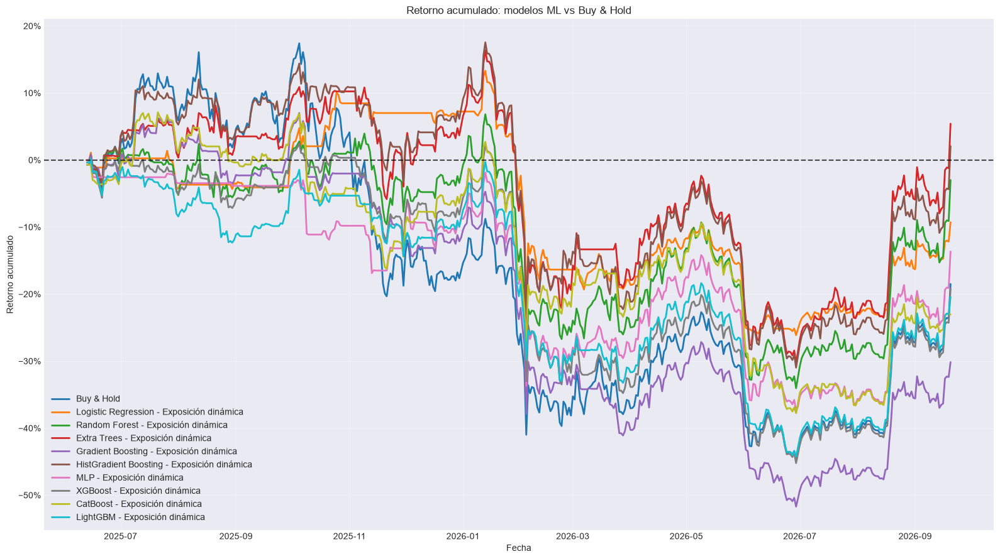

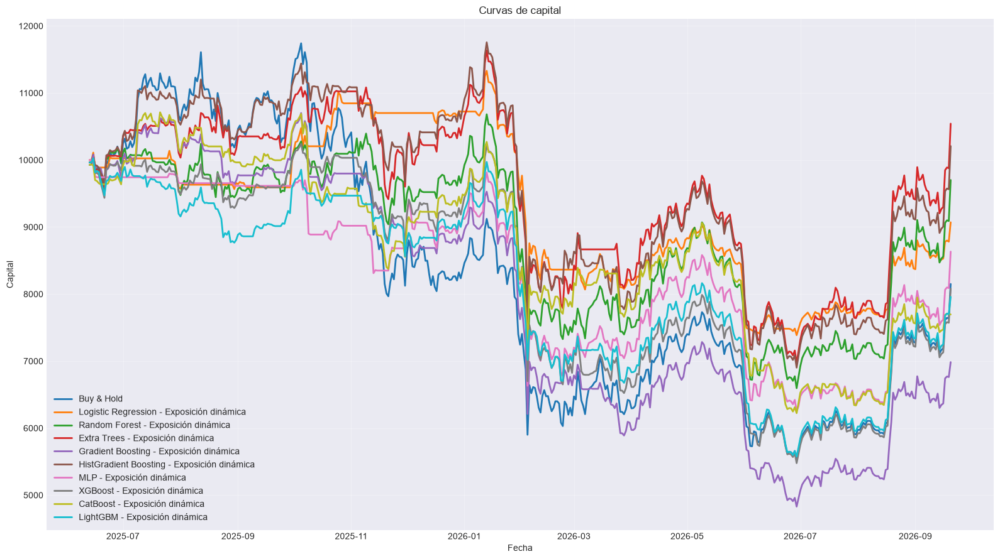

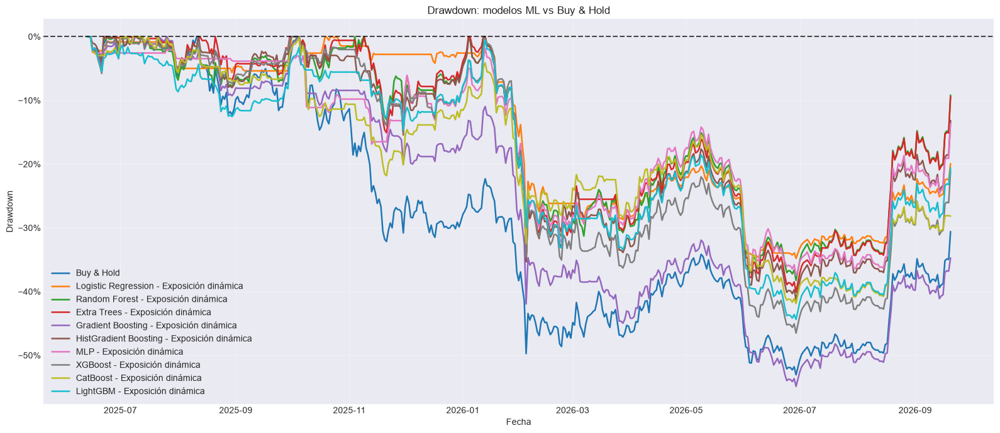


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3253
1,Gradient Boosting,0.3073
2,Logistic Regression,0.3047
3,CatBoost,0.3037
4,XGBoost,0.2997
5,LightGBM,0.2911
6,HistGradient Boosting,0.2890
7,Extra Trees,0.2663
8,Random Forest,0.2662



COMPROBACIONES FINALES
X_dev: 1824
y_dev: 1824
t1_dev: 1824
X_test: 466
y_test: 466
t1_test: 466
test_prices: 466
forward_returns válidos: 465
Logistic Regression shape: (466,) | índice correcto: True
Random Forest shape: (466,) | índice correcto: True
Extra Trees shape: (466,) | índice correcto: True
Gradient Boosting shape: (466,) | índice correcto: True
HistGradient Boosting shape: (466,) | índice correcto: True
MLP shape: (466,) | índice correcto: True
XGBoost shape: (466,) | índice correcto: True
CatBoost shape: (466,) | índice correcto: True
LightGBM shape: (466,) | índice correcto: True

Pipeline terminado correctamente.


In [395]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 20

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
     "Indice_Dolar_DXY_log_ret", "Oro_log_ret", "S&P_500_log_ret", "NASDAQ_Tecnologico_log_ret", "Cardano_log_ret", "Bitcoin_Cash_log_ret", "Ethereum_log_ret", "Chainlink_log_ret", "Litecoin_log_ret", "Indice_Volatilidad_VIX_diff",
       "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

In [425]:
df_b

""
Date
2020-01-01
2020-01-02
2020-01-03
2020-01-04
2020-01-05
...
2026-09-26
2026-09-27
2026-09-28


In [407]:
import yfinance as yf
import pandas as pd
import numpy as np
import talib

# -------------------------------------------------------------------------
# 1. DESCARGA DE DATOS
# -------------------------------------------------------------------------
tickers_dict = {
    "BTC-USD": "Bitcoin",
    "ETH-USD": "Ethereum",
    "LTC-USD": "Litecoin",
    "BCH-USD": "Bitcoin_Cash",
    "ADA-USD": "Cardano",
    "LINK-USD": "Chainlink",
    "^TNX": "US_10Y_Bond",
    "^FVX": "US_5Y_Bond",
    "^GSPC": "SP500",
    "^IXIC": "NASDAQ",
    "^N100": "Euronext100",
    "DX-Y.NYB": "DXY_DollarIndex",
    "EURUSD=X": "EUR_USD",
    "^VIX": "VIX",
    "GC=F": "Gold",
    "CL=F": "Crude_Oil_WTI"
}

start_date = "2020-01-01"
end_date = "2026-10-01"

print("Descargando datos desde Yahoo Finance...")
df_raw = yf.download(list(tickers_dict.keys()), start=start_date, end=end_date, interval="1d")

# Guardar los datos OHLCV específicos de Bitcoin para TA-Lib
df_btc = df_raw.xs('BTC-USD', level=1, axis=1).copy()

# Guardar los precios de cierre para todas las variables
df_close = df_raw["Close"].copy()
df_close.rename(columns=tickers_dict, inplace=True)

# DataFrame consolidado (renombrado a df_b)
df_b = pd.DataFrame(index=df_close.index)

# -------------------------------------------------------------------------
# 2. CÁLCULO DE RENDIMIENTOS LOGARÍTMICOS Y DIFERENCIAS ABSOLUTAS
# -------------------------------------------------------------------------
print("Calculando retornos logarítmicos y diferencias...")

# Variables para retornos logarítmicos
log_return_vars = ["Bitcoin", "Ethereum", "Litecoin", "Bitcoin_Cash", "Cardano", "Chainlink",   "SP500", "NASDAQ", "Euronext100", "DXY_DollarIndex", "EUR_USD", "Gold", "Crude_Oil_WTI"]

for col in log_return_vars:
    df_b[f"{col}_log_ret"] = np.log(df_close[col] / df_close[col].shift(1))

# Variables para diferencias simples (Tasas/Bonos y Volatilidad)
diff_vars = ["US_10Y_Bond", "US_5Y_Bond", "VIX"]

for col in diff_vars:
    df_b[f"{col}_diff"] = df_close[col].diff(1)

# -------------------------------------------------------------------------
# 3. PREPARACIÓN DE DATOS Y CÁLCULO DE INDICADORES TÉCNICOS (BTC)
# -------------------------------------------------------------------------
# Limpiar columnas multinivel si existen en las series de BTC
if isinstance(df_btc.columns, pd.MultiIndex):
    df_btc.columns = df_btc.columns.get_level_values(0)

# Convertir tipos a float64 requeridos por TA-Lib desde el dataset de Bitcoin
op = df_btc['Open'].values.astype(np.float64)
hi = df_btc['High'].values.astype(np.float64)
lo = df_btc['Low'].values.astype(np.float64)
cl = df_btc['Close'].values.astype(np.float64)
vol = df_btc['Volume'].values.astype(np.float64)

# Agregar series OHLCV de BTC al dataframe consolidado df_b
df_b['BTC_Open'] = op
df_b['BTC_High'] = hi
df_b['BTC_Low'] = lo
df_b['BTC_Close'] = cl
df_b['BTC_Volume'] = vol

print("Calculando todos los indicadores técnicos solicitados con TA-Lib...")

# --- 1. OVERLAP STUDIES (Estudios de Superposición) ---
df_b['SMA'] = talib.SMA(cl, timeperiod=30)
df_b['EMA'] = talib.EMA(cl, timeperiod=30)
df_b['WMA'] = talib.WMA(cl, timeperiod=30)
df_b['DEMA'] = talib.DEMA(cl, timeperiod=30)
df_b['TEMA'] = talib.TEMA(cl, timeperiod=30)
df_b['TRIMA'] = talib.TRIMA(cl, timeperiod=30)
df_b['KAMA'] = talib.KAMA(cl, timeperiod=30)
df_b['MAMA'], df_b['FAMA'] = talib.MAMA(cl)
df_b['T3'] = talib.T3(cl, timeperiod=5, vfactor=0.7)

# VWAP (Cálculo acumulado diario sobre Bitcoin)
typical_price = (hi + lo + cl) / 3
df_b['VWAP_Premium'] = (typical_price * vol).cumsum() / vol.cumsum()


# --- 2. MOMENTUM INDICATORS (Indicadores de Momento) ---
df_b['MACD'], df_b['MACD_Signal'], df_b['MACD_Hist'] = talib.MACD(cl, fastperiod=12, slowperiod=26, signalperiod=9)
df_b['MACDEXT'], df_b['MACDEXT_Signal'], df_b['MACDEXT_Hist'] = talib.MACDEXT(cl, fastperiod=12, fastmatype=0, slowperiod=26, slowmatype=0, signalperiod=9, signalmatype=0)

df_b['STOCH_SlowK'], df_b['STOCH_SlowD'] = talib.STOCH(hi, lo, cl, fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
df_b['STOCHF_FastK'], df_b['STOCHF_FastD'] = talib.STOCHF(hi, lo, cl, fastk_period=5, fastd_period=3, fastd_matype=0)

df_b['RSI'] = talib.RSI(cl, timeperiod=14)
df_b['STOCHRSI_FastK'], df_b['STOCHRSI_FastD'] = talib.STOCHRSI(cl, timeperiod=14, fastk_period=5, fastd_period=3, fastd_matype=0)

df_b['WILLR'] = talib.WILLR(hi, lo, cl, timeperiod=14)
df_b['ADX'] = talib.ADX(hi, lo, cl, timeperiod=14)
df_b['ADXR'] = talib.ADXR(hi, lo, cl, timeperiod=14)
df_b['APO'] = talib.APO(cl, fastperiod=12, slowperiod=26, matype=0)
df_b['PPO'] = talib.PPO(cl, fastperiod=12, slowperiod=26, matype=0)
df_b['MOM'] = talib.MOM(cl, timeperiod=10)
df_b['BOP'] = talib.BOP(op, hi, lo, cl)
df_b['CCI'] = talib.CCI(hi, lo, cl, timeperiod=14)
df_b['CMO'] = talib.CMO(cl, timeperiod=14)
df_b['ROC'] = talib.ROC(cl, timeperiod=10)
df_b['ROCR'] = talib.ROCR(cl, timeperiod=10)

df_b['AROON_Down'], df_b['AROON_Up'] = talib.AROON(hi, lo, timeperiod=14)
df_b['AROONOSC'] = talib.AROONOSC(hi, lo, timeperiod=14)
df_b['MFI'] = talib.MFI(hi, lo, cl, vol, timeperiod=14)
df_b['TRIX'] = talib.TRIX(cl, timeperiod=30)
df_b['ULTOSC'] = talib.ULTOSC(hi, lo, cl, timeperiod1=7, timeperiod2=14, timeperiod3=28)


# --- 3. VOLATILITY INDICATORS (Indicadores de Volatilidad) ---
df_b['BB_Upper'], df_b['BB_Middle'], df_b['BB_Lower'] = talib.BBANDS(cl, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
df_b['MIDPOINT'] = talib.MIDPOINT(cl, timeperiod=14)
df_b['MIDPRICE'] = talib.MIDPRICE(hi, lo, timeperiod=14)
df_b['SAR'] = talib.SAR(hi, lo, acceleration=0.02, maximum=0.2)
df_b['TRANGE'] = talib.TRANGE(hi, lo, cl)
df_b['ATR'] = talib.ATR(hi, lo, cl, timeperiod=14)
df_b['NATR'] = talib.NATR(hi, lo, cl, timeperiod=14)


# --- 4. VOLUME INDICATORS (Indicadores de Volumen) ---
df_b['AD'] = talib.AD(hi, lo, cl, vol)
df_b['ADOSC'] = talib.ADOSC(hi, lo, cl, vol, fastperiod=3, slowperiod=10)
df_b['OBV'] = talib.OBV(cl, vol)

# Limpieza de registros nulos
df_b.dropna(inplace=True)

print("\n¡Proceso finalizado exitosamente!")
print(f"Dimensiones del DataFrame final (df_b): {df_b.shape}")
print(df_b.head())

[                       0%                       ]

Descargando datos desde Yahoo Finance...


[*********************100%***********************]  16 of 16 completed


Calculando retornos logarítmicos y diferencias...
Calculando todos los indicadores técnicos solicitados con TA-Lib...

¡Proceso finalizado exitosamente!
Dimensiones del DataFrame final (df_b): (1263, 74)
            Bitcoin_log_ret  Ethereum_log_ret  ...         ADOSC           OBV
Date                                           ...                            
2020-03-31         0.001368          0.005171  ... -1.619339e+08 -6.326485e+10
2020-04-01         0.025778          0.015162  ...  1.291198e+10 -2.291843e+10
2020-04-02         0.027889          0.046068  ...  1.410134e+10  2.474222e+10
2020-04-03        -0.008906          0.000438  ...  5.419446e+09 -1.423429e+10
2020-04-07        -0.013201         -0.024139  ...  1.807355e+10 -7.905285e+09

[5 rows x 74 columns]


In [409]:
df_b.columns

Index(['Bitcoin_log_ret', 'Ethereum_log_ret', 'Litecoin_log_ret',
       'Bitcoin_Cash_log_ret', 'Cardano_log_ret', 'Chainlink_log_ret',
       'SP500_log_ret', 'NASDAQ_log_ret', 'Euronext100_log_ret',
       'DXY_DollarIndex_log_ret', 'EUR_USD_log_ret', 'Gold_log_ret',
       'Crude_Oil_WTI_log_ret', 'US_10Y_Bond_diff', 'US_5Y_Bond_diff',
       'VIX_diff', 'BTC_Open', 'BTC_High', 'BTC_Low', 'BTC_Close',
       'BTC_Volume', 'SMA', 'EMA', 'WMA', 'DEMA', 'TEMA', 'TRIMA', 'KAMA',
       'MAMA', 'FAMA', 'T3', 'VWAP_Premium', 'MACD', 'MACD_Signal',
       'MACD_Hist', 'MACDEXT', 'MACDEXT_Signal', 'MACDEXT_Hist', 'STOCH_SlowK',
       'STOCH_SlowD', 'STOCHF_FastK', 'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK',
       'STOCHRSI_FastD', 'WILLR', 'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP',
       'CCI', 'CMO', 'ROC', 'ROCR', 'AROON_Down', 'AROON_Up', 'AROONOSC',
       'MFI', 'TRIX', 'ULTOSC', 'BB_Upper', 'BB_Middle', 'BB_Lower',
       'MIDPOINT', 'MIDPRICE', 'SAR', 'TRANGE', 'ATR', 'NATR', 'AD', 

Dimensiones del dataframe: (1263, 74)
Primer registro: 2020-03-31 00:00:00
Último registro: 2026-09-30 00:00:00
VWAP_Premium recalculado con rolling causal.
Número de features: 69
FEATURE_LAG: 1
Inicio del test: 2025-06-12 00:00:00

Optimizando Triple Barrier...


Best trial: 60. Best value: 0.811015: 100%|██████████| 80/80 [00:26<00:00,  3.06it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.519932925079558, 'sl_multiplier': 2.602052839794806, 'max_holding_bars': 13, 'volatility_window': 10}
Score de balance walk-forward: 0.811

Tamaño desarrollo: 990
Tamaño test: 240

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,287,28.99%
1,Neutral,1,339,34.24%
2,Sube,2,364,36.77%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,82,34.17%
1,Neutral,1,74,30.83%
2,Sube,2,84,35.00%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.35
Balanced accuracy: 0.3333
F1 macro: 0.1728

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       100
Neutral    117
Sube        23
Name: count, dtype: int64
Exposición media: 33.96%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja       105
Neutral     62
Sube        73
Name: count, dtype: int64
Exposición media: 43.33%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       139
Neutral     31
Sube        70
Name: count, dtype: int64
Exposición media: 35.62%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        81
Neutral     54
Sube       105
Name: count, dtype: int64
Exposición media: 55.00%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        69
Neutral     55
Sube       116
Name: count, dtype: int64
Exposición med

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,509.99",-24.90%,-20.81%,55.75%,-0.5040,-0.6928,-52.53%,-0.3962,48.54%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$13,001.53",30.02%,23.84%,31.19%,1.4397,1.6074,-18.65%,1.2782,22.59%,35.56%,$298.85,20.00,26
2,Random Forest - Exposición dinámica,"$11,753.33",17.53%,14.07%,33.38%,0.9054,1.0380,-19.98%,0.7041,27.20%,43.10%,$403.40,27.50,36
3,MLP - Exposición dinámica,"$11,620.58",16.21%,13.02%,24.16%,1.0684,1.0714,-14.44%,0.9013,16.32%,26.99%,$253.14,18.50,25
4,CatBoost - Exposición dinámica,"$9,667.85",-3.32%,-2.71%,11.97%,-0.3724,-0.2684,-10.89%,-0.2493,3.35%,7.32%,$282.49,19.50,24
5,Logistic Regression - Exposición dinámica,"$8,134.52",-18.65%,-15.48%,30.29%,-0.8861,-0.7734,-33.58%,-0.4610,27.20%,33.89%,$250.90,17.50,28
6,LightGBM - Exposición dinámica,"$8,024.47",-19.76%,-16.42%,37.35%,-0.7120,-0.7973,-40.44%,-0.4059,27.62%,52.09%,$527.34,42.50,58
7,Gradient Boosting - Exposición dinámica,"$7,288.08",-27.12%,-22.72%,37.72%,-1.0914,-1.2990,-45.18%,-0.5029,28.45%,55.02%,$464.11,41.00,51
8,XGBoost - Exposición dinámica,"$6,657.89",-33.42%,-28.21%,39.33%,-1.3812,-1.6040,-47.47%,-0.5943,28.87%,55.86%,$427.31,38.00,57
9,HistGradient Boosting - Exposición dinámica,"$5,947.49",-40.53%,-34.51%,40.85%,-1.7356,-2.0750,-53.16%,-0.6493,30.96%,59.62%,$581.53,50.00,70



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,30.02%,-24.90%,54.92%,1.4397,-0.5040,1.9437,-18.65%,-52.53%,33.87%,True,True,True
1,Random Forest - Exposición dinámica,17.53%,-24.90%,42.43%,0.9054,-0.5040,1.4095,-19.98%,-52.53%,32.55%,True,True,True
2,MLP - Exposición dinámica,16.21%,-24.90%,41.11%,1.0684,-0.5040,1.5724,-14.44%,-52.53%,38.09%,True,True,True
3,CatBoost - Exposición dinámica,-3.32%,-24.90%,21.58%,-0.3724,-0.5040,0.1316,-10.89%,-52.53%,41.64%,True,True,True
4,Logistic Regression - Exposición dinámica,-18.65%,-24.90%,6.25%,-0.8861,-0.5040,-0.3820,-33.58%,-52.53%,18.95%,True,False,True
5,LightGBM - Exposición dinámica,-19.76%,-24.90%,5.14%,-0.7120,-0.5040,-0.2080,-40.44%,-52.53%,12.08%,True,False,True
6,Gradient Boosting - Exposición dinámica,-27.12%,-24.90%,-2.22%,-1.0914,-0.5040,-0.5874,-45.18%,-52.53%,7.35%,False,False,True
7,XGBoost - Exposición dinámica,-33.42%,-24.90%,-8.52%,-1.3812,-0.5040,-0.8772,-47.47%,-52.53%,5.06%,False,False,True
8,HistGradient Boosting - Exposición dinámica,-40.53%,-24.90%,-15.63%,-1.7356,-0.5040,-1.2316,-53.16%,-52.53%,-0.63%,False,False,False


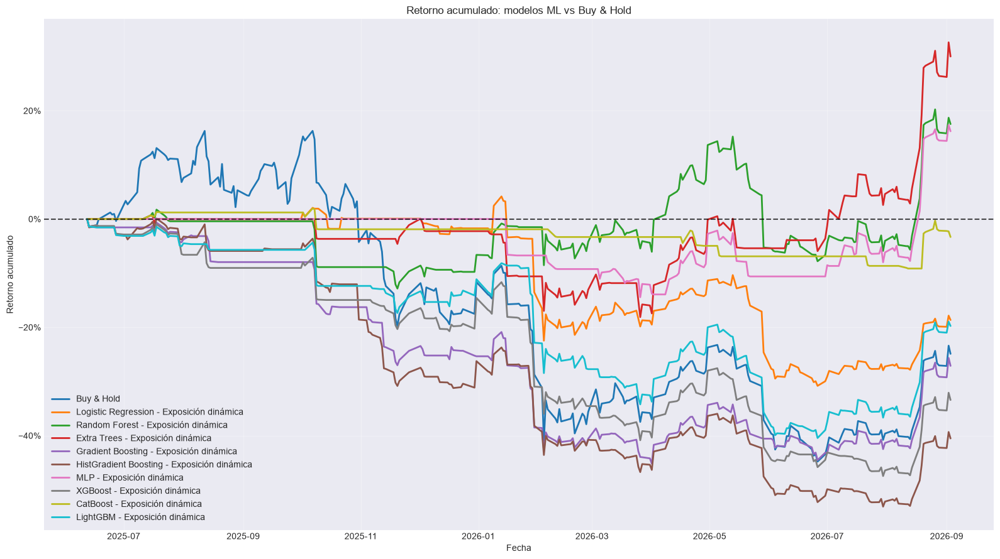

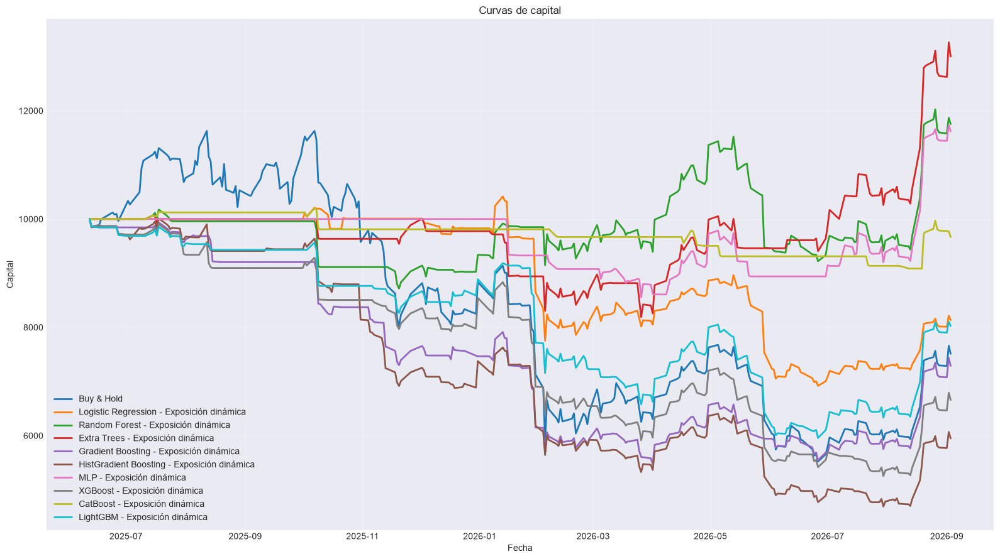

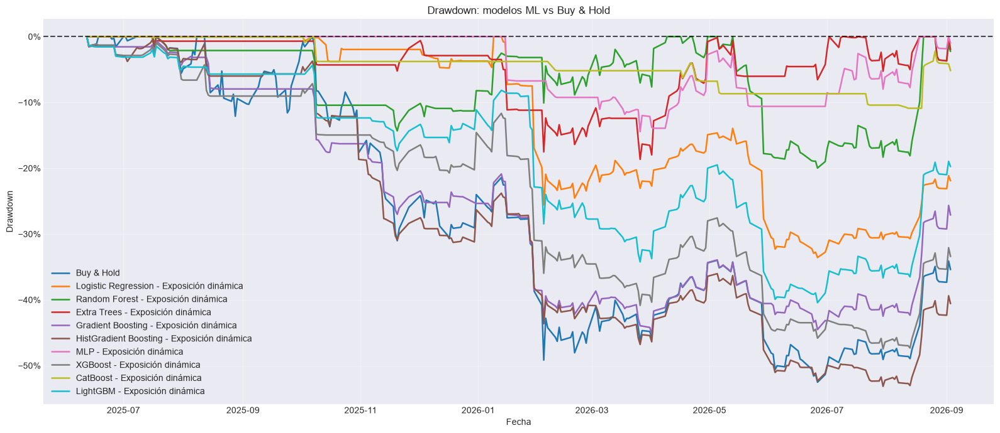


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,Gradient Boosting,0.3169
1,Random Forest,0.3153
2,LightGBM,0.3084
3,MLP,0.2957
4,HistGradient Boosting,0.2943
5,CatBoost,0.2365
6,Logistic Regression,0.0000
7,Extra Trees,0.0000
8,XGBoost,0.0000



COMPROBACIONES FINALES
X_dev: 990
y_dev: 990
t1_dev: 990
X_test: 240
y_test: 240
t1_test: 240
test_prices: 240
forward_returns válidos: 239
Logistic Regression shape: (240,) | índice correcto: True
Random Forest shape: (240,) | índice correcto: True
Extra Trees shape: (240,) | índice correcto: True
Gradient Boosting shape: (240,) | índice correcto: True
HistGradient Boosting shape: (240,) | índice correcto: True
MLP shape: (240,) | índice correcto: True
XGBoost shape: (240,) | índice correcto: True
CatBoost shape: (240,) | índice correcto: True
LightGBM shape: (240,) | índice correcto: True

Pipeline terminado correctamente.


In [410]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN   
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo 
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10

# VWAP
VWAP_WINDOW = 30
RECALCULAR_VWAP = True

VWAP_HIGH_COL = "BTC_High"
VWAP_LOW_COL = "BTC_Low"
VWAP_CLOSE_COL = "BTC_Close"
VWAP_VOLUME_COL = "BTC_Volume"

CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_b.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)


# ============================================================
# 3. VWAP PREMIUM CAUSAL
# ============================================================

def construir_vwap_premium_rolling(
    data,
    high_col,
    low_col,
    close_col,
    volume_col,
    window
):
    """
    VWAP rolling causal.

    En t utiliza solamente datos de [t-window+1, t].
    Posteriormente X_all se desplaza una barra.
    """

    required = [
        high_col,
        low_col,
        close_col,
        volume_col
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            "Faltan columnas para VWAP_Premium:\n"
            f"{missing}"
        )

    high = pd.to_numeric(
        data[high_col],
        errors="coerce"
    )

    low = pd.to_numeric(
        data[low_col],
        errors="coerce"
    )

    close = pd.to_numeric(
        data[close_col],
        errors="coerce"
    )

    volume = pd.to_numeric(
        data[volume_col],
        errors="coerce"
    )

    typical_price = (
        high
        +
        low
        +
        close
    ) / 3.0

    price_volume = (
        typical_price
        *
        volume
    )

    rolling_price_volume = (
        price_volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = (
        volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = rolling_volume.replace(
        0,
        np.nan
    )

    rolling_vwap = (
        rolling_price_volume
        /
        rolling_volume
    )

    return (
        close
        /
        rolling_vwap
        -
        1.0
    ).rename(
        "VWAP_Premium"
    )
 

if RECALCULAR_VWAP:

    vwap_columns = [
        VWAP_HIGH_COL,
        VWAP_LOW_COL,
        VWAP_CLOSE_COL,
        VWAP_VOLUME_COL
    ]

    if all(
        col in df.columns
        for col in vwap_columns
    ):

        df["VWAP_Premium"] = (
            construir_vwap_premium_rolling(
                data=df,
                high_col=VWAP_HIGH_COL,
                low_col=VWAP_LOW_COL,
                close_col=VWAP_CLOSE_COL,
                volume_col=VWAP_VOLUME_COL,
                window=VWAP_WINDOW
            )
        )

        print(
            "VWAP_Premium recalculado con rolling causal."
        )

    else:

        print(
            "VWAP_Premium no se recalculó porque faltan "
            "columnas OHLCV. Se usará la columna existente."
        )


# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
    "Bitcoin_log_ret",
     'Ethereum_log_ret', 'Litecoin_log_ret',
       'Bitcoin_Cash_log_ret', 'Cardano_log_ret', 'Chainlink_log_ret',
       
    "SP500_log_ret",
    "NASDAQ_log_ret",
    "Euronext100_log_ret",
    "DXY_DollarIndex_log_ret",
    "EUR_USD_log_ret",
    "Gold_log_ret",
    "Crude_Oil_WTI_log_ret",
    "US_10Y_Bond_diff",
    "US_5Y_Bond_diff",
    "VIX_diff",

    "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "VWAP_Premium",

    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Version Recuperada de datos

In [426]:
import yfinance as yf
import pandas as pd
import numpy as np
import talib

# -------------------------------------------------------------------------
# 1. DESCARGA DE DATOS
# -------------------------------------------------------------------------
tickers_dict = {
    "BTC-USD": "Bitcoin",
    "^TNX": "US_10Y_Bond",
    "^FVX": "US_5Y_Bond",
    "^GSPC": "SP500",
    "^IXIC": "NASDAQ",
    "^N100": "Euronext100",
    "DX-Y.NYB": "DXY_DollarIndex",
    "EURUSD=X": "EUR_USD",
    "^VIX": "VIX",
    "GC=F": "Gold",
    "CL=F": "Crude_Oil_WTI"
}

start_date = "2020-01-01"
end_date = "2026-10-01"

print("Descargando datos desde Yahoo Finance...")
df_raw = yf.download(list(tickers_dict.keys()), start=start_date, end=end_date, interval="1d")
df_raw.ffill(inplace= True)

# Guardar los datos OHLCV específicos de Bitcoin para TA-Lib
df_btc = df_raw.xs('BTC-USD', level=1, axis=1).copy()

# Guardar los precios de cierre para todas las variables
df_close = df_raw["Close"].copy()
df_close.rename(columns=tickers_dict, inplace=True)

# DataFrame consolidado (renombrado a df_b)
df_b = pd.DataFrame(index=df_close.index)

# -------------------------------------------------------------------------
# 2. CÁLCULO DE RENDIMIENTOS LOGARÍTMICOS Y DIFERENCIAS ABSOLUTAS
# -------------------------------------------------------------------------
print("Calculando retornos logarítmicos y diferencias...")

# Variables para retornos logarítmicos
log_return_vars = ["Bitcoin", "SP500", "NASDAQ", "Euronext100", "DXY_DollarIndex", "EUR_USD", "Gold", "Crude_Oil_WTI"]

for col in log_return_vars:
    df_b[f"{col}_log_ret"] = np.log(df_close[col] / df_close[col].shift(1))

# Variables para diferencias simples (Tasas/Bonos y Volatilidad)
diff_vars = ["US_10Y_Bond", "US_5Y_Bond", "VIX"]

for col in diff_vars:
    df_b[f"{col}_diff"] = df_close[col].diff(1)

# -------------------------------------------------------------------------
# 3. PREPARACIÓN DE DATOS Y CÁLCULO DE INDICADORES TÉCNICOS (BTC)
# -------------------------------------------------------------------------
# Limpiar columnas multinivel si existen en las series de BTC
if isinstance(df_btc.columns, pd.MultiIndex):
    df_btc.columns = df_btc.columns.get_level_values(0)

# Convertir tipos a float64 requeridos por TA-Lib desde el dataset de Bitcoin
op = df_btc['Open'].values.astype(np.float64)
hi = df_btc['High'].values.astype(np.float64)
lo = df_btc['Low'].values.astype(np.float64)
cl = df_btc['Close'].values.astype(np.float64)
vol = df_btc['Volume'].values.astype(np.float64)

# Agregar series OHLCV de BTC al dataframe consolidado df_b
df_b['BTC_Open'] = op
df_b['BTC_High'] = hi
df_b['BTC_Low'] = lo
df_b['BTC_Close'] = cl
df_b['BTC_Volume'] = vol

print("Calculando todos los indicadores técnicos solicitados con TA-Lib...")

# --- 1. OVERLAP STUDIES (Estudios de Superposición) ---
df_b['SMA'] = talib.SMA(cl, timeperiod=30)
df_b['EMA'] = talib.EMA(cl, timeperiod=30)
df_b['WMA'] = talib.WMA(cl, timeperiod=30)
df_b['DEMA'] = talib.DEMA(cl, timeperiod=30)
df_b['TEMA'] = talib.TEMA(cl, timeperiod=30)
df_b['TRIMA'] = talib.TRIMA(cl, timeperiod=30)
df_b['KAMA'] = talib.KAMA(cl, timeperiod=30)
df_b['MAMA'], df_b['FAMA'] = talib.MAMA(cl)
df_b['T3'] = talib.T3(cl, timeperiod=5, vfactor=0.7)

# VWAP (Cálculo acumulado diario sobre Bitcoin)
typical_price = (hi + lo + cl) / 3
df_b['VWAP_Premium'] = (typical_price * vol).cumsum() / vol.cumsum()


# --- 2. MOMENTUM INDICATORS (Indicadores de Momento) ---
df_b['MACD'], df_b['MACD_Signal'], df_b['MACD_Hist'] = talib.MACD(cl, fastperiod=12, slowperiod=26, signalperiod=9)
df_b['MACDEXT'], df_b['MACDEXT_Signal'], df_b['MACDEXT_Hist'] = talib.MACDEXT(cl, fastperiod=12, fastmatype=0, slowperiod=26, slowmatype=0, signalperiod=9, signalmatype=0)

df_b['STOCH_SlowK'], df_b['STOCH_SlowD'] = talib.STOCH(hi, lo, cl, fastk_period=5, slowk_period=3, slowk_matype=0, slowd_period=3, slowd_matype=0)
df_b['STOCHF_FastK'], df_b['STOCHF_FastD'] = talib.STOCHF(hi, lo, cl, fastk_period=5, fastd_period=3, fastd_matype=0)

df_b['RSI'] = talib.RSI(cl, timeperiod=14)
df_b['STOCHRSI_FastK'], df_b['STOCHRSI_FastD'] = talib.STOCHRSI(cl, timeperiod=14, fastk_period=5, fastd_period=3, fastd_matype=0)

df_b['WILLR'] = talib.WILLR(hi, lo, cl, timeperiod=14)
df_b['ADX'] = talib.ADX(hi, lo, cl, timeperiod=14)
df_b['ADXR'] = talib.ADXR(hi, lo, cl, timeperiod=14)
df_b['APO'] = talib.APO(cl, fastperiod=12, slowperiod=26, matype=0)
df_b['PPO'] = talib.PPO(cl, fastperiod=12, slowperiod=26, matype=0)
df_b['MOM'] = talib.MOM(cl, timeperiod=10)
df_b['BOP'] = talib.BOP(op, hi, lo, cl)
df_b['CCI'] = talib.CCI(hi, lo, cl, timeperiod=14)
df_b['CMO'] = talib.CMO(cl, timeperiod=14)
df_b['ROC'] = talib.ROC(cl, timeperiod=10)
df_b['ROCR'] = talib.ROCR(cl, timeperiod=10)

df_b['AROON_Down'], df_b['AROON_Up'] = talib.AROON(hi, lo, timeperiod=14)
df_b['AROONOSC'] = talib.AROONOSC(hi, lo, timeperiod=14)
df_b['MFI'] = talib.MFI(hi, lo, cl, vol, timeperiod=14)
df_b['TRIX'] = talib.TRIX(cl, timeperiod=30)
df_b['ULTOSC'] = talib.ULTOSC(hi, lo, cl, timeperiod1=7, timeperiod2=14, timeperiod3=28)


# --- 3. VOLATILITY INDICATORS (Indicadores de Volatilidad) ---
df_b['BB_Upper'], df_b['BB_Middle'], df_b['BB_Lower'] = talib.BBANDS(cl, timeperiod=20, nbdevup=2, nbdevdn=2, matype=0)
df_b['MIDPOINT'] = talib.MIDPOINT(cl, timeperiod=14)
df_b['MIDPRICE'] = talib.MIDPRICE(hi, lo, timeperiod=14)
df_b['SAR'] = talib.SAR(hi, lo, acceleration=0.02, maximum=0.2)
df_b['TRANGE'] = talib.TRANGE(hi, lo, cl)
df_b['ATR'] = talib.ATR(hi, lo, cl, timeperiod=14)
df_b['NATR'] = talib.NATR(hi, lo, cl, timeperiod=14)


# --- 4. VOLUME INDICATORS (Indicadores de Volumen) ---
df_b['AD'] = talib.AD(hi, lo, cl, vol)
df_b['ADOSC'] = talib.ADOSC(hi, lo, cl, vol, fastperiod=3, slowperiod=10)
df_b['OBV'] = talib.OBV(cl, vol)

# Limpieza de registros nulos
df_b.dropna(inplace=True)

print("\n¡Proceso finalizado exitosamente!")
print(f"Dimensiones del DataFrame final (df_b): {df_b.shape}")
print(df_b.head())

[*********             18%                       ]  2 of 11 completed

Descargando datos desde Yahoo Finance...


[*********************100%***********************]  11 of 11 completed


Calculando retornos logarítmicos y diferencias...
Calculando todos los indicadores técnicos solicitados con TA-Lib...

¡Proceso finalizado exitosamente!
Dimensiones del DataFrame final (df_b): (2375, 69)
            Bitcoin_log_ret  SP500_log_ret  ...         ADOSC           OBV
Date                                        ...                            
2020-03-29        -0.052650       0.000000  ... -5.001796e+09 -1.331530e+11
2020-03-30         0.082268       0.032967  ... -1.590849e+09 -9.605132e+10
2020-03-31         0.001368      -0.016142  ... -1.619339e+08 -6.326485e+10
2020-04-01         0.025778      -0.045146  ...  1.291198e+10 -2.291843e+10
2020-04-02         0.027889       0.022573  ...  1.410134e+10  2.474222e+10

[5 rows x 69 columns]


In [427]:
df_b.head(25)

,Bitcoin_log_ret,SP500_log_ret,NASDAQ_log_ret,Euronext100_log_ret,DXY_DollarIndex_log_ret,EUR_USD_log_ret,Gold_log_ret,Crude_Oil_WTI_log_ret,US_10Y_Bond_diff,US_5Y_Bond_diff,VIX_diff,BTC_Open,BTC_High,BTC_Low,BTC_Close,BTC_Volume,SMA,EMA,WMA,DEMA,TEMA,TRIMA,KAMA,MAMA,FAMA,T3,VWAP_Premium,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,TRIX,ULTOSC,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-03-29,-0.052650,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,6245.624512,6250.467285,5920.085938,5922.042969,2.837369e+10,6957.750732,6903.318525,6413.064464,5932.113789,5825.868621,6555.135437,6432.693563,6092.791831,6658.153175,6511.432425,8278.530850,-450.569551,-589.165533,138.595982,-453.433152,-1124.426607,670.993455,26.028659,51.879397,0.201253,26.028659,38.829768,0.000000,7.405649e+00,-41.881918,35.013919,39.566757,-453.433152,-6.778823,-269.149902,-0.979418,-5.326024,-22.340464,-4.347303,0.956527,7.142857,71.428571,64.285714,55.215614,-0.677935,51.721625,7751.306327,6100.741675,4450.177023,5874.641846,5733.934570,4750.005214,330.381348,516.657593,8.724313,2.353164e+11,-5.001796e+09,-1.331530e+11
2020-03-30,0.082268,0.032967,0.035584,0.008853,0.008200,0.008187,-0.001171,-0.068296,-0.079,-0.048,-8.459999,5925.538574,6517.195801,5903.234375,6429.841797,3.710165e+10,6885.428499,6872.771639,6379.005823,5935.649155,5868.141910,6443.563062,6432.589884,6109.644329,6644.440453,6445.950331,8255.921222,-407.979729,-552.928372,144.948643,-264.710916,-985.029998,720.319083,25.127774,35.050676,59.129374,25.127774,45.834544,84.470111,2.815670e+01,-24.215897,33.940631,40.176557,-264.710916,-4.011059,231.063477,0.821392,24.135079,-8.330913,3.727565,1.037276,0.000000,64.285714,64.285714,61.695786,-0.686236,50.767628,7465.370586,6026.747290,4588.123994,5980.216553,5937.210205,4835.705455,613.961426,523.607867,8.143402,2.618605e+11,-1.590849e+09,-9.605132e+10
2020-03-31,0.001368,-0.016142,-0.009571,0.008449,-0.001312,-0.009799,-0.024086,0.019227,0.028,-0.003,-3.540001,6430.606445,6504.515137,6374.162109,6438.644531,3.278647e+10,6814.634847,6844.763438,6350.181050,5941.899250,5910.795394,6351.288013,6432.804664,6126.094339,6631.481801,6409.943211,8237.907165,-369.260081,-516.194714,146.934633,-142.546938,-827.811417,685.264479,39.816135,30.324189,60.117777,39.816135,45.950091,100.000000,6.149004e+01,-24.894298,32.944007,40.742800,-142.546938,-2.193710,253.578125,0.061664,46.421895,-8.099818,4.099845,1.040998,0.000000,57.142857,57.142857,61.809574,-0.692682,47.190691,7124.206622,5953.108008,4782.009394,5986.621094,5980.923584,4917.977686,130.353027,495.518235,7.696002,2.615113e+11,-1.619339e+08,-6.326485e+10
2020-04-01,0.025778,-0.045146,-0.045095,-0.035888,0.006240,-0.000353,-0.003290,-0.008335,-0.063,-0.006,3.520000,6437.319336,6612.573730,6202.373535,6606.776367,4.034643e+10,6739.205062,6829.409434,6336.770826,5970.431124,5982.388500,6279.550968,6439.642616,6150.128441,6619.447967,6418.864259,8216.643264,-321.303856,-477.216542,155.912686,-11.786734,-652.494656,640.707922,72.809954,45.917954,99.182709,72.809954,48.222043,100.000000,9.482337e+01,-17.259289,32.303990,40.198212,-11.786734,-0.184133,776.521484,0.413108,42.687186,-3.555913,13.318826,1.133188,0.000000,50.000000,50.000000,62.482831,-0.696854,53.890604,7147.190374,6034.907422,4922.624469,6282.529297,6064.739990,4996.959028,410.200195,489.424090,7.407911,3.007173e+11,1.291198e+10,-2.291843e+10
2020-04-02,0.027889,0.022573,0.017071,0.005998,0.005104,-0.006638,0.029654,0.220481,-0.008,0.017,-6.150002,6606.776367,7088.247559,6595.918457,6793.624512,4.766065e+10,6672.733008,6827.100729,6340.281758,6021.380619,6082.388738,6229.477368,6451.261306,6471.876476,6582.555094,64

# Modelo Replicado

In [435]:
df_b.head(20)

,Bitcoin_log_ret,SP500_log_ret,NASDAQ_log_ret,Euronext100_log_ret,DXY_DollarIndex_log_ret,EUR_USD_log_ret,Gold_log_ret,Crude_Oil_WTI_log_ret,US_10Y_Bond_diff,US_5Y_Bond_diff,VIX_diff,BTC_Open,BTC_High,BTC_Low,BTC_Close,BTC_Volume,SMA,EMA,WMA,DEMA,TEMA,TRIMA,KAMA,MAMA,FAMA,T3,VWAP_Premium,MACD,MACD_Signal,MACD_Hist,MACDEXT,MACDEXT_Signal,MACDEXT_Hist,STOCH_SlowK,STOCH_SlowD,STOCHF_FastK,STOCHF_FastD,RSI,STOCHRSI_FastK,STOCHRSI_FastD,WILLR,ADX,ADXR,APO,PPO,MOM,BOP,CCI,CMO,ROC,ROCR,AROON_Down,AROON_Up,AROONOSC,MFI,TRIX,ULTOSC,BB_Upper,BB_Middle,BB_Lower,MIDPOINT,MIDPRICE,SAR,TRANGE,ATR,NATR,AD,ADOSC,OBV
Date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-03-29,-0.052650,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,6245.624512,6250.467285,5920.085938,5922.042969,2.837369e+10,6957.750732,6903.318525,6413.064464,5932.113789,5825.868621,6555.135437,6432.693563,6092.791831,6658.153175,6511.432425,8278.530850,-450.569551,-589.165533,138.595982,-453.433152,-1124.426607,670.993455,26.028659,51.879397,0.201253,26.028659,38.829768,0.000000,7.405649e+00,-41.881918,35.013919,39.566757,-453.433152,-6.778823,-269.149902,-0.979418,-5.326024,-22.340464,-4.347303,0.956527,7.142857,71.428571,64.285714,55.215614,-0.677935,51.721625,7751.306327,6100.741675,4450.177023,5874.641846,5733.934570,4750.005214,330.381348,516.657593,8.724313,2.353164e+11,-5.001796e+09,-1.331530e+11
2020-03-30,0.082268,0.032967,0.035584,0.008853,0.008200,0.008187,-0.001171,-0.068296,-0.079,-0.048,-8.459999,5925.538574,6517.195801,5903.234375,6429.841797,3.710165e+10,6885.428499,6872.771639,6379.005823,5935.649155,5868.141910,6443.563062,6432.589884,6109.644329,6644.440453,6445.950331,8255.921222,-407.979729,-552.928372,144.948643,-264.710916,-985.029998,720.319083,25.127774,35.050676,59.129374,25.127774,45.834544,84.470111,2.815670e+01,-24.215897,33.940631,40.176557,-264.710916,-4.011059,231.063477,0.821392,24.135079,-8.330913,3.727565,1.037276,0.000000,64.285714,64.285714,61.695786,-0.686236,50.767628,7465.370586,6026.747290,4588.123994,5980.216553,5937.210205,4835.705455,613.961426,523.607867,8.143402,2.618605e+11,-1.590849e+09,-9.605132e+10
2020-03-31,0.001368,-0.016142,-0.009571,0.008449,-0.001312,-0.009799,-0.024086,0.019227,0.028,-0.003,-3.540001,6430.606445,6504.515137,6374.162109,6438.644531,3.278647e+10,6814.634847,6844.763438,6350.181050,5941.899250,5910.795394,6351.288013,6432.804664,6126.094339,6631.481801,6409.943211,8237.907165,-369.260081,-516.194714,146.934633,-142.546938,-827.811417,685.264479,39.816135,30.324189,60.117777,39.816135,45.950091,100.000000,6.149004e+01,-24.894298,32.944007,40.742800,-142.546938,-2.193710,253.578125,0.061664,46.421895,-8.099818,4.099845,1.040998,0.000000,57.142857,57.142857,61.809574,-0.692682,47.190691,7124.206622,5953.108008,4782.009394,5986.621094,5980.923584,4917.977686,130.353027,495.518235,7.696002,2.615113e+11,-1.619339e+08,-6.326485e+10
2020-04-01,0.025778,-0.045146,-0.045095,-0.035888,0.006240,-0.000353,-0.003290,-0.008335,-0.063,-0.006,3.520000,6437.319336,6612.573730,6202.373535,6606.776367,4.034643e+10,6739.205062,6829.409434,6336.770826,5970.431124,5982.388500,6279.550968,6439.642616,6150.128441,6619.447967,6418.864259,8216.643264,-321.303856,-477.216542,155.912686,-11.786734,-652.494656,640.707922,72.809954,45.917954,99.182709,72.809954,48.222043,100.000000,9.482337e+01,-17.259289,32.303990,40.198212,-11.786734,-0.184133,776.521484,0.413108,42.687186,-3.555913,13.318826,1.133188,0.000000,50.000000,50.000000,62.482831,-0.696854,53.890604,7147.190374,6034.907422,4922.624469,6282.529297,6064.739990,4996.959028,410.200195,489.424090,7.407911,3.007173e+11,1.291198e+10,-2.291843e+10
2020-04-02,0.027889,0.022573,0.017071,0.005998,0.005104,-0.006638,0.029654,0.220481,-0.008,0.017,-6.150002,6606.776367,7088.247559,6595.918457,6793.624512,4.766065e+10,6672.733008,6827.100729,6340.281758,6021.380619,6082.388738,6229.477368,6451.261306,6471.876476,6582.555094,64

Dimensiones del dataframe: (2375, 69)
Primer registro: 2020-03-29 00:00:00
Último registro: 2026-09-30 00:00:00
VWAP_Premium recalculado con rolling causal.
Número de features: 64
FEATURE_LAG: 1
Inicio del test: 2025-06-13 00:00:00

Optimizando Triple Barrier...


Best trial: 19. Best value: 0.803346: 100%|██████████| 80/80 [00:46<00:00,  1.71it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.471903331956793, 'sl_multiplier': 2.0698686368895225, 'max_holding_bars': 12, 'volatility_window': 65}
Score de balance walk-forward: 0.8033

Tamaño desarrollo: 1823
Tamaño test: 463

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,574,31.49%
1,Neutral,1,576,31.60%
2,Sube,2,673,36.92%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,174,37.58%
1,Neutral,1,145,31.32%
2,Sube,2,144,31.10%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.311
Balanced accuracy: 0.3333
F1 macro: 0.1582

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       201
Neutral    197
Sube        65
Name: count, dtype: int64
Exposición media: 35.31%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        69
Neutral    182
Sube       212
Name: count, dtype: int64
Exposición media: 65.44%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       110
Neutral     79
Sube       274
Name: count, dtype: int64
Exposición media: 67.71%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       129
Neutral    109
Sube       225
Name: count, dtype: int64
Exposición media: 60.37%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       107
Neutral    125
Sube       231
Name: count, dtype: int64
Exposición me

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,614.16",-23.86%,-18.94%,42.03%,-0.3019,-0.4288,-53.06%,-0.3570,48.92%,100.00%,$15.00,1.00,1
1,Gradient Boosting - Exposición dinámica,"$10,404.93",4.05%,3.80%,33.33%,0.2610,0.3062,-36.59%,0.1037,35.71%,60.28%,"$1,015.01",68.00,112
2,XGBoost - Exposición dinámica,"$9,480.01",-5.20%,-3.58%,35.26%,0.0566,0.0711,-38.49%,-0.0930,37.88%,66.56%,$748.75,53.00,90
3,LightGBM - Exposición dinámica,"$9,282.37",-7.18%,-5.73%,35.02%,0.0072,0.0092,-36.88%,-0.1552,41.34%,66.99%,$685.04,49.00,94
4,Extra Trees - Exposición dinámica,"$9,078.01",-9.22%,-7.37%,35.55%,-0.0370,-0.0446,-40.13%,-0.1837,37.01%,67.64%,$463.33,33.00,54
5,HistGradient Boosting - Exposición dinámica,"$8,489.68",-15.10%,-12.16%,34.36%,-0.2043,-0.2461,-40.99%,-0.2966,36.36%,63.31%,$905.63,67.00,114
6,Logistic Regression - Exposición dinámica,"$8,391.48",-16.09%,-12.96%,25.06%,-0.4260,-0.3882,-33.54%,-0.3866,28.14%,35.28%,$672.90,49.50,74
7,Random Forest - Exposición dinámica,"$7,811.62",-21.88%,-17.28%,33.93%,-0.4044,-0.4860,-46.94%,-0.3682,40.91%,65.37%,$714.83,52.00,84
8,MLP - Exposición dinámica,"$7,464.34",-25.36%,-20.21%,30.11%,-0.6154,-0.6740,-43.55%,-0.4639,31.39%,54.44%,"$1,538.62",116.50,164
9,CatBoost - Exposición dinámica,"$7,373.79",-26.26%,-20.97%,34.28%,-0.5303,-0.6260,-44.27%,-0.4738,32.90%,61.58%,$889.81,70.00,106



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Gradient Boosting - Exposición dinámica,4.05%,-23.86%,27.91%,0.2610,-0.3019,0.5628,-36.59%,-53.06%,16.47%,True,True,True
1,XGBoost - Exposición dinámica,-5.20%,-23.86%,18.66%,0.0566,-0.3019,0.3585,-38.49%,-53.06%,14.57%,True,True,True
2,LightGBM - Exposición dinámica,-7.18%,-23.86%,16.68%,0.0072,-0.3019,0.3091,-36.88%,-53.06%,16.18%,True,True,True
3,Extra Trees - Exposición dinámica,-9.22%,-23.86%,14.64%,-0.0370,-0.3019,0.2649,-40.13%,-53.06%,12.93%,True,True,True
4,HistGradient Boosting - Exposición dinámica,-15.10%,-23.86%,8.76%,-0.2043,-0.3019,0.0976,-40.99%,-53.06%,12.07%,True,True,True
5,Logistic Regression - Exposición dinámica,-16.09%,-23.86%,7.77%,-0.4260,-0.3019,-0.1241,-33.54%,-53.06%,19.52%,True,False,True
6,Random Forest - Exposición dinámica,-21.88%,-23.86%,1.97%,-0.4044,-0.3019,-0.1025,-46.94%,-53.06%,6.12%,True,False,True
7,MLP - Exposición dinámica,-25.36%,-23.86%,-1.50%,-0.6154,-0.3019,-0.3135,-43.55%,-53.06%,9.50%,False,False,True
8,CatBoost - Exposición dinámica,-26.26%,-23.86%,-2.40%,-0.5303,-0.3019,-0.2284,-44.27%,-53.06%,8.79%,False,False,True


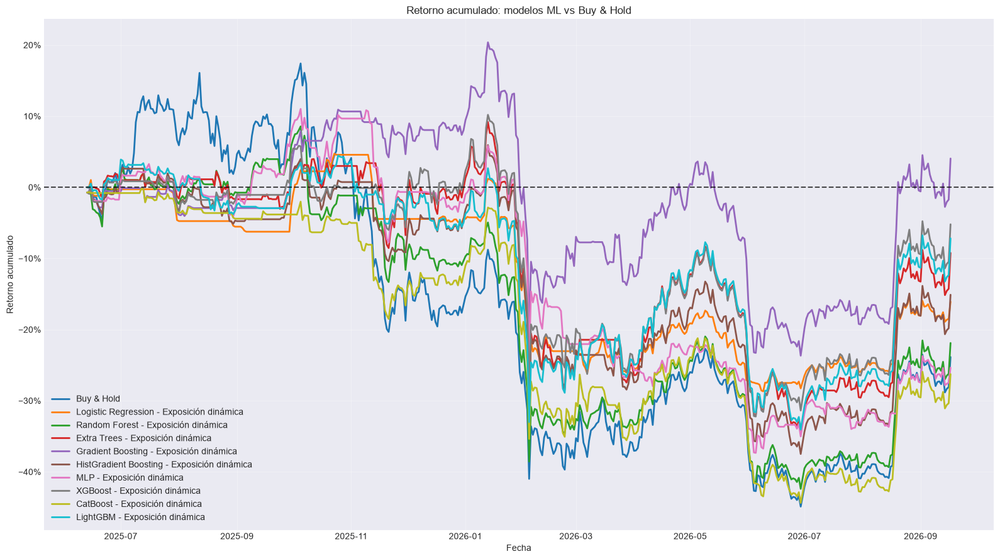

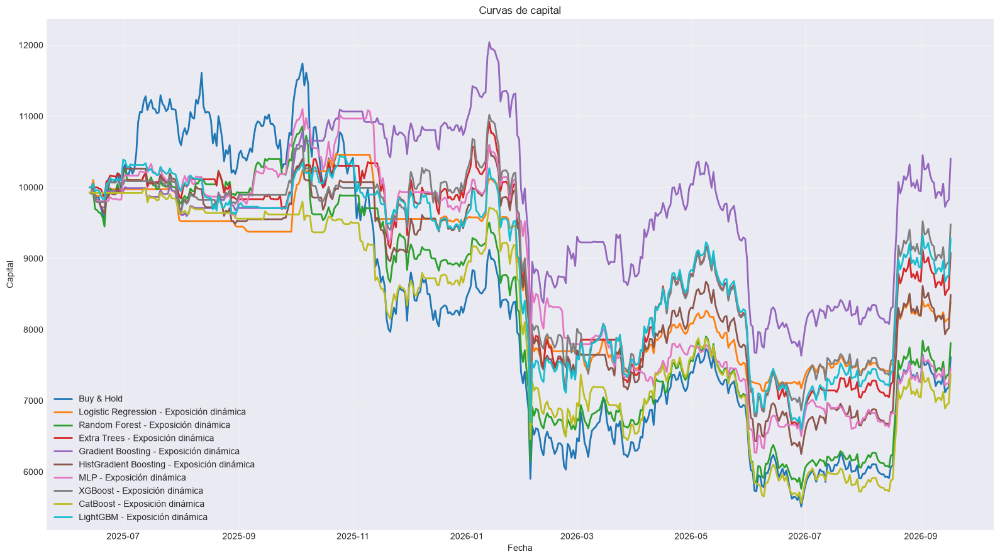

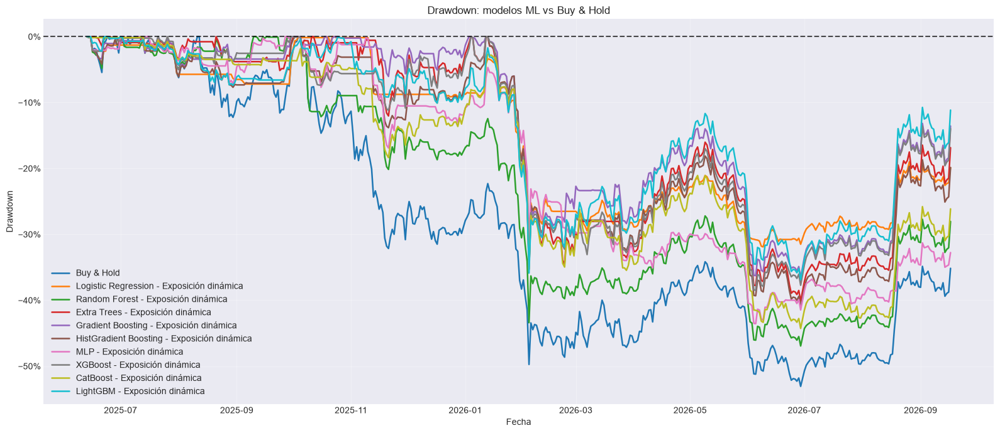


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3269
1,Gradient Boosting,0.3179
2,HistGradient Boosting,0.3032
3,CatBoost,0.3028
4,XGBoost,0.2903
5,LightGBM,0.2880
6,Logistic Regression,0.2819
7,Random Forest,0.2680
8,Extra Trees,0.2548



COMPROBACIONES FINALES
X_dev: 1823
y_dev: 1823
t1_dev: 1823
X_test: 463
y_test: 463
t1_test: 463
test_prices: 463
forward_returns válidos: 462
Logistic Regression shape: (463,) | índice correcto: True
Random Forest shape: (463,) | índice correcto: True
Extra Trees shape: (463,) | índice correcto: True
Gradient Boosting shape: (463,) | índice correcto: True
HistGradient Boosting shape: (463,) | índice correcto: True
MLP shape: (463,) | índice correcto: True
XGBoost shape: (463,) | índice correcto: True
CatBoost shape: (463,) | índice correcto: True
LightGBM shape: (463,) | índice correcto: True

Pipeline terminado correctamente.


In [428]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN   
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo 
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10

# VWAP
VWAP_WINDOW = 30
RECALCULAR_VWAP = True

VWAP_HIGH_COL = "BTC_High"
VWAP_LOW_COL = "BTC_Low"
VWAP_CLOSE_COL = "BTC_Close"
VWAP_VOLUME_COL = "BTC_Volume"

CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_b.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)


# ============================================================
# 3. VWAP PREMIUM CAUSAL
# ============================================================

def construir_vwap_premium_rolling(
    data,
    high_col,
    low_col,
    close_col,
    volume_col,
    window
):
    """
    VWAP rolling causal.

    En t utiliza solamente datos de [t-window+1, t].
    Posteriormente X_all se desplaza una barra.
    """

    required = [
        high_col,
        low_col,
        close_col,
        volume_col
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            "Faltan columnas para VWAP_Premium:\n"
            f"{missing}"
        )

    high = pd.to_numeric(
        data[high_col],
        errors="coerce"
    )

    low = pd.to_numeric(
        data[low_col],
        errors="coerce"
    )

    close = pd.to_numeric(
        data[close_col],
        errors="coerce"
    )

    volume = pd.to_numeric(
        data[volume_col],
        errors="coerce"
    )

    typical_price = (
        high
        +
        low
        +
        close
    ) / 3.0

    price_volume = (
        typical_price
        *
        volume
    )

    rolling_price_volume = (
        price_volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = (
        volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = rolling_volume.replace(
        0,
        np.nan
    )

    rolling_vwap = (
        rolling_price_volume
        /
        rolling_volume
    )

    return (
        close
        /
        rolling_vwap
        -
        1.0
    ).rename(
        "VWAP_Premium"
    )
 

if RECALCULAR_VWAP:

    vwap_columns = [
        VWAP_HIGH_COL,
        VWAP_LOW_COL,
        VWAP_CLOSE_COL,
        VWAP_VOLUME_COL
    ]

    if all(
        col in df.columns
        for col in vwap_columns
    ):

        df["VWAP_Premium"] = (
            construir_vwap_premium_rolling(
                data=df,
                high_col=VWAP_HIGH_COL,
                low_col=VWAP_LOW_COL,
                close_col=VWAP_CLOSE_COL,
                volume_col=VWAP_VOLUME_COL,
                window=VWAP_WINDOW
            )
        )

        print(
            "VWAP_Premium recalculado con rolling causal."
        )

    else:

        print(
            "VWAP_Premium no se recalculó porque faltan "
            "columnas OHLCV. Se usará la columna existente."
        )


# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
    "Bitcoin_log_ret",
    "SP500_log_ret",
    "NASDAQ_log_ret",
    "Euronext100_log_ret",
    "DXY_DollarIndex_log_ret",
    "EUR_USD_log_ret",
    "Gold_log_ret",
    "Crude_Oil_WTI_log_ret",
    "US_10Y_Bond_diff",
    "US_5Y_Bond_diff",
    "VIX_diff",

    "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "VWAP_Premium",

    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
) 

In [436]:
# ============================================================
# PIPELINE AVANZADO DE FINANCIAL MACHINE LEARNING PARA BITCOIN
#
# Incorpora:
#   1. Fractional Differentiation (Preservación de Memoria)
#   2. Sample Uniqueness Weights (López de Prado)
#   3. Triple Barrier Causal (Sin Look-Ahead Bias en Optuna)
#   4. Purged Walk-Forward CV + Embargo
#   5. Asignación Defensiva a Cash (0.0 en Neutral)
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 40
N_TRIALS_MODELO = 35

N_SPLITS = 5
EMBARGO_BARS = 10
TEST_FRACTION = 0.20
FEATURE_LAG = 1

TARGET_NAMES = {0: "Baja", 1: "Neutral", 2: "Sube"}
TARGET_LABELS = [0, 1, 2]

CLOSE_COL = "BTC_Close"

FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005
COST_PER_TURNOVER = FEE_PER_SIDE + SLIPPAGE_PER_SIDE

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. FUNCIONES DE FINANCIAL MACHINE LEARNING (NATIVAS)
# ============================================================

def get_weights_fractional(d, size, threshold=1e-4):
    """Calcula los pesos de la diferenciación fraccional."""
    w = [1.0]
    for k in range(1, size):
        w_k = -w[-1] / k * (d - k + 1)
        if abs(w_k) < threshold:
            break
        w.append(w_k)
    return np.array(w[::-1])

def frac_diff_series(series, d=0.40):
    """Aplica diferenciación fraccional reteniendo memoria y garantizando estacionariedad."""
    weights = get_weights_fractional(d, len(series))
    res = pd.Series(index=series.index, dtype=float)
    weights_len = len(weights)
    
    vals = series.to_numpy()
    for i in range(weights_len, len(series)):
        res.iloc[i] = np.dot(weights, vals[i - weights_len:i])
    return res.bfill()

def calcular_concurrencia_eventos(close_index, t1):
    """Calcula el número de eventos concurrentes por cada punto del tiempo."""
    t1_clean = t1.dropna()
    if t1_clean.empty:
        return pd.Series(1.0, index=close_index)
    
    count = pd.Series(0, index=close_index)
    for idx, t1_val in t1_clean.items():
        count.loc[idx:t1_val] += 1
    return count.replace(0, 1)

def calcular_pesos_unicidad(close_index, t1):
    """Calcula la unicidad media de cada muestra (López de Prado)."""
    concurrencia = calcular_concurrencia_eventos(close_index, t1)
    t1_clean = t1.dropna()
    
    uniqueness = pd.Series(dtype=float)
    for idx, t1_val in t1_clean.items():
        uniqueness.loc[idx] = (1.0 / concurrencia.loc[idx:t1_val]).mean()
    
    uniqueness = uniqueness.reindex(close_index).fillna(1.0)
    # Normalización para mantener la escala del dataset
    return (uniqueness / uniqueness.sum()) * len(uniqueness)


# ============================================================
# 3. CARGA Y PREPROCESAMIENTO DE DATOS
# ============================================================

df = df_b.copy().sort_index()
df = df[~df.index.duplicated(keep="last")]

if not isinstance(df.index, pd.DatetimeIndex):
    raise TypeError("df_b debe tener un DatetimeIndex.")

df[CLOSE_COL] = pd.to_numeric(df[CLOSE_COL], errors="coerce")
df = df.dropna(subset=[CLOSE_COL]).replace([np.inf, -np.inf], np.nan)

# Aplicar Diferenciación Fraccional sobre la serie del precio de cierre
df["BTC_Close_FracDiff"] = frac_diff_series(df[CLOSE_COL], d=0.40)


# ============================================================
# 4. CONFIGURACIÓN DE FEATURES (CON FRACDIFF)
# ============================================================

feature_cols = [
    "BTC_Close_FracDiff",
    "Bitcoin_log_ret", "SP500_log_ret", "NASDAQ_log_ret", "DXY_DollarIndex_log_ret",
    "Gold_log_ret", "US_10Y_Bond_diff", "VIX_diff", "RSI", "MACD", "MACD_Hist",
    "ATR", "NATR", "ADX", "CCI", "OBV"
]

# Filtrar solo features existentes en el DataFrame
feature_cols = [col for col in feature_cols if col in df.columns]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

X_all = df[feature_cols].shift(FEATURE_LAG)


# ============================================================
# 5. TRIPLE BARRIER CAUSAL
# ============================================================

def generar_triple_barrier(data, close_col, pt_multiplier=1.5, sl_multiplier=1.5, max_holding_bars=10, volatility_window=20):
    prices = data[close_col].astype(float)
    dates = data.index
    returns = prices.pct_change()
    volatility = returns.rolling(volatility_window).std().shift(1)

    n = len(data)
    labels = np.full(n, np.nan)
    t1_values = np.full(n, np.datetime64("NaT"), dtype="datetime64[ns]")

    for i in range(n):
        if i + max_holding_bars >= n:
            continue

        current_vol = volatility.iloc[i]
        if not np.isfinite(current_vol) or current_vol <= 0:
            continue

        vertical_end = i + max_holding_bars
        upper_barrier = pt_multiplier * current_vol
        lower_barrier = -sl_multiplier * current_vol

        future_prices = prices.iloc[i + 1 : vertical_end + 1]
        future_returns = (future_prices / prices.iloc[i]) - 1.0

        upper_hits = np.where(future_returns.values >= upper_barrier)[0]
        lower_hits = np.where(future_returns.values <= lower_barrier)[0]

        first_upper = upper_hits[0] if len(upper_hits) > 0 else np.inf
        first_lower = lower_hits[0] if len(lower_hits) > 0 else np.inf

        if first_upper < first_lower:
            hit_pos = i + 1 + int(first_upper)
            labels[i] = 2
            t1_values[i] = dates[hit_pos]
        elif first_lower < first_upper:
            hit_pos = i + 1 + int(first_lower)
            labels[i] = 0
            t1_values[i] = dates[hit_pos]
        else:
            labels[i] = 1
            t1_values[i] = dates[vertical_end]

    return pd.DataFrame({"target": labels, "t1": pd.to_datetime(t1_values)}, index=dates)


# ============================================================
# 6. DIVISIÓN TEMPORAL
# ============================================================

n_total = len(df)
test_start_position = int(n_total * (1.0 - TEST_FRACTION))
test_start_time = df.index[test_start_position]


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD CON EMBARGO
# ============================================================

class PurgedWalkForwardEmbargo:
    def __init__(self, n_splits=5, embargo_bars=10, reference_index=None):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars
        self.reference_index = pd.Index(reference_index)

    def split(self, X, t1):
        n_samples = len(X)
        validation_size = n_samples // (self.n_splits + 1)

        for fold in range(self.n_splits):
            val_start = (fold + 1) * validation_size
            val_end = val_start + validation_size
            if fold == self.n_splits - 1:
                val_end = n_samples

            val_positions = np.arange(val_start, val_end)
            if len(val_positions) == 0:
                continue

            val_start_time = X.index[val_start]
            raw_val_start = self.reference_index.searchsorted(val_start_time, side="left")
            raw_embargo_start = max(0, raw_val_start - self.embargo_bars)
            embargo_start_time = self.reference_index[raw_embargo_start]

            candidate_train_positions = np.where(X.index < embargo_start_time)[0]
            train_positions = []

            for pos in candidate_train_positions:
                event_end = t1.iloc[pos]
                if pd.isna(event_end) or event_end >= val_start_time:
                    continue
                train_positions.append(pos)

            train_positions = np.asarray(train_positions, dtype=int)
            if len(train_positions) > 0:
                yield train_positions, val_positions


# ============================================================
# 8. PREPARACIÓN Y OPTIMIZACIÓN DE TRIPLE BARRIER (SIN LOOK-AHEAD)
# ============================================================

def preparar_datos_limpios(tb_params):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params["pt_multiplier"],
        sl_multiplier=tb_params["sl_multiplier"],
        max_holding_bars=tb_params["max_holding_bars"],
        volatility_window=tb_params["volatility_window"]
    )

    dev_mask = (df.index < test_start_time) & (tb_result["target"].notna()) & (tb_result["t1"] < test_start_time)
    test_mask = (df.index >= test_start_time) & (tb_result["target"].notna())

    X_dev = X_all.loc[dev_mask].copy()
    y_dev = tb_result.loc[dev_mask, "target"].astype(int)
    t1_dev = tb_result.loc[dev_mask, "t1"]

    X_test = X_all.loc[test_mask].copy()
    y_test = tb_result.loc[test_mask, "target"].astype(int)
    t1_test = tb_result.loc[test_mask, "t1"]

    # Muestras ponderadas por unicidad para el dataset de desarrollo
    weights_dev = calcular_pesos_unicidad(X_dev.index, t1_dev)

    return X_dev, y_dev, t1_dev, weights_dev, X_test, y_test, t1_test


def objetivo_triple_barrier(trial):
    params = {
        "pt_multiplier": trial.suggest_float("pt_multiplier", 1.0, 3.0),
        "sl_multiplier": trial.suggest_float("sl_multiplier", 1.0, 3.0),
        "max_holding_bars": trial.suggest_int("max_holding_bars", 5, 30),
        "volatility_window": trial.suggest_int("volatility_window", 10, 60, step=5)
    }
    
    try:
        X_dev, y_dev, t1_dev, _, _, _, _ = preparar_datos_limpios(params)
        if len(X_dev) < 200 or y_dev.nunique() < 3:
            return -1.0
        
        # Balance score sobre desarrollo
        counts = y_dev.value_counts()
        proportions = counts / counts.sum()
        if (proportions < 0.15).any():
            return -1.0
        
        return float(1.0 - np.abs(proportions - (1/3)).mean())
    except Exception:
        return -1.0

print("\nOptimizando Triple Barrier de forma totalmente causal...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study_tb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_tb.optimize(objetivo_triple_barrier, n_trials=N_TRIALS_TRIPLE_BARRIER, show_progress_bar=True)

best_tb_params = study_tb.best_params
print("Mejores parámetros Triple Barrier:", best_tb_params)

X_dev, y_dev, t1_dev, weights_dev, X_test, y_test, t1_test = preparar_datos_limpios(best_tb_params)


# ============================================================
# 9. EVALUACIÓN Y FIT DE MODELOS CON SAMPLE WEIGHTS
# ============================================================

def fit_model_with_weights(pipeline_or_model, X, y, weights):
    """Soporte seguro para pasar sample_weights a Pipelines y modelos base."""
    if isinstance(pipeline_or_model, Pipeline):
        model_step_name = pipeline_or_model.steps[-1][0]
        fit_params = {f"{model_step_name}__sample_weight": weights}
        return pipeline_or_model.fit(X, y, **fit_params)
    else:
        return pipeline_or_model.fit(X, y, sample_weight=weights)

def evaluar_cv_modelo_weighted(model, X, y, t1, weights, splitter):
    scores = []
    for train_idx, val_idx in splitter.split(X, t1):
        X_tr, y_tr, w_tr = X.iloc[train_idx], y.iloc[train_idx], weights.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        if y_tr.nunique() < 3 or y_va.nunique() < 2:
            continue

        model_fold = clone(model)
        fit_model_with_weights(model_fold, X_tr, y_tr, w_tr)
        
        y_pred = model_fold.predict(X_va).reshape(-1)
        if len(np.unique(y_pred)) < 2:
            return 0.0

        scores.append(f1_score(y_va, y_pred, average="macro", zero_division=0))

    return float(np.mean(scores)) if scores else -1.0


# ============================================================
# 10. MODELOS Y OPTIMIZACIÓN
# ============================================================

MODEL_NAMES = [
    "Logistic Regression", "Random Forest", "Extra Trees",
    "Gradient Boosting", "HistGradient Boosting", "MLP",
    "XGBoost", "CatBoost", "LightGBM"
]

def construir_modelo(trial, model_name):
    requires_scaling = False

    if model_name == "Logistic Regression":
        model = LogisticRegression(
            C=trial.suggest_float("C", 1e-3, 10, log=True),
            class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
        )
        requires_scaling = True

    elif model_name == "Random Forest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 15),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 20),
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "Extra Trees":
        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 15),
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int("n_estimators", 50, 300, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            random_state=RANDOM_STATE
        )

    elif model_name == "HistGradient Boosting":
        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int("max_iter", 100, 300, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 8),
            class_weight="balanced", random_state=RANDOM_STATE
        )

    elif model_name == "MLP":
        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical("hidden_layer_sizes", [(16,), (32,), (16, 8)]),
            alpha=trial.suggest_float("alpha", 1e-4, 1.0, log=True),
            max_iter=500, random_state=RANDOM_STATE
        )
        requires_scaling = True

    elif model_name == "XGBoost":
        model = XGBClassifier(
            objective="multi:softprob", num_class=3,
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 6),
            tree_method="hist", eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "CatBoost":
        model = CatBoostClassifier(
            loss_function="MultiClass",
            iterations=trial.suggest_int("iterations", 100, 400, step=50),
            depth=trial.suggest_int("depth", 3, 7),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            verbose=False, random_seed=RANDOM_STATE, thread_count=-1
        )

    elif model_name == "LightGBM":
        model = LGBMClassifier(
            objective="multiclass", num_class=3,
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 6),
            class_weight="balanced", verbosity=-1, n_jobs=-1, random_state=RANDOM_STATE
        )

    steps = [("imputer", SimpleImputer(strategy="median"))]
    if requires_scaling:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))

    return Pipeline(steps)


splitter_model = PurgedWalkForwardEmbargo(n_splits=N_SPLITS, embargo_bars=EMBARGO_BARS, reference_index=df.index)
best_models = {}

for model_name in MODEL_NAMES:
    print("\nOptimizando modelo:", model_name)

    def objective_model(trial, name=model_name):
        m = construir_modelo(trial, name)
        try:
            return evaluar_cv_modelo_weighted(m, X_dev, y_dev, t1_dev, weights_dev, splitter_model)
        except Exception:
            return -1.0

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective_model, n_trials=N_TRIALS_MODELO, show_progress_bar=True)

    if study.best_value > 0:
        best_m = construir_modelo(study.best_trial, model_name)
        best_models[model_name] = {
            "model": best_m,
            "cv_f1_macro": study.best_value,
            "best_params": study.best_params
        }

# ============================================================
# 11. ENTRENAMIENTO FINAL Y BACKTEST DEFENSIVO
# ============================================================

test_prices = df.loc[X_test.index, CLOSE_COL].astype(float)
forward_returns = (test_prices.shift(-1) / test_prices - 1.0).rename("forward_return")

def convertir_prediccion_defensiva(y_pred):
    """
    Regla de preservación de capital:
        Baja (0)    -> 0.0 (0% BTC)
        Neutral (1) -> 0.0 (0% BTC)  <- Protege contra volatilidad sin edge
        Sube (2)    -> 1.0 (100% BTC)
    """
    y_pred_arr = np.asarray(y_pred).reshape(-1)
    exposure = np.where(y_pred_arr == 2, 1.0, 0.0)
    return pd.Series(exposure, index=X_test.index, dtype=float, name="position")


def ejecutar_backtest(strategy_name, position, prices, forward_returns):
    common_idx = prices.index.intersection(forward_returns.dropna().index).intersection(position.index).sort_values()
    p, fr, pos = prices.loc[common_idx], forward_returns.loc[common_idx], position.loc[common_idx].astype(float)

    prev_pos = pos.shift(1).fillna(0.0)
    turnover = (pos - prev_pos).abs()
    gross_ret = pos * fr

    equity_vals, cost_vals, net_ret_vals = [], [], []
    prev_eq = INITIAL_CAPITAL

    for ts in common_idx:
        c_turnover = float(turnover.loc[ts])
        c_gross = float(gross_ret.loc[ts])
        c_cost = prev_eq * c_turnover * COST_PER_TURNOVER

        eq_after_gross = prev_eq * (1.0 + c_gross)
        c_eq = eq_after_gross - c_cost
        c_net = (c_eq / prev_eq - 1.0) if prev_eq > 0 else -1.0

        equity_vals.append(c_eq)
        cost_vals.append(c_cost)
        net_ret_vals.append(c_net)
        prev_eq = c_eq

    equity = pd.Series(equity_vals, index=common_idx)
    costs = pd.Series(cost_vals, index=common_idx)
    net_returns = pd.Series(net_ret_vals, index=common_idx)

    dd = equity / equity.cummax() - 1.0
    r_std = net_returns.std(ddof=1)
    ann_vol = r_std * np.sqrt(365.0)
    sharpe = (net_returns.mean() / r_std * np.sqrt(365.0)) if r_std > 0 else np.nan
    max_dd = float(dd.min())

    return pd.DataFrame({"equity": equity, "drawdown": dd}, index=common_idx), {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": (equity.iloc[-1] / INITIAL_CAPITAL) - 1.0,
        "Volatilidad anual": ann_vol,
        "Sharpe": sharpe,
        "Max Drawdown": max_dd,
        "Exposición media": pos.mean(),
        "Costes acumulados": costs.sum()
    }


# Backtest Benchmark (Buy & Hold)
bh_pos = pd.Series(1.0, index=X_test.index)
res_bh, met_bh = ejecutar_backtest("Buy & Hold", bh_pos, test_prices, forward_returns)

all_metrics = [met_bh]
all_results = {"Buy & Hold": res_bh}

for m_name, m_info in best_models.items():
    final_m = clone(m_info["model"])
    fit_model_with_weights(final_m, X_dev, y_dev, weights_dev)

    y_pred = final_m.predict(X_test).reshape(-1)
    pos_m = convertir_prediccion_defensiva(y_pred)

    strat_name = f"{m_name} - ML"
    res_m, met_m = ejecutar_backtest(strat_name, pos_m, test_prices, forward_returns)

    all_metrics.append(met_m)
    all_results[strat_name] = res_m

metrics_df = pd.DataFrame(all_metrics)

print("\n" + "=" * 120)
print("RESULTADOS DEL BACKTEST OPTIMIZADO (CON SAMPLE WEIGHTS Y FRACDIFF)")
print("=" * 120)

display(
    metrics_df.style.format({
        "Capital final": "${:,.2f}",
        "Retorno total": "{:.2%}",
        "Volatilidad anual": "{:.2%}",
        "Sharpe": "{:.4f}",
        "Max Drawdown": "{:.2%}",
        "Exposición media": "{:.2%}",
        "Costes acumulados": "${:,.2f}"
    })
)

plt.figure(figsize=(15, 7))
for name, res in all_results.items():
    cum_ret = (res["equity"] / INITIAL_CAPITAL) - 1.0
    plt.plot(cum_ret.index, cum_ret.values, label=name, linewidth=2)

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Retorno Acumulado: Modelos de ML con Unicidad y FracDiff vs Buy & Hold")
plt.xlabel("Fecha")
plt.ylabel("Retorno Acumulado")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


Optimizando Triple Barrier de forma totalmente causal...


Best trial: 34. Best value: 0.981412: 100%|██████████| 40/40 [01:41<00:00,  2.54s/it]


Mejores parámetros Triple Barrier: {'pt_multiplier': 2.1477487091550933, 'sl_multiplier': 1.6563119381491367, 'max_holding_bars': 8, 'volatility_window': 20}

Optimizando modelo: Logistic Regression


Best trial: 4. Best value: 0.331628: 100%|██████████| 35/35 [00:06<00:00,  5.38it/s]



Optimizando modelo: Random Forest


Best trial: 19. Best value: 0.308302:  60%|██████    | 21/35 [01:26<00:57,  4.10s/it]


[W 2026-10-29 03:41:52,989] Trial 21 failed with parameters: {'n_estimators': 200, 'max_depth': 8, 'min_samples_leaf': 17} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "c:\Users\reyes\anaconda3\envs\tf_finance\Lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "C:\Users\reyes\AppData\Local\Temp\ipykernel_38652\1573772672.py", line 469, in objective_model
    return evaluar_cv_modelo_weighted(m, X_dev, y_dev, t1_dev, weights_dev, splitter_model)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\reyes\AppData\Local\Temp\ipykernel_38652\1573772672.py", line 355, in evaluar_cv_modelo_weighted
    fit_model_with_weights(model_fold, X_tr, y_tr, w_tr)
  File "C:\Users\reyes\AppData\Local\Temp\ipykernel_38652\1573772672.py", line 341, in fit_model_with_weights
    return pipeline_or_model.fit(X

KeyboardInterrupt: 

Optimizando parámetros de Triple Barrier con métrica predictiva F1...


Best trial: 28. Best value: 0.403698: 100%|██████████| 30/30 [01:28<00:00,  2.94s/it]


Mejores parámetros Triple Barrier: {'pt_multiplier': 1.7706255683234446, 'sl_multiplier': 1.6800410532597092, 'max_holding_bars': 29, 'volatility_window': 45}
Optimizando Logistic Regression...
Optimizando Random Forest...
Optimizando Extra Trees...
Optimizando Gradient Boosting...
Optimizando HistGradient Boosting...
Optimizando MLP...
Optimizando XGBoost...
Optimizando CatBoost...
Optimizando LightGBM...

EVALUACIÓN OUT-OF-SAMPLE (TEST) DE MODELOS CORREGIDOS

Reporte de Clasificación - Logistic Regression:
              precision    recall  f1-score   support

        Baja       0.58      0.49      0.53       215
     Neutral       0.00      0.00      0.00         6
        Sube       0.56      0.67      0.61       225

    accuracy                           0.57       446
   macro avg       0.38      0.39      0.38       446
weighted avg       0.57      0.57      0.56       446


Reporte de Clasificación - Random Forest:
              precision    recall  f1-score   support

       

,Estrategia,Capital Final,Retorno Total,Volatilidad Anual,Sharpe Ratio,Max Drawdown,Exposición Media,Costes Totales
0,Buy & Hold,"$7,285.02",-27.15%,41.96%,-0.3945,-53.06%,100.00%,$15.00
1,Logistic Regression - ML,"$9,348.54",-6.51%,32.71%,-0.0076,-30.67%,59.55%,$170.20
2,Random Forest - ML,"$7,178.19",-28.22%,37.15%,-0.5455,-44.59%,66.74%,$633.18
3,Extra Trees - ML,"$6,363.97",-36.36%,36.55%,-0.8304,-52.75%,65.84%,$431.88
4,Gradient Boosting - ML,"$6,678.06",-33.22%,37.14%,-0.7053,-48.72%,66.29%,$377.84
5,HistGradient Boosting - ML,"$8,160.34",-18.40%,36.94%,-0.2665,-40.72%,68.09%,$317.23
6,MLP - ML,"$9,436.77",-5.63%,36.27%,0.0504,-35.22%,63.82%,$738.51
7,XGBoost - ML,"$6,530.53",-34.69%,37.37%,-0.7477,-50.76%,69.21%,$528.87
8,CatBoost - ML,"$5,968.53",-40.31%,39.95%,-0.8439,-57.73%,89.21%,$470.86
9,LightGBM - ML,"$9,187.84",-8.12%,36.70%,-0.0057,-37.78%,71.91%,$849.61


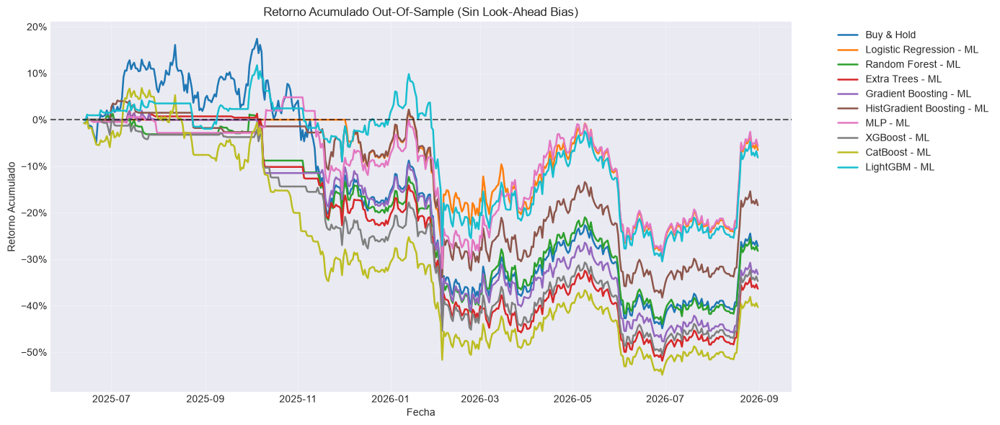

In [437]:
# ============================================================
# PIPELINE RIGUROSO DE FINANCIAL MACHINE LEARNING (BTC)
# Totalmente corregido: Sin Look-Ahead Bias en FracDiff ni Optuna
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display

# ============================================================
# 1. CONFIGURACIÓN GENERAL
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 30
N_TRIALS_MODELO = 30

N_SPLITS = 5
EMBARGO_BARS = 10
TEST_FRACTION = 0.20
FEATURE_LAG = 1

CLOSE_COL = "BTC_Close"

FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005
COST_PER_TURNOVER = FEE_PER_SIDE + SLIPPAGE_PER_SIDE

INITIAL_CAPITAL = 10_000.0

# ============================================================
# 2. FUNCIONES MATEMÁTICAS Y FRACDIFF CAUSAL
# ============================================================

def get_weights_fractional(d, size, threshold=1e-4):
    """Calcula los pesos de la diferenciación fraccional."""
    w = [1.0]
    for k in range(1, size):
        w_k = -w[-1] / k * (d - k + 1)
        if abs(w_k) < threshold:
            break
        w.append(w_k)
    return np.array(w[::-1])

def frac_diff_series(series, d=0.40, threshold=1e-4):
    """
    Diferenciación fraccional causal (López de Prado).
    Sin bfill(), preserva la memoria eliminando el Look-Ahead Bias.
    """
    s = pd.to_numeric(series, errors="coerce").astype(float)
    weights = get_weights_fractional(d, len(s), threshold)
    values = s.to_numpy()
    out = np.full(len(s), np.nan)
    width = len(weights)
    
    for i in range(width - 1, len(s)):
        window = values[i - width + 1 : i + 1]
        if np.isfinite(window).all():
            out[i] = np.dot(weights, window)
            
    return pd.Series(out, index=s.index, name=s.name)

# ============================================================
# 3. UNICIDAD Y SAMPLE WEIGHTS CAUSALES
# ============================================================

def calcular_concurrencia_eventos(full_index, t1):
    """Calcula eventos concurrentes sobre el calendario completo."""
    t1_clean = t1.dropna()
    if t1_clean.empty:
        return pd.Series(1.0, index=full_index)
    
    count = pd.Series(0, index=full_index)
    for idx, t1_val in t1_clean.items():
        count.loc[idx:t1_val] += 1
    return count.replace(0, 1)

def calcular_pesos_unicidad(full_index, X_sub_index, t1):
    """
    Calcula pesos de unicidad limpios, calculando concurrencia sobre
    el calendario global y extrae solo las observaciones seleccionadas.
    """
    concurrencia = calcular_concurrencia_eventos(full_index, t1)
    t1_clean = t1.dropna()
    
    uniqueness = pd.Series(dtype=float)
    for idx in X_sub_index:
        if idx in t1_clean.index:
            t1_val = t1_clean.loc[idx]
            uniqueness.loc[idx] = (1.0 / concurrencia.loc[idx:t1_val]).mean()
        else:
            uniqueness.loc[idx] = 1.0

    uniqueness = uniqueness.reindex(X_sub_index).fillna(1.0)
    return (uniqueness / uniqueness.sum()) * len(uniqueness)

# ============================================================
# 4. CARGA Y PREPROCESAMIENTO DE DATOS
# ============================================================

df = df_b.copy().sort_index()
df = df[~df.index.duplicated(keep="last")]

if not isinstance(df.index, pd.DatetimeIndex):
    raise TypeError("df_b debe contener un DatetimeIndex.")

df[CLOSE_COL] = pd.to_numeric(df[CLOSE_COL], errors="coerce")
df = df.dropna(subset=[CLOSE_COL]).replace([np.inf, -np.inf], np.nan)

# Aplicar FracDiff puramente causal
df["BTC_Close_FracDiff"] = frac_diff_series(df[CLOSE_COL], d=0.40)

feature_cols = [
    "BTC_Close_FracDiff",
    "Bitcoin_log_ret", "SP500_log_ret", "NASDAQ_log_ret", "DXY_DollarIndex_log_ret",
    "Gold_log_ret", "US_10Y_Bond_diff", "VIX_diff", "RSI", "MACD", "MACD_Hist",
    "ATR", "NATR", "ADX", "CCI", "OBV"
]
feature_cols = [col for col in feature_cols if col in df.columns]

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

X_all = df[feature_cols].shift(FEATURE_LAG)

# ============================================================
# 5. TRIPLE BARRIER METHOD (CAUSAL)
# ============================================================

def generar_triple_barrier(data, close_col, pt_multiplier=1.5, sl_multiplier=1.5, max_holding_bars=10, volatility_window=20):
    prices = data[close_col].astype(float)
    dates = data.index
    returns = prices.pct_change()
    volatility = returns.rolling(volatility_window).std().shift(1)

    n = len(data)
    labels = np.full(n, np.nan)
    t1_values = np.full(n, np.datetime64("NaT"), dtype="datetime64[ns]")

    for i in range(n):
        if i + max_holding_bars >= n:
            continue

        current_vol = volatility.iloc[i]
        if not np.isfinite(current_vol) or current_vol <= 0:
            continue

        vertical_end = i + max_holding_bars
        upper_barrier = pt_multiplier * current_vol
        lower_barrier = -sl_multiplier * current_vol

        future_prices = prices.iloc[i + 1 : vertical_end + 1]
        future_returns = (future_prices / prices.iloc[i]) - 1.0

        upper_hits = np.where(future_returns.values >= upper_barrier)[0]
        lower_hits = np.where(future_returns.values <= lower_barrier)[0]

        first_upper = upper_hits[0] if len(upper_hits) > 0 else np.inf
        first_lower = lower_hits[0] if len(lower_hits) > 0 else np.inf

        if first_upper < first_lower:
            hit_pos = i + 1 + int(first_upper)
            labels[i] = 2
            t1_values[i] = dates[hit_pos]
        elif first_lower < first_upper:
            hit_pos = i + 1 + int(first_lower)
            labels[i] = 0
            t1_values[i] = dates[hit_pos]
        else:
            labels[i] = 1
            t1_values[i] = dates[vertical_end]

    return pd.DataFrame({"target": labels, "t1": pd.to_datetime(t1_values)}, index=dates)

# ============================================================
# 6. DIVISIÓN TEMPORAL Y PURGED WALK-FORWARD
# ============================================================

n_total = len(df)
test_start_position = int(n_total * (1.0 - TEST_FRACTION))
test_start_time = df.index[test_start_position]

class PurgedWalkForwardEmbargo:
    def __init__(self, n_splits=5, embargo_bars=10, reference_index=None):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars
        self.reference_index = pd.Index(reference_index)

    def split(self, X, t1):
        n_samples = len(X)
        validation_size = n_samples // (self.n_splits + 1)

        for fold in range(self.n_splits):
            val_start = (fold + 1) * validation_size
            val_end = val_start + validation_size
            if fold == self.n_splits - 1:
                val_end = n_samples

            val_positions = np.arange(val_start, val_end)
            if len(val_positions) == 0:
                continue

            val_start_time = X.index[val_start]
            raw_val_start = self.reference_index.searchsorted(val_start_time, side="left")
            raw_embargo_start = max(0, raw_val_start - self.embargo_bars)
            embargo_start_time = self.reference_index[raw_embargo_start]

            candidate_train_positions = np.where(X.index < embargo_start_time)[0]
            train_positions = []

            for pos in candidate_train_positions:
                event_end = t1.iloc[pos]
                if pd.isna(event_end) or event_end >= val_start_time:
                    continue
                train_positions.append(pos)

            train_positions = np.asarray(train_positions, dtype=int)
            if len(train_positions) > 0:
                yield train_positions, val_positions

# ============================================================
# 7. OPTIMIZACIÓN DE TRIPLE BARRIER BASADA EN UTILIDAD
# ============================================================

def preparar_datos_desarrollo(tb_params):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params["pt_multiplier"],
        sl_multiplier=tb_params["sl_multiplier"],
        max_holding_bars=tb_params["max_holding_bars"],
        volatility_window=tb_params["volatility_window"]
    )

    dev_mask = (df.index < test_start_time) & (tb_result["target"].notna()) & (tb_result["t1"] < test_start_time)
    
    X_dev = X_all.loc[dev_mask].dropna().copy()
    valid_idx = X_dev.index
    
    y_dev = tb_result.loc[valid_idx, "target"].astype(int)
    t1_dev = tb_result.loc[valid_idx, "t1"]

    weights_dev = calcular_pesos_unicidad(df.index, valid_idx, t1_dev)

    return X_dev, y_dev, t1_dev, weights_dev, tb_result

def objetivo_triple_barrier(trial):
    params = {
        "pt_multiplier": trial.suggest_float("pt_multiplier", 1.0, 3.0),
        "sl_multiplier": trial.suggest_float("sl_multiplier", 1.0, 3.0),
        "max_holding_bars": trial.suggest_int("max_holding_bars", 5, 30),
        "volatility_window": trial.suggest_int("volatility_window", 10, 60, step=5)
    }
    
    try:
        X_dev, y_dev, t1_dev, weights_dev, _ = preparar_datos_desarrollo(params)
        if len(X_dev) < 300 or y_dev.nunique() < 3:
            return -1.0
        
        # Modelo base ligero para medir utilidad de las etiquetas
        clf = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", RandomForestClassifier(n_estimators=50, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1))
        ])
        
        splitter = PurgedWalkForwardEmbargo(n_splits=3, embargo_bars=EMBARGO_BARS, reference_index=df.index)
        scores = []
        
        for tr_idx, va_idx in splitter.split(X_dev, t1_dev):
            X_tr, y_tr, w_tr = X_dev.iloc[tr_idx], y_dev.iloc[tr_idx], weights_dev.iloc[tr_idx]
            X_va, y_va = X_dev.iloc[va_idx], y_dev.iloc[va_idx]
            
            if y_tr.nunique() < 3 or y_va.nunique() < 2:
                continue
                
            clf.fit(X_tr, y_tr, model__sample_weight=w_tr)
            preds = clf.predict(X_va)
            scores.append(f1_score(y_va, preds, average="macro", zero_division=0))
            
        return float(np.mean(scores)) if scores else -1.0
    except Exception as e:
        return -1.0

print("Optimizando parámetros de Triple Barrier con métrica predictiva F1...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
study_tb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_tb.optimize(objetivo_triple_barrier, n_trials=N_TRIALS_TRIPLE_BARRIER, show_progress_bar=True)

best_tb_params = study_tb.best_params
print("Mejores parámetros Triple Barrier:", best_tb_params)

# Generar dataset definitivo de Desarrollo y Test con los mejores parámetros
X_dev, y_dev, t1_dev, weights_dev, tb_result_best = preparar_datos_desarrollo(best_tb_params)

test_mask = (df.index >= test_start_time) & (tb_result_best["target"].notna())
X_test = X_all.loc[test_mask].dropna().copy()
test_valid_idx = X_test.index
y_test = tb_result_best.loc[test_valid_idx, "target"].astype(int)
t1_test = tb_result_best.loc[test_valid_idx, "t1"]

# ============================================================
# 8. ENTRENAMIENTO DE MODELOS CON WEIGHTS CAUSALES
# ============================================================

def fit_model_with_weights(pipeline_or_model, X, y, weights):
    if isinstance(pipeline_or_model, Pipeline):
        model_step_name = pipeline_or_model.steps[-1][0]
        fit_params = {f"{model_step_name}__sample_weight": weights}
        return pipeline_or_model.fit(X, y, **fit_params)
    else:
        return pipeline_or_model.fit(X, y, sample_weight=weights)

def evaluar_cv_modelo_weighted(model, X, y, t1, weights, splitter):
    scores = []
    for train_idx, val_idx in splitter.split(X, t1):
        X_tr, y_tr, w_tr = X.iloc[train_idx], y.iloc[train_idx], weights.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

        if y_tr.nunique() < 3 or y_va.nunique() < 2:
            continue

        model_fold = clone(model)
        fit_model_with_weights(model_fold, X_tr, y_tr, w_tr)
        
        y_pred = model_fold.predict(X_va).reshape(-1)
        scores.append(f1_score(y_va, y_pred, average="macro", zero_division=0))

    return float(np.mean(scores)) if scores else -1.0

# ============================================================
# 9. OPTIMIZACIÓN DE MODELOS EN OPTUNA
# ============================================================

MODEL_NAMES = [
    "Logistic Regression", "Random Forest", "Extra Trees",
    "Gradient Boosting", "HistGradient Boosting", "MLP",
    "XGBoost", "CatBoost", "LightGBM"
]

def construir_modelo(trial, model_name):
    requires_scaling = False

    if model_name == "Logistic Regression":
        model = LogisticRegression(
            C=trial.suggest_float("C", 1e-3, 10, log=True),
            class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
        )
        requires_scaling = True

    elif model_name == "Random Forest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 12),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 2, 15),
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "Extra Trees":
        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            max_depth=trial.suggest_int("max_depth", 3, 12),
            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int("n_estimators", 50, 200, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            random_state=RANDOM_STATE
        )

    elif model_name == "HistGradient Boosting":
        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int("max_iter", 100, 200, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 6),
            random_state=RANDOM_STATE
        )

    elif model_name == "MLP":
        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical("hidden_layer_sizes", [(16,), (32,), (16, 8)]),
            alpha=trial.suggest_float("alpha", 1e-4, 1.0, log=True),
            max_iter=500, random_state=RANDOM_STATE
        )
        requires_scaling = True

    elif model_name == "XGBoost":
        model = XGBClassifier(
            objective="multi:softprob", num_class=3,
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 6),
            tree_method="hist", eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE
        )

    elif model_name == "CatBoost":
        model = CatBoostClassifier(
            loss_function="MultiClass",
            iterations=trial.suggest_int("iterations", 100, 300, step=50),
            depth=trial.suggest_int("depth", 3, 6),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            verbose=False, random_seed=RANDOM_STATE, thread_count=-1
        )

    elif model_name == "LightGBM":
        model = LGBMClassifier(
            objective="multiclass", num_class=3,
            n_estimators=trial.suggest_int("n_estimators", 100, 300, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
            max_depth=trial.suggest_int("max_depth", 2, 6),
            class_weight="balanced", verbosity=-1, n_jobs=-1, random_state=RANDOM_STATE
        )

    steps = [("imputer", SimpleImputer(strategy="median"))]
    if requires_scaling:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))

    return Pipeline(steps)

splitter_model = PurgedWalkForwardEmbargo(n_splits=N_SPLITS, embargo_bars=EMBARGO_BARS, reference_index=df.index)
best_models = {}

for model_name in MODEL_NAMES:
    print(f"Optimizando {model_name}...")

    def objective_model(trial, name=model_name):
        m = construir_modelo(trial, name)
        try:
            return evaluar_cv_modelo_weighted(m, X_dev, y_dev, t1_dev, weights_dev, splitter_model)
        except Exception:
            return -1.0

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective_model, n_trials=N_TRIALS_MODELO, show_progress_bar=False)

    if study.best_value > 0:
        best_m = construir_modelo(study.best_trial, model_name)
        best_models[model_name] = {
            "model": best_m,
            "cv_f1_macro": study.best_value,
            "best_params": study.best_params
        }

# ============================================================
# 10. BACKTEST RIGUROSO CON ALINEACIÓN TEMPORAL PERFECTA
# ============================================================

test_prices = df.loc[X_test.index, CLOSE_COL].astype(float)
forward_returns = (test_prices.shift(-1) / test_prices - 1.0).rename("forward_return")

# Detección dinámica de períodos anuales según frecuencia de datos
time_diffs = pd.Series(X_test.index).diff().dropna()
median_seconds = time_diffs.dt.total_seconds().median()
periods_per_year = 365.0 if median_seconds >= 86400 else (365.0 * 86400 / median_seconds)

def convertir_prediccion_defensiva(y_pred):
    """Baja (0) -> Cash (0), Neutral (1) -> Cash (0), Sube (2) -> Long (1)"""
    y_pred_arr = np.asarray(y_pred).reshape(-1)
    exposure = np.where(y_pred_arr == 2, 1.0, 0.0)
    return pd.Series(exposure, index=X_test.index, dtype=float, name="position")

def ejecutar_backtest_causal(strategy_name, position, prices, forward_returns):
    common_idx = prices.index.intersection(forward_returns.dropna().index).intersection(position.index).sort_values()
    
    p = prices.loc[common_idx]
    fr = forward_returns.loc[common_idx]
    pos = position.loc[common_idx].astype(float)

    # ALINEACIÓN CAUSAL: La posición decidida en t se aplica al rendimiento t -> t+1
    prev_pos = pos.shift(1).fillna(0.0)
    turnover = (pos - prev_pos).abs()
    gross_ret = pos * fr

    equity_vals, costs_vals = [], []
    prev_eq = INITIAL_CAPITAL

    for ts in common_idx:
        c_turnover = float(turnover.loc[ts])
        c_gross = float(gross_ret.loc[ts])
        
        # El costo de rotación se cobra sobre el saldo disponible antes de la rentabilidad
        c_cost = prev_eq * c_turnover * COST_PER_TURNOVER
        eq_after_gross = (prev_eq - c_cost) * (1.0 + c_gross)
        
        equity_vals.append(eq_after_gross)
        costs_vals.append(c_cost)
        prev_eq = eq_after_gross

    equity = pd.Series(equity_vals, index=common_idx)
    costs = pd.Series(costs_vals, index=common_idx)
    net_returns = equity.pct_change().fillna(0.0)

    dd = equity / equity.cummax() - 1.0
    r_std = net_returns.std(ddof=1)
    ann_vol = r_std * np.sqrt(periods_per_year)
    sharpe = (net_returns.mean() / r_std * np.sqrt(periods_per_year)) if r_std > 0 else np.nan

    return pd.DataFrame({"equity": equity, "drawdown": dd}, index=common_idx), {
        "Estrategia": strategy_name,
        "Capital Final": equity.iloc[-1],
        "Retorno Total": (equity.iloc[-1] / INITIAL_CAPITAL) - 1.0,
        "Volatilidad Anual": ann_vol,
        "Sharpe Ratio": sharpe,
        "Max Drawdown": float(dd.min()),
        "Exposición Media": pos.mean(),
        "Costes Totales": costs.sum()
    }

# Benchmark Buy & Hold
bh_pos = pd.Series(1.0, index=X_test.index)
res_bh, met_bh = ejecutar_backtest_causal("Buy & Hold", bh_pos, test_prices, forward_returns)

all_metrics = [met_bh]
all_results = {"Buy & Hold": res_bh}

print("\n" + "="*80)
print("EVALUACIÓN OUT-OF-SAMPLE (TEST) DE MODELOS CORREGIDOS")
print("="*80)

for m_name, m_info in best_models.items():
    final_m = clone(m_info["model"])
    fit_model_with_weights(final_m, X_dev, y_dev, weights_dev)

    y_pred = final_m.predict(X_test).reshape(-1)
    
    # Métricas de Clasificación
    print(f"\nReporte de Clasificación - {m_name}:")
    print(classification_report(y_test, y_pred, target_names=["Baja", "Neutral", "Sube"], zero_division=0))
    
    pos_m = convertir_prediccion_defensiva(y_pred)
    res_m, met_m = ejecutar_backtest_causal(f"{m_name} - ML", pos_m, test_prices, forward_returns)

    all_metrics.append(met_m)
    all_results[f"{m_name} - ML"] = res_m

metrics_df = pd.DataFrame(all_metrics)

display(
    metrics_df.style.format({
        "Capital Final": "${:,.2f}",
        "Retorno Total": "{:.2%}",
        "Volatilidad Anual": "{:.2%}",
        "Sharpe Ratio": "{:.4f}",
        "Max Drawdown": "{:.2%}",
        "Exposición Media": "{:.2%}",
        "Costes Totales": "${:,.2f}"
    })
)

# Gráfica de Equities Out-of-Sample
plt.figure(figsize=(14, 6))
for name, res in all_results.items():
    cum_ret = (res["equity"] / INITIAL_CAPITAL) - 1.0
    plt.plot(cum_ret.index, cum_ret.values, label=name, linewidth=1.8)

plt.axhline(0.0, color="black", linestyle="--", alpha=0.6)
plt.title("Retorno Acumulado Out-Of-Sample (Sin Look-Ahead Bias)")
plt.xlabel("Fecha")
plt.ylabel("Retorno Acumulado")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [430]:
# ============================================================
# ESTRATEGIA FINAL BTC
#
# Ensemble:
#     MLP
#     Gradient Boosting
#     HistGradient Boosting
#
# Reglas:
#
#     Señal alcista fuerte -> 100 % BTC
#     Señal bajista fuerte -> 0 % BTC
#     Sin ventaja clara     -> 50 % BTC
#
# Comparación:
#
#     Ensemble vs Buy & Hold
#
# Requiere que ya existan:
#
#     best_models
#     X_dev
#     y_dev
#     X_test
#     df
#     CLOSE_COL
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

INITIAL_CAPITAL = 10_000.0

# Costes estimados para spot:
#
# Comisión: 0.10 %
# Slippage: 0.05 %
# Coste total por cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

# Modelos seleccionados por F1 de validación.
# No se seleccionan por el resultado del test.
ENSEMBLE_MODELS = [
    "MLP",
    "Gradient Boosting",
    "HistGradient Boosting"
]

# Umbral mínimo de probabilidad
MIN_PROBA_UP = 0.40
MIN_PROBA_DOWN = 0.40

# Ventaja mínima sobre la segunda clase
MIN_EDGE = 0.05

# Retraso de ejecución:
#
# raw_position[t] se ejecuta en t+1.
EXECUTION_LAG = 1

TARGET_LABELS = [0, 1, 2]

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}


# ============================================================
# 2. COMPROBACIONES
# ============================================================

required_objects = [
    "best_models",
    "X_dev",
    "y_dev",
    "X_test",
    "df",
    "CLOSE_COL"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Faltan objetos necesarios:\n"
        f"{missing_objects}"
    )

available_models = [
    model_name
    for model_name in ENSEMBLE_MODELS
    if model_name in best_models
]

if not available_models:
    raise RuntimeError(
        "Ninguno de los modelos del ensemble está disponible."
    )

if not X_test.index.is_monotonic_increasing:
    raise ValueError(
        "X_test no está ordenado cronológicamente."
    )

if X_test.index.has_duplicates:
    raise ValueError(
        "X_test contiene índices duplicados."
    )

print(
    "Modelos incluidos:",
    available_models
)


# ============================================================
# 3. FUNCIONES DE PROBABILIDADES
# ============================================================

def obtener_probabilidades_ordenadas(
    model,
    X
):
    """
    Devuelve probabilidades en el orden fijo:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if not hasattr(
        model,
        "predict_proba"
    ):
        raise ValueError(
            "El modelo no tiene predict_proba()."
        )

    raw_proba = model.predict_proba(
        X
    )

    raw_proba = np.asarray(
        raw_proba
    )

    if raw_proba.ndim != 2:
        raise ValueError(
            "Las probabilidades deben ser una matriz 2D."
        )

    if raw_proba.shape[0] != len(X):
        raise ValueError(
            "El número de probabilidades no coincide con X."
        )

    model_classes = np.asarray(
        model.classes_
    ).astype(int)

    ordered_proba = np.zeros(
        (
            len(X),
            len(TARGET_LABELS)
        ),
        dtype=float
    )

    for source_column, class_label in enumerate(
        model_classes
    ):

        if class_label not in TARGET_LABELS:
            continue

        target_column = TARGET_LABELS.index(
            int(class_label)
        )

        ordered_proba[
            :,
            target_column
        ] = raw_proba[
            :,
            source_column
        ]

    row_sums = ordered_proba.sum(
        axis=1
    )

    if np.any(
        row_sums <= 0
    ):
        raise ValueError(
            "Existen filas con suma de probabilidades igual a cero."
        )

    ordered_proba = (
        ordered_proba
        /
        row_sums.reshape(
            -1,
            1
        )
    )

    return pd.DataFrame(
        ordered_proba,
        index=X.index,
        columns=[
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube"
        ]
    )


# ============================================================
# 4. ENTRENAMIENTO Y ENSEMBLE
# ============================================================

model_probabilities = {}
final_models = {}

for model_name in available_models:

    print(
        "\nEntrenando modelo:",
        model_name
    )

    model = clone(
        best_models[
            model_name
        ]["model"]
    )

    # Entrenamiento exclusivamente con desarrollo
    model.fit(
        X_dev,
        y_dev
    )

    probabilities = obtener_probabilidades_ordenadas(
        model=model,
        X=X_test
    )

    final_models[
        model_name
    ] = model

    model_probabilities[
        model_name
    ] = probabilities


# Promedio simple de probabilidades
ensemble_probabilities = pd.concat(
    [
        model_probabilities[
            model_name
        ]
        for model_name in available_models
    ],
    axis=1,
    keys=available_models
).groupby(
    level=1,
    axis=1
).mean()

ensemble_probabilities = ensemble_probabilities[
    [
        "prob_Baja",
        "prob_Neutral",
        "prob_Sube"
    ]
]

# Normalización defensiva
probability_sum = ensemble_probabilities.sum(
    axis=1
)

ensemble_probabilities = (
    ensemble_probabilities
    .div(
        probability_sum,
        axis=0
    )
)

if not ensemble_probabilities.index.equals(
    X_test.index
):
    raise ValueError(
        "Las probabilidades del ensemble no están alineadas con X_test."
    )


# ============================================================
# 5. CONSTRUCCIÓN DE LA SEÑAL
# ============================================================

prob_baja = ensemble_probabilities[
    "prob_Baja"
]

prob_neutral = ensemble_probabilities[
    "prob_Neutral"
]

prob_sube = ensemble_probabilities[
    "prob_Sube"
]

# Segunda mejor probabilidad para cada dirección
second_best_for_up = np.maximum(
    prob_baja,
    prob_neutral
)

second_best_for_down = np.maximum(
    prob_sube,
    prob_neutral
)

up_edge = (
    prob_sube
    -
    second_best_for_up
)

down_edge = (
    prob_baja
    -
    second_best_for_down
)

# Señal sin retraso:
#
#     1.0 -> 100 % BTC
#     0.5 -> 50 % BTC
#     0.0 -> 0 % BTC
raw_position = np.select(
    [
        (
            (prob_sube >= MIN_PROBA_UP)
            &
            (up_edge >= MIN_EDGE)
        ),

        (
            (prob_baja >= MIN_PROBA_DOWN)
            &
            (down_edge >= MIN_EDGE)
        )
    ],
    [
        1.0,
        0.0
    ],
    default=0.5
)

raw_position = pd.Series(
    raw_position,
    index=X_test.index,
    dtype=float,
    name="raw_position"
)

# Posición realmente utilizada en el siguiente periodo
position = (
    raw_position
    .shift(
        EXECUTION_LAG
    )
    .fillna(0.5)
    .astype(float)
    .rename(
        "position"
    )
)

# Predicción de clase dominante, solo como diagnóstico
prediction = (
    ensemble_probabilities
    .to_numpy()
    .argmax(
        axis=1
    )
)

prediction = pd.Series(
    prediction,
    index=X_test.index,
    name="prediction"
).astype(int)

# Tabla de señales
signal_table = ensemble_probabilities.copy()

signal_table["up_edge"] = up_edge
signal_table["down_edge"] = down_edge
signal_table["prediction"] = prediction
signal_table["prediction_name"] = (
    signal_table["prediction"]
    .map(TARGET_NAMES)
)
signal_table["raw_position"] = raw_position
signal_table["position"] = position

signal_table["signal_reason"] = np.select(
    [
        signal_table["raw_position"] == 1.0,
        signal_table["raw_position"] == 0.0,
        signal_table["raw_position"] == 0.5
    ],
    [
        "Señal alcista",
        "Señal bajista",
        "Neutral / sin ventaja"
    ],
    default="Desconocida"
)

print(
    "\nDistribución de señales sin retraso:"
)

print(
    raw_position
    .value_counts()
    .sort_index()
    .rename(
        index={
            0.0: "0% BTC",
            0.5: "50% BTC",
            1.0: "100% BTC"
        }
    )
)

print(
    "\nExposición media sin retraso:",
    f"{raw_position.mean():.2%}"
)

print(
    "Exposición media ejecutada:",
    f"{position.mean():.2%}"
)

print(
    "\nPrimeras señales:"
)

display(
    signal_table.head(20)
)


# ============================================================
# 6. PRECIOS Y RETORNOS
# ============================================================

test_prices = (
    df.loc[
        X_test.index,
        CLOSE_COL
    ]
    .astype(float)
    .rename(
        "price"
    )
)

test_prices = test_prices.replace(
    [np.inf, -np.inf],
    np.nan
)

if test_prices.isna().any():
    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en el test:\n"
        f"{invalid_dates}"
    )

if not test_prices.index.equals(
    X_test.index
):
    raise ValueError(
        "Los precios y X_test no están alineados."
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


# ============================================================
# 7. PERIODOS ANUALIZADOS
# ============================================================

def estimar_periodos_por_anio(
    index
):
    datetime_index = pd.DatetimeIndex(
        index
    )

    deltas = (
        pd.Series(
            datetime_index
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(
            median_days
        )
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 8. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    Los costes se calculan sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay observaciones comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: precios, retornos y posición "
            "no están alineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_values = []
    net_return_values = []

    previous_equity = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        current_cost = (
            previous_equity
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_before_cost = (
            previous_equity
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        current_equity = (
            equity_before_cost
            -
            current_cost
        )

        if previous_equity > 0:

            current_net_return = (
                current_equity
                /
                previous_equity
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            current_equity
        )

        cost_values.append(
            current_cost
        )

        net_return_values.append(
            current_net_return
        )

        previous_equity = current_equity

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    costs = pd.Series(
        cost_values,
        index=common_index,
        name="costs"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    downside_returns = net_returns[
        net_returns < 0
    ]

    downside_std = downside_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "costs": costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),
        "CAGR": cagr,
        "Volatilidad anualizada": annualized_volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Máximo drawdown": max_drawdown,
        "Calmar": calmar,
        "Win rate": (
            net_returns > 0
        ).mean(),
        "Exposición media": position.mean(),
        "Costes acumulados": costs.sum(),
        "Turnover acumulado": turnover.sum(),
        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


# ============================================================
# 9. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)


# ============================================================
# 10. BACKTEST DE LA ESTRATEGIA
# ============================================================

ensemble_result, ensemble_metrics = (
    ejecutar_backtest(
        strategy_name="Ensemble dinámico",
        position=position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result,
    "Ensemble dinámico": ensemble_result
}

metrics_table = pd.DataFrame(
    [
        buy_hold_metrics,
        ensemble_metrics
    ]
)


# ============================================================
# 11. MÉTRICAS DE RENTABILIDAD Y RIESGO
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 130
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 12. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

ensemble_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Ensemble dinámico"
].iloc[0]

comparison_table = pd.DataFrame(
    [
        {
            "Métrica": "Retorno total",
            "Ensemble": ensemble_row[
                "Retorno total"
            ],
            "Buy & Hold": buy_hold_row[
                "Retorno total"
            ],
            "Diferencia": (
                ensemble_row[
                    "Retorno total"
                ]
                -
                buy_hold_row[
                    "Retorno total"
                ]
            )
        },

        {
            "Métrica": "CAGR",
            "Ensemble": ensemble_row[
                "CAGR"
            ],
            "Buy & Hold": buy_hold_row[
                "CAGR"
            ],
            "Diferencia": (
                ensemble_row[
                    "CAGR"
                ]
                -
                buy_hold_row[
                    "CAGR"
                ]
            )
        },

        {
            "Métrica": "Sharpe",
            "Ensemble": ensemble_row[
                "Sharpe"
            ],
            "Buy & Hold": buy_hold_row[
                "Sharpe"
            ],
            "Diferencia": (
                ensemble_row[
                    "Sharpe"
                ]
                -
                buy_hold_row[
                    "Sharpe"
                ]
            )
        },

        {
            "Métrica": "Máximo drawdown",
            "Ensemble": ensemble_row[
                "Máximo drawdown"
            ],
            "Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],
            "Diferencia": (
                ensemble_row[
                    "Máximo drawdown"
                ]
                -
                buy_hold_row[
                    "Máximo drawdown"
                ]
            )
        },

        {
            "Métrica": "Costes acumulados",
            "Ensemble": ensemble_row[
                "Costes acumulados"
            ],
            "Buy & Hold": buy_hold_row[
                "Costes acumulados"
            ],
            "Diferencia": (
                ensemble_row[
                    "Costes acumulados"
                ]
                -
                buy_hold_row[
                    "Costes acumulados"
                ]
            )
        }
    ]
)

print(
    "\n" + "=" * 130
)

print(
    "COMPARACIÓN ENSEMBLE VS BUY & HOLD"
)

print(
    "=" * 130
)

display(
    comparison_table.style.format(
        {
            "Ensemble": "{:.4f}",
            "Buy & Hold": "{:.4f}",
            "Diferencia": "{:.4f}"
        }
    )
)


# ============================================================
# 13. RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(15, 8)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. DRAWDOWN
# ============================================================

plt.figure(
    figsize=(15, 6)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 15. TABLA DE SEÑALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "ÚLTIMAS SEÑALES"
)

print(
    "=" * 100
)

display(
    signal_table[
        [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube",
            "up_edge",
            "down_edge",
            "prediction",
            "prediction_name",
            "raw_position",
            "position",
            "signal_reason"
        ]
    ].tail(30)
)


# ============================================================
# 16. RESUMEN
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "RESUMEN"
)

print(
    "=" * 100
)

print(
    "Umbral alcista:",
    MIN_PROBA_UP
)

print(
    "Umbral bajista:",
    MIN_PROBA_DOWN
)

print(
    "Ventaja mínima:",
    MIN_EDGE
)

print(
    "Retraso de ejecución:",
    EXECUTION_LAG
)

print(
    "Modelos:",
    available_models
)

print(
    "Retorno Ensemble:",
    f"{ensemble_row['Retorno total']:.2%}"
)

print(
    "Retorno Buy & Hold:",
    f"{buy_hold_row['Retorno total']:.2%}"
)

print(
    "Sharpe Ensemble:",
    f"{ensemble_row['Sharpe']:.4f}"
)

print(
    "Sharpe Buy & Hold:",
    f"{buy_hold_row['Sharpe']:.4f}"
)

print(
    "Drawdown Ensemble:",
    f"{ensemble_row['Máximo drawdown']:.2%}"
)

print(
    "Drawdown Buy & Hold:",
    f"{buy_hold_row['Máximo drawdown']:.2%}"
)

Modelos incluidos: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']

Entrenando modelo: MLP

Entrenando modelo: Gradient Boosting

Entrenando modelo: HistGradient Boosting


TypeError: DataFrame.groupby() got an unexpected keyword argument 'axis'

Modelos incluidos: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']

Entrenando modelo: MLP

Entrenando modelo: Gradient Boosting

Entrenando modelo: HistGradient Boosting

Distribución de señales sin retraso:
raw_position
0% BTC      114
50% BTC     131
100% BTC    218
Name: count, dtype: int64

Exposición media sin retraso: 61.23%
Exposición media ejecutada: 61.12%

Primeras señales:


,prob_Baja,prob_Neutral,prob_Sube,up_edge,down_edge,prediction,prediction_name,raw_position,position,signal_reason
Date,,,,,,,,,,
2025-06-13,0.467165,0.132305,0.400530,-0.066635,0.066635,0,Baja,0.0,0.5,Señal bajista
2025-06-14,0.400664,0.068293,0.531043,0.130379,-0.130379,2,Sube,1.0,0.0,Señal alcista
2025-06-15,0.178383,0.287291,0.534327,0.247036,-0.355944,2,Sube,1.0,1.0,Señal alcista
2025-06-16,0.224299,0.229294,0.546407,0.317113,-0.322109,2,Sube,1.0,1.0,Señal alcista
2025-06-17,0.576603,0.243107,0.180290,-0.396314,0.333496,0,Baja,0.0,1.0,Señal bajista
2025-06-18,0.447538,0.198830,0.353632,-0.093905,0.093905,0,Baja,0.0,0.0,Señal bajista
2025-06-19,0.356445,0.521776,0.121778,-0.399998,-0.165331,1,Neutral,0.5,0.0,Neutral / sin ventaja
2025-06-20,0.514115,0.351952,0.133933,-0.380183,0.162163,0,Baja,0.0,0.5,Señal bajista
2025-06-21,0.524104,0.353330,0.122567,-0.401537,0.170774,0,Baja,0.0,0.0,Señal bajista



Periodos por año: 365.0

MÉTRICAS DE RENTABILIDAD Y RIESGO


,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,625.67",-23.74%,-18.94%,42.03%,-0.2991,-0.4247,-53.06%,-0.3570,48.92%,100.00%,$0.00,0.00,0
1,Ensemble dinámico,"$10,017.52",0.18%,0.43%,34.04%,0.1745,0.2047,-35.94%,0.0120,37.45%,61.04%,$781.67,55.00,97



COMPARACIÓN ENSEMBLE VS BUY & HOLD


,Métrica,Ensemble,Buy & Hold,Diferencia
0,Retorno total,0.0018,-0.2374,0.2392
1,CAGR,0.0043,-0.1894,0.1937
2,Sharpe,0.1745,-0.2991,0.4736
3,Máximo drawdown,-0.3594,-0.5306,0.1712
4,Costes acumulados,781.6661,0.0000,781.6661


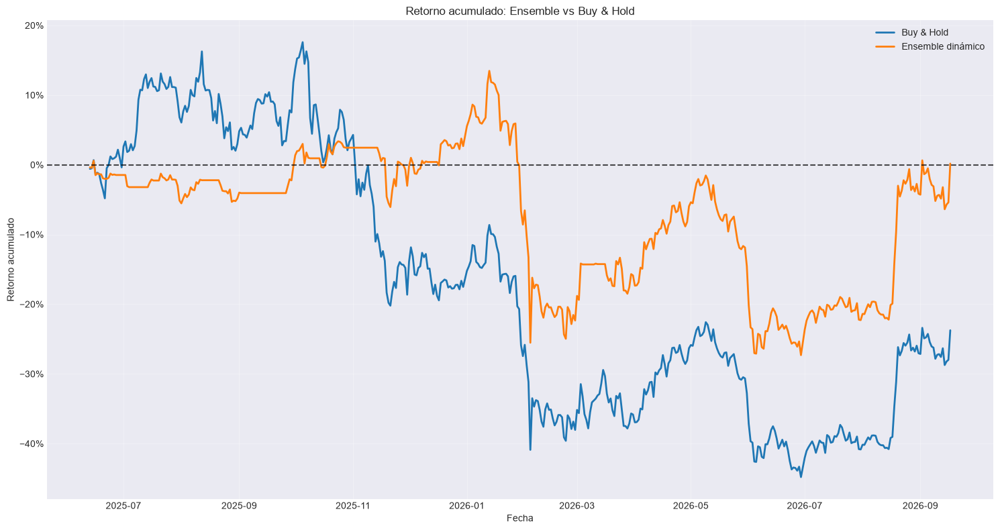

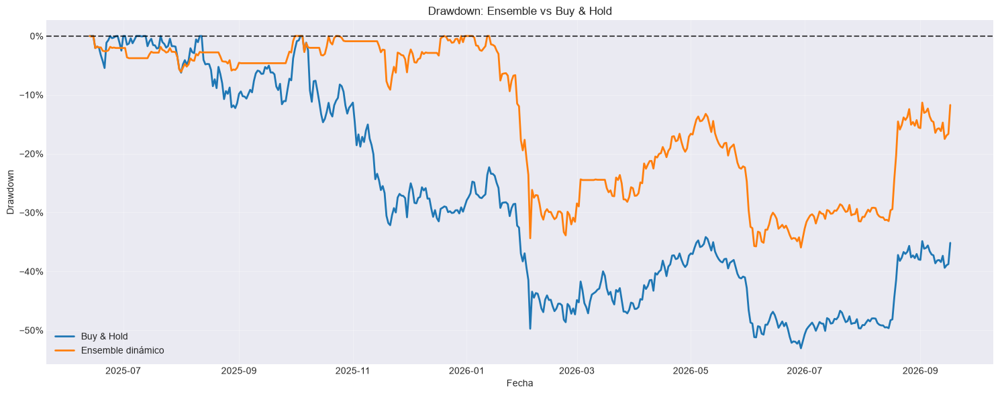


ÚLTIMAS SEÑALES


,prob_Baja,prob_Neutral,prob_Sube,up_edge,down_edge,prediction,prediction_name,raw_position,position,signal_reason
Date,,,,,,,,,,
2026-08-20,0.221893,0.129296,0.648811,0.426918,-0.426918,2,Sube,1.0,1.0,Señal alcista
2026-08-21,0.208991,0.248251,0.542758,0.294507,-0.333766,2,Sube,1.0,1.0,Señal alcista
2026-08-22,0.023005,0.119117,0.857878,0.738761,-0.834872,2,Sube,1.0,1.0,Señal alcista
2026-08-23,0.033545,0.133943,0.832512,0.698569,-0.798968,2,Sube,1.0,1.0,Señal alcista
2026-08-24,0.056262,0.107614,0.836124,0.728510,-0.779862,2,Sube,1.0,1.0,Señal alcista
2026-08-25,0.041077,0.116466,0.842457,0.725990,-0.801380,2,Sube,1.0,1.0,Señal alcista
2026-08-26,0.032301,0.113574,0.854125,0.740551,-0.821824,2,Sube,1.0,1.0,Señal alcista
2026-08-27,0.056899,0.089069,0.854032,0.764963,-0.797133,2,Sube,1.0,1.0,Señal alcista
2026-08-28,0.047111,0.081087,0.871803,0.790716,-0.824692,2,Sube,1.0,1.0,Señal alcista



RESUMEN
Umbral alcista: 0.4
Umbral bajista: 0.4
Ventaja mínima: 0.05
Retraso de ejecución: 1
Modelos: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']
Retorno Ensemble: 0.18%
Retorno Buy & Hold: -23.74%
Sharpe Ensemble: 0.1745
Sharpe Buy & Hold: -0.2991
Drawdown Ensemble: -35.94%
Drawdown Buy & Hold: -53.06%


In [431]:
# ============================================================
# ESTRATEGIA FINAL BTC
#
# Ensemble:
#     MLP
#     Gradient Boosting
#     HistGradient Boosting
#
# Reglas:
#
#     Señal alcista fuerte -> 100 % BTC
#     Señal bajista fuerte -> 0 % BTC
#     Sin ventaja clara     -> 50 % BTC
#
# Comparación:
#
#     Ensemble vs Buy & Hold
#
# Requiere que ya existan:
#
#     best_models
#     X_dev
#     y_dev
#     X_test
#     df
#     CLOSE_COL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

INITIAL_CAPITAL = 10_000.0

# Costes estimados para spot:
#
# Comisión: 0.10 %
# Slippage: 0.05 %
# Coste total por cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

# Modelos seleccionados por F1 de validación.
# No se seleccionan por el resultado del test.
ENSEMBLE_MODELS = [
    "MLP",
    "Gradient Boosting",
    "HistGradient Boosting"
]

# Umbral mínimo de probabilidad
MIN_PROBA_UP = 0.40
MIN_PROBA_DOWN = 0.40

# Ventaja mínima sobre la segunda clase
MIN_EDGE = 0.05

# Retraso de ejecución:
#
# raw_position[t] se ejecuta en t+1.
EXECUTION_LAG = 1

TARGET_LABELS = [0, 1, 2]

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}


# ============================================================
# 2. COMPROBACIONES
# ============================================================

required_objects = [
    "best_models",
    "X_dev",
    "y_dev",
    "X_test",
    "df",
    "CLOSE_COL"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Faltan objetos necesarios:\n"
        f"{missing_objects}"
    )

available_models = [
    model_name
    for model_name in ENSEMBLE_MODELS
    if model_name in best_models
]

if not available_models:
    raise RuntimeError(
        "Ninguno de los modelos del ensemble está disponible."
    )

if not X_test.index.is_monotonic_increasing:
    raise ValueError(
        "X_test no está ordenado cronológicamente."
    )

if X_test.index.has_duplicates:
    raise ValueError(
        "X_test contiene índices duplicados."
    )

print(
    "Modelos incluidos:",
    available_models
)


# ============================================================
# 3. FUNCIONES DE PROBABILIDADES
# ============================================================

def obtener_probabilidades_ordenadas(
    model,
    X
):
    """
    Devuelve probabilidades en el orden fijo:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if not hasattr(
        model,
        "predict_proba"
    ):
        raise ValueError(
            "El modelo no tiene predict_proba()."
        )

    raw_proba = model.predict_proba(
        X
    )

    raw_proba = np.asarray(
        raw_proba
    )

    if raw_proba.ndim != 2:
        raise ValueError(
            "Las probabilidades deben ser una matriz 2D."
        )

    if raw_proba.shape[0] != len(X):
        raise ValueError(
            "El número de probabilidades no coincide con X."
        )

    model_classes = np.asarray(
        model.classes_
    ).astype(int)

    ordered_proba = np.zeros(
        (
            len(X),
            len(TARGET_LABELS)
        ),
        dtype=float
    )

    for source_column, class_label in enumerate(
        model_classes
    ):

        if class_label not in TARGET_LABELS:
            continue

        target_column = TARGET_LABELS.index(
            int(class_label)
        )

        ordered_proba[
            :,
            target_column
        ] = raw_proba[
            :,
            source_column
        ]

    row_sums = ordered_proba.sum(
        axis=1
    )

    if np.any(
        row_sums <= 0
    ):
        raise ValueError(
            "Existen filas con suma de probabilidades igual a cero."
        )

    ordered_proba = (
        ordered_proba
        /
        row_sums.reshape(
            -1,
            1
        )
    )

    return pd.DataFrame(
        ordered_proba,
        index=X.index,
        columns=[
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube"
        ]
    )


# ============================================================
# 4. ENTRENAMIENTO Y ENSEMBLE (CORREGIDO PANDAS COMPATIBILITY)
# ============================================================

model_probabilities = {}
final_models = {}

for model_name in available_models:

    print(
        "\nEntrenando modelo:",
        model_name
    )

    model = clone(
        best_models[
            model_name
        ]["model"]
    )

    # Entrenamiento exclusivamente con desarrollo
    model.fit(
        X_dev,
        y_dev
    )

    probabilities = obtener_probabilidades_ordenadas(
        model=model,
        X=X_test
    )

    final_models[
        model_name
    ] = model

    model_probabilities[
        model_name
    ] = probabilities


# Promedio simple de probabilidades sintaxis compatible con Pandas moderno
concat_probs = pd.concat(
    [
        model_probabilities[model_name]
        for model_name in available_models
    ],
    axis=1,
    keys=available_models
)

# Corrección de groupby(axis=1) deprecado en Pandas >= 2.1
ensemble_probabilities = concat_probs.T.groupby(level=1).mean().T

ensemble_probabilities = ensemble_probabilities[
    [
        "prob_Baja",
        "prob_Neutral",
        "prob_Sube"
    ]
]

# Normalización defensiva
probability_sum = ensemble_probabilities.sum(
    axis=1
)

ensemble_probabilities = (
    ensemble_probabilities
    .div(
        probability_sum,
        axis=0
    )
)

if not ensemble_probabilities.index.equals(
    X_test.index
):
    raise ValueError(
        "Las probabilidades del ensemble no están alineadas con X_test."
    )


# ============================================================
# 5. CONSTRUCCIÓN DE LA SEÑAL
# ============================================================

prob_baja = ensemble_probabilities[
    "prob_Baja"
]

prob_neutral = ensemble_probabilities[
    "prob_Neutral"
]

prob_sube = ensemble_probabilities[
    "prob_Sube"
]

# Segunda mejor probabilidad para cada dirección
second_best_for_up = np.maximum(
    prob_baja,
    prob_neutral
)

second_best_for_down = np.maximum(
    prob_sube,
    prob_neutral
)

up_edge = (
    prob_sube
    -
    second_best_for_up
)

down_edge = (
    prob_baja
    -
    second_best_for_down
)

# Señal sin retraso:
#
#     1.0 -> 100 % BTC
#     0.5 -> 50 % BTC
#     0.0 -> 0 % BTC
raw_position = np.select(
    [
        (
            (prob_sube >= MIN_PROBA_UP)
            &
            (up_edge >= MIN_EDGE)
        ),

        (
            (prob_baja >= MIN_PROBA_DOWN)
            &
            (down_edge >= MIN_EDGE)
        )
    ],
    [
        1.0,
        0.0
    ],
    default=0.5
)

raw_position = pd.Series(
    raw_position,
    index=X_test.index,
    dtype=float,
    name="raw_position"
)

# Posición realmente utilizada en el siguiente periodo
position = (
    raw_position
    .shift(
        EXECUTION_LAG
    )
    .fillna(0.5)
    .astype(float)
    .rename(
        "position"
    )
)

# Predicción de clase dominante, solo como diagnóstico
prediction = (
    ensemble_probabilities
    .to_numpy()
    .argmax(
        axis=1
    )
)

prediction = pd.Series(
    prediction,
    index=X_test.index,
    name="prediction"
).astype(int)

# Tabla de señales
signal_table = ensemble_probabilities.copy()

signal_table["up_edge"] = up_edge
signal_table["down_edge"] = down_edge
signal_table["prediction"] = prediction
signal_table["prediction_name"] = (
    signal_table["prediction"]
    .map(TARGET_NAMES)
)
signal_table["raw_position"] = raw_position
signal_table["position"] = position

signal_table["signal_reason"] = np.select(
    [
        signal_table["raw_position"] == 1.0,
        signal_table["raw_position"] == 0.0,
        signal_table["raw_position"] == 0.5
    ],
    [
        "Señal alcista",
        "Señal bajista",
        "Neutral / sin ventaja"
    ],
    default="Desconocida"
)

print(
    "\nDistribución de señales sin retraso:"
)

print(
    raw_position
    .value_counts()
    .sort_index()
    .rename(
        index={
            0.0: "0% BTC",
            0.5: "50% BTC",
            1.0: "100% BTC"
        }
    )
)

print(
    "\nExposición media sin retraso:",
    f"{raw_position.mean():.2%}"
)

print(
    "Exposición media ejecutada:",
    f"{position.mean():.2%}"
)

print(
    "\nPrimeras señales:"
)

display(
    signal_table.head(20)
)


# ============================================================
# 6. PRECIOS Y RETORNOS
# ============================================================

test_prices = (
    df.loc[
        X_test.index,
        CLOSE_COL
    ]
    .astype(float)
    .rename(
        "price"
    )
)

test_prices = test_prices.replace(
    [np.inf, -np.inf],
    np.nan
)

if test_prices.isna().any():
    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en el test:\n"
        f"{invalid_dates}"
    )

if not test_prices.index.equals(
    X_test.index
):
    raise ValueError(
        "Los precios y X_test no están alineados."
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


# ============================================================
# 7. PERIODOS ANUALIZADOS
# ============================================================

def estimar_periodos_por_anio(
    index
):
    datetime_index = pd.DatetimeIndex(
        index
    )

    deltas = (
        pd.Series(
            datetime_index
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(
            median_days
        )
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 8. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns,
    initial_position=0.0
):
    """
    La posición en t se aplica al retorno t -> t+1.

    Los costes se calculan sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay observaciones comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: precios, retornos y posición "
            "no están alineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(initial_position)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_values = []
    net_return_values = []

    previous_equity = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        current_cost = (
            previous_equity
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_before_cost = (
            previous_equity
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        current_equity = (
            equity_before_cost
            -
            current_cost
        )

        if previous_equity > 0:

            current_net_return = (
                current_equity
                /
                previous_equity
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            current_equity
        )

        cost_values.append(
            current_cost
        )

        net_return_values.append(
            current_net_return
        )

        previous_equity = current_equity

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    costs = pd.Series(
        cost_values,
        index=common_index,
        name="costs"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    downside_returns = net_returns[
        net_returns < 0
    ]

    downside_std = downside_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "costs": costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),
        "CAGR": cagr,
        "Volatilidad anualizada": annualized_volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Máximo drawdown": max_drawdown,
        "Calmar": calmar,
        "Win rate": (
            net_returns > 0
        ).mean(),
        "Exposición media": position.mean(),
        "Costes acumulados": costs.sum(),
        "Turnover acumulado": turnover.sum(),
        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


# ============================================================
# 9. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns,
        initial_position=1.0
    )
)


# ============================================================
# 10. BACKTEST DE LA ESTRATEGIA
# ============================================================

ensemble_result, ensemble_metrics = (
    ejecutar_backtest(
        strategy_name="Ensemble dinámico",
        position=position,
        prices=test_prices,
        forward_returns=forward_returns,
        initial_position=0.0
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result,
    "Ensemble dinámico": ensemble_result
}

metrics_table = pd.DataFrame(
    [
        buy_hold_metrics,
        ensemble_metrics
    ]
)


# ============================================================
# 11. MÉTRICAS DE RENTABILIDAD Y RIESGO
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 130
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 12. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

ensemble_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Ensemble dinámico"
].iloc[0]

comparison_table = pd.DataFrame(
    [
        {
            "Métrica": "Retorno total",
            "Ensemble": ensemble_row[
                "Retorno total"
            ],
            "Buy & Hold": buy_hold_row[
                "Retorno total"
            ],
            "Diferencia": (
                ensemble_row[
                    "Retorno total"
                ]
                -
                buy_hold_row[
                    "Retorno total"
                ]
            )
        },

        {
            "Métrica": "CAGR",
            "Ensemble": ensemble_row[
                "CAGR"
            ],
            "Buy & Hold": buy_hold_row[
                "CAGR"
            ],
            "Diferencia": (
                ensemble_row[
                    "CAGR"
                ]
                -
                buy_hold_row[
                    "CAGR"
                ]
            )
        },

        {
            "Métrica": "Sharpe",
            "Ensemble": ensemble_row[
                "Sharpe"
            ],
            "Buy & Hold": buy_hold_row[
                "Sharpe"
            ],
            "Diferencia": (
                ensemble_row[
                    "Sharpe"
                ]
                -
                buy_hold_row[
                    "Sharpe"
                ]
            )
        },

        {
            "Métrica": "Máximo drawdown",
            "Ensemble": ensemble_row[
                "Máximo drawdown"
            ],
            "Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],
            "Diferencia": (
                ensemble_row[
                    "Máximo drawdown"
                ]
                -
                buy_hold_row[
                    "Máximo drawdown"
                ]
            )
        },

        {
            "Métrica": "Costes acumulados",
            "Ensemble": ensemble_row[
                "Costes acumulados"
            ],
            "Buy & Hold": buy_hold_row[
                "Costes acumulados"
            ],
            "Diferencia": (
                ensemble_row[
                    "Costes acumulados"
                ]
                -
                buy_hold_row[
                    "Costes acumulados"
                ]
            )
        }
    ]
)

print(
    "\n" + "=" * 130
)

print(
    "COMPARACIÓN ENSEMBLE VS BUY & HOLD"
)

print(
    "=" * 130
)

display(
    comparison_table.style.format(
        {
            "Ensemble": "{:.4f}",
            "Buy & Hold": "{:.4f}",
            "Diferencia": "{:.4f}"
        }
    )
)


# ============================================================
# 13. RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(15, 8)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. DRAWDOWN
# ============================================================

plt.figure(
    figsize=(15, 6)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 15. TABLA DE SEÑALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "ÚLTIMAS SEÑALES"
)

print(
    "=" * 100
)

display(
    signal_table[
        [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube",
            "up_edge",
            "down_edge",
            "prediction",
            "prediction_name",
            "raw_position",
            "position",
            "signal_reason"
        ]
    ].tail(30)
)


# ============================================================
# 16. RESUMEN
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "RESUMEN"
)

print(
    "=" * 100
)

print(
    "Umbral alcista:",
    MIN_PROBA_UP
)

print(
    "Umbral bajista:",
    MIN_PROBA_DOWN
)

print(
    "Ventaja mínima:",
    MIN_EDGE
)

print(
    "Retraso de ejecución:",
    EXECUTION_LAG
)

print(
    "Modelos:",
    available_models
)

print(
    "Retorno Ensemble:",
    f"{ensemble_row['Retorno total']:.2%}"
)

print(
    "Retorno Buy & Hold:",
    f"{buy_hold_row['Retorno total']:.2%}"
)

print(
    "Sharpe Ensemble:",
    f"{ensemble_row['Sharpe']:.4f}"
)

print(
    "Sharpe Buy & Hold:",
    f"{buy_hold_row['Sharpe']:.4f}"
)

print(
    "Drawdown Ensemble:",
    f"{ensemble_row['Máximo drawdown']:.2%}"
)

print(
    "Drawdown Buy & Hold:",
    f"{buy_hold_row['Máximo drawdown']:.2%}"
)

Modelos incluidos: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']

Entrenando modelo: MLP

Entrenando modelo: Gradient Boosting

Entrenando modelo: HistGradient Boosting

Distribución de señales sin retraso:
raw_position
0% BTC (Cash)    260
100% BTC         203
Name: count, dtype: int64

Exposición media sin retraso: 43.84%
Exposición media ejecutada: 43.63%

Primeras señales:


,prob_Baja,prob_Neutral,prob_Sube,up_edge,down_edge,prediction,prediction_name,raw_position,position,signal_reason
Date,,,,,,,,,,
2025-06-13,0.467165,0.132305,0.400530,-0.066635,0.066635,0,Baja,0.0,0.0,Neutral / sin ventaja (Cash)
2025-06-14,0.400664,0.068293,0.531043,0.130379,-0.130379,2,Sube,1.0,0.0,Señal alcista
2025-06-15,0.178383,0.287291,0.534327,0.247036,-0.355944,2,Sube,1.0,1.0,Señal alcista
2025-06-16,0.224299,0.229294,0.546407,0.317113,-0.322109,2,Sube,1.0,1.0,Señal alcista
2025-06-17,0.576603,0.243107,0.180290,-0.396314,0.333496,0,Baja,0.0,1.0,Señal bajista
2025-06-18,0.447538,0.198830,0.353632,-0.093905,0.093905,0,Baja,0.0,0.0,Neutral / sin ventaja (Cash)
2025-06-19,0.356445,0.521776,0.121778,-0.399998,-0.165331,1,Neutral,0.0,0.0,Neutral / sin ventaja (Cash)
2025-06-20,0.514115,0.351952,0.133933,-0.380183,0.162163,0,Baja,0.0,0.0,Señal bajista
2025-06-21,0.524104,0.353330,0.122567,-0.401537,0.170774,0,Baja,0.0,0.0,Señal bajista



Periodos por año: 365.0

MÉTRICAS DE RENTABILIDAD Y RIESGO


,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,625.67",-23.74%,-18.94%,42.03%,-0.2991,-0.4247,-53.06%,-0.3570,48.92%,100.00%,$0.00,0.00,0
1,Ensemble dinámico,"$9,172.52",-8.27%,-6.61%,31.02%,-0.0645,-0.0596,-38.99%,-0.1695,22.29%,43.51%,$858.71,65.00,65



COMPARACIÓN ENSEMBLE VS BUY & HOLD


,Métrica,Ensemble,Buy & Hold,Diferencia
0,Retorno total,-0.0827,-0.2374,0.1547
1,CAGR,-0.0661,-0.1894,0.1233
2,Sharpe,-0.0645,-0.2991,0.2346
3,Máximo drawdown,-0.3899,-0.5306,0.1407
4,Costes acumulados,858.7138,0.0000,858.7138


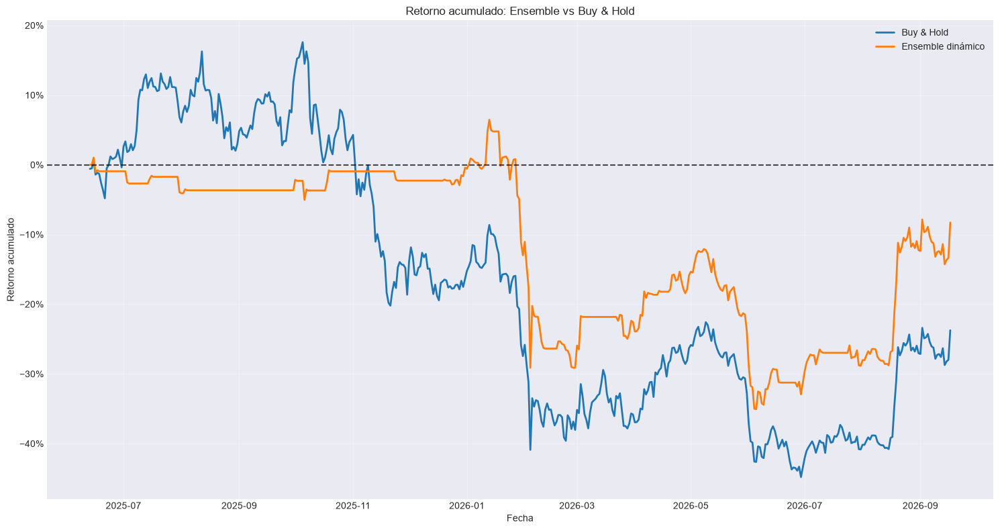

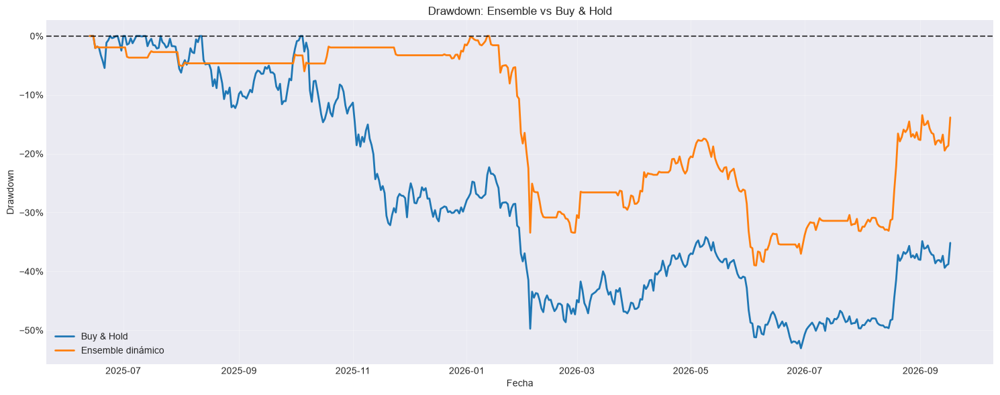


ÚLTIMAS SEÑALES


,prob_Baja,prob_Neutral,prob_Sube,up_edge,down_edge,prediction,prediction_name,raw_position,position,signal_reason
Date,,,,,,,,,,
2026-08-20,0.221893,0.129296,0.648811,0.426918,-0.426918,2,Sube,1.0,1.0,Señal alcista
2026-08-21,0.208991,0.248251,0.542758,0.294507,-0.333766,2,Sube,1.0,1.0,Señal alcista
2026-08-22,0.023005,0.119117,0.857878,0.738761,-0.834872,2,Sube,1.0,1.0,Señal alcista
2026-08-23,0.033545,0.133943,0.832512,0.698569,-0.798968,2,Sube,1.0,1.0,Señal alcista
2026-08-24,0.056262,0.107614,0.836124,0.728510,-0.779862,2,Sube,1.0,1.0,Señal alcista
2026-08-25,0.041077,0.116466,0.842457,0.725990,-0.801380,2,Sube,1.0,1.0,Señal alcista
2026-08-26,0.032301,0.113574,0.854125,0.740551,-0.821824,2,Sube,1.0,1.0,Señal alcista
2026-08-27,0.056899,0.089069,0.854032,0.764963,-0.797133,2,Sube,1.0,1.0,Señal alcista
2026-08-28,0.047111,0.081087,0.871803,0.790716,-0.824692,2,Sube,1.0,1.0,Señal alcista



RESUMEN
Umbral alcista: 0.5
Umbral bajista: 0.5
Ventaja mínima: 0.05
Retraso de ejecución: 1
Modelos: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']
Retorno Ensemble: -8.27%
Retorno Buy & Hold: -23.74%
Sharpe Ensemble: -0.0645
Sharpe Buy & Hold: -0.2991
Drawdown Ensemble: -38.99%
Drawdown Buy & Hold: -53.06%


In [432]:
# ============================================================
# ESTRATEGIA FINAL BTC (OPTIMIZADA)
#
# Ensemble:
#     MLP
#     Gradient Boosting
#     HistGradient Boosting
#
# Reglas:
#
#     Señal alcista fuerte -> 100 % BTC
#     Señal bajista fuerte -> 0 % BTC
#     Sin ventaja clara     -> 0 % BTC (Cash / Protección de capital)
#
# Comparación:
#
#     Ensemble vs Buy & Hold
#
# Requiere que ya existan:
#
#     best_models
#     X_dev
#     y_dev
#     X_test
#     df
#     CLOSE_COL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

INITIAL_CAPITAL = 10_000.0

# Costes estimados para spot:
# Comisión: 0.10 % | Slippage: 0.05 % -> Coste total por cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = FEE_PER_SIDE + SLIPPAGE_PER_SIDE

ENSEMBLE_MODELS = [
    "MLP",
    "Gradient Boosting",
    "HistGradient Boosting"
]

# Umbral mínimo de probabilidad (Optimizado de 0.40 a 0.50)
MIN_PROBA_UP = 0.50
MIN_PROBA_DOWN = 0.50

# Ventaja mínima sobre la segunda clase
MIN_EDGE = 0.05

# Retraso de ejecución: raw_position[t] se ejecuta en t+1
EXECUTION_LAG = 1

TARGET_LABELS = [0, 1, 2]

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}


# ============================================================
# 2. COMPROBACIONES
# ============================================================

required_objects = [
    "best_models",
    "X_dev",
    "y_dev",
    "X_test",
    "df",
    "CLOSE_COL"
]

missing_objects = [
    name for name in required_objects if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Faltan objetos necesarios:\n{missing_objects}"
    )

available_models = [
    model_name for model_name in ENSEMBLE_MODELS if model_name in best_models
]

if not available_models:
    raise RuntimeError(
        "Ninguno de los modelos del ensemble está disponible."
    )

if not X_test.index.is_monotonic_increasing:
    raise ValueError(
        "X_test no está ordenado cronológicamente."
    )

if X_test.index.has_duplicates:
    raise ValueError(
        "X_test contiene índices duplicados."
    )

print("Modelos incluidos:", available_models)


# ============================================================
# 3. FUNCIONES DE PROBABILIDADES
# ============================================================

def obtener_probabilidades_ordenadas(model, X):
    """
    Devuelve probabilidades en el orden fijo:
        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """
    if not hasattr(model, "predict_proba"):
        raise ValueError("El modelo no tiene predict_proba().")

    raw_proba = np.asarray(model.predict_proba(X))

    if raw_proba.ndim != 2:
        raise ValueError("Las probabilidades deben ser una matriz 2D.")

    if raw_proba.shape[0] != len(X):
        raise ValueError("El número de probabilidades no coincide con X.")

    model_classes = np.asarray(model.classes_).astype(int)
    ordered_proba = np.zeros((len(X), len(TARGET_LABELS)), dtype=float)

    for source_column, class_label in enumerate(model_classes):
        if class_label not in TARGET_LABELS:
            continue
        target_column = TARGET_LABELS.index(int(class_label))
        ordered_proba[:, target_column] = raw_proba[:, source_column]

    row_sums = ordered_proba.sum(axis=1)

    if np.any(row_sums <= 0):
        raise ValueError("Existen filas con suma de probabilidades igual a cero.")

    ordered_proba = ordered_proba / row_sums.reshape(-1, 1)

    return pd.DataFrame(
        ordered_proba,
        index=X.index,
        columns=["prob_Baja", "prob_Neutral", "prob_Sube"]
    )


# ============================================================
# 4. ENTRENAMIENTO Y ENSEMBLE
# ============================================================

model_probabilities = {}
final_models = {}

for model_name in available_models:
    print("\nEntrenando modelo:", model_name)
    model = clone(best_models[model_name]["model"])
    model.fit(X_dev, y_dev)

    probabilities = obtener_probabilidades_ordenadas(model=model, X=X_test)
    final_models[model_name] = model
    model_probabilities[model_name] = probabilities

# Promedio simple compatible con versiones modernas de Pandas
concat_probs = pd.concat(
    [model_probabilities[m] for m in available_models],
    axis=1,
    keys=available_models
)

ensemble_probabilities = concat_probs.T.groupby(level=1).mean().T
ensemble_probabilities = ensemble_probabilities[["prob_Baja", "prob_Neutral", "prob_Sube"]]

# Normalización defensiva
probability_sum = ensemble_probabilities.sum(axis=1)
ensemble_probabilities = ensemble_probabilities.div(probability_sum, axis=0)

if not ensemble_probabilities.index.equals(X_test.index):
    raise ValueError("Las probabilidades del ensemble no están alineadas con X_test.")


# ============================================================
# 5. CONSTRUCCIÓN DE LA SEÑAL (REGLAS DE PROTECCIÓN AJUSTADAS)
# ============================================================

prob_baja = ensemble_probabilities["prob_Baja"]
prob_neutral = ensemble_probabilities["prob_Neutral"]
prob_sube = ensemble_probabilities["prob_Sube"]

second_best_for_up = np.maximum(prob_baja, prob_neutral)
second_best_for_down = np.maximum(prob_sube, prob_neutral)

up_edge = prob_sube - second_best_for_up
down_edge = prob_baja - second_best_for_down

# Señal sin retraso:
#     1.0 -> 100 % BTC (Señal alcista confirmada)
#     0.0 -> 0 % BTC (Señal bajista o falta de certidumbre/ventaja)
raw_position = np.select(
    [
        (prob_sube >= MIN_PROBA_UP) & (up_edge >= MIN_EDGE),
        (prob_baja >= MIN_PROBA_DOWN) & (down_edge >= MIN_EDGE)
    ],
    [1.0, 0.0],
    default=0.0  # Cambio optimizado: Mantener 0.0 (100% Cash) en lugar de 0.5
)

raw_position = pd.Series(
    raw_position,
    index=X_test.index,
    dtype=float,
    name="raw_position"
)

# Posición realmente utilizada en t+1
position = (
    raw_position
    .shift(EXECUTION_LAG)
    .fillna(0.0)  # Inicio defensivo en cash
    .astype(float)
    .rename("position")
)

prediction = ensemble_probabilities.to_numpy().argmax(axis=1)
prediction = pd.Series(prediction, index=X_test.index, name="prediction").astype(int)

# Tabla de señales
signal_table = ensemble_probabilities.copy()
signal_table["up_edge"] = up_edge
signal_table["down_edge"] = down_edge
signal_table["prediction"] = prediction
signal_table["prediction_name"] = signal_table["prediction"].map(TARGET_NAMES)
signal_table["raw_position"] = raw_position
signal_table["position"] = position

signal_table["signal_reason"] = np.select(
    [
        signal_table["raw_position"] == 1.0,
        (prob_baja >= MIN_PROBA_DOWN) & (down_edge >= MIN_EDGE),
        signal_table["raw_position"] == 0.0
    ],
    [
        "Señal alcista",
        "Señal bajista",
        "Neutral / sin ventaja (Cash)"
    ],
    default="Desconocida"
)

print("\nDistribución de señales sin retraso:")
print(
    raw_position
    .value_counts()
    .sort_index()
    .rename(index={0.0: "0% BTC (Cash)", 0.5: "50% BTC", 1.0: "100% BTC"})
)

print("\nExposición media sin retraso:", f"{raw_position.mean():.2%}")
print("Exposición media ejecutada:", f"{position.mean():.2%}")

print("\nPrimeras señales:")
display(signal_table.head(20))


# ============================================================
# 6. PRECIOS Y RETORNOS
# ============================================================

test_prices = df.loc[X_test.index, CLOSE_COL].astype(float).rename("price")
test_prices = test_prices.replace([np.inf, -np.inf], np.nan)

if test_prices.isna().any():
    invalid_dates = test_prices.index[test_prices.isna()].tolist()
    raise ValueError(f"Hay precios faltantes en el test:\n{invalid_dates}")

if not test_prices.index.equals(X_test.index):
    raise ValueError("Los precios y X_test no están alineados.")

forward_returns = (test_prices.shift(-1) / test_prices - 1.0).rename("forward_return")


# ============================================================
# 7. PERIODOS ANUALIZADOS
# ============================================================

def estimar_periodos_por_anio(index):
    datetime_index = pd.DatetimeIndex(index)
    deltas = pd.Series(datetime_index).diff().dropna()

    if len(deltas) == 0:
        return 365.0

    median_days = deltas.dt.total_seconds().median() / 86400.0

    if not np.isfinite(median_days) or median_days <= 0:
        return 365.0

    return float(365.0 / median_days)


PERIODS_PER_YEAR = estimar_periodos_por_anio(test_prices.index)
print("\nPeriodos por año:", round(PERIODS_PER_YEAR, 2))


# ============================================================
# 8. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(equity):
    return equity / equity.cummax() - 1.0


def calcular_cagr(equity):
    if len(equity) < 2:
        return np.nan

    initial = float(equity.iloc[0])
    final = float(equity.iloc[-1])
    elapsed_seconds = (equity.index[-1] - equity.index[0]).total_seconds()
    years = elapsed_seconds / (365.0 * 24.0 * 60.0 * 60.0)

    if initial <= 0 or final <= 0 or years <= 0:
        return np.nan

    return float((final / initial) ** (1.0 / years) - 1.0)


def ejecutar_backtest(strategy_name, position, prices, forward_returns, initial_position=0.0):
    common_index = (
        prices.index
        .intersection(forward_returns.dropna().index)
        .intersection(position.index)
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(f"{strategy_name}: no hay observaciones comunes.")

    prices = prices.loc[common_index]
    forward_returns = forward_returns.loc[common_index]
    position = position.loc[common_index].astype(float)

    if not (prices.index.equals(forward_returns.index) and prices.index.equals(position.index)):
        raise ValueError(f"{strategy_name}: precios, retornos y posición no están alineados.")

    # Inicia con la posición especificada para no cargar costos ficticios en el paso 0
    previous_position = position.shift(1).fillna(initial_position)
    turnover = (position - previous_position).abs()
    gross_return = position * forward_returns

    equity_values, cost_values, net_return_values = [], [], []
    previous_equity = INITIAL_CAPITAL

    for timestamp in common_index:
        current_turnover = float(turnover.loc[timestamp])
        current_gross_return = float(gross_return.loc[timestamp])

        current_cost = previous_equity * current_turnover * COST_PER_TURNOVER
        equity_before_cost = previous_equity * (1.0 + current_gross_return)
        current_equity = equity_before_cost - current_cost

        current_net_return = (current_equity / previous_equity - 1.0) if previous_equity > 0 else -1.0

        equity_values.append(current_equity)
        cost_values.append(current_cost)
        net_return_values.append(current_net_return)

        previous_equity = current_equity

    equity = pd.Series(equity_values, index=common_index, name="equity")
    costs = pd.Series(cost_values, index=common_index, name="costs")
    net_returns = pd.Series(net_return_values, index=common_index, name="net_return")

    drawdown = calcular_drawdown(equity)
    return_std = net_returns.std(ddof=1)
    downside_returns = net_returns[net_returns < 0]
    downside_std = downside_returns.std(ddof=1)

    annualized_volatility = return_std * np.sqrt(PERIODS_PER_YEAR)

    sharpe = (
        net_returns.mean() / return_std * np.sqrt(PERIODS_PER_YEAR)
        if (return_std > 0 and np.isfinite(return_std)) else np.nan
    )

    sortino = (
        net_returns.mean() / downside_std * np.sqrt(PERIODS_PER_YEAR)
        if (downside_std > 0 and np.isfinite(downside_std)) else np.nan
    )

    max_drawdown = float(drawdown.min())
    cagr = calcular_cagr(equity)

    calmar = (
        cagr / abs(max_drawdown)
        if (max_drawdown < 0 and np.isfinite(cagr)) else np.nan
    )

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "costs": costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": equity.iloc[-1] / INITIAL_CAPITAL - 1.0,
        "CAGR": cagr,
        "Volatilidad anualizada": annualized_volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Máximo drawdown": max_drawdown,
        "Calmar": calmar,
        "Win rate": (net_returns > 0).mean(),
        "Exposición media": position.mean(),
        "Costes acumulados": costs.sum(),
        "Turnover acumulado": turnover.sum(),
        "Cambios de posición": int((turnover > 0).sum())
    }

    return result, metrics


# ============================================================
# 9. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(1.0, index=X_test.index, name="position")

buy_hold_result, buy_hold_metrics = ejecutar_backtest(
    strategy_name="Buy & Hold",
    position=buy_hold_position,
    prices=test_prices,
    forward_returns=forward_returns,
    initial_position=1.0  # Asume posesión inicial del activo
)


# ============================================================
# 10. BACKTEST DE LA ESTRATEGIA
# ============================================================

ensemble_result, ensemble_metrics = ejecutar_backtest(
    strategy_name="Ensemble dinámico",
    position=position,
    prices=test_prices,
    forward_returns=forward_returns,
    initial_position=0.0  # Asume posesión inicial en cash
)

backtest_results = {
    "Buy & Hold": buy_hold_result,
    "Ensemble dinámico": ensemble_result
}

metrics_table = pd.DataFrame([buy_hold_metrics, ensemble_metrics])


# ============================================================
# 11. MÉTRICAS DE RENTABILIDAD Y RIESGO
# ============================================================

print("\n" + "=" * 130)
print("MÉTRICAS DE RENTABILIDAD Y RIESGO")
print("=" * 130)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 12. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[metrics_table["Estrategia"] == "Buy & Hold"].iloc[0]
ensemble_row = metrics_table[metrics_table["Estrategia"] == "Ensemble dinámico"].iloc[0]

comparison_table = pd.DataFrame(
    [
        {
            "Métrica": "Retorno total",
            "Ensemble": ensemble_row["Retorno total"],
            "Buy & Hold": buy_hold_row["Retorno total"],
            "Diferencia": ensemble_row["Retorno total"] - buy_hold_row["Retorno total"]
        },
        {
            "Métrica": "CAGR",
            "Ensemble": ensemble_row["CAGR"],
            "Buy & Hold": buy_hold_row["CAGR"],
            "Diferencia": ensemble_row["CAGR"] - buy_hold_row["CAGR"]
        },
        {
            "Métrica": "Sharpe",
            "Ensemble": ensemble_row["Sharpe"],
            "Buy & Hold": buy_hold_row["Sharpe"],
            "Diferencia": ensemble_row["Sharpe"] - buy_hold_row["Sharpe"]
        },
        {
            "Métrica": "Máximo drawdown",
            "Ensemble": ensemble_row["Máximo drawdown"],
            "Buy & Hold": buy_hold_row["Máximo drawdown"],
            "Diferencia": ensemble_row["Máximo drawdown"] - buy_hold_row["Máximo drawdown"]
        },
        {
            "Métrica": "Costes acumulados",
            "Ensemble": ensemble_row["Costes acumulados"],
            "Buy & Hold": buy_hold_row["Costes acumulados"],
            "Diferencia": ensemble_row["Costes acumulados"] - buy_hold_row["Costes acumulados"]
        }
    ]
)

print("\n" + "=" * 130)
print("COMPARACIÓN ENSEMBLE VS BUY & HOLD")
print("=" * 130)

display(
    comparison_table.style.format(
        {
            "Ensemble": "{:.4f}",
            "Buy & Hold": "{:.4f}",
            "Diferencia": "{:.4f}"
        }
    )
)


# ============================================================
# 13. RETORNO ACUMULADO
# ============================================================

plt.figure(figsize=(15, 8))

for strategy_name, result in backtest_results.items():
    cumulative_return = result["equity"] / INITIAL_CAPITAL - 1.0
    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Retorno acumulado: Ensemble vs Buy & Hold")
plt.xlabel("Fecha")
plt.ylabel("Retorno acumulado")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 14. DRAWDOWN
# ============================================================

plt.figure(figsize=(15, 6))

for strategy_name, result in backtest_results.items():
    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=2,
        label=strategy_name
    )

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Drawdown: Ensemble vs Buy & Hold")
plt.xlabel("Fecha")
plt.ylabel("Drawdown")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 15. TABLA DE SEÑALES
# ============================================================

print("\n" + "=" * 100)
print("ÚLTIMAS SEÑALES")
print("=" * 100)

display(
    signal_table[
        [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube",
            "up_edge",
            "down_edge",
            "prediction",
            "prediction_name",
            "raw_position",
            "position",
            "signal_reason"
        ]
    ].tail(30)
)


# ============================================================
# 16. RESUMEN
# ============================================================

print("\n" + "=" * 100)
print("RESUMEN")
print("=" * 100)

print("Umbral alcista:", MIN_PROBA_UP)
print("Umbral bajista:", MIN_PROBA_DOWN)
print("Ventaja mínima:", MIN_EDGE)
print("Retraso de ejecución:", EXECUTION_LAG)
print("Modelos:", available_models)
print("Retorno Ensemble:", f"{ensemble_row['Retorno total']:.2%}")
print("Retorno Buy & Hold:", f"{buy_hold_row['Retorno total']:.2%}")
print("Sharpe Ensemble:", f"{ensemble_row['Sharpe']:.4f}")
print("Sharpe Buy & Hold:", f"{buy_hold_row['Sharpe']:.4f}")
print("Drawdown Ensemble:", f"{ensemble_row['Máximo drawdown']:.2%}")
print("Drawdown Buy & Hold:", f"{buy_hold_row['Máximo drawdown']:.2%}")

In [433]:
# ============================================================
# ESTRATEGIA 1: POSITION SIZING CONTINUO
# ============================================================

# 1. Cálculo de volatilidad normalizada (20 periodos)
returns = df.loc[X_test.index, CLOSE_COL].pct_change()
volatility = returns.rolling(window=20).std().fillna(returns.std())
vol_factor = volatility / volatility.median()

# 2. Ventaja neta de probabilidad
net_confidence = ensemble_probabilities["prob_Sube"] - ensemble_probabilities["prob_Baja"]

# 3. Exposición continua recortada entre 0% y 100%
raw_position_sizing = (net_confidence / vol_factor).clip(lower=0.0, upper=1.0)

# 4. Retraso de ejecución
position_sizing = raw_position_sizing.shift(EXECUTION_LAG).fillna(0.0)


TABLA COMPARATIVA DE ESTRATEGIAS CONTRA BUY & HOLD


,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anual,Sharpe,Sortino,Max Drawdown,Calmar,Exposición media,Costes acumulados,Cambios de posición
0,Buy & Hold,"$7,625.67",-23.74%,-19.32%,42.03%,-0.2991,-0.4247,-53.06%,-0.3640,100.00%,$0.00,0
1,Ensemble Base (0% Cash),"$9,172.52",-8.27%,-6.61%,31.02%,-0.0645,-0.0596,-38.99%,-0.1695,43.51%,$858.71,65
2,1. Position Sizing Continuo,"$9,383.52",-6.16%,-4.91%,21.23%,-0.1305,-0.1324,-33.26%,-0.1477,31.44%,$677.14,311
3,2. Overlay Régimen (EMA 200),"$9,100.04",-9.00%,-7.19%,30.34%,-0.0934,-0.0831,-39.42%,-0.1825,39.61%,$809.25,61
4,3. Trailing Stop (ATR),"$8,387.68",-16.12%,-13.00%,28.83%,-0.3356,-0.3014,-44.70%,-0.2907,42.42%,"$1,055.26",85


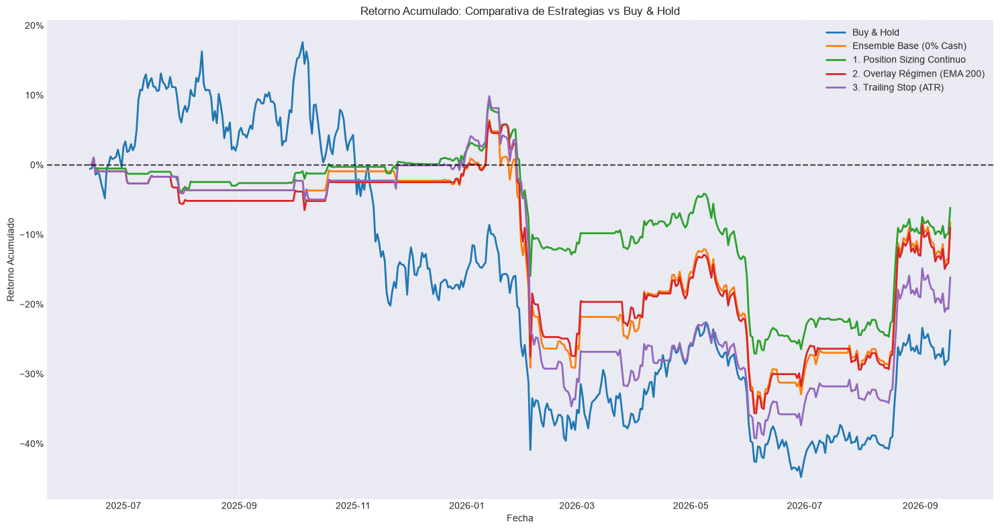

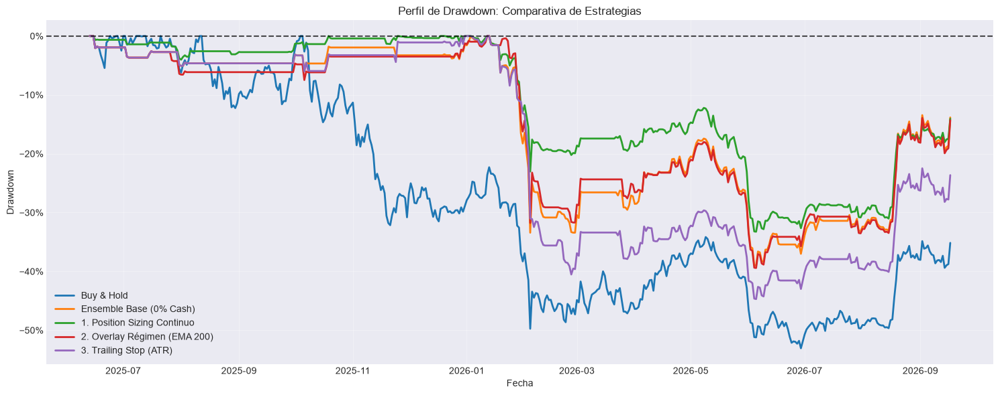

In [434]:
# ============================================================
# EVALUACIÓN MULTI-ESTRATEGIA AVANZADA DE BTC
#
# Comparativa:
#   1. Buy & Hold (Benchmark)
#   2. Ensemble Base (Optimizado 0% Cash)
#   3. Estrategia 1: Position Sizing Continuo
#   4. Estrategia 2: Overlay de Régimen (EMA 200)
#   5. Estrategia 3: Trailing Stop Volátil (ATR)
#
# Requiere que ya existan en el entorno:
#   best_models, X_dev, y_dev, X_test, df, CLOSE_COL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN E INICIALIZACIÓN
# ============================================================

INITIAL_CAPITAL = 10_000.0

FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005
COST_PER_TURNOVER = FEE_PER_SIDE + SLIPPAGE_PER_SIDE

ENSEMBLE_MODELS = [
    "MLP",
    "Gradient Boosting",
    "HistGradient Boosting"
]

MIN_PROBA_UP = 0.50
MIN_PROBA_DOWN = 0.50
MIN_EDGE = 0.05
EXECUTION_LAG = 1

TARGET_LABELS = [0, 1, 2]

# ============================================================
# 2. FUNCIONES DE PROBABILIDADES
# ============================================================

def obtener_probabilidades_ordenadas(model, X):
    if not hasattr(model, "predict_proba"):
        raise ValueError("El modelo no tiene predict_proba().")

    raw_proba = np.asarray(model.predict_proba(X))
    model_classes = np.asarray(model.classes_).astype(int)
    ordered_proba = np.zeros((len(X), len(TARGET_LABELS)), dtype=float)

    for source_column, class_label in enumerate(model_classes):
        if class_label not in TARGET_LABELS:
            continue
        target_column = TARGET_LABELS.index(int(class_label))
        ordered_proba[:, target_column] = raw_proba[:, source_column]

    row_sums = ordered_proba.sum(axis=1)
    ordered_proba = ordered_proba / row_sums.reshape(-1, 1)

    return pd.DataFrame(
        ordered_proba,
        index=X.index,
        columns=["prob_Baja", "prob_Neutral", "prob_Sube"]
    )

# ============================================================
# 3. ENTRENAMIENTO Y ENSEMBLE
# ============================================================

available_models = [m for m in ENSEMBLE_MODELS if m in best_models]

model_probabilities = {}
for model_name in available_models:
    model = clone(best_models[model_name]["model"])
    model.fit(X_dev, y_dev)
    model_probabilities[model_name] = obtener_probabilidades_ordenadas(model, X_test)

concat_probs = pd.concat([model_probabilities[m] for m in available_models], axis=1, keys=available_models)
ensemble_probabilities = concat_probs.T.groupby(level=1).mean().T[["prob_Baja", "prob_Neutral", "prob_Sube"]]
ensemble_probabilities = ensemble_probabilities.div(ensemble_probabilities.sum(axis=1), axis=0)

prob_baja = ensemble_probabilities["prob_Baja"]
prob_neutral = ensemble_probabilities["prob_Neutral"]
prob_sube = ensemble_probabilities["prob_Sube"]

second_best_for_up = np.maximum(prob_baja, prob_neutral)
second_best_for_down = np.maximum(prob_sube, prob_neutral)

up_edge = prob_sube - second_best_for_up
down_edge = prob_baja - second_best_for_down

# ============================================================
# 4. CONSTRUCCIÓN DE LAS POSICIONES (LAS 3 ESTRATEGIAS)
# ============================================================

test_prices = df.loc[X_test.index, CLOSE_COL].astype(float)
forward_returns = (test_prices.shift(-1) / test_prices - 1.0).rename("forward_return")

# ------------------------------------------------------------
# Estrategia Base: Discreta (0% / 100% Cash)
# ------------------------------------------------------------
raw_pos_base = np.select(
    [
        (prob_sube >= MIN_PROBA_UP) & (up_edge >= MIN_EDGE),
        (prob_baja >= MIN_PROBA_DOWN) & (down_edge >= MIN_EDGE)
    ],
    [1.0, 0.0],
    default=0.0
)
pos_base = pd.Series(raw_pos_base, index=X_test.index).shift(EXECUTION_LAG).fillna(0.0)

# ------------------------------------------------------------
# Estrategia 1: Position Sizing Continuo
# ------------------------------------------------------------
returns_series = test_prices.pct_change()
volatility = returns_series.rolling(window=20).std().fillna(returns_series.std())
vol_factor = (volatility / volatility.median()).replace(0, 1.0)

net_confidence = prob_sube - prob_baja
raw_pos_sizing = (net_confidence / vol_factor).clip(lower=0.0, upper=1.0)
pos_sizing = raw_pos_sizing.shift(EXECUTION_LAG).fillna(0.0)

# ------------------------------------------------------------
# Estrategia 2: Overlay de Régimen (EMA 200)
# ------------------------------------------------------------
ema_200 = df[CLOSE_COL].ewm(span=200, adjust=False).mean().loc[X_test.index]
is_bull_regime = test_prices > ema_200

raw_pos_regime = np.select(
    [
        is_bull_regime & (prob_sube >= 0.42) & (up_edge >= 0.03),
        (~is_bull_regime) & (prob_sube >= 0.60) & (up_edge >= 0.10)
    ],
    [1.0, 1.0],
    default=0.0
)
pos_regime = pd.Series(raw_pos_regime, index=X_test.index).shift(EXECUTION_LAG).fillna(0.0)

# ------------------------------------------------------------
# Estrategia 3: Trailing Stop Volátil (ATR)
# ------------------------------------------------------------
def calcular_atr_df(df_subset, window=14):
    high = df_subset["High"] if "High" in df_subset else df_subset[CLOSE_COL]
    low = df_subset["Low"] if "Low" in df_subset else df_subset[CLOSE_COL]
    close = df_subset[CLOSE_COL]
    tr = pd.concat([high - low, (high - close.shift(1)).abs(), (low - close.shift(1)).abs()], axis=1).max(axis=1)
    return tr.rolling(window).mean()

atr_series = calcular_atr_df(df.loc[X_test.index]).fillna(0.0)
raw_pos_atr = np.zeros(len(X_test))

in_pos = False
trailing_stop = 0.0
mult = 2.5

prices_arr = test_prices.to_numpy()
prob_sube_arr = prob_sube.to_numpy()
up_edge_arr = up_edge.to_numpy()
atr_arr = atr_series.to_numpy()

for t in range(len(X_test)):
    p_t = prices_arr[t]
    if not in_pos:
        if (prob_sube_arr[t] >= MIN_PROBA_UP) and (up_edge_arr[t] >= MIN_EDGE):
            in_pos = True
            trailing_stop = p_t - (mult * atr_arr[t])
            raw_pos_atr[t] = 1.0
        else:
            raw_pos_atr[t] = 0.0
    else:
        c_stop = p_t - (mult * atr_arr[t])
        if c_stop > trailing_stop:
            trailing_stop = c_stop
        
        if p_t < trailing_stop or prob_sube_arr[t] < 0.40:
            in_pos = False
            raw_pos_atr[t] = 0.0
        else:
            raw_pos_atr[t] = 1.0

pos_atr = pd.Series(raw_pos_atr, index=X_test.index).shift(EXECUTION_LAG).fillna(0.0)

# ============================================================
# 5. MOTOR DE BACKTEST Y MÉTRICAS
# ============================================================

def estimar_periodos_por_anio(index):
    deltas = pd.Series(pd.DatetimeIndex(index)).diff().dropna()
    if len(deltas) == 0: return 365.0
    med_days = deltas.dt.total_seconds().median() / 86400.0
    return float(365.0 / med_days) if med_days > 0 else 365.0

PERIODS_PER_YEAR = estimar_periodos_por_anio(test_prices.index)

def ejecutar_backtest(strategy_name, position, prices, forward_returns, initial_position=0.0):
    common_index = prices.index.intersection(forward_returns.dropna().index).intersection(position.index).sort_values()
    
    p = prices.loc[common_index]
    fr = forward_returns.loc[common_index]
    pos = position.loc[common_index].astype(float)
    
    prev_pos = pos.shift(1).fillna(initial_position)
    turnover = (pos - prev_pos).abs()
    gross_return = pos * fr
    
    equity_values, costs_values, net_returns_values = [], [], []
    prev_equity = INITIAL_CAPITAL

    for ts in common_index:
        c_turnover = float(turnover.loc[ts])
        c_gross = float(gross_return.loc[ts])
        
        c_cost = prev_equity * c_turnover * COST_PER_TURNOVER
        eq_before = prev_equity * (1.0 + c_gross)
        c_equity = eq_before - c_cost
        c_net = (c_equity / prev_equity - 1.0) if prev_equity > 0 else -1.0
        
        equity_values.append(c_equity)
        costs_values.append(c_cost)
        net_returns_values.append(c_net)
        prev_equity = c_equity

    equity = pd.Series(equity_values, index=common_index)
    costs = pd.Series(costs_values, index=common_index)
    net_returns = pd.Series(net_returns_values, index=common_index)
    
    dd = equity / equity.cummax() - 1.0
    r_std = net_returns.std(ddof=1)
    downside_std = net_returns[net_returns < 0].std(ddof=1)
    
    ann_vol = r_std * np.sqrt(PERIODS_PER_YEAR)
    sharpe = (net_returns.mean() / r_std * np.sqrt(PERIODS_PER_YEAR)) if (r_std > 0 and np.isfinite(r_std)) else np.nan
    sortino = (net_returns.mean() / downside_std * np.sqrt(PERIODS_PER_YEAR)) if (downside_std > 0 and np.isfinite(downside_std)) else np.nan
    
    mdd = float(dd.min())
    years = (equity.index[-1] - equity.index[0]).total_seconds() / (365.0 * 86400.0)
    cagr = float((equity.iloc[-1] / INITIAL_CAPITAL) ** (1.0 / years) - 1.0) if (years > 0 and equity.iloc[-1] > 0) else np.nan
    calmar = (cagr / abs(mdd)) if (mdd < 0 and np.isfinite(cagr)) else np.nan
    
    res = pd.DataFrame({"equity": equity, "drawdown": dd}, index=common_index)
    
    met = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": equity.iloc[-1] / INITIAL_CAPITAL - 1.0,
        "CAGR": cagr,
        "Volatilidad anual": ann_vol,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": mdd,
        "Calmar": calmar,
        "Exposición media": pos.mean(),
        "Costes acumulados": costs.sum(),
        "Cambios de posición": int((turnover > 0).sum())
    }
    return res, met

# ============================================================
# 6. EJECUCIÓN DEL COMPARATIVO GENERAL
# ============================================================

pos_buy_hold = pd.Series(1.0, index=X_test.index)

strats = {
    "Buy & Hold": (pos_buy_hold, 1.0),
    "Ensemble Base (0% Cash)": (pos_base, 0.0),
    "1. Position Sizing Continuo": (pos_sizing, 0.0),
    "2. Overlay Régimen (EMA 200)": (pos_regime, 0.0),
    "3. Trailing Stop (ATR)": (pos_atr, 0.0)
}

all_results = {}
all_metrics = []

for name, (pos_series, init_pos) in strats.items():
    res, met = ejecutar_backtest(name, pos_series, test_prices, forward_returns, initial_position=init_pos)
    all_results[name] = res
    all_metrics.append(met)

metrics_df = pd.DataFrame(all_metrics)

print("\n" + "=" * 130)
print("TABLA COMPARATIVA DE ESTRATEGIAS CONTRA BUY & HOLD")
print("=" * 130)

display(
    metrics_df.style.format({
        "Capital final": "${:,.2f}",
        "Retorno total": "{:.2%}",
        "CAGR": "{:.2%}",
        "Volatilidad anual": "{:.2%}",
        "Sharpe": "{:.4f}",
        "Sortino": "{:.4f}",
        "Max Drawdown": "{:.2%}",
        "Calmar": "{:.4f}",
        "Exposición media": "{:.2%}",
        "Costes acumulados": "${:,.2f}",
        "Cambios de posición": "{:.0f}"
    })
)

# ============================================================
# 7. VISUALIZACIÓN GRÁFICA
# ============================================================

plt.figure(figsize=(15, 8))
for name, res in all_results.items():
    cum_ret = res["equity"] / INITIAL_CAPITAL - 1.0
    plt.plot(cum_ret.index, cum_ret.values, linewidth=2, label=name)

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Retorno Acumulado: Comparativa de Estrategias vs Buy & Hold")
plt.xlabel("Fecha")
plt.ylabel("Retorno Acumulado")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 6))
for name, res in all_results.items():
    plt.plot(res.index, res["drawdown"], linewidth=2, label=name)

plt.axhline(0.0, color="black", linestyle="--", alpha=0.7)
plt.title("Perfil de Drawdown: Comparativa de Estrategias")
plt.xlabel("Fecha")
plt.ylabel("Drawdown")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Modelos incluidos en el ensemble: ['MLP', 'Gradient Boosting', 'HistGradient Boosting']

Distribución de exposición sin retraso:
position_raw
0% BTC      114
50% BTC     131
100% BTC    218
Name: count, dtype: int64

Exposición media sin retraso: 61.23%
Exposición media con retraso: 61.12%

MÉTRICAS DE LA ESTRATEGIA


,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$7,614.16",-23.86%,-18.94%,42.03%,-0.3019,-0.4288,-53.06%,-0.3570,48.92%,100.00%,$15.00,1.00,1
1,Ensemble MLP + Gradient Boosting + HistGradient Boosting,"$10,017.52",0.18%,0.43%,34.04%,0.1745,0.2047,-35.94%,0.0120,37.45%,61.04%,$781.67,55.00,97



COMPARACIÓN ENSEMBLE VS BUY & HOLD


,Métrica,Ensemble,Buy & Hold,Diferencia
0,Retorno total,0.0018,-0.2386,0.2403
1,CAGR,0.0043,-0.1894,0.1937
2,Sharpe,0.1745,-0.3019,0.4764
3,Máximo drawdown,-0.3594,-0.5306,0.1712
4,Costes acumulados,781.6661,15.0000,766.6661


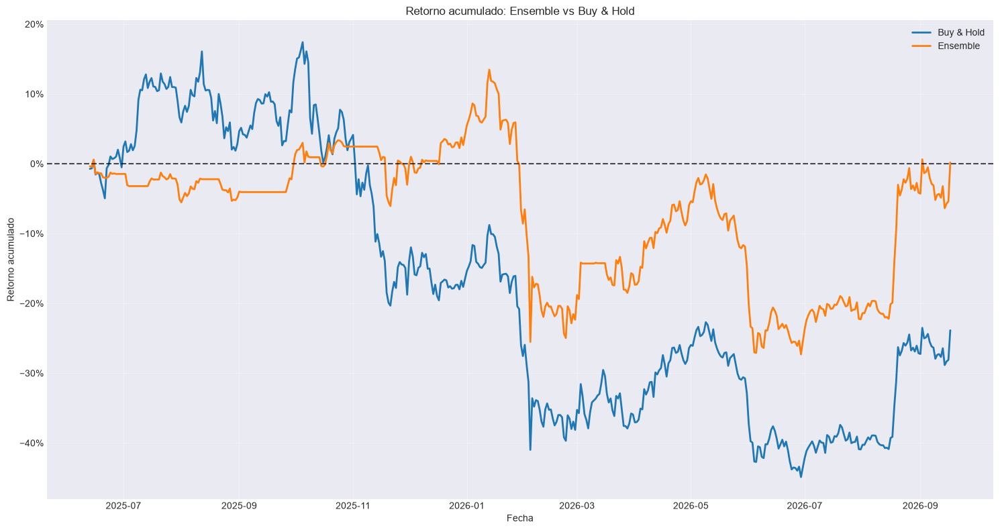

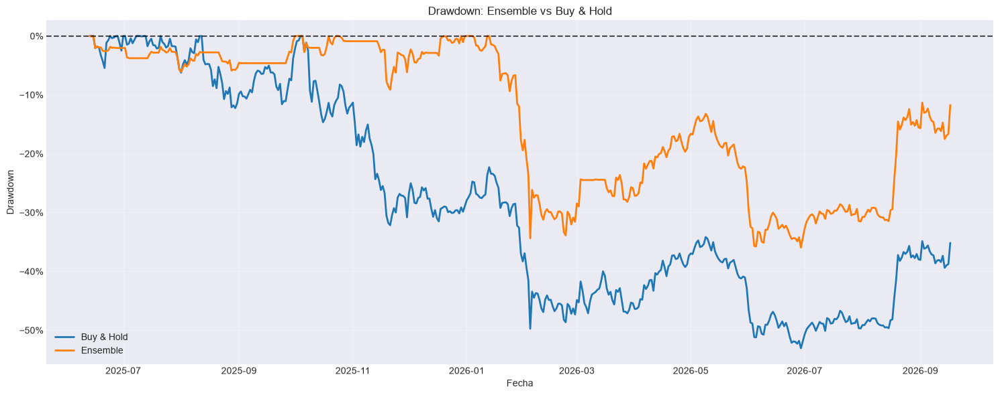


DIAGNÓSTICO DE SEÑALES
Umbral probabilidad alcista: 0.4
Umbral probabilidad bajista: 0.4
Ventaja mínima: 0.05
Retraso de ejecución: 1

Primeras señales:


,prob_Baja,prob_Neutral,prob_Sube,up_edge,down_edge,position_raw,position
Date,,,,,,,
2025-06-13,0.467165,0.132305,0.400530,-0.066635,0.066635,0.0,0.5
2025-06-14,0.400664,0.068293,0.531043,0.130379,-0.130379,1.0,0.0
2025-06-15,0.178383,0.287291,0.534327,0.247036,-0.355944,1.0,1.0
2025-06-16,0.224299,0.229294,0.546407,0.317113,-0.322109,1.0,1.0
2025-06-17,0.576603,0.243107,0.180290,-0.396314,0.333496,0.0,1.0
2025-06-18,0.447538,0.198830,0.353632,-0.093905,0.093905,0.0,0.0
2025-06-19,0.356445,0.521776,0.121778,-0.399998,-0.165331,0.5,0.0
2025-06-20,0.514115,0.351952,0.133933,-0.380183,0.162163,0.0,0.5
2025-06-21,0.524104,0.353330,0.122567,-0.401537,0.170774,0.0,0.0


In [429]:
# ============================================================
# ESTRATEGIA ENSEMBLE PARA BTC
#
# Modelos seleccionados por F1 de validación:
#
#     MLP
#     Gradient Boosting
#     HistGradient Boosting
#
# Estrategia:
#
#     Señal alcista fuerte -> 100 % BTC
#     Señal neutral        -> 50 % BTC
#     Señal bajista fuerte -> 0 % BTC
#
# La señal se retrasa una barra para evitar una ejecución
# optimista al cierre de la misma vela.
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

INITIAL_CAPITAL = 10_000.0

# Coste aproximado:
#
# Comisión: 0.10 %
# Slippage: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

# Umbrales fijados antes de mirar el resultado del test.
#
# Deben optimizarse únicamente dentro de validación en una
# versión final de producción.
MIN_PROBA_UP = 0.40
MIN_PROBA_DOWN = 0.40
MIN_EDGE = 0.05

# Retraso de ejecución:
#
# raw_signal[t] se aplica desde t+1 hasta t+2.
#
# Esto es más conservador que utilizar la señal inmediatamente.
EXECUTION_LAG = 1

TARGET_LABELS = [0, 1, 2]

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

# Modelos elegidos exclusivamente por F1 de validación.
# Son los tres mejores de tu tabla por CV.
ENSEMBLE_MODELS = [
    "MLP",
    "Gradient Boosting",
    "HistGradient Boosting"
]


# ============================================================
# 2. COMPROBACIONES
# ============================================================

required_objects = [
    "best_models",
    "X_test",
    "df",
    "CLOSE_COL"
]

missing_objects = [
    object_name
    for object_name in required_objects
    if object_name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Faltan objetos necesarios:\n"
        f"{missing_objects}"
    )

available_ensemble_models = [
    model_name
    for model_name in ENSEMBLE_MODELS
    if model_name in best_models
]

if len(available_ensemble_models) == 0:
    raise RuntimeError(
        "Ninguno de los modelos del ensemble está disponible."
    )

print(
    "Modelos incluidos en el ensemble:",
    available_ensemble_models
)


# ============================================================
# 3. ENTRENAMIENTO FINAL DE LOS MODELOS
# ============================================================

# Si ya existe final_models, se reutiliza.
if "final_models" not in globals():
    final_models = {}

# Diccionario de probabilidades
test_probabilities_ensemble = {}


for model_name in available_ensemble_models:

    if model_name not in final_models:

        model_final = clone(
            best_models[model_name]["model"]
        )

        model_final.fit(
            X_dev,
            y_dev
        )

        final_models[
            model_name
        ] = model_final

    else:

        model_final = final_models[
            model_name
        ]

    # Probabilidades
    if (
        "test_probabilities" in globals()
        and
        model_name in test_probabilities
    ):

        probabilities = test_probabilities[
            model_name
        ].copy()

        # Reordenar columnas de forma defensiva
        expected_columns = [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube"
        ]

        if all(
            column in probabilities.columns
            for column in expected_columns
        ):

            probabilities = probabilities[
                expected_columns
            ]

        else:

            raw_proba = model_final.predict_proba(
                X_test
            )

            model_classes = np.asarray(
                model_final.classes_
            ).astype(int)

            probabilities = np.zeros(
                (
                    len(X_test),
                    3
                ),
                dtype=float
            )

            for source_column, class_label in enumerate(
                model_classes
            ):

                target_column = int(
                    class_label
                )

                probabilities[
                    :,
                    target_column
                ] = raw_proba[
                    :,
                    source_column
                ]

            probabilities = pd.DataFrame(
                probabilities,
                index=X_test.index,
                columns=expected_columns
            )

    else:

        raw_proba = model_final.predict_proba(
            X_test
        )

        raw_proba = np.asarray(
            raw_proba
        )

        model_classes = np.asarray(
            model_final.classes_
        ).astype(int)

        probabilities_array = np.zeros(
            (
                len(X_test),
                3
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            target_column = int(
                class_label
            )

            probabilities_array[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        probabilities = pd.DataFrame(
            probabilities_array,
            index=X_test.index,
            columns=[
                "prob_Baja",
                "prob_Neutral",
                "prob_Sube"
            ]
        )

    # Comprobar alineación
    probabilities = probabilities.reindex(
        X_test.index
    )

    if len(probabilities) != len(X_test):
        raise ValueError(
            f"{model_name}: probabilidades desalineadas."
        )

    if not np.isfinite(
        probabilities.values
    ).all():
        raise ValueError(
            f"{model_name}: probabilidades con NaN o infinitos."
        )

    test_probabilities_ensemble[
        model_name
    ] = probabilities


# ============================================================
# 4. ENSEMBLE DE PROBABILIDADES
# ============================================================

probability_table = pd.DataFrame(
    index=X_test.index
)

for class_name in [
    "Baja",
    "Neutral",
    "Sube"
]:

    class_probabilities = []

    for model_name in available_ensemble_models:

        class_probabilities.append(
            test_probabilities_ensemble[
                model_name
            ][
                f"prob_{class_name}"
            ]
        )

    probability_table[
        f"prob_{class_name}"
    ] = pd.concat(
        class_probabilities,
        axis=1
    ).mean(
        axis=1
    )

# Normalización defensiva
probability_sum = probability_table[
    [
        "prob_Baja",
        "prob_Neutral",
        "prob_Sube"
    ]
].sum(
    axis=1
)

probability_table[
    [
        "prob_Baja",
        "prob_Neutral",
        "prob_Sube"
    ]
] = (
    probability_table[
        [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube"
        ]
    ]
    .div(
        probability_sum,
        axis=0
    )
)


# ============================================================
# 5. CONSTRUCCIÓN DE LA SEÑAL
# ============================================================

prob_down = probability_table[
    "prob_Baja"
]

prob_neutral = probability_table[
    "prob_Neutral"
]

prob_up = probability_table[
    "prob_Sube"
]

second_best_up = np.maximum(
    prob_down,
    prob_neutral
)

second_best_down = np.maximum(
    prob_up,
    prob_neutral
)

up_edge = (
    prob_up
    -
    second_best_up
)

down_edge = (
    prob_down
    -
    second_best_down
)

# Exposición sin retrasar:
#
#     0.0 -> fuera del mercado
#     0.5 -> exposición parcial
#     1.0 -> exposición completa
#
# Se exige:
#
#     - probabilidad mínima
#     - ventaja respecto a la segunda clase
position_raw = np.select(
    [
        (
            (prob_up >= MIN_PROBA_UP)
            &
            (up_edge >= MIN_EDGE)
        ),

        (
            (prob_down >= MIN_PROBA_DOWN)
            &
            (down_edge >= MIN_EDGE)
        )
    ],
    [
        1.0,
        0.0
    ],
    default=0.5
)

position_raw = pd.Series(
    position_raw,
    index=X_test.index,
    dtype=float,
    name="position_raw"
)

# Aplicar retraso de ejecución
position = (
    position_raw
    .shift(
        EXECUTION_LAG
    )
    .fillna(0.5)
    .rename(
        "position"
    )
)

# Diagnóstico
probability_table["prob_Baja"] = prob_down
probability_table["prob_Neutral"] = prob_neutral
probability_table["prob_Sube"] = prob_up
probability_table["up_edge"] = up_edge
probability_table["down_edge"] = down_edge
probability_table["position_raw"] = position_raw
probability_table["position"] = position

print(
    "\nDistribución de exposición sin retraso:"
)

print(
    position_raw.value_counts()
    .sort_index()
    .rename(
        index={
            0.0: "0% BTC",
            0.5: "50% BTC",
            1.0: "100% BTC"
        }
    )
)

print(
    "\nExposición media sin retraso:",
    f"{position_raw.mean():.2%}"
)

print(
    "Exposición media con retraso:",
    f"{position.mean():.2%}"
)


# ============================================================
# 6. PRECIOS Y RETORNOS
# ============================================================

test_prices = (
    df.loc[
        X_test.index,
        CLOSE_COL
    ]
    .astype(float)
    .rename(
        "price"
    )
)

test_prices = test_prices.replace(
    [np.inf, -np.inf],
    np.nan
)

if test_prices.isna().any():
    raise ValueError(
        "Existen precios faltantes en X_test."
    )

forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


# ============================================================
# 7. FRECUENCIA TEMPORAL
# ============================================================

def estimar_periodos_por_anio(
    index
):
    index = pd.DatetimeIndex(
        index
    )

    deltas = (
        pd.Series(index)
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)


# ============================================================
# 8. MÉTRICAS Y BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay datos comunes."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_values = []
    net_return_values = []

    previous_equity = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        current_cost = (
            previous_equity
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_before_cost = (
            previous_equity
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        current_equity = (
            equity_before_cost
            -
            current_cost
        )

        current_net_return = (
            current_equity
            /
            previous_equity
            -
            1.0
        )

        equity_values.append(
            current_equity
        )

        cost_values.append(
            current_cost
        )

        net_return_values.append(
            current_net_return
        )

        previous_equity = current_equity

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    costs = pd.Series(
        cost_values,
        index=common_index,
        name="costs"
    )

    drawdown = calcular_drawdown(
        equity
    )

    volatility = (
        net_returns.std(
            ddof=1
        )
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    downside_returns = net_returns[
        net_returns < 0
    ]

    downside_std = downside_returns.std(
        ddof=1
    )

    if (
        net_returns.std(ddof=1) > 0
    ):
        sharpe = (
            net_returns.mean()
            /
            net_returns.std(
                ddof=1
            )
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )
    else:
        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):
        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )
    else:
        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):
        calmar = (
            cagr
            /
            abs(max_drawdown)
        )
    else:
        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "costs": costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),
        "CAGR": cagr,
        "Volatilidad anualizada": volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Máximo drawdown": max_drawdown,
        "Calmar": calmar,
        "Win rate": (
            net_returns > 0
        ).mean(),
        "Exposición media": position.mean(),
        "Costes acumulados": costs.sum(),
        "Turnover acumulado": turnover.sum(),
        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


# ============================================================
# 9. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)


# ============================================================
# 10. ENSEMBLE
# ============================================================

ensemble_result, ensemble_metrics = (
    ejecutar_backtest(
        strategy_name=(
            "Ensemble MLP + Gradient Boosting "
            "+ HistGradient Boosting"
        ),
        position=position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result,
    "Ensemble": ensemble_result
}

metrics_table = pd.DataFrame(
    [
        buy_hold_metrics,
        ensemble_metrics
    ]
)


# ============================================================
# 11. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

print(
    "\n" + "=" * 130
)

print(
    "MÉTRICAS DE LA ESTRATEGIA"
)

print(
    "=" * 130
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 12. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

bh = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

ens = metrics_table[
    metrics_table["Estrategia"]
    !=
    "Buy & Hold"
].iloc[0]

comparison = pd.DataFrame(
    [
        {
            "Métrica": "Retorno total",
            "Ensemble": ens["Retorno total"],
            "Buy & Hold": bh["Retorno total"],
            "Diferencia": (
                ens["Retorno total"]
                -
                bh["Retorno total"]
            )
        },

        {
            "Métrica": "CAGR",
            "Ensemble": ens["CAGR"],
            "Buy & Hold": bh["CAGR"],
            "Diferencia": (
                ens["CAGR"]
                -
                bh["CAGR"]
            )
        },

        {
            "Métrica": "Sharpe",
            "Ensemble": ens["Sharpe"],
            "Buy & Hold": bh["Sharpe"],
            "Diferencia": (
                ens["Sharpe"]
                -
                bh["Sharpe"]
            )
        },

        {
            "Métrica": "Máximo drawdown",
            "Ensemble": ens["Máximo drawdown"],
            "Buy & Hold": bh["Máximo drawdown"],
            "Diferencia": (
                ens["Máximo drawdown"]
                -
                bh["Máximo drawdown"]
            )
        },

        {
            "Métrica": "Costes acumulados",
            "Ensemble": ens["Costes acumulados"],
            "Buy & Hold": bh["Costes acumulados"],
            "Diferencia": (
                ens["Costes acumulados"]
                -
                bh["Costes acumulados"]
            )
        }
    ]
)

print(
    "\n" + "=" * 130
)

print(
    "COMPARACIÓN ENSEMBLE VS BUY & HOLD"
)

print(
    "=" * 130
)

display(
    comparison.style.format(
        {
            "Ensemble": "{:.4f}",
            "Buy & Hold": "{:.4f}",
            "Diferencia": "{:.4f}"
        }
    )
)


# ============================================================
# 13. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(15, 8)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(15, 6)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: Ensemble vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 15. DIAGNÓSTICO DE SEÑALES
# ============================================================

signal_table = probability_table.copy()

signal_table["prediction"] = np.select(
    [
        (
            signal_table["prob_Sube"]
            >=
            signal_table[
                [
                    "prob_Baja",
                    "prob_Neutral",
                    "prob_Sube"
                ]
            ].max(
                axis=1
            )
        )
    ],
    [
        2
    ],
    default=1
)

print(
    "\n" + "=" * 100
)

print(
    "DIAGNÓSTICO DE SEÑALES"
)

print(
    "=" * 100
)

print(
    "Umbral probabilidad alcista:",
    MIN_PROBA_UP
)

print(
    "Umbral probabilidad bajista:",
    MIN_PROBA_DOWN
)

print(
    "Ventaja mínima:",
    MIN_EDGE
)

print(
    "Retraso de ejecución:",
    EXECUTION_LAG
)

print(
    "\nPrimeras señales:"
)

display(
    signal_table[
        [
            "prob_Baja",
            "prob_Neutral",
            "prob_Sube",
            "up_edge",
            "down_edge",
            "position_raw",
            "position"
        ]
    ].head(20)
)

In [400]:
df_bitcoin.columns

Index(['Bitcoin_log_ret', 'Petroleo_WTI_log_ret', 'Yuan_Chino_log_ret',
       'Indice_Dolar_DXY_log_ret', 'Euro_log_ret', 'Oro_log_ret',
       'Gas_Natural_log_ret', 'S&P_500_log_ret', 'NASDAQ_Tecnologico_log_ret',
       'Nikkei_Asia_log_ret', 'Cardano_log_ret', 'Bitcoin_Cash_log_ret',
       'Ethereum_log_ret', 'Chainlink_log_ret', 'Litecoin_log_ret',
       'Bono_EEUU_5A_diff', 'Bono_EEUU_3M_diff', 'Bono_EEUU_10A_diff',
       'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff', 'BTC_Close', 'SMA',
       'EMA', 'WMA', 'TRIMA', 'KAMA', 'MAMA', 'FAMA', 'T3', 'DEMA', 'TEMA',
       'MACD', 'MACD_Signal', 'MACD_Hist', 'MACDEXT', 'MACDEXT_Signal',
       'MACDEXT_Hist', 'STOCH_SlowK', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP', 'CCI', 'CMO', 'ROC', 'ROCR',
       'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI', 'ULTOSC', 'TRIX',
       'BB_Upper', 'BB_Middle', 'BB_Lower', 'MIDPOINT

In [397]:
df_bitcoin.columns

Index(['Bitcoin_log_ret', 'Petroleo_WTI_log_ret', 'Yuan_Chino_log_ret',
       'Indice_Dolar_DXY_log_ret', 'Euro_log_ret', 'Oro_log_ret',
       'Gas_Natural_log_ret', 'S&P_500_log_ret', 'NASDAQ_Tecnologico_log_ret',
       'Nikkei_Asia_log_ret', 'Cardano_log_ret', 'Bitcoin_Cash_log_ret',
       'Ethereum_log_ret', 'Chainlink_log_ret', 'Litecoin_log_ret',
       'Bono_EEUU_5A_diff', 'Bono_EEUU_3M_diff', 'Bono_EEUU_10A_diff',
       'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff', 'BTC_Close', 'SMA',
       'EMA', 'WMA', 'TRIMA', 'KAMA', 'MAMA', 'FAMA', 'T3', 'DEMA', 'TEMA',
       'MACD', 'MACD_Signal', 'MACD_Hist', 'MACDEXT', 'MACDEXT_Signal',
       'MACDEXT_Hist', 'STOCH_SlowK', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP', 'CCI', 'CMO', 'ROC', 'ROCR',
       'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI', 'ULTOSC', 'TRIX',
       'BB_Upper', 'BB_Middle', 'BB_Lower', 'MIDPOINT

Dimensiones del dataframe: (2371, 73)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 73
FEATURE_LAG: 1
Inicio del test: 2025-06-13 00:00:00

Optimizando Triple Barrier...


Best trial: 58. Best value: 0.8159: 100%|██████████| 80/80 [02:25<00:00,  1.82s/it]  



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.008786983728139, 'sl_multiplier': 1.9499322333649942, 'max_holding_bars': 9, 'volatility_window': 65}
Score de balance walk-forward: 0.8159

Tamaño desarrollo: 1824
Tamaño test: 466

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,505,27.69%
1,Neutral,1,644,35.31%
2,Sube,2,675,37.01%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,159,34.12%
1,Neutral,1,150,32.19%
2,Sube,2,157,33.69%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.3369
Balanced accuracy: 0.3333
F1 macro: 0.168

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       190
Neutral    187
Sube        89
Name: count, dtype: int64
Exposición media: 39.16%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja        66
Neutral    131
Sube       269
Name: count, dtype: int64
Exposición media: 71.78%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja        76
Neutral     82
Sube       308
Name: count, dtype: int64
Exposición media: 74.89%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        58
Neutral    116
Sube       292
Name: count, dtype: int64
Exposición media: 75.11%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        55
Neutral    166
Sube       245
Name: count, dtype: int64
Exposición me

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,150.76",-18.49%,-14.36%,42.32%,-0.1675,-0.2397,-53.06%,-0.2707,49.03%,100.00%,$15.00,1.00,1
1,Extra Trees - Exposición dinámica,"$10,870.94",8.71%,7.10%,37.24%,0.3621,0.4686,-40.07%,0.1772,41.51%,74.84%,$612.71,42.00,72
2,XGBoost - Exposición dinámica,"$10,824.22",8.24%,6.74%,37.07%,0.3527,0.4699,-36.20%,0.1861,41.29%,72.69%,$803.60,53.00,95
3,CatBoost - Exposición dinámica,"$10,819.18",8.19%,6.39%,34.93%,0.3515,0.4423,-40.19%,0.1590,38.71%,69.35%,$824.42,56.00,90
4,Gradient Boosting - Exposición dinámica,"$10,749.49",7.49%,6.46%,36.27%,0.3359,0.4875,-35.87%,0.1802,43.01%,75.05%,"$1,255.86",85.00,137
5,Random Forest - Exposición dinámica,"$9,308.42",-6.92%,-5.21%,35.35%,0.0178,0.0222,-38.18%,-0.1364,42.37%,71.72%,$591.99,41.00,69
6,Logistic Regression - Exposición dinámica,"$8,705.07",-12.95%,-10.34%,27.08%,-0.2651,-0.2482,-37.87%,-0.2729,30.11%,39.14%,$709.96,52.50,79
7,HistGradient Boosting - Exposición dinámica,"$8,690.52",-13.09%,-10.19%,31.40%,-0.1946,-0.2717,-45.19%,-0.2256,42.80%,70.43%,"$1,046.51",76.50,139
8,LightGBM - Exposición dinámica,"$8,513.11",-14.87%,-11.64%,36.95%,-0.1572,-0.2096,-45.60%,-0.2552,45.81%,76.67%,$630.91,45.00,80
9,MLP - Exposición dinámica,"$8,150.99",-18.49%,-14.36%,23.16%,-0.5767,-0.6907,-40.68%,-0.3531,33.33%,47.53%,"$1,444.80",111.00,170



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,Extra Trees - Exposición dinámica,8.71%,-18.49%,27.20%,0.3621,-0.1675,0.5296,-40.07%,-53.06%,12.99%,True,True,True
1,XGBoost - Exposición dinámica,8.24%,-18.49%,26.73%,0.3527,-0.1675,0.5202,-36.20%,-53.06%,16.86%,True,True,True
2,CatBoost - Exposición dinámica,8.19%,-18.49%,26.68%,0.3515,-0.1675,0.5190,-40.19%,-53.06%,12.87%,True,True,True
3,Gradient Boosting - Exposición dinámica,7.49%,-18.49%,25.99%,0.3359,-0.1675,0.5034,-35.87%,-53.06%,17.19%,True,True,True
4,Random Forest - Exposición dinámica,-6.92%,-18.49%,11.58%,0.0178,-0.1675,0.1853,-38.18%,-53.06%,14.88%,True,True,True
5,Logistic Regression - Exposición dinámica,-12.95%,-18.49%,5.54%,-0.2651,-0.1675,-0.0976,-37.87%,-53.06%,15.19%,True,False,True
6,HistGradient Boosting - Exposición dinámica,-13.09%,-18.49%,5.40%,-0.1946,-0.1675,-0.0271,-45.19%,-53.06%,7.87%,True,False,True
7,LightGBM - Exposición dinámica,-14.87%,-18.49%,3.62%,-0.1572,-0.1675,0.0103,-45.60%,-53.06%,7.46%,True,True,True
8,MLP - Exposición dinámica,-18.49%,-18.49%,0.00%,-0.5767,-0.1675,-0.4092,-40.68%,-53.06%,12.38%,True,False,True


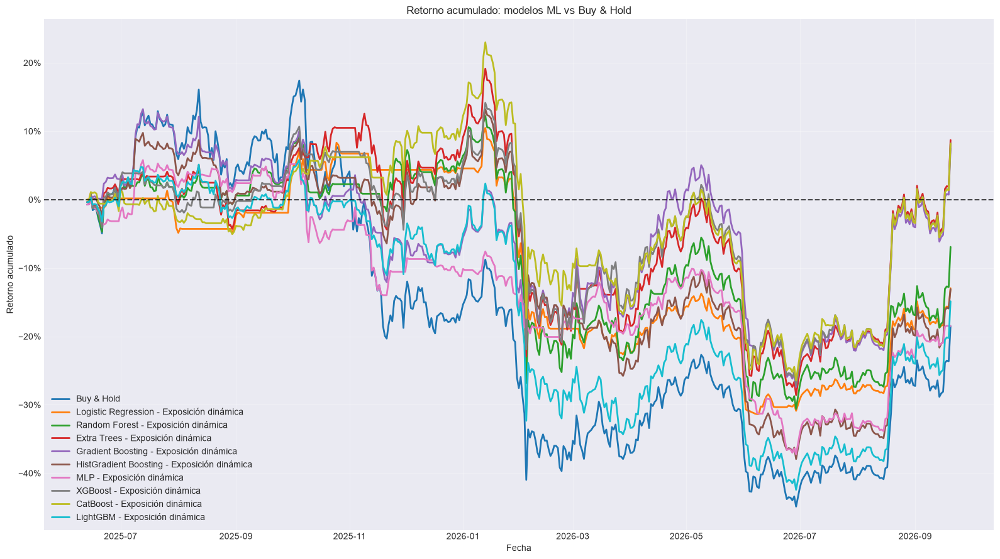

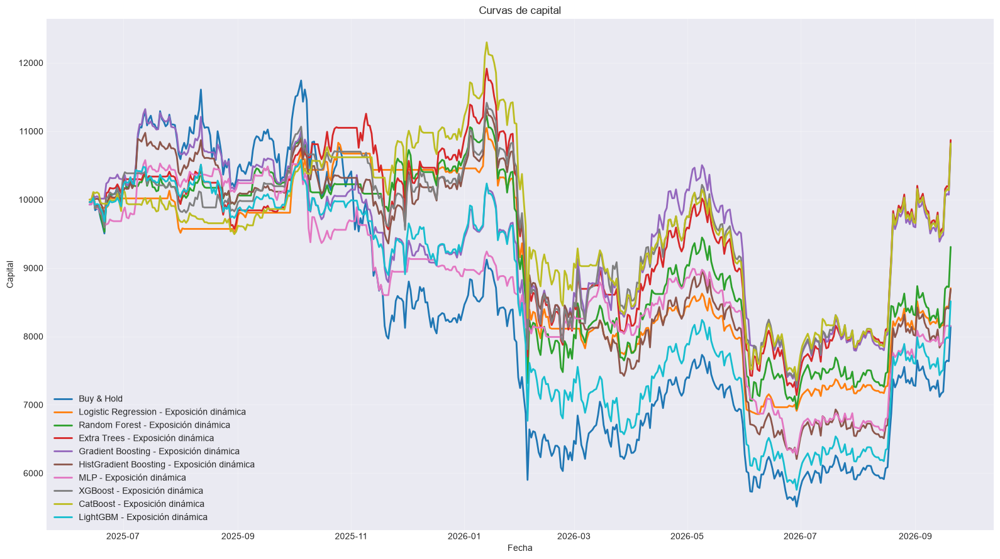

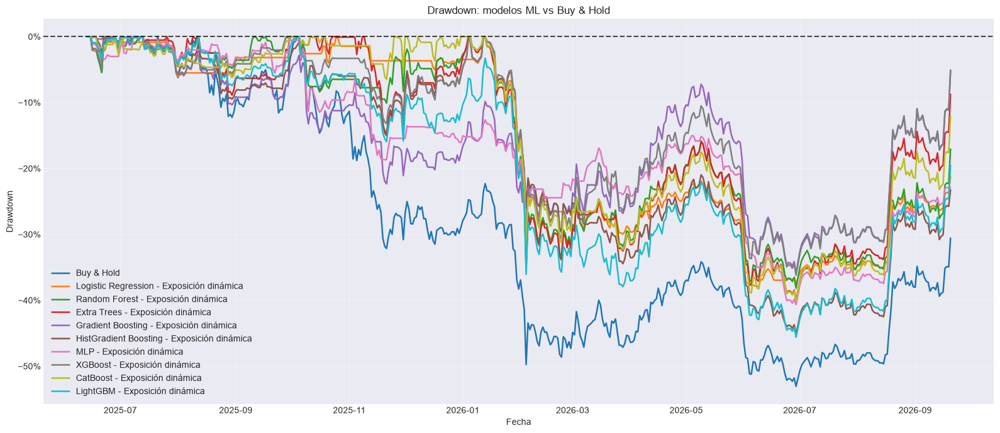


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3426
1,Gradient Boosting,0.3142
2,Logistic Regression,0.3112
3,CatBoost,0.3034
4,HistGradient Boosting,0.3028
5,XGBoost,0.2982
6,LightGBM,0.2981
7,Random Forest,0.2648
8,Extra Trees,0.2616



COMPROBACIONES FINALES
X_dev: 1824
y_dev: 1824
t1_dev: 1824
X_test: 466
y_test: 466
t1_test: 466
test_prices: 466
forward_returns válidos: 465
Logistic Regression shape: (466,) | índice correcto: True
Random Forest shape: (466,) | índice correcto: True
Extra Trees shape: (466,) | índice correcto: True
Gradient Boosting shape: (466,) | índice correcto: True
HistGradient Boosting shape: (466,) | índice correcto: True
MLP shape: (466,) | índice correcto: True
XGBoost shape: (466,) | índice correcto: True
CatBoost shape: (466,) | índice correcto: True
LightGBM shape: (466,) | índice correcto: True

Pipeline terminado correctamente.


In [390]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
       'Bitcoin_log_ret', 'Petroleo_WTI_log_ret', 'Yuan_Chino_log_ret',
       'Indice_Dolar_DXY_log_ret', 'Euro_log_ret', 'Oro_log_ret',
       'Gas_Natural_log_ret', 'S&P_500_log_ret', 'NASDAQ_Tecnologico_log_ret',
       'Nikkei_Asia_log_ret', 'Cardano_log_ret', 'Bitcoin_Cash_log_ret',
       'Ethereum_log_ret', 'Chainlink_log_ret', 'Litecoin_log_ret',
       'Bono_EEUU_5A_diff', 'Bono_EEUU_3M_diff', 'Bono_EEUU_10A_diff',
       'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff', 'BTC_Close', 'SMA',
       'EMA', 'WMA', 'TRIMA', 'KAMA', 'MAMA', 'FAMA', 'T3', 'DEMA', 'TEMA',
       'MACD', 'MACD_Signal', 'MACD_Hist', 'MACDEXT', 'MACDEXT_Signal',
       'MACDEXT_Hist', 'STOCH_SlowK', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP', 'CCI', 'CMO', 'ROC', 'ROCR',
       'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI', 'ULTOSC', 'TRIX',
       'BB_Upper', 'BB_Middle', 'BB_Lower', 'MIDPOINT', 'MIDPRICE', 'SAR',
       'TRANGE', 'ATR', 'NATR', 'AD', 'ADOSC', 'OBV'
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Replica Mejor experimento

In [ ]:
['SP500_log_ret', 'NASDAQ_log_ret', 'Euronext100_log_ret', 'DXY_DollarIndex_log_ret', 'EUR_USD_log_ret', 'Gold_log_ret', 'Crude_Oil_WTI_log_ret', 'US_10Y_Bond_diff', 'US_5Y_Bond_diff', 'VIX_diff',

# Experimento con más variables


In [ ]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC',
       "Bono_EEUU_10A_diff", "Euro_log_ret","ADX", "CMO", "APO", "AD", "OBV", "TRANGE" # AQui
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    #"Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Experimento con Variables Macro

Dimensiones del dataframe: (2369, 103)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 55
FEATURE_LAG: 1
Inicio del test: 2025-06-14 00:00:00

Optimizando Triple Barrier...


Best trial: 77. Best value: 0.817924: 100%|██████████| 80/80 [00:46<00:00,  1.73it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.06882403905529, 'sl_multiplier': 1.8636575872913728, 'max_holding_bars': 9, 'volatility_window': 50}
Score de balance walk-forward: 0.8179

Tamaño desarrollo: 1841
Tamaño test: 465

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,528,28.68%
1,Neutral,1,656,35.63%
2,Sube,2,657,35.69%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,166,35.70%
1,Neutral,1,145,31.18%
2,Sube,2,154,33.12%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.3312
Balanced accuracy: 0.3333
F1 macro: 0.1659

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       203
Neutral    238
Sube        24
Name: count, dtype: int64
Exposición media: 30.75%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja       164
Neutral    131
Sube       170
Name: count, dtype: int64
Exposición media: 50.65%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       164
Neutral    100
Sube       201
Name: count, dtype: int64
Exposición media: 53.98%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        89
Neutral    166
Sube       210
Name: count, dtype: int64
Exposición media: 63.01%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja        80
Neutral    144
Sube       241
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,198.65",-18.01%,-14.44%,42.36%,-0.1569,-0.2244,-53.06%,-0.2722,48.92%,100.00%,$15.00,1.00,1
1,MLP - Exposición dinámica,"$10,777.24",7.77%,6.14%,28.33%,0.3474,0.4659,-24.20%,0.2537,30.82%,47.20%,"$1,589.64",112.50,179
2,Gradient Boosting - Exposición dinámica,"$9,956.38",-0.44%,-0.29%,34.06%,0.1608,0.1945,-39.63%,-0.0072,39.87%,63.04%,"$1,064.09",81.00,121
3,Logistic Regression - Exposición dinámica,"$9,839.83",-1.60%,-1.26%,19.58%,0.0330,0.0341,-23.48%,-0.0539,28.45%,30.82%,$449.68,30.00,51
4,HistGradient Boosting - Exposición dinámica,"$9,559.26",-4.41%,-3.43%,36.00%,0.0815,0.1048,-41.58%,-0.0826,40.09%,67.24%,"$1,421.63",104.00,173
5,LightGBM - Exposición dinámica,"$9,439.68",-5.60%,-4.39%,32.61%,0.0220,0.0309,-37.20%,-0.1180,41.16%,64.55%,"$1,044.56",80.00,140
6,Random Forest - Exposición dinámica,"$9,395.53",-6.04%,-4.80%,32.02%,0.0076,0.0082,-33.90%,-0.1415,30.82%,50.54%,$962.21,70.50,113
7,XGBoost - Exposición dinámica,"$9,103.49",-8.97%,-7.08%,35.67%,-0.0287,-0.0375,-40.56%,-0.1746,38.58%,65.73%,"$1,351.18",104.00,171
8,CatBoost - Exposición dinámica,"$8,883.50",-11.16%,-8.86%,36.18%,-0.0764,-0.0956,-42.53%,-0.2082,37.28%,66.59%,$969.48,77.00,123
9,Extra Trees - Exposición dinámica,"$8,396.72",-16.03%,-12.87%,32.70%,-0.2562,-0.2820,-40.60%,-0.3170,31.47%,54.09%,$964.29,76.00,110



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,MLP - Exposición dinámica,7.77%,-18.01%,25.79%,0.3474,-0.1569,0.5043,-24.20%,-53.06%,28.86%,True,True,True
1,Gradient Boosting - Exposición dinámica,-0.44%,-18.01%,17.58%,0.1608,-0.1569,0.3177,-39.63%,-53.06%,13.43%,True,True,True
2,Logistic Regression - Exposición dinámica,-1.60%,-18.01%,16.41%,0.0330,-0.1569,0.1899,-23.48%,-53.06%,29.58%,True,True,True
3,HistGradient Boosting - Exposición dinámica,-4.41%,-18.01%,13.61%,0.0815,-0.1569,0.2385,-41.58%,-53.06%,11.48%,True,True,True
4,LightGBM - Exposición dinámica,-5.60%,-18.01%,12.41%,0.0220,-0.1569,0.1790,-37.20%,-53.06%,15.86%,True,True,True
5,Random Forest - Exposición dinámica,-6.04%,-18.01%,11.97%,0.0076,-0.1569,0.1645,-33.90%,-53.06%,19.16%,True,True,True
6,XGBoost - Exposición dinámica,-8.97%,-18.01%,9.05%,-0.0287,-0.1569,0.1282,-40.56%,-53.06%,12.50%,True,True,True
7,CatBoost - Exposición dinámica,-11.16%,-18.01%,6.85%,-0.0764,-0.1569,0.0805,-42.53%,-53.06%,10.53%,True,True,True
8,Extra Trees - Exposición dinámica,-16.03%,-18.01%,1.98%,-0.2562,-0.1569,-0.0993,-40.60%,-53.06%,12.46%,True,False,True


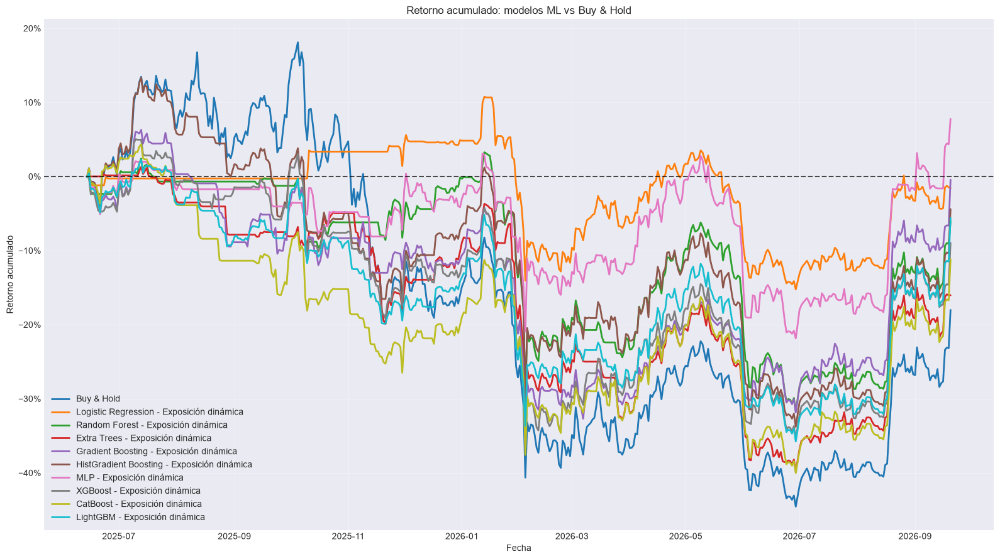

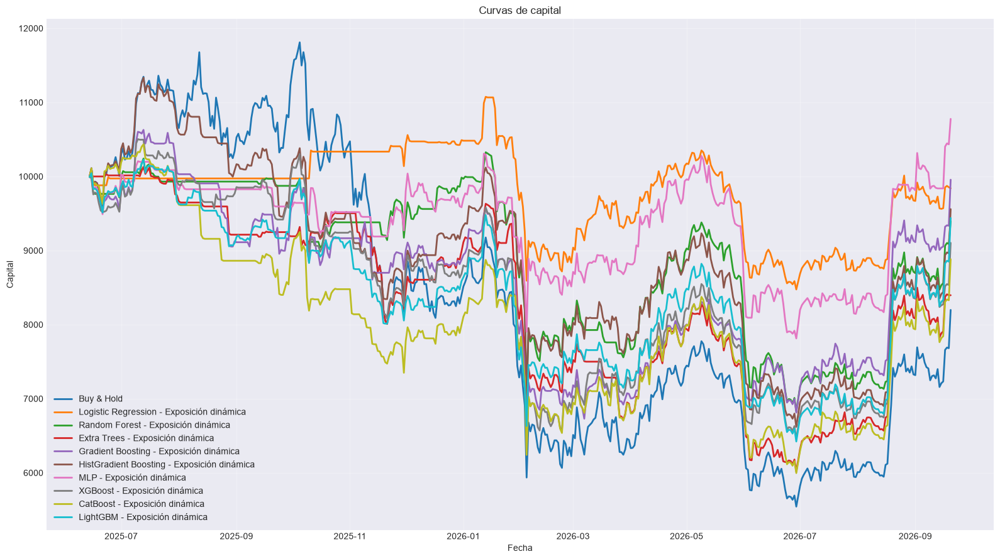

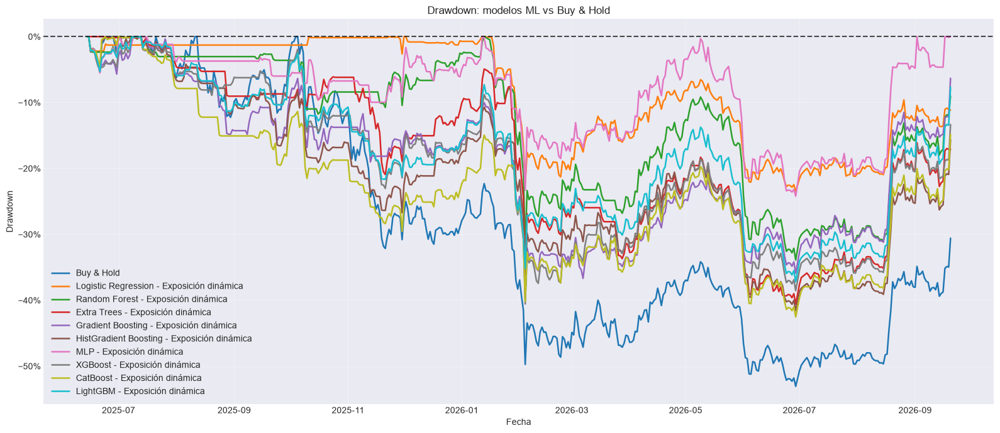


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3278
1,Gradient Boosting,0.3054
2,CatBoost,0.3037
3,HistGradient Boosting,0.2998
4,Logistic Regression,0.2981
5,XGBoost,0.2940
6,Extra Trees,0.2919
7,LightGBM,0.2904
8,Random Forest,0.2797



COMPROBACIONES FINALES
X_dev: 1841
y_dev: 1841
t1_dev: 1841
X_test: 465
y_test: 465
t1_test: 465
test_prices: 465
forward_returns válidos: 464
Logistic Regression shape: (465,) | índice correcto: True
Random Forest shape: (465,) | índice correcto: True
Extra Trees shape: (465,) | índice correcto: True
Gradient Boosting shape: (465,) | índice correcto: True
HistGradient Boosting shape: (465,) | índice correcto: True
MLP shape: (465,) | índice correcto: True
XGBoost shape: (465,) | índice correcto: True
CatBoost shape: (465,) | índice correcto: True
LightGBM shape: (465,) | índice correcto: True

Pipeline terminado correctamente.


In [375]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC',
       "Bono_EEUU_10A_diff", "Euro_log_ret","ADX", "CMO", "APO", "AD", "OBV", "TRANGE" # AQui
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Experimento Depurado

Dimensiones del dataframe: (2369, 103)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 47
FEATURE_LAG: 1
Inicio del test: 2025-06-14 00:00:00

Optimizando Triple Barrier...


Best trial: 77. Best value: 0.817924: 100%|██████████| 80/80 [01:12<00:00,  1.11it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.06882403905529, 'sl_multiplier': 1.8636575872913728, 'max_holding_bars': 9, 'volatility_window': 50}
Score de balance walk-forward: 0.8179

Tamaño desarrollo: 1841
Tamaño test: 465

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,528,28.68%
1,Neutral,1,656,35.63%
2,Sube,2,657,35.69%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,166,35.70%
1,Neutral,1,145,31.18%
2,Sube,2,154,33.12%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 2 Sube
Accuracy: 0.3312
Balanced accuracy: 0.3333
F1 macro: 0.1659

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       330
Neutral     56
Sube        79
Name: count, dtype: int64
Exposición media: 23.01%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja       142
Neutral    179
Sube       144
Name: count, dtype: int64
Exposición media: 50.22%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       146
Neutral    163
Sube       156
Name: count, dtype: int64
Exposición media: 51.08%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       148
Neutral    135
Sube       182
Name: count, dtype: int64
Exposición media: 53.66%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       153
Neutral    148
Sube       164
Name: count, dtype: int64
Exposición m

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$8,198.65",-18.01%,-14.44%,42.36%,-0.1569,-0.2244,-53.06%,-0.2722,48.92%,100.00%,$15.00,1.00,1
1,CatBoost - Exposición dinámica,"$9,689.66",-3.10%,-2.40%,29.26%,0.0631,0.0725,-31.12%,-0.0770,28.88%,49.35%,"$1,850.13",137.00,194
2,LightGBM - Exposición dinámica,"$9,375.77",-6.24%,-4.90%,28.25%,-0.0397,-0.0504,-27.87%,-0.1758,30.60%,52.37%,"$1,430.99",104.00,159
3,HistGradient Boosting - Exposición dinámica,"$8,542.45",-14.58%,-11.68%,30.26%,-0.2577,-0.3050,-38.81%,-0.3009,31.68%,51.29%,"$1,530.69",119.00,187
4,Random Forest - Exposición dinámica,"$8,421.84",-15.78%,-12.61%,29.78%,-0.3038,-0.3399,-35.21%,-0.3582,32.33%,50.32%,"$1,216.74",92.00,148
5,XGBoost - Exposición dinámica,"$8,182.29",-18.18%,-14.58%,29.21%,-0.3934,-0.4181,-32.26%,-0.4519,24.57%,43.00%,"$1,484.13",108.00,164
6,Extra Trees - Exposición dinámica,"$7,730.85",-22.69%,-18.32%,31.33%,-0.4888,-0.5810,-43.57%,-0.4203,30.60%,51.19%,"$1,309.38",105.00,156
7,MLP - Exposición dinámica,"$7,672.18",-23.28%,-18.80%,26.31%,-0.6595,-0.6302,-33.72%,-0.5577,19.61%,32.44%,"$1,238.34",94.00,141
8,Gradient Boosting - Exposición dinámica,"$7,642.50",-23.58%,-19.05%,31.54%,-0.5122,-0.6210,-39.69%,-0.4800,31.47%,53.77%,"$1,581.34",127.00,191
9,Logistic Regression - Exposición dinámica,"$7,153.45",-28.47%,-23.16%,23.86%,-0.9831,-0.7473,-34.32%,-0.6749,12.93%,23.06%,$955.21,75.00,101



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,CatBoost - Exposición dinámica,-3.10%,-18.01%,14.91%,0.0631,-0.1569,0.2200,-31.12%,-53.06%,21.94%,True,True,True
1,LightGBM - Exposición dinámica,-6.24%,-18.01%,11.77%,-0.0397,-0.1569,0.1172,-27.87%,-53.06%,25.19%,True,True,True
2,HistGradient Boosting - Exposición dinámica,-14.58%,-18.01%,3.44%,-0.2577,-0.1569,-0.1008,-38.81%,-53.06%,14.25%,True,False,True
3,Random Forest - Exposición dinámica,-15.78%,-18.01%,2.23%,-0.3038,-0.1569,-0.1468,-35.21%,-53.06%,17.85%,True,False,True
4,XGBoost - Exposición dinámica,-18.18%,-18.01%,-0.16%,-0.3934,-0.1569,-0.2365,-32.26%,-53.06%,20.80%,False,False,True
5,Extra Trees - Exposición dinámica,-22.69%,-18.01%,-4.68%,-0.4888,-0.1569,-0.3319,-43.57%,-53.06%,9.49%,False,False,True
6,MLP - Exposición dinámica,-23.28%,-18.01%,-5.26%,-0.6595,-0.1569,-0.5026,-33.72%,-53.06%,19.34%,False,False,True
7,Gradient Boosting - Exposición dinámica,-23.58%,-18.01%,-5.56%,-0.5122,-0.1569,-0.3553,-39.69%,-53.06%,13.37%,False,False,True
8,Logistic Regression - Exposición dinámica,-28.47%,-18.01%,-10.45%,-0.9831,-0.1569,-0.8262,-34.32%,-53.06%,18.74%,False,False,True


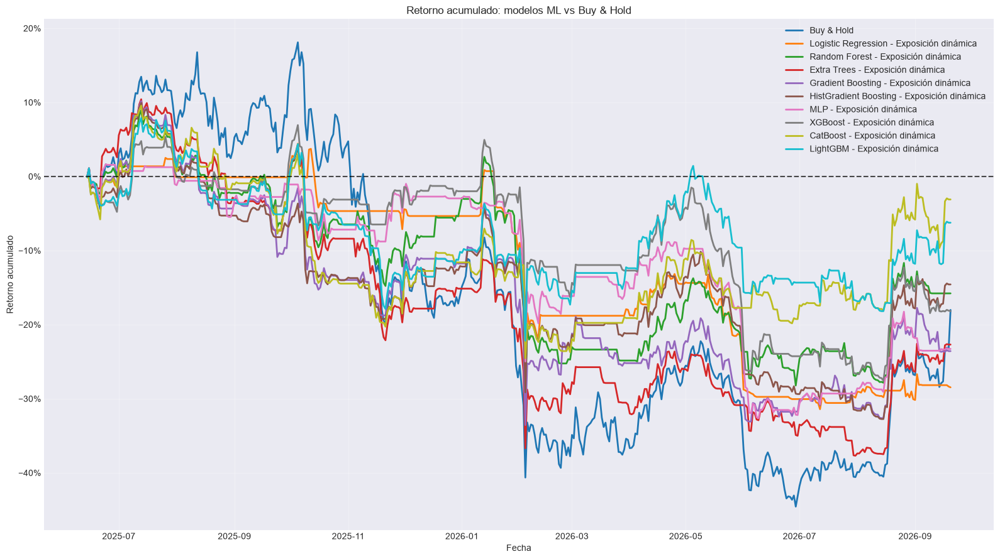

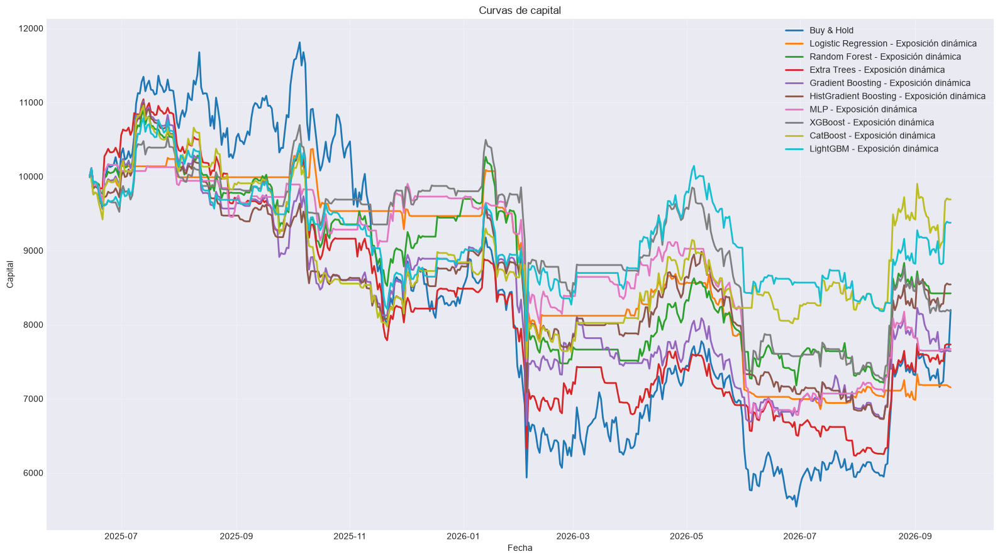

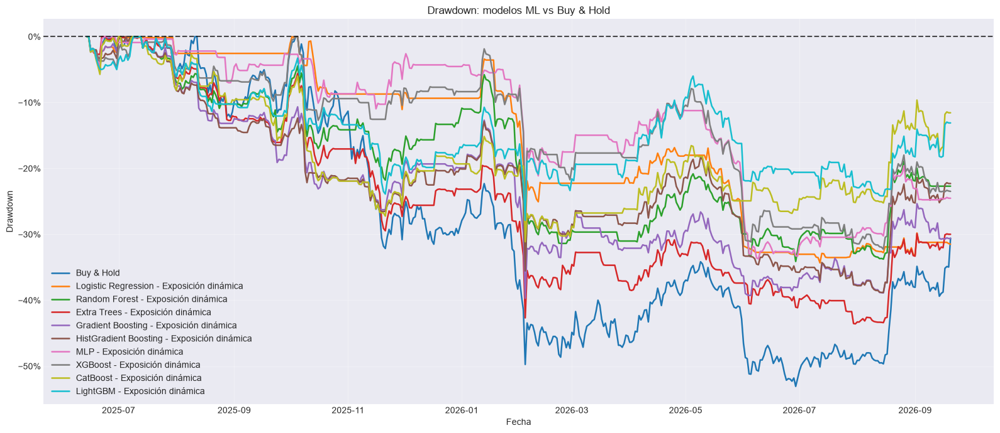


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3388
1,HistGradient Boosting,0.3036
2,Extra Trees,0.3035
3,CatBoost,0.2994
4,LightGBM,0.2988
5,Gradient Boosting,0.2939
6,Random Forest,0.2926
7,XGBoost,0.2914
8,Logistic Regression,0.2895



COMPROBACIONES FINALES
X_dev: 1841
y_dev: 1841
t1_dev: 1841
X_test: 465
y_test: 465
t1_test: 465
test_prices: 465
forward_returns válidos: 464
Logistic Regression shape: (465,) | índice correcto: True
Random Forest shape: (465,) | índice correcto: True
Extra Trees shape: (465,) | índice correcto: True
Gradient Boosting shape: (465,) | índice correcto: True
HistGradient Boosting shape: (465,) | índice correcto: True
MLP shape: (465,) | índice correcto: True
XGBoost shape: (465,) | índice correcto: True
CatBoost shape: (465,) | índice correcto: True
LightGBM shape: (465,) | índice correcto: True

Pipeline terminado correctamente.


In [370]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
# 
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.loc["2022-01-01:"].copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC'
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (2369, 103)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00
Número de features: 47
FEATURE_LAG: 1
Inicio del test: 2025-10-10 00:00:00

Optimizando Triple Barrier...


Best trial: 72. Best value: 0.828873: 100%|██████████| 80/80 [00:55<00:00,  1.44it/s]



Mejor configuración Triple Barrier:
{'pt_multiplier': 2.808305154104139, 'sl_multiplier': 2.192925763918808, 'max_holding_bars': 13, 'volatility_window': 55}
Score de balance walk-forward: 0.8289

Tamaño desarrollo: 1949
Tamaño test: 343

Distribución de desarrollo:


,Clase,Código,Observaciones,Proporción
0,Baja,0,614,31.50%
1,Neutral,1,670,34.38%
2,Sube,2,665,34.12%



Distribución de test:


,Clase,Código,Observaciones,Proporción
0,Baja,0,120,34.99%
1,Neutral,1,131,38.19%
2,Sube,2,92,26.82%


... (26 outputs left out)


BASELINE NAIVE
Clase mayoritaria: 1 Neutral
Accuracy: 0.3819
Balanced accuracy: 0.3333
F1 macro: 0.1842

Periodos por año: 365.0

Logistic Regression - Exposición dinámica
Distribución de predicciones:
prediction
Baja       198
Neutral     50
Sube        95
Name: count, dtype: int64
Exposición media: 34.99%

Random Forest - Exposición dinámica
Distribución de predicciones:
prediction
Baja       150
Neutral     74
Sube       119
Name: count, dtype: int64
Exposición media: 45.48%

Extra Trees - Exposición dinámica
Distribución de predicciones:
prediction
Baja       134
Neutral     79
Sube       130
Name: count, dtype: int64
Exposición media: 49.42%

Gradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       131
Neutral     81
Sube       131
Name: count, dtype: int64
Exposición media: 50.00%

HistGradient Boosting - Exposición dinámica
Distribución de predicciones:
prediction
Baja       110
Neutral    100
Sube       133
Name: count, dtype: int64
Exposició

,Estrategia,Capital final,Retorno total,CAGR,Volatilidad anualizada,Sharpe,Sortino,Máximo drawdown,Calmar,Win rate,Exposición media,Costes acumulados,Turnover acumulado,Cambios de posición
0,Buy & Hold,"$6,738.25",-32.62%,-32.83%,44.66%,-0.7197,-1.0367,-49.20%,-0.6673,47.95%,100.00%,$15.00,1.00,1
1,XGBoost - Exposición dinámica,"$9,181.63",-8.18%,-8.73%,28.39%,-0.1792,-0.2121,-26.89%,-0.3248,32.75%,53.65%,"$1,021.65",72.00,105
2,CatBoost - Exposición dinámica,"$9,137.00",-8.63%,-6.94%,33.06%,-0.1256,-0.1453,-29.21%,-0.2377,29.53%,52.78%,"$1,383.48",107.00,141
3,Extra Trees - Exposición dinámica,"$9,133.48",-8.67%,-9.25%,32.74%,-0.1307,-0.1348,-31.96%,-0.2893,28.95%,49.27%,$727.95,55.00,81
4,Random Forest - Exposición dinámica,"$9,067.04",-9.33%,-9.95%,30.59%,-0.1875,-0.1906,-30.30%,-0.3284,27.19%,45.47%,$878.19,64.00,85
5,LightGBM - Exposición dinámica,"$8,682.30",-13.18%,-14.04%,34.33%,-0.2669,-0.3083,-31.38%,-0.4473,33.33%,57.02%,$997.61,73.00,103
6,HistGradient Boosting - Exposición dinámica,"$8,011.07",-19.89%,-21.13%,30.14%,-0.6315,-0.6769,-30.45%,-0.6939,31.29%,53.36%,$994.35,77.50,114
7,Gradient Boosting - Exposición dinámica,"$7,654.36",-23.46%,-24.88%,31.34%,-0.7508,-0.8110,-36.89%,-0.6745,28.07%,50.00%,$979.82,82.50,119
8,Logistic Regression - Exposición dinámica,"$6,582.03",-34.18%,-36.09%,30.74%,-1.2959,-1.1442,-40.31%,-0.8952,18.71%,34.80%,$704.21,57.00,76
9,MLP - Exposición dinámica,"$6,421.61",-35.78%,-37.75%,31.00%,-1.3708,-1.6719,-39.12%,-0.9650,28.07%,50.15%,$989.33,78.00,111



COMPARACIÓN CONTRA BUY & HOLD


,Estrategia,Retorno estrategia,Retorno Buy & Hold,Diferencia retorno,Sharpe estrategia,Sharpe Buy & Hold,Diferencia Sharpe,Drawdown estrategia,Drawdown Buy & Hold,Diferencia drawdown,Supera retorno,Supera Sharpe,Menor drawdown
0,XGBoost - Exposición dinámica,-8.18%,-32.62%,24.43%,-0.1792,-0.7197,0.5406,-26.89%,-49.20%,22.31%,True,True,True
1,CatBoost - Exposición dinámica,-8.63%,-32.62%,23.99%,-0.1256,-0.7197,0.5942,-29.21%,-49.20%,19.99%,True,True,True
2,Extra Trees - Exposición dinámica,-8.67%,-32.62%,23.95%,-0.1307,-0.7197,0.5890,-31.96%,-49.20%,17.24%,True,True,True
3,Random Forest - Exposición dinámica,-9.33%,-32.62%,23.29%,-0.1875,-0.7197,0.5322,-30.30%,-49.20%,18.90%,True,True,True
4,LightGBM - Exposición dinámica,-13.18%,-32.62%,19.44%,-0.2669,-0.7197,0.4528,-31.38%,-49.20%,17.82%,True,True,True
5,HistGradient Boosting - Exposición dinámica,-19.89%,-32.62%,12.73%,-0.6315,-0.7197,0.0883,-30.45%,-49.20%,18.75%,True,True,True
6,Gradient Boosting - Exposición dinámica,-23.46%,-32.62%,9.16%,-0.7508,-0.7197,-0.0310,-36.89%,-49.20%,12.31%,True,False,True
7,Logistic Regression - Exposición dinámica,-34.18%,-32.62%,-1.56%,-1.2959,-0.7197,-0.5762,-40.31%,-49.20%,8.89%,False,False,True
8,MLP - Exposición dinámica,-35.78%,-32.62%,-3.17%,-1.3708,-0.7197,-0.6511,-39.12%,-49.20%,10.08%,False,False,True


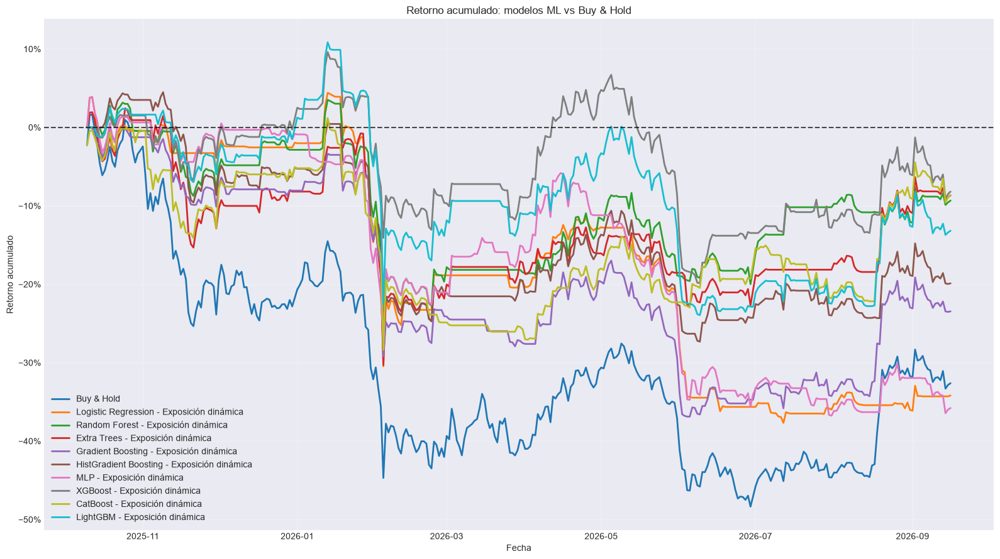

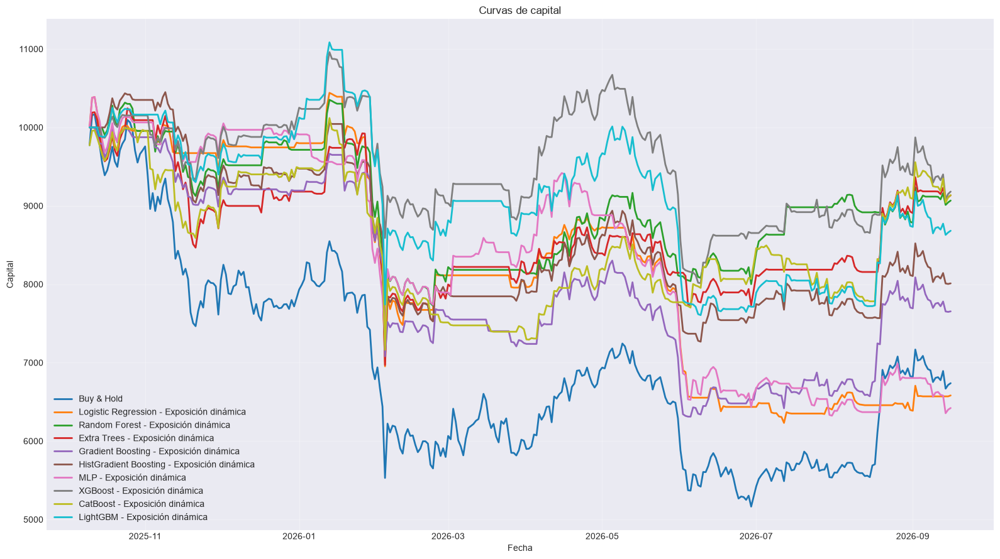

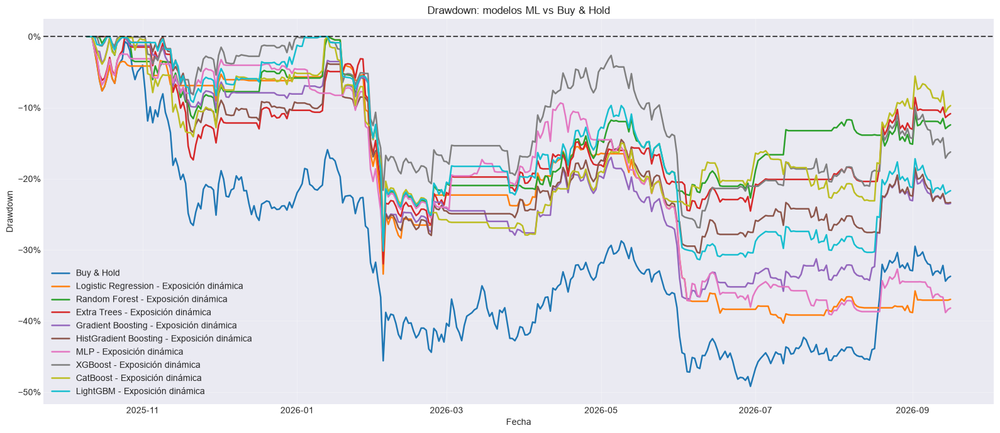


RANKING DE MODELOS POR VALIDACIÓN CV


,Modelo,F1 CV
0,MLP,0.3226
1,CatBoost,0.2940
2,Extra Trees,0.2870
3,Random Forest,0.2803
4,XGBoost,0.2732
5,Logistic Regression,0.2692
6,LightGBM,0.2689
7,Gradient Boosting,0.2597
8,HistGradient Boosting,0.2566



COMPROBACIONES FINALES
X_dev: 1949
y_dev: 1949
t1_dev: 1949
X_test: 343
y_test: 343
t1_test: 343
test_prices: 343
forward_returns válidos: 342
Logistic Regression shape: (343,) | índice correcto: True
Random Forest shape: (343,) | índice correcto: True
Extra Trees shape: (343,) | índice correcto: True
Gradient Boosting shape: (343,) | índice correcto: True
HistGradient Boosting shape: (343,) | índice correcto: True
MLP shape: (343,) | índice correcto: True
XGBoost shape: (343,) | índice correcto: True
CatBoost shape: (343,) | índice correcto: True
LightGBM shape: (343,) | índice correcto: True

Pipeline terminado correctamente.


In [377]:
# Experimento depurado 2
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 35

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.15

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Indice_Dolar_DXY_log_ret', 'Oro_log_ret', 'S&P_500_log_ret',
       'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Cardano_log_ret', 'Cardano_log_ret_7', 'Cardano_log_ret_14',
       'Bitcoin_Cash_log_ret', 'Bitcoin_Cash_log_ret_7',
       'Bitcoin_Cash_log_ret_14', 'Ethereum_log_ret', 'Ethereum_log_ret_7',
       'Ethereum_log_ret_14', 'Chainlink_log_ret', 'Chainlink_log_ret_7',
       'Chainlink_log_ret_14', 'Litecoin_log_ret', 'Litecoin_log_ret_7',
       'Litecoin_log_ret_14', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'EMA', 'MACD', 'MACD_Hist', 'STOCH_SlowD', 'STOCHF_FastK',
       'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK', 'STOCHRSI_FastD', 'WILLR',
       'BOP', 'CCI', 'ROC', 'AROON_Down', 'AROON_Up', 'AROONOSC', 'MFI',
       'ULTOSC', 'NATR', 'ADOSC'
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Experimento sin Gradient Boosting

In [ ]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 30

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = ['Cardano', 'Bitcoin_Cash', 'Ethereum', 'Chainlink', 'Litecoin',
       'Bitcoin_log_ret', 'Bitcoin_log_ret_7', 'Bitcoin_log_ret_14',
       'Petroleo_WTI_log_ret', 'Petroleo_WTI_log_ret_7',
       'Petroleo_WTI_log_ret_14', 'Yuan_Chino_log_ret', 'Yuan_Chino_log_ret_7',
       'Yuan_Chino_log_ret_14', 'Indice_Dolar_DXY_log_ret',
       'Indice_Dolar_DXY_log_ret_7', 'Indice_Dolar_DXY_log_ret_14',
       'Euro_log_ret', 'Euro_log_ret_7', 'Euro_log_ret_14', 'Oro_log_ret',
       'Oro_log_ret_7', 'Oro_log_ret_14', 'Gas_Natural_log_ret',
       'Gas_Natural_log_ret_7', 'Gas_Natural_log_ret_14', 'S&P_500_log_ret',
       'S&P_500_log_ret_7', 'S&P_500_log_ret_14', 'NASDAQ_Tecnologico_log_ret',
       'NASDAQ_Tecnologico_log_ret_7', 'NASDAQ_Tecnologico_log_ret_14',
       'Nikkei_Asia_log_ret', 'Nikkei_Asia_log_ret_7',
       'Nikkei_Asia_log_ret_14', 'Bono_EEUU_5A_diff', 'Bono_EEUU_3M_diff',
       'Bono_EEUU_10A_diff', 'Indice_Volatilidad_VIX_diff', 'BTC_Volume_diff',
       'BTC_Close', 'SMA', 'EMA', 'WMA', 'TRIMA', 'KAMA', 'MAMA', 'FAMA', 'T3',
       'DEMA', 'TEMA', 'MACD', 'MACD_Signal', 'MACD_Hist', 'MACDEXT',
       'MACDEXT_Signal', 'MACDEXT_Hist', 'STOCH_SlowK', 'STOCH_SlowD',
       'STOCHF_FastK', 'STOCHF_FastD', 'RSI', 'STOCHRSI_FastK',
       'STOCHRSI_FastD', 'WILLR', 'ADX', 'ADXR', 'APO', 'PPO', 'MOM', 'BOP',
       'CCI', 'CMO', 'ROC', 'ROCR', 'AROON_Down', 'AROON_Up', 'AROONOSC',
       'MFI', 'ULTOSC', 'TRIX', 'BB_Upper', 'BB_Middle', 'BB_Lower',
       'MIDPOINT', 'MIDPRICE', 'SAR', 'TRANGE', 'ATR', 'NATR', 'AD', 'ADOSC',
       'OBV'
                                  
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    #"Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

In [368]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10


CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_bitcoin.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)



# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
   "Bitcoin_log_ret",
    "SP500_log_ret",
    "NASDAQ_log_ret",
    "Euronext100_log_ret",
    "DXY_DollarIndex_log_ret",
    "EUR_USD_log_ret",
    "Gold_log_ret",
    "Crude_Oil_WTI_log_ret",
    "US_10Y_Bond_diff",
    "US_5Y_Bond_diff",
    "VIX_diff",

    "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "VWAP_Premium",

    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

Dimensiones del dataframe: (2369, 103)
Primer registro: 2020-04-02 00:00:00
Último registro: 2026-09-30 00:00:00


ValueError: Faltan estas features:
['SP500_log_ret', 'NASDAQ_log_ret', 'Euronext100_log_ret', 'DXY_DollarIndex_log_ret', 'EUR_USD_log_ret', 'Gold_log_ret', 'Crude_Oil_WTI_log_ret', 'US_10Y_Bond_diff', 'US_5Y_Bond_diff', 'VIX_diff', 'VWAP_Premium']

In [ ]:
# ============================================================
# PIPELINE COMPLETO PARA BITCOIN  
#
# Triple Barrier + Optuna
# Purged Walk-Forward CV + Embargo
# XGBoost + CatBoost + LightGBM
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
#
# MODELOS:
#
#     Logistic Regression
#     Random Forest
#     Extra Trees
#     Gradient Boosting
#     HistGradient Boosting
#     MLP
#     XGBoost
#     CatBoost
#     LightGBM
#
# ELIMINADOS:
#
#     SVM RBF
#     KNN
#     Gaussian Naive Bayes
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# Las features de t-1 se usan para predecir el evento
# iniciado en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización agregada
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10

# VWAP
VWAP_WINDOW = 30
RECALCULAR_VWAP = True

VWAP_HIGH_COL = "BTC_High"
VWAP_LOW_COL = "BTC_Low"
VWAP_CLOSE_COL = "BTC_Close"
VWAP_VOLUME_COL = "BTC_Volume"

CLOSE_COL = "BTC_Close"

# Costes estimados:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Debe existir df_b previamente.
df = df_b.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "df_b debe tener un DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "df_b debe estar ordenado cronológicamente."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

# Sin precio no puede existir target ni backtest.
df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Dimensiones del dataframe:",
    df.shape
)

print(
    "Primer registro:",
    df.index.min()
)

print(
    "Último registro:",
    df.index.max()
)


# ============================================================
# 3. VWAP PREMIUM CAUSAL
# ============================================================

def construir_vwap_premium_rolling(
    data,
    high_col,
    low_col,
    close_col,
    volume_col,
    window
):
    """
    VWAP rolling causal.

    En t utiliza solamente datos de [t-window+1, t].
    Posteriormente X_all se desplaza una barra.
    """

    required = [
        high_col,
        low_col,
        close_col,
        volume_col
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            "Faltan columnas para VWAP_Premium:\n"
            f"{missing}"
        )

    high = pd.to_numeric(
        data[high_col],
        errors="coerce"
    )

    low = pd.to_numeric(
        data[low_col],
        errors="coerce"
    )

    close = pd.to_numeric(
        data[close_col],
        errors="coerce"
    )

    volume = pd.to_numeric(
        data[volume_col],
        errors="coerce"
    )

    typical_price = (
        high
        +
        low
        +
        close
    ) / 3.0

    price_volume = (
        typical_price
        *
        volume
    )

    rolling_price_volume = (
        price_volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = (
        volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = rolling_volume.replace(
        0,
        np.nan
    )

    rolling_vwap = (
        rolling_price_volume
        /
        rolling_volume
    )

    return (
        close
        /
        rolling_vwap
        -
        1.0
    ).rename(
        "VWAP_Premium"
    )


if RECALCULAR_VWAP:

    vwap_columns = [
        VWAP_HIGH_COL,
        VWAP_LOW_COL,
        VWAP_CLOSE_COL,
        VWAP_VOLUME_COL
    ]

    if all(
        col in df.columns
        for col in vwap_columns
    ):

        df["VWAP_Premium"] = (
            construir_vwap_premium_rolling(
                data=df,
                high_col=VWAP_HIGH_COL,
                low_col=VWAP_LOW_COL,
                close_col=VWAP_CLOSE_COL,
                volume_col=VWAP_VOLUME_COL,
                window=VWAP_WINDOW
            )
        )

        print(
            "VWAP_Premium recalculado con rolling causal."
        )

    else:

        print(
            "VWAP_Premium no se recalculó porque faltan "
            "columnas OHLCV. Se usará la columna existente."
        )


# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
    "Bitcoin_log_ret",
    "SP500_log_ret",
    "NASDAQ_log_ret",
    "Euronext100_log_ret",
    "DXY_DollarIndex_log_ret",
    "EUR_USD_log_ret",
    "Gold_log_ret",
    "Crude_Oil_WTI_log_ret",
    "US_10Y_Bond_diff",
    "US_5Y_Bond_diff",
    "VIX_diff",

    "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "VWAP_Premium",

    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan estas features:\n"
        f"{missing_features}"
    )

for col in feature_cols:

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no tienen el mismo índice."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Clases:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa únicamente información pasada.
    El precio no se desplaza.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        # No etiquetar eventos incompletos
        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2
            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0
            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1
            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index tiene duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado cronológicamente."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits
            +
            2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits
            +
            1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold
                +
                1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits
                -
                1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición equivalente en el índice completo
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo contado sobre barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. PREPARACIÓN Y ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    # Desarrollo:
    # el evento empieza antes del test y termina antes del test.
    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    # Test:
    # el evento comienza en el período de test.
    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mean_absolute_error = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mean_absolute_error
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y=y_val,
            min_class_fraction=MIN_CLASS_FRACTION_FOLD,
            min_class_count=MIN_CLASS_COUNT_FOLD
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_proportions = (
            train_counts
            /
            train_counts.sum()
        )

        val_proportions = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,
                "Train Baja": train_proportions.loc[0],
                "Train Neutral": train_proportions.loc[1],
                "Train Sube": train_proportions.loc[2],
                "Val Baja": val_proportions.loc[0],
                "Val Neutral": val_proportions.loc[1],
                "Val Sube": val_proportions.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            data=df,
            close_col=CLOSE_COL,
            pt_multiplier=params[
                "pt_multiplier"
            ],
            sl_multiplier=params[
                "sl_multiplier"
            ],
            max_holding_bars=params[
                "max_holding_bars"
            ],
            volatility_window=params[
                "volatility_window"
            ]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ].copy()

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X=X_tb,
            y=y_tb,
            t1=t1_tb,
            splitter=splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score de balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS DEFINITIVOS
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución de desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución de test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X=X_dev,
        y=y_dev,
        t1=t1_dev,
        splitter=splitter_diagnostic
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    """
    Devuelve probabilidades en orden:

        columna 0 -> Baja
        columna 1 -> Neutral
        columna 2 -> Sube
    """

    if hasattr(
        model,
        "predict_proba"
    ):

        raw_proba = model.predict_proba(
            X
        )

        raw_proba = np.asarray(
            raw_proba
        )

        if raw_proba.ndim != 2:
            raise ValueError(
                "predict_proba debe devolver una matriz 2D."
            )

        if hasattr(
            model,
            "classes_"
        ):
            model_classes = np.asarray(
                model.classes_
            ).astype(int)

        else:
            model_classes = np.asarray(
                TARGET_LABELS
            )

        ordered_proba = np.zeros(
            (
                len(X),
                len(TARGET_LABELS)
            ),
            dtype=float
        )

        for source_column, class_label in enumerate(
            model_classes
        ):

            if class_label not in TARGET_LABELS:
                continue

            target_column = TARGET_LABELS.index(
                int(class_label)
            )

            ordered_proba[
                :,
                target_column
            ] = raw_proba[
                :,
                source_column
            ]

        row_sums = ordered_proba.sum(
            axis=1
        )

        if np.any(
            row_sums <= 0
        ):
            raise ValueError(
                "Existen filas con probabilidades nulas."
            )

        ordered_proba = (
            ordered_proba
            /
            row_sums.reshape(
                -1,
                1
            )
        )

        return ordered_proba

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        scores = np.asarray(
            scores
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1.0,
            denominator
        )

    return None


def normalizar_predicciones(
    y_pred,
    expected_length,
    model_name
):
    """
    Convierte formas:

        (n,)
        (n, 1)

    a:

        (n,)
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != expected_length:
        raise ValueError(
            f"{model_name}: se recibieron "
            f"{len(y_pred_array)} predicciones, "
            f"pero se esperaban {expected_length}."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    return y_pred_array


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:

            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:

            metrics["roc_auc_ovr"] = np.nan

    else:

        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        class_name = TARGET_NAMES[label]

        metrics[
            f"precision_{class_name}"
        ] = precision_class[i]

        metrics[
            f"recall_{class_name}"
        ] = recall_class[i]

        metrics[
            f"f1_{class_name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "MLP",
    "XGBoost",
    "CatBoost",
    "LightGBM"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    # --------------------------------------------------------
    # Logistic Regression
    # --------------------------------------------------------

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),

            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),

            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # HistGradient Boosting
    # --------------------------------------------------------

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),

            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),

            random_state=RANDOM_STATE
        )


    # --------------------------------------------------------
    # MLP
    # --------------------------------------------------------

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),

            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),

            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),

            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),

            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),

            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True


    # --------------------------------------------------------
    # XGBoost
    # --------------------------------------------------------

    elif model_name == "XGBoost":

        model = XGBClassifier(
            objective="multi:softprob",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            min_child_weight=trial.suggest_float(
                "min_child_weight",
                1.0,
                20.0,
                log=True
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            gamma=trial.suggest_float(
                "gamma",
                1e-8,
                5.0,
                log=True
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            tree_method="hist",
            eval_metric="mlogloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=0
        )


    # --------------------------------------------------------
    # CatBoost
    # --------------------------------------------------------

    elif model_name == "CatBoost":

        model = CatBoostClassifier(
            loss_function="MultiClass",

            iterations=trial.suggest_int(
                "iterations",
                100,
                600,
                step=50
            ),

            depth=trial.suggest_int(
                "depth",
                3,
                10
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg",
                1e-3,
                30.0,
                log=True
            ),

            random_strength=trial.suggest_float(
                "random_strength",
                1e-8,
                10.0,
                log=True
            ),

            border_count=trial.suggest_int(
                "border_count",
                32,
                255
            ),

            auto_class_weights=trial.suggest_categorical(
                "auto_class_weights",
                [
                    None,
                    "Balanced"
                ]
            ),

            verbose=False,
            allow_writing_files=False,
            random_seed=RANDOM_STATE,
            thread_count=-1
        )


    # --------------------------------------------------------
    # LightGBM
    # --------------------------------------------------------

    elif model_name == "LightGBM":

        model = LGBMClassifier(
            objective="multiclass",
            num_class=3,

            n_estimators=trial.suggest_int(
                "n_estimators",
                100,
                600,
                step=50
            ),

            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),

            num_leaves=trial.suggest_int(
                "num_leaves",
                7,
                127
            ),

            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),

            min_child_samples=trial.suggest_int(
                "min_child_samples",
                10,
                100
            ),

            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),

            colsample_bytree=trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

            reg_alpha=trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

            reg_lambda=trial.suggest_float(
                "reg_lambda",
                1e-5,
                10.0,
                log=True
            ),

            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),

            verbosity=-1,
            n_jobs=-1,
            random_state=RANDOM_STATE
        )


    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )


    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. EVALUACIÓN CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter,
    devolver_folds=False
):
    """
    F1 macro medio de los folds.

    Si el modelo predice una sola clase en cualquier fold,
    recibe score 0.
    """

    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(
            X,
            t1
        ),
        start=1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred_raw = model_fold.predict(
            X_val
        )

        y_pred = np.asarray(
            y_pred_raw
        ).reshape(-1)

        if len(
            np.unique(y_pred)
        ) < 2:

            if devolver_folds:

                return (
                    0.0,
                    pd.DataFrame(
                        rows
                    )
                )

            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

        rows.append(
            {
                "Fold": fold_number,
                "F1 macro": score,
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Clases reales": y_val.nunique(),
                "Clases predichas": len(
                    np.unique(y_pred)
                )
            }
        )

    if not scores:

        if devolver_folds:

            return (
                -1.0,
                pd.DataFrame(
                    rows
                )
            )

        return -1.0

    final_score = float(
        np.mean(scores)
    )

    if devolver_folds:

        return (
            final_score,
            pd.DataFrame(
                rows
            )
        )

    return final_score


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}
optimization_results = {}

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando modelo:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial=trial,
            model_name=current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model=model,
                X=X_dev,
                y=y_dev,
                t1=t1_dev,
                splitter=splitter_model
            )

        except Exception:

            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:

        print(
            "No se encontró configuración válida."
        )

        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        trial=best_trial,
        model_name=model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results[
        model_name
    ] = study_model


if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando en test:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # El test no participa en el entrenamiento.
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred_raw = final_model.predict(
        X_test
    )

    # Corrección del error (n, 1) -> (n,)
    y_pred = np.asarray(
        y_pred_raw
    ).reshape(-1)

    if len(y_pred) != len(X_test):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    y_pred = y_pred.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(y_pred),
        np.asarray(TARGET_LABELS)
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            f"{model_name}: clases inválidas: "
            f"{invalid_classes.tolist()}"
        )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction",
        dtype=int
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in TARGET_LABELS
            ]
        )

    metrics = calcular_metricas(
        y_true=y_test,
        y_pred=y_pred,
        y_proba=y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,

            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],

            "Accuracy Test": metrics[
                "accuracy"
            ],

            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],

            "Precision Macro Test": metrics[
                "precision_macro"
            ],

            "Recall Macro Test": metrics[
                "recall_macro"
            ],

            "F1 Macro Test": metrics[
                "f1_macro"
            ],

            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],

            "Recall Baja": metrics[
                "recall_Baja"
            ],

            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],

            "Recall Neutral": metrics[
                "recall_Neutral"
            ],

            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],

            "Recall Sube": metrics[
                "recall_Sube"
            ],

            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 150
)

print(
    "TABLA COMPLETA"
)

print(
    "=" * 150
)

display(
    tabla_final.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}",

            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",

            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",

            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_true=y_test,
    y_pred=y_pred_naive,
    y_proba=None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. PRECIOS Y RETORNOS PARA BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .reindex(
        test_index
    )
)

if test_prices.isna().any():

    invalid_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{invalid_dates}"
    )

# Retorno desde t hasta t+1
forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


# ============================================================
# 20. FUNCIONES DEL BACKTEST
# ============================================================

def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = float(
        equity.iloc[0]
    )

    final = float(
        equity.iloc[-1]
    )

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final
            /
            initial
        )
        **
        (
            1.0
            /
            years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    """
    La posición en t se aplica al retorno t -> t+1.

    El coste se calcula sobre el capital disponible antes
    del cambio de posición.
    """

    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay fechas comunes."
        )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if not (
        prices.index.equals(
            forward_returns.index
        )
        and
        prices.index.equals(
            position.index
        )
    ):
        raise ValueError(
            f"{strategy_name}: objetos desalineados."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    gross_return = (
        position
        *
        forward_returns
    )

    equity_values = []
    cost_dollars_values = []
    net_return_values = []

    equity_previous = INITIAL_CAPITAL

    for timestamp in common_index:

        current_turnover = float(
            turnover.loc[timestamp]
        )

        current_gross_return = float(
            gross_return.loc[timestamp]
        )

        # Coste monetario real
        current_cost_dollars = (
            equity_previous
            *
            current_turnover
            *
            COST_PER_TURNOVER
        )

        equity_after_gross = (
            equity_previous
            *
            (
                1.0
                +
                current_gross_return
            )
        )

        equity_current = (
            equity_after_gross
            -
            current_cost_dollars
        )

        if equity_previous > 0:

            current_net_return = (
                equity_current
                /
                equity_previous
                -
                1.0
            )

        else:

            current_net_return = -1.0

        equity_values.append(
            equity_current
        )

        cost_dollars_values.append(
            current_cost_dollars
        )

        net_return_values.append(
            current_net_return
        )

        equity_previous = equity_current

    equity = pd.Series(
        equity_values,
        index=common_index,
        name="equity"
    )

    transaction_costs = pd.Series(
        cost_dollars_values,
        index=common_index,
        name="transaction_cost_dollars"
    )

    net_returns = pd.Series(
        net_return_values,
        index=common_index,
        name="net_return"
    )

    drawdown = calcular_drawdown(
        equity
    )

    return_std = net_returns.std(
        ddof=1
    )

    negative_returns = net_returns[
        net_returns < 0
    ]

    downside_std = negative_returns.std(
        ddof=1
    )

    annualized_volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):

        sharpe = (
            net_returns.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):

        sortino = (
            net_returns.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )

    else:

        sortino = np.nan

    max_drawdown = float(
        drawdown.min()
    )

    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):

        calmar = (
            cagr
            /
            abs(max_drawdown)
        )

    else:

        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "gross_return": gross_return,
            "net_return": net_returns,
            "transaction_cost_dollars": transaction_costs,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,

        "Capital final": equity.iloc[-1],

        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),

        "CAGR": cagr,

        "Volatilidad anualizada": annualized_volatility,

        "Sharpe": sharpe,

        "Sortino": sortino,

        "Máximo drawdown": max_drawdown,

        "Calmar": calmar,

        "Win rate": (
            net_returns > 0
        ).mean(),

        "Exposición media": position.mean(),

        "Costes acumulados": transaction_costs.sum(),

        "Turnover acumulado": turnover.sum(),

        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    """
    Baja    -> 0.0
    Neutral -> 0.5
    Sube    -> 1.0
    """

    y_pred_array = np.asarray(
        y_pred
    ).reshape(-1)

    if len(y_pred_array) != len(X_test):
        raise ValueError(
            "La longitud de la predicción no coincide "
            "con X_test."
        )

    y_pred_array = y_pred_array.astype(int)

    invalid_classes = np.setdiff1d(
        np.unique(
            y_pred_array
        ),
        np.asarray(
            TARGET_LABELS
        )
    )

    if len(invalid_classes) > 0:
        raise ValueError(
            "Clases inválidas en la predicción: "
            f"{invalid_classes.tolist()}"
        )

    y_pred_series = pd.Series(
        y_pred_array,
        index=X_test.index,
        name="prediction"
    )

    exposure = np.select(
        [
            y_pred_series == 0,
            y_pred_series == 1,
            y_pred_series == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 21. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        strategy_name="Buy & Hold",
        position=buy_hold_position,
        prices=test_prices,
        forward_returns=forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 22. ESTRATEGIAS DE LOS MODELOS
# ============================================================

for model_name in best_models:

    y_pred_model = test_predictions[
        model_name
    ]

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        raise ValueError(
            f"{model_name}: predicciones y X_test "
            "no tienen el mismo índice."
        )

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name=strategy_name,
            position=position_model,
            prices=test_prices,
            forward_returns=forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Distribución de predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 23. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 150
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 150
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 24. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

buy_hold_row = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],

            "Retorno estrategia": row[
                "Retorno total"
            ],

            "Retorno Buy & Hold": buy_hold_row[
                "Retorno total"
            ],

            "Diferencia retorno": (
                row["Retorno total"]
                -
                buy_hold_row["Retorno total"]
            ),

            "Sharpe estrategia": row[
                "Sharpe"
            ],

            "Sharpe Buy & Hold": buy_hold_row[
                "Sharpe"
            ],

            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                buy_hold_row["Sharpe"]
            ),

            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],

            "Drawdown Buy & Hold": buy_hold_row[
                "Máximo drawdown"
            ],

            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                buy_hold_row["Máximo drawdown"]
            ),

            "Supera retorno": (
                row["Retorno total"]
                >
                buy_hold_row["Retorno total"]
            ),

            "Supera Sharpe": (
                row["Sharpe"]
                >
                buy_hold_row["Sharpe"]
            ),

            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    buy_hold_row[
                        "Máximo drawdown"
                    ]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 150
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 150
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 25. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(16, 9)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,
        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(16, 7)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 28. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR VALIDACIÓN CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)


# ============================================================
# 29. COMPROBACIONES FINALES
# ============================================================

print(
    "\n" + "=" * 100
)

print(
    "COMPROBACIONES FINALES"
)

print(
    "=" * 100
)

print(
    "X_dev:",
    len(X_dev)
)

print(
    "y_dev:",
    len(y_dev)
)

print(
    "t1_dev:",
    len(t1_dev)
)

print(
    "X_test:",
    len(X_test)
)

print(
    "y_test:",
    len(y_test)
)

print(
    "t1_test:",
    len(t1_test)
)

print(
    "test_prices:",
    len(test_prices)
)

print(
    "forward_returns válidos:",
    forward_returns.notna().sum()
)

for model_name, prediction in test_predictions.items():

    print(
        model_name,
        "shape:",
        prediction.shape,
        "| índice correcto:",
        prediction.index.equals(
            X_test.index
        )
    )

print(
    "\nPipeline terminado correctamente."
)

# Análisis Exploratorio

In [44]:
df_close.columns

Index(['Bitcoin', 'Petroleo_WTI', 'Yuan_Chino', 'Indice_Dolar_DXY', 'Euro',
       'Oro', 'Gas_Natural', 'Bono_EEUU_5A', 'S&P_500', 'Bono_EEUU_3M',
       'NASDAQ_Tecnologico', 'Nikkei_Asia', 'Bono_EEUU_10A',
       'Indice_Volatilidad_VIX'],
      dtype='str', name='Ticker')

In [41]:
df_close.head(25)

Ticker,Bitcoin,Petroleo_WTI,Yuan_Chino,Indice_Dolar_DXY,Euro,Oro,Gas_Natural,Bono_EEUU_5A,S&P_500,Bono_EEUU_3M,NASDAQ_Tecnologico,Nikkei_Asia,Bono_EEUU_10A,Indice_Volatilidad_VIX
Date,,,,,,,,,,,,,,
2020-01-02,6985.470215,61.180000,0.143633,96.849998,1.122083,1524.500000,2.122,1.671,3257.850098,1.495,9092.190430,NaN,1.882,12.47
2020-01-03,7344.884277,63.049999,0.143608,96.839996,1.117144,1549.199951,2.130,1.586,3234.850098,1.473,9020.769531,NaN,1.788,14.02
2020-01-04,7410.656738,63.049999,0.143608,96.839996,1.117144,1549.199951,2.130,1.586,3234.850098,1.473,9020.769531,NaN,1.788,14.02
2020-01-05,7411.317383,63.049999,0.143608,96.839996,1.117144,1549.199951,2.130,1.586,3234.850098,1.473,9020.769531,NaN,1.788,14.02
2020-01-06,7769.219238,63.270000,0.143585,96.669998,1.116196,1566.199951,2.135,1.611,3246.280029,1.488,9071.469727,23204.859375,1.811,13.85
2020-01-07,8163.692383,62.700001,0.143379,96.980003,1.119799,1571.800049,2.162,1.619,3237.179932,1.500,9068.580078,23575.720703,1.827,13.79
2020-01-08,8079.862793,59.610001,0.144001,97.300003,1.115474,1557.400024,2.141,1.665,3253.050049,1.493,9129.240234,23204.759766,1.874,13.45
2020-01-09,7879.071289,59.560001,0.143984,97.449997,1.111321,1551.699951,2.166,1.655,3274.699951,1.500,9203.429688,23739.869141,1.858,12.54
2020-01-10,8166.554199,59.040001,0.143850,97.360001,1.111111,1557.500000,2.202,1.636,3265.350098,1.498,9178.860352,23850.570312,1.825,12.56


In [40]:
df_close.isnull().sum(
    
)

Ticker
Bitcoin                   0
Petroleo_WTI              0
Yuan_Chino                0
Indice_Dolar_DXY          0
Euro                      0
Oro                       0
Gas_Natural               0
Bono_EEUU_5A              0
S&P_500                   0
Bono_EEUU_3M              0
NASDAQ_Tecnologico        0
Nikkei_Asia               4
Bono_EEUU_10A             0
Indice_Volatilidad_VIX    0
dtype: int64

In [ ]:
# Eliminar los modelos simples KNN  y Gaussian    

In [ ]:
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 25. GRÁFICO DE CAPITAL
# ============================================================

plt.figure(
    figsize=(15, 8)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["equity"],
        linewidth=2,# ============================================================
# PIPELINE COMPLETO PARA BITCOIN
#
# Triple Barrier balanceado
# Optuna
# Purged Walk-Forward CV
# Embargo
# Modelos ML
# Backtest contra Buy & Hold
#
# ESTRATEGIA:
#
#     Baja    -> 0 % BTC
#     Neutral -> 50 % BTC
#     Sube    -> 100 % BTC
# ============================================================


import warnings

warnings.filterwarnings("ignore")


import numpy as np
import pandas as pd
import optuna
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    precision_recall_fscore_support
)

from IPython.display import display


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

RANDOM_STATE = 42

N_TRIALS_TRIPLE_BARRIER = 80
N_TRIALS_MODELO = 50

N_SPLITS = 5
EMBARGO_BARS = 10

TEST_FRACTION = 0.20

# 1:
# Las features de t-1 predicen el evento que comienza en t.
FEATURE_LAG = 1

TARGET_NAMES = {
    0: "Baja",
    1: "Neutral",
    2: "Sube"
}

TARGET_LABELS = [0, 1, 2]

TARGET_CLASS_FRACTIONS = {
    0: 1 / 3,
    1: 1 / 3,
    2: 1 / 3
}

# Restricciones para la optimización global
MIN_CLASS_COUNT = 30
MIN_CLASS_FRACTION = 0.15

# Restricciones más flexibles por fold
MIN_CLASS_COUNT_FOLD = 10
MIN_CLASS_FRACTION_FOLD = 0.10

# VWAP rolling causal
VWAP_WINDOW = 30

# Si ya tienes VWAP_Premium calculado correctamente,
# puedes cambiar esto a False.
RECALCULAR_VWAP = True

VWAP_HIGH_COL = "BTC_High"
VWAP_LOW_COL = "BTC_Low"
VWAP_CLOSE_COL = "BTC_Close"
VWAP_VOLUME_COL = "BTC_Volume"

CLOSE_COL = "BTC_Close"

# Costes estimados para spot crypto:
#
# Comisión por lado: 0.10 %
# Slippage por lado: 0.05 %
# Coste total por unidad de cambio de exposición: 0.15 %
FEE_PER_SIDE = 0.0010
SLIPPAGE_PER_SIDE = 0.0005

COST_PER_TURNOVER = (
    FEE_PER_SIDE
    +
    SLIPPAGE_PER_SIDE
)

INITIAL_CAPITAL = 10_000.0


# ============================================================
# 2. DATAFRAME
# ============================================================

# Se espera que df_b exista previamente.
df = df_b.copy()

df = df.sort_index()

df = df[
    ~df.index.duplicated(
        keep="last"
    )
]

if not isinstance(
    df.index,
    pd.DatetimeIndex
):
    raise TypeError(
        "El índice de df debe ser DatetimeIndex."
    )

if not df.index.is_monotonic_increasing:
    raise ValueError(
        "El índice de df debe estar ordenado."
    )

if CLOSE_COL not in df.columns:
    raise ValueError(
        f"No existe la columna {CLOSE_COL}."
    )

df[CLOSE_COL] = pd.to_numeric(
    df[CLOSE_COL],
    errors="coerce"
)

df = df.dropna(
    subset=[CLOSE_COL]
)

df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print("Dimensiones del dataframe:", df.shape)
print("Primer registro:", df.index.min())
print("Último registro:", df.index.max())


# ============================================================
# 3. VWAP PREMIUM CAUSAL
# ============================================================

def construir_vwap_premium_rolling(
    data,
    high_col,
    low_col,
    close_col,
    volume_col,
    window=30
):
    """
    VWAP rolling causal.

    En t utiliza únicamente datos de:
        [t-window+1, ..., t]

    Después X_all se desplaza una barra, por lo que el modelo
    utiliza el indicador disponible en t-1.
    """

    required = [
        high_col,
        low_col,
        close_col,
        volume_col
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            "No se puede calcular VWAP_Premium. "
            f"Faltan: {missing}"
        )

    high = pd.to_numeric(
        data[high_col],
        errors="coerce"
    )

    low = pd.to_numeric(
        data[low_col],
        errors="coerce"
    )

    close = pd.to_numeric(
        data[close_col],
        errors="coerce"
    )

    volume = pd.to_numeric(
        data[volume_col],
        errors="coerce"
    )

    typical_price = (
        high
        +
        low
        +
        close
    ) / 3.0

    price_volume = (
        typical_price
        *
        volume
    )

    rolling_price_volume = (
        price_volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = (
        volume
        .rolling(
            window=window,
            min_periods=window
        )
        .sum()
    )

    rolling_volume = rolling_volume.replace(
        0,
        np.nan
    )

    rolling_vwap = (
        rolling_price_volume
        /
        rolling_volume
    )

    return (
        close
        /
        rolling_vwap
        -
        1.0
    ).rename(
        "VWAP_Premium"
    )


if RECALCULAR_VWAP:

    vwap_columns = [
        VWAP_HIGH_COL,
        VWAP_LOW_COL,
        VWAP_CLOSE_COL,
        VWAP_VOLUME_COL
    ]

    if all(
        col in df.columns
        for col in vwap_columns
    ):
        df["VWAP_Premium"] = (
            construir_vwap_premium_rolling(
                data=df,
                high_col=VWAP_HIGH_COL,
                low_col=VWAP_LOW_COL,
                close_col=VWAP_CLOSE_COL,
                volume_col=VWAP_VOLUME_COL,
                window=VWAP_WINDOW
            )
        )

        print(
            "VWAP_Premium recalculado con rolling causal."
        )

    else:

        print(
            "No se recalculó VWAP_Premium porque faltan "
            "columnas OHLCV. Se utilizará la columna existente."
        )


# ============================================================
# 4. FEATURES
# ============================================================

feature_cols = [
    "Bitcoin_log_ret",
    "SP500_log_ret",
    "NASDAQ_log_ret",
    "Euronext100_log_ret",
    "DXY_DollarIndex_log_ret",
    "EUR_USD_log_ret",
    "Gold_log_ret",
    "Crude_Oil_WTI_log_ret",
    "US_10Y_Bond_diff",
    "US_5Y_Bond_diff",
    "VIX_diff",

    "SMA",
    "EMA",
    "WMA",
    "DEMA",
    "TEMA",
    "TRIMA",
    "KAMA",
    "MAMA",
    "FAMA",
    "T3",
    "VWAP_Premium",

    "MACD",
    "MACD_Signal",
    "MACD_Hist",
    "MACDEXT",
    "MACDEXT_Signal",
    "MACDEXT_Hist",

    "STOCH_SlowK",
    "STOCH_SlowD",
    "STOCHF_FastK",
    "STOCHF_FastD",
    "RSI",
    "STOCHRSI_FastK",
    "STOCHRSI_FastD",
    "WILLR",
    "ADX",
    "ADXR",
    "APO",
    "PPO",
    "MOM",
    "BOP",
    "CCI",
    "CMO",
    "ROC",
    "ROCR",
    "AROON_Down",
    "AROON_Up",
    "AROONOSC",
    "MFI",
    "TRIX",
    "ULTOSC",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "MIDPOINT",
    "MIDPRICE",
    "SAR",
    "TRANGE",
    "ATR",
    "NATR",
    "AD",
    "ADOSC",
    "OBV"
]

missing_features = [
    col for col in feature_cols
    if col not in df.columns
]

if missing_features:
    raise ValueError(
        "Faltan las siguientes features:\n"
        f"{missing_features}"
    )

for col in feature_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# Features originales
X_unshifted = df[
    feature_cols
].copy()

# Features retrasadas
X_all = X_unshifted.shift(
    FEATURE_LAG
)

X_all = X_all.select_dtypes(
    include=[np.number]
)

if not X_all.index.equals(
    df.index
):
    raise ValueError(
        "X_all y df no están alineados."
    )

print(
    "Número de features:",
    X_all.shape[1]
)

print(
    "FEATURE_LAG:",
    FEATURE_LAG
)


# ============================================================
# 5. TRIPLE BARRIER
# ============================================================

def generar_triple_barrier(
    data,
    close_col,
    pt_multiplier=1.5,
    sl_multiplier=1.5,
    max_holding_bars=10,
    volatility_window=20
):
    """
    Etiquetas:

        0 = Baja
        1 = Neutral
        2 = Sube

    La volatilidad usa:

        retornos pasados
        rolling()
        shift(1)

    El precio no se desplaza.
    Únicamente se desplazan las features.
    """

    prices = data[
        close_col
    ].astype(float)

    dates = data.index

    returns = prices.pct_change()

    volatility = (
        returns
        .rolling(
            volatility_window
        )
        .std()
        .shift(1)
    )

    n = len(data)

    labels = np.full(
        n,
        np.nan
    )

    t1_values = np.full(
        n,
        np.datetime64("NaT"),
        dtype="datetime64[ns]"
    )

    for i in range(n):

        if (
            i
            +
            max_holding_bars
            >=
            n
        ):
            continue

        current_vol = volatility.iloc[i]

        if not np.isfinite(
            current_vol
        ):
            continue

        if current_vol <= 0:
            continue

        vertical_end = (
            i
            +
            max_holding_bars
        )

        upper_barrier = (
            pt_multiplier
            *
            current_vol
        )

        lower_barrier = (
            -sl_multiplier
            *
            current_vol
        )

        future_prices = prices.iloc[
            i + 1:
            vertical_end + 1
        ]

        future_returns = (
            future_prices
            /
            prices.iloc[i]
            -
            1.0
        )

        upper_hits = np.where(
            future_returns.values
            >=
            upper_barrier
        )[0]

        lower_hits = np.where(
            future_returns.values
            <=
            lower_barrier
        )[0]

        first_upper = (
            upper_hits[0]
            if len(upper_hits) > 0
            else np.inf
        )

        first_lower = (
            lower_hits[0]
            if len(lower_hits) > 0
            else np.inf
        )

        if first_upper < first_lower:

            hit_position = (
                i
                +
                1
                +
                int(first_upper)
            )

            labels[i] = 2

            t1_values[i] = dates[
                hit_position
            ]

        elif first_lower < first_upper:

            hit_position = (
                i
                +
                1
                +
                int(first_lower)
            )

            labels[i] = 0

            t1_values[i] = dates[
                hit_position
            ]

        else:

            labels[i] = 1

            t1_values[i] = dates[
                vertical_end
            ]

    return pd.DataFrame(
        {
            "target": labels,
            "t1": pd.to_datetime(
                t1_values
            )
        },
        index=dates
    )


# ============================================================
# 6. TEST FINAL
# ============================================================

n_total = len(df)

test_start_position = int(
    n_total
    *
    (
        1.0
        -
        TEST_FRACTION
    )
)

test_start_position = min(
    max(
        test_start_position,
        1
    ),
    n_total - 1
)

test_start_time = df.index[
    test_start_position
]

print(
    "Inicio del test:",
    test_start_time
)


# ============================================================
# 7. SPLITTER PURGED WALK-FORWARD
# ============================================================

class PurgedWalkForwardEmbargo:

    def __init__(
        self,
        n_splits=5,
        embargo_bars=10,
        reference_index=None
    ):
        self.n_splits = n_splits
        self.embargo_bars = embargo_bars

        if reference_index is None:
            raise ValueError(
                "reference_index es obligatorio."
            )

        self.reference_index = pd.Index(
            reference_index
        )

        if not self.reference_index.is_monotonic_increasing:
            raise ValueError(
                "reference_index debe estar ordenado."
            )

        if self.reference_index.has_duplicates:
            raise ValueError(
                "reference_index no puede tener duplicados."
            )

    def split(
        self,
        X,
        t1
    ):
        if not X.index.equals(
            t1.index
        ):
            raise ValueError(
                "X y t1 no tienen el mismo índice."
            )

        if not X.index.is_monotonic_increasing:
            raise ValueError(
                "X no está ordenado."
            )

        n_samples = len(X)

        if n_samples < (
            self.n_splits + 2
        ):
            raise ValueError(
                "No hay suficientes observaciones."
            )

        validation_size = n_samples // (
            self.n_splits + 1
        )

        for fold in range(
            self.n_splits
        ):

            val_start = (
                fold + 1
            ) * validation_size

            val_end = (
                val_start
                +
                validation_size
            )

            if fold == (
                self.n_splits - 1
            ):
                val_end = n_samples

            val_positions = np.arange(
                val_start,
                val_end
            )

            if len(val_positions) == 0:
                continue

            val_start_time = X.index[
                val_start
            ]

            # Posición de la validación en el índice original
            raw_val_start = (
                self.reference_index.searchsorted(
                    val_start_time,
                    side="left"
                )
            )

            # Embargo en barras originales
            raw_embargo_start = max(
                0,
                raw_val_start
                -
                self.embargo_bars
            )

            embargo_start_time = (
                self.reference_index[
                    raw_embargo_start
                ]
            )

            candidate_train_positions = np.where(
                X.index
                <
                embargo_start_time
            )[0]

            train_positions = []

            for pos in candidate_train_positions:

                event_end = t1.iloc[pos]

                if pd.isna(
                    event_end
                ):
                    continue

                # Purging
                if event_end >= val_start_time:
                    continue

                train_positions.append(
                    pos
                )

            train_positions = np.asarray(
                train_positions,
                dtype=int
            )

            if len(train_positions) == 0:
                continue

            yield (
                train_positions,
                val_positions
            )

    def get_n_splits(self):
        return self.n_splits


# ============================================================
# 8. MÉTODOS DE ALINEACIÓN
# ============================================================

def validar_alineacion(
    X,
    y,
    t1,
    nombre="dataset"
):
    if not X.index.equals(
        y.index
    ):
        raise ValueError(
            f"{nombre}: X e y no están alineados."
        )

    if not X.index.equals(
        t1.index
    ):
        raise ValueError(
            f"{nombre}: X y t1 no están alineados."
        )

    if not X.index.is_monotonic_increasing:
        raise ValueError(
            f"{nombre}: índice no ordenado."
        )

    if X.index.has_duplicates:
        raise ValueError(
            f"{nombre}: existen índices duplicados."
        )

    if y.isna().any():
        raise ValueError(
            f"{nombre}: y contiene NaN."
        )

    if t1.isna().any():
        raise ValueError(
            f"{nombre}: t1 contiene NaN."
        )


def preparar_datos(
    tb_params
):
    tb_result = generar_triple_barrier(
        data=df,
        close_col=CLOSE_COL,
        pt_multiplier=tb_params[
            "pt_multiplier"
        ],
        sl_multiplier=tb_params[
            "sl_multiplier"
        ],
        max_holding_bars=tb_params[
            "max_holding_bars"
        ],
        volatility_window=tb_params[
            "volatility_window"
        ]
    )

    development_mask = (
        (df.index < test_start_time)
        &
        (tb_result["target"].notna())
        &
        (tb_result["t1"] < test_start_time)
    )

    test_mask = (
        (df.index >= test_start_time)
        &
        (tb_result["target"].notna())
    )

    X_dev = X_all.loc[
        development_mask
    ].copy()

    y_dev = (
        tb_result.loc[
            development_mask,
            "target"
        ]
        .astype(int)
    )

    t1_dev = tb_result.loc[
        development_mask,
        "t1"
    ]

    X_test = X_all.loc[
        test_mask
    ].copy()

    y_test = (
        tb_result.loc[
            test_mask,
            "target"
        ]
        .astype(int)
    )

    t1_test = tb_result.loc[
        test_mask,
        "t1"
    ]

    validar_alineacion(
        X_dev,
        y_dev,
        t1_dev,
        "Desarrollo"
    )

    validar_alineacion(
        X_test,
        y_test,
        t1_test,
        "Test"
    )

    return (
        X_dev,
        y_dev,
        t1_dev,
        X_test,
        y_test,
        t1_test
    )


# ============================================================
# 9. BALANCE DE CLASES
# ============================================================

def calcular_puntuacion_balance(
    y,
    target_fractions=TARGET_CLASS_FRACTIONS,
    min_class_fraction=MIN_CLASS_FRACTION,
    min_class_count=MIN_CLASS_COUNT
):
    labels = list(
        target_fractions.keys()
    )

    counts = (
        y.value_counts()
        .reindex(
            labels,
            fill_value=0
        )
    )

    total = counts.sum()

    if total == 0:
        return -1.0

    if (
        counts == 0
    ).any():
        return -1.0

    if (
        counts < min_class_count
    ).any():
        return -1.0

    proportions = counts / total

    if (
        proportions < min_class_fraction
    ).any():
        return -1.0

    target = pd.Series(
        target_fractions,
        dtype=float
    ).reindex(
        labels
    )

    mae = np.abs(
        proportions
        -
        target
    ).mean()

    max_error = (
        1.0
        /
        len(labels)
    )

    score = (
        1.0
        -
        mae
        /
        max_error
    )

    return float(
        max(
            -1.0,
            score
        )
    )


def obtener_distribucion_clases(
    y
):
    counts = (
        y.value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
    )

    proportions = (
        counts
        /
        counts.sum()
    )

    return pd.DataFrame(
        {
            "Clase": [
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            "Código": TARGET_LABELS,
            "Observaciones": counts.values,
            "Proporción": proportions.values
        }
    )


def evaluar_balance_por_fold(
    X,
    y,
    t1,
    splitter,
    min_class_fraction=MIN_CLASS_FRACTION_FOLD,
    min_class_count=MIN_CLASS_COUNT_FOLD
):
    scores = []
    rows = []

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        splitter.split(X, t1),
        start=1
    ):

        y_train = y.iloc[
            train_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        score = calcular_puntuacion_balance(
            y_val,
            min_class_fraction=min_class_fraction,
            min_class_count=min_class_count
        )

        scores.append(
            score
        )

        train_counts = (
            y_train.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        val_counts = (
            y_val.value_counts()
            .reindex(
                TARGET_LABELS,
                fill_value=0
            )
        )

        train_prop = (
            train_counts
            /
            train_counts.sum()
        )

        val_prop = (
            val_counts
            /
            val_counts.sum()
        )

        rows.append(
            {
                "Fold": fold_number,
                "Train inicio": X.index[
                    train_idx[0]
                ],
                "Train fin": X.index[
                    train_idx[-1]
                ],
                "Validation inicio": X.index[
                    val_idx[0]
                ],
                "Validation fin": X.index[
                    val_idx[-1]
                ],
                "N train": len(train_idx),
                "N validation": len(val_idx),
                "Score balance": score,

                "Train Baja": train_prop.loc[0],
                "Train Neutral": train_prop.loc[1],
                "Train Sube": train_prop.loc[2],

                "Val Baja": val_prop.loc[0],
                "Val Neutral": val_prop.loc[1],
                "Val Sube": val_prop.loc[2]
            }
        )

    table = pd.DataFrame(
        rows
    )

    if not scores:
        return -1.0, table

    if any(
        score < 0
        for score in scores
    ):
        return -1.0, table

    mean_score = np.mean(
        scores
    )

    std_score = np.std(
        scores
    )

    final_score = (
        mean_score
        -
        0.25
        *
        std_score
    )

    return float(
        final_score
    ), table


# ============================================================
# 10. OPTIMIZACIÓN DE TRIPLE BARRIER
# ============================================================

def objetivo_triple_barrier(
    trial
):
    params = {
        "pt_multiplier": trial.suggest_float(
            "pt_multiplier",
            0.50,
            3.00
        ),

        "sl_multiplier": trial.suggest_float(
            "sl_multiplier",
            0.50,
            3.00
        ),

        "max_holding_bars": trial.suggest_int(
            "max_holding_bars",
            3,
            40
        ),

        "volatility_window": trial.suggest_int(
            "volatility_window",
            10,
            80,
            step=5
        )
    }

    try:

        tb_result = generar_triple_barrier(
            df,
            CLOSE_COL,
            params["pt_multiplier"],
            params["sl_multiplier"],
            params["max_holding_bars"],
            params["volatility_window"]
        )

        development_mask = (
            (df.index < test_start_time)
            &
            (tb_result["target"].notna())
            &
            (tb_result["t1"] < test_start_time)
        )

        X_tb = X_all.loc[
            development_mask
        ]

        y_tb = (
            tb_result.loc[
                development_mask,
                "target"
            ]
            .astype(int)
        )

        t1_tb = tb_result.loc[
            development_mask,
            "t1"
        ]

        if len(X_tb) < 200:
            return -1.0

        validar_alineacion(
            X_tb,
            y_tb,
            t1_tb,
            "Triple Barrier"
        )

        splitter_tb = PurgedWalkForwardEmbargo(
            n_splits=N_SPLITS,
            embargo_bars=EMBARGO_BARS,
            reference_index=df.index
        )

        score, _ = evaluar_balance_por_fold(
            X_tb,
            y_tb,
            t1_tb,
            splitter_tb
        )

        return float(
            score
        )

    except Exception:
        return -1.0


print(
    "\nOptimizando Triple Barrier..."
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

study_tb = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=RANDOM_STATE
    )
)

study_tb.optimize(
    objetivo_triple_barrier,
    n_trials=N_TRIALS_TRIPLE_BARRIER,
    show_progress_bar=True
)

if study_tb.best_value < 0:
    raise RuntimeError(
        "No se encontró una configuración válida "
        "de Triple Barrier."
    )

best_tb_params = study_tb.best_params

print(
    "\nMejor configuración Triple Barrier:"
)

print(
    best_tb_params
)

print(
    "Score balance walk-forward:",
    round(
        study_tb.best_value,
        4
    )
)


# ============================================================
# 11. DATOS FINALES
# ============================================================

(
    X_dev,
    y_dev,
    t1_dev,
    X_test,
    y_test,
    t1_test
) = preparar_datos(
    best_tb_params
)

print(
    "\nTamaño desarrollo:",
    len(X_dev)
)

print(
    "Tamaño test:",
    len(X_test)
)

print(
    "\nDistribución global desarrollo:"
)

display(
    obtener_distribucion_clases(
        y_dev
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)

print(
    "\nDistribución global test:"
)

display(
    obtener_distribucion_clases(
        y_test
    ).style.format(
        {
            "Proporción": "{:.2%}"
        }
    )
)


# Diagnóstico por fold
splitter_diagnostic = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

balance_score, balance_table = (
    evaluar_balance_por_fold(
        X_dev,
        y_dev,
        t1_dev,
        splitter_diagnostic,
        min_class_fraction=0.0,
        min_class_count=0
    )
)

print(
    "\nBalance por fold:"
)

display(
    balance_table.style.format(
        {
            "Score balance": "{:.4f}",
            "Train Baja": "{:.2%}",
            "Train Neutral": "{:.2%}",
            "Train Sube": "{:.2%}",
            "Val Baja": "{:.2%}",
            "Val Neutral": "{:.2%}",
            "Val Sube": "{:.2%}"
        }
    )
)


# ============================================================
# 12. MÉTRICAS DE CLASIFICACIÓN
# ============================================================

def obtener_probabilidades(
    model,
    X
):
    if hasattr(
        model,
        "predict_proba"
    ):
        return model.predict_proba(
            X
        )

    if hasattr(
        model,
        "decision_function"
    ):

        scores = model.decision_function(
            X
        )

        if scores.ndim == 1:
            scores = np.column_stack(
                [
                    -scores,
                    scores
                ]
            )

        scores = (
            scores
            -
            scores.min(
                axis=1,
                keepdims=True
            )
        )

        denominator = scores.sum(
            axis=1,
            keepdims=True
        )

        return scores / np.where(
            denominator == 0,
            1,
            denominator
        )

    return None


def calcular_metricas(
    y_true,
    y_pred,
    y_proba=None
):
    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),

        "precision_macro": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "recall_macro": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "f1_macro": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    if y_proba is not None:

        try:
            metrics["roc_auc_ovr"] = roc_auc_score(
                y_true,
                y_proba,
                multi_class="ovr",
                labels=TARGET_LABELS
            )

        except Exception:
            metrics["roc_auc_ovr"] = np.nan

    else:
        metrics["roc_auc_ovr"] = np.nan

    precision_class, recall_class, f1_class, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=TARGET_LABELS,
            zero_division=0
        )
    )

    for i, label in enumerate(
        TARGET_LABELS
    ):

        name = TARGET_NAMES[label]

        metrics[
            f"precision_{name}"
        ] = precision_class[i]

        metrics[
            f"recall_{name}"
        ] = recall_class[i]

        metrics[
            f"f1_{name}"
        ] = f1_class[i]

    return metrics


# ============================================================
# 13. MODELOS
# ============================================================

MODEL_NAMES = [
    "Logistic Regression",
    "SVM RBF",
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "HistGradient Boosting",
    "KNN",
    "MLP",
    "Gaussian Naive Bayes"
]


def construir_modelo(
    trial,
    model_name
):
    requires_scaling = False

    if model_name == "Logistic Regression":

        model = LogisticRegression(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),
            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),
            max_iter=3000,
            random_state=RANDOM_STATE
        )

        requires_scaling = True

    elif model_name == "SVM RBF":

        model = SVC(
            C=trial.suggest_float(
                "C",
                1e-3,
                100,
                log=True
            ),
            gamma=trial.suggest_float(
                "gamma",
                1e-5,
                1.0,
                log=True
            ),
            kernel="rbf",
            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),
            probability=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True

    elif model_name == "Random Forest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                500,
                step=50
            ),
            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),
            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),
            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced",
                    "balanced_subsample"
                ]
            ),
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif model_name == "Extra Trees":

        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                200,
                750,
                step=50
            ),
            max_depth=trial.suggest_int(
                "max_depth",
                3,
                25
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split",
                2,
                30
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                1,
                20
            ),
            max_features=trial.suggest_categorical(
                "max_features",
                [
                    "sqrt",
                    "log2",
                    None
                ]
            ),
            class_weight=trial.suggest_categorical(
                "class_weight",
                [
                    None,
                    "balanced"
                ]
            ),
            n_jobs=-1,
            random_state=RANDOM_STATE
        )

    elif model_name == "Gradient Boosting":

        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators",
                50,
                450,
                step=50
            ),
            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),
            max_depth=trial.suggest_int(
                "max_depth",
                1,
                6
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                2,
                30
            ),
            subsample=trial.suggest_float(
                "subsample",
                0.60,
                1.00
            ),
            random_state=RANDOM_STATE
        )

    elif model_name == "HistGradient Boosting":

        model = HistGradientBoostingClassifier(
            max_iter=trial.suggest_int(
                "max_iter",
                100,
                500,
                step=50
            ),
            learning_rate=trial.suggest_float(
                "learning_rate",
                0.01,
                0.30,
                log=True
            ),
            max_leaf_nodes=trial.suggest_int(
                "max_leaf_nodes",
                5,
                63
            ),
            max_depth=trial.suggest_int(
                "max_depth",
                2,
                12
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf",
                10,
                80
            ),
            l2_regularization=trial.suggest_float(
                "l2_regularization",
                1e-5,
                10.0,
                log=True
            ),
            random_state=RANDOM_STATE
        )

    elif model_name == "KNN":

        model = KNeighborsClassifier(
            n_neighbors=trial.suggest_int(
                "n_neighbors",
                3,
                50
            ),
            weights=trial.suggest_categorical(
                "weights",
                [
                    "uniform",
                    "distance"
                ]
            ),
            p=trial.suggest_int(
                "p",
                1,
                2
            )
        )

        requires_scaling = True

    elif model_name == "MLP":

        model = MLPClassifier(
            hidden_layer_sizes=trial.suggest_categorical(
                "hidden_layer_sizes",
                [
                    (8,),
                    (16,),
                    (32,),
                    (16, 8),
                    (32, 16)
                ]
            ),
            alpha=trial.suggest_float(
                "alpha",
                1e-5,
                10.0,
                log=True
            ),
            learning_rate_init=trial.suggest_float(
                "learning_rate_init",
                1e-4,
                1e-1,
                log=True
            ),
            batch_size=trial.suggest_categorical(
                "batch_size",
                [
                    16,
                    32,
                    64
                ]
            ),
            max_iter=trial.suggest_int(
                "max_iter",
                300,
                1500,
                step=100
            ),
            early_stopping=True,
            random_state=RANDOM_STATE
        )

        requires_scaling = True

    elif model_name == "Gaussian Naive Bayes":

        model = GaussianNB(
            var_smoothing=trial.suggest_float(
                "var_smoothing",
                1e-12,
                1e-3,
                log=True
            )
        )

        requires_scaling = True

    else:

        raise ValueError(
            f"Modelo no reconocido: {model_name}"
        )

    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        )
    ]

    if requires_scaling:

        steps.append(
            (
                "scaler",
                StandardScaler()
            )
        )

    steps.append(
        (
            "model",
            model
        )
    )

    return Pipeline(
        steps=steps
    )


# ============================================================
# 14. CV DE MODELOS
# ============================================================

def evaluar_cv_modelo(
    model,
    X,
    y,
    t1,
    splitter
):
    """
    Si el modelo predice una sola clase en un fold,
    el score total es 0.
    """

    scores = []

    for train_idx, val_idx in splitter.split(
        X,
        t1
    ):

        X_train = X.iloc[
            train_idx
        ]

        y_train = y.iloc[
            train_idx
        ]

        X_val = X.iloc[
            val_idx
        ]

        y_val = y.iloc[
            val_idx
        ]

        if y_train.nunique() < 3:
            continue

        if y_val.nunique() < 2:
            continue

        model_fold = clone(
            model
        )

        model_fold.fit(
            X_train,
            y_train
        )

        y_pred = model_fold.predict(
            X_val
        )

        # Penalización explícita
        if np.unique(
            y_pred
        ).size < 2:
            return 0.0

        score = f1_score(
            y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        scores.append(
            score
        )

    if not scores:
        return -1.0

    return float(
        np.mean(scores)
    )


# ============================================================
# 15. OPTIMIZACIÓN DE MODELOS
# ============================================================

splitter_model = PurgedWalkForwardEmbargo(
    n_splits=N_SPLITS,
    embargo_bars=EMBARGO_BARS,
    reference_index=df.index
)

best_models = {}

optimization_results = []

for model_name in MODEL_NAMES:

    print(
        "\nOptimizando:",
        model_name
    )

    def objective_model(
        trial,
        current_model_name=model_name
    ):

        model = construir_modelo(
            trial,
            current_model_name
        )

        try:

            return evaluar_cv_modelo(
                model,
                X_dev,
                y_dev,
                t1_dev,
                splitter_model
            )

        except Exception:
            return -1.0

    study_model = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=RANDOM_STATE
        )
    )

    study_model.optimize(
        objective_model,
        n_trials=N_TRIALS_MODELO,
        show_progress_bar=True
    )

    if study_model.best_value < 0:
        continue

    best_trial = study_model.best_trial

    best_model = construir_modelo(
        best_trial,
        model_name
    )

    best_models[
        model_name
    ] = {
        "model": best_model,
        "study": study_model,
        "cv_f1_macro": study_model.best_value,
        "best_params": study_model.best_params
    }

    optimization_results.append(
        {
            "Modelo": model_name,
            "F1 Macro CV": study_model.best_value
        }
    )

if not best_models:
    raise RuntimeError(
        "Ningún modelo obtuvo una configuración válida."
    )


# ============================================================
# 16. ENTRENAMIENTO FINAL Y TEST
# ============================================================

global_results = []
class_results = []

final_models = {}
test_predictions = {}
test_probabilities = {}

for model_name, model_info in best_models.items():

    print(
        "\nEvaluando:",
        model_name
    )

    final_model = clone(
        model_info["model"]
    )

    # Entrenamiento exclusivamente con desarrollo
    final_model.fit(
        X_dev,
        y_dev
    )

    y_pred = final_model.predict(
        X_test
    )

    y_proba = obtener_probabilidades(
        final_model,
        X_test
    )

    # Guardar para el backtest
    final_models[
        model_name
    ] = final_model

    test_predictions[
        model_name
    ] = pd.Series(
        y_pred,
        index=X_test.index,
        name="prediction"
    )

    if y_proba is not None:

        test_probabilities[
            model_name
        ] = pd.DataFrame(
            y_proba,
            index=X_test.index,
            columns=[
                f"prob_{TARGET_NAMES[label]}"
                for label in final_model.classes_
            ]
        )

    metrics = calcular_metricas(
        y_test,
        y_pred,
        y_proba
    )

    global_results.append(
        {
            "Modelo": model_name,
            "F1 Validación CV": model_info[
                "cv_f1_macro"
            ],
            "Accuracy Test": metrics[
                "accuracy"
            ],
            "Balanced Accuracy Test": metrics[
                "balanced_accuracy"
            ],
            "Precision Macro Test": metrics[
                "precision_macro"
            ],
            "Recall Macro Test": metrics[
                "recall_macro"
            ],
            "F1 Macro Test": metrics[
                "f1_macro"
            ],
            "ROC-AUC OVR Test": metrics[
                "roc_auc_ovr"
            ]
        }
    )

    class_results.append(
        {
            "Modelo": model_name,

            "Precision Baja": metrics[
                "precision_Baja"
            ],
            "Recall Baja": metrics[
                "recall_Baja"
            ],
            "F1 Baja": metrics[
                "f1_Baja"
            ],

            "Precision Neutral": metrics[
                "precision_Neutral"
            ],
            "Recall Neutral": metrics[
                "recall_Neutral"
            ],
            "F1 Neutral": metrics[
                "f1_Neutral"
            ],

            "Precision Sube": metrics[
                "precision_Sube"
            ],
            "Recall Sube": metrics[
                "recall_Sube"
            ],
            "F1 Sube": metrics[
                "f1_Sube"
            ]
        }
    )

    print(
        classification_report(
            y_test,
            y_pred,
            labels=TARGET_LABELS,
            target_names=[
                TARGET_NAMES[label]
                for label in TARGET_LABELS
            ],
            zero_division=0
        )
    )


# ============================================================
# 17. TABLAS DE CLASIFICACIÓN
# ============================================================

tabla_global = pd.DataFrame(
    global_results
).sort_values(
    "F1 Macro Test",
    ascending=False
).reset_index(
    drop=True
)

tabla_clases = pd.DataFrame(
    class_results
).sort_values(
    "Modelo"
).reset_index(
    drop=True
)

tabla_final = tabla_global.merge(
    tabla_clases,
    on="Modelo",
    how="left"
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS GLOBALES"
)

print(
    "=" * 120
)

display(
    tabla_global.style.format(
        {
            "F1 Validación CV": "{:.4f}",
            "Accuracy Test": "{:.4f}",
            "Balanced Accuracy Test": "{:.4f}",
            "Precision Macro Test": "{:.4f}",
            "Recall Macro Test": "{:.4f}",
            "F1 Macro Test": "{:.4f}",
            "ROC-AUC OVR Test": "{:.4f}"
        }
    )
)

print(
    "\n" + "=" * 120
)

print(
    "MÉTRICAS POR CLASE"
)

print(
    "=" * 120
)

display(
    tabla_clases.style.format(
        {
            "Precision Baja": "{:.4f}",
            "Recall Baja": "{:.4f}",
            "F1 Baja": "{:.4f}",
            "Precision Neutral": "{:.4f}",
            "Recall Neutral": "{:.4f}",
            "F1 Neutral": "{:.4f}",
            "Precision Sube": "{:.4f}",
            "Recall Sube": "{:.4f}",
            "F1 Sube": "{:.4f}"
        }
    )
)


# ============================================================
# 18. BASELINE NAIVE
# ============================================================

majority_class = y_dev.mode().iloc[0]

y_pred_naive = np.full(
    len(y_test),
    majority_class
)

naive_metrics = calcular_metricas(
    y_test,
    y_pred_naive,
    None
)

print(
    "\n" + "=" * 100
)

print(
    "BASELINE NAIVE"
)

print(
    "=" * 100
)

print(
    "Clase mayoritaria:",
    majority_class,
    TARGET_NAMES[majority_class]
)

print(
    "Accuracy:",
    round(
        naive_metrics["accuracy"],
        4
    )
)

print(
    "Balanced accuracy:",
    round(
        naive_metrics["balanced_accuracy"],
        4
    )
)

print(
    "F1 macro:",
    round(
        naive_metrics["f1_macro"],
        4
    )
)


# ============================================================
# 19. BACKTEST
# ============================================================

test_index = X_test.index.copy()

test_prices = (
    df.loc[
        test_index,
        CLOSE_COL
    ]
    .astype(float)
    .rename("price")
)

test_prices = test_prices.replace(
    [np.inf, -np.inf],
    np.nan
).reindex(
    test_index
)

if test_prices.isna().any():
    bad_dates = test_prices.index[
        test_prices.isna()
    ].tolist()

    raise ValueError(
        "Hay precios faltantes en test:\n"
        f"{bad_dates}"
    )

forward_returns = (
    test_prices.shift(-1)
    /
    test_prices
    -
    1.0
).rename(
    "forward_return"
)


def estimar_periodos_por_anio(
    index
):
    deltas = (
        pd.Series(
            pd.DatetimeIndex(index)
        )
        .diff()
        .dropna()
    )

    if len(deltas) == 0:
        return 365.0

    median_days = (
        deltas
        .dt.total_seconds()
        .median()
        /
        86400.0
    )

    if (
        not np.isfinite(median_days)
        or median_days <= 0
    ):
        return 365.0

    return float(
        365.0
        /
        median_days
    )


PERIODS_PER_YEAR = (
    estimar_periodos_por_anio(
        test_prices.index
    )
)

print(
    "\nPeriodos por año:",
    round(
        PERIODS_PER_YEAR,
        2
    )
)


def calcular_drawdown(
    equity
):
    return (
        equity
        /
        equity.cummax()
        -
        1.0
    )


def calcular_cagr(
    equity
):
    if len(equity) < 2:
        return np.nan

    initial = equity.iloc[0]
    final = equity.iloc[-1]

    elapsed_seconds = (
        equity.index[-1]
        -
        equity.index[0]
    ).total_seconds()

    years = (
        elapsed_seconds
        /
        (
            365.0
            *
            24.0
            *
            60.0
            *
            60.0
        )
    )

    if (
        initial <= 0
        or final <= 0
        or years <= 0
    ):
        return np.nan

    return float(
        (
            final / initial
        )
        **
        (
            1.0 / years
        )
        -
        1.0
    )


def ejecutar_backtest(
    strategy_name,
    position,
    prices,
    forward_returns
):
    common_index = (
        prices.index
        .intersection(
            forward_returns.dropna().index
        )
        .intersection(
            position.index
        )
        .sort_values()
    )

    prices = prices.loc[
        common_index
    ]

    forward_returns = forward_returns.loc[
        common_index
    ]

    position = position.loc[
        common_index
    ].astype(float)

    if len(common_index) == 0:
        raise ValueError(
            f"{strategy_name}: no hay datos comunes."
        )

    previous_position = (
        position
        .shift(1)
        .fillna(0.0)
    )

    turnover = (
        position
        -
        previous_position
    ).abs()

    transaction_cost = (
        turnover
        *
        COST_PER_TURNOVER
    )

    gross_return = (
        position
        *
        forward_returns
    )

    net_return = (
        gross_return
        -
        transaction_cost
    )

    equity = (
        INITIAL_CAPITAL
        *
        (
            1.0
            +
            net_return
        ).cumprod()
    )

    drawdown = calcular_drawdown(
        equity
    )

    negative_returns = net_return[
        net_return < 0
    ]

    return_std = net_return.std(
        ddof=1
    )

    downside_std = negative_returns.std(
        ddof=1
    )

    volatility = (
        return_std
        *
        np.sqrt(
            PERIODS_PER_YEAR
        )
    )

    if (
        return_std > 0
        and np.isfinite(return_std)
    ):
        sharpe = (
            net_return.mean()
            /
            return_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )
    else:
        sharpe = np.nan

    if (
        downside_std > 0
        and np.isfinite(downside_std)
    ):
        sortino = (
            net_return.mean()
            /
            downside_std
            *
            np.sqrt(
                PERIODS_PER_YEAR
            )
        )
    else:
        sortino = np.nan

    max_drawdown = drawdown.min()
    cagr = calcular_cagr(
        equity
    )

    if (
        max_drawdown < 0
        and np.isfinite(cagr)
    ):
        calmar = (
            cagr
            /
            abs(max_drawdown)
        )
    else:
        calmar = np.nan

    result = pd.DataFrame(
        {
            "price": prices,
            "forward_return": forward_returns,
            "position": position,
            "previous_position": previous_position,
            "turnover": turnover,
            "transaction_cost": transaction_cost,
            "gross_return": gross_return,
            "net_return": net_return,
            "equity": equity,
            "drawdown": drawdown
        },
        index=common_index
    )

    metrics = {
        "Estrategia": strategy_name,
        "Capital final": equity.iloc[-1],
        "Retorno total": (
            equity.iloc[-1]
            /
            INITIAL_CAPITAL
            -
            1.0
        ),
        "CAGR": cagr,
        "Volatilidad anualizada": volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Máximo drawdown": max_drawdown,
        "Calmar": calmar,
        "Win rate": (
            net_return > 0
        ).mean(),
        "Exposición media": position.mean(),
        "Costes acumulados": transaction_cost.sum(),
        "Turnover acumulado": turnover.sum(),
        "Cambios de posición": int(
            (
                turnover > 0
            ).sum()
        )
    }

    return result, metrics


def convertir_prediccion_a_exposicion(
    y_pred
):
    y_pred = pd.Series(
        y_pred,
        index=X_test.index
    )

    exposure = np.select(
        [
            y_pred == 0,
            y_pred == 1,
            y_pred == 2
        ],
        [
            0.0,
            0.5,
            1.0
        ],
        default=0.0
    )

    return pd.Series(
        exposure,
        index=X_test.index,
        dtype=float,
        name="position"
    )


# ============================================================
# 20. BUY & HOLD
# ============================================================

buy_hold_position = pd.Series(
    1.0,
    index=X_test.index,
    name="position"
)

buy_hold_result, buy_hold_metrics = (
    ejecutar_backtest(
        "Buy & Hold",
        buy_hold_position,
        test_prices,
        forward_returns
    )
)

backtest_results = {
    "Buy & Hold": buy_hold_result
}

backtest_metrics = [
    buy_hold_metrics
]


# ============================================================
# 21. ESTRATEGIAS ML
# ============================================================

for model_name in best_models:

    # Se utilizan las predicciones ya generadas en test.
    y_pred_model = test_predictions[
        model_name
    ].copy()

    if len(y_pred_model) != len(
        X_test
    ):
        raise ValueError(
            f"{model_name}: las predicciones y X_test "
            "tienen distinta longitud."
        )

    if not y_pred_model.index.equals(
        X_test.index
    ):
        y_pred_model.index = X_test.index

    position_model = (
        convertir_prediccion_a_exposicion(
            y_pred_model
        )
    )

    strategy_name = (
        f"{model_name} - Exposición dinámica"
    )

    result_model, metrics_model = (
        ejecutar_backtest(
            strategy_name,
            position_model,
            test_prices,
            forward_returns
        )
    )

    backtest_results[
        strategy_name
    ] = result_model

    backtest_metrics.append(
        metrics_model
    )

    print(
        "\n" + "=" * 100
    )

    print(
        strategy_name
    )

    print(
        "Predicciones:"
    )

    print(
        y_pred_model
        .value_counts()
        .reindex(
            TARGET_LABELS,
            fill_value=0
        )
        .rename(
            index=TARGET_NAMES
        )
    )

    print(
        "Exposición media:",
        f"{position_model.mean():.2%}"
    )


# ============================================================
# 22. TABLA DE RENTABILIDAD Y RIESGO
# ============================================================

metrics_table = pd.DataFrame(
    backtest_metrics
)

metrics_table = metrics_table[
    [
        "Estrategia",
        "Capital final",
        "Retorno total",
        "CAGR",
        "Volatilidad anualizada",
        "Sharpe",
        "Sortino",
        "Máximo drawdown",
        "Calmar",
        "Win rate",
        "Exposición media",
        "Costes acumulados",
        "Turnover acumulado",
        "Cambios de posición"
    ]
]

metrics_table["orden"] = np.where(
    metrics_table["Estrategia"]
    ==
    "Buy & Hold",
    0,
    1
)

metrics_table = metrics_table.sort_values(
    [
        "orden",
        "Retorno total"
    ],
    ascending=[
        True,
        False
    ]
).drop(
    columns="orden"
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 140
)

print(
    "MÉTRICAS DE RENTABILIDAD Y RIESGO"
)

print(
    "=" * 140
)

display(
    metrics_table.style.format(
        {
            "Capital final": "${:,.2f}",
            "Retorno total": "{:.2%}",
            "CAGR": "{:.2%}",
            "Volatilidad anualizada": "{:.2%}",
            "Sharpe": "{:.4f}",
            "Sortino": "{:.4f}",
            "Máximo drawdown": "{:.2%}",
            "Calmar": "{:.4f}",
            "Win rate": "{:.2%}",
            "Exposición media": "{:.2%}",
            "Costes acumulados": "${:,.2f}",
            "Turnover acumulado": "{:.2f}",
            "Cambios de posición": "{:.0f}"
        }
    )
)


# ============================================================
# 23. COMPARACIÓN CONTRA BUY & HOLD
# ============================================================

bh = metrics_table[
    metrics_table["Estrategia"]
    ==
    "Buy & Hold"
].iloc[0]

comparison_rows = []

for _, row in metrics_table.iterrows():

    if row["Estrategia"] == "Buy & Hold":
        continue

    comparison_rows.append(
        {
            "Estrategia": row[
                "Estrategia"
            ],
            "Retorno estrategia": row[
                "Retorno total"
            ],
            "Retorno Buy & Hold": bh[
                "Retorno total"
            ],
            "Diferencia retorno": (
                row["Retorno total"]
                -
                bh["Retorno total"]
            ),
            "Sharpe estrategia": row[
                "Sharpe"
            ],
            "Sharpe Buy & Hold": bh[
                "Sharpe"
            ],
            "Diferencia Sharpe": (
                row["Sharpe"]
                -
                bh["Sharpe"]
            ),
            "Drawdown estrategia": row[
                "Máximo drawdown"
            ],
            "Drawdown Buy & Hold": bh[
                "Máximo drawdown"
            ],
            "Diferencia drawdown": (
                row["Máximo drawdown"]
                -
                bh["Máximo drawdown"]
            ),
            "Supera retorno": (
                row["Retorno total"]
                >
                bh["Retorno total"]
            ),
            "Supera Sharpe": (
                row["Sharpe"]
                >
                bh["Sharpe"]
            ),
            "Menor drawdown": (
                abs(
                    row["Máximo drawdown"]
                )
                <
                abs(
                    bh["Máximo drawdown"]
                )
            )
        }
    )

comparison_table = pd.DataFrame(
    comparison_rows
)

print(
    "\n" + "=" * 140
)

print(
    "COMPARACIÓN CONTRA BUY & HOLD"
)

print(
    "=" * 140
)

display(
    comparison_table.style.format(
        {
            "Retorno estrategia": "{:.2%}",
            "Retorno Buy & Hold": "{:.2%}",
            "Diferencia retorno": "{:.2%}",
            "Sharpe estrategia": "{:.4f}",
            "Sharpe Buy & Hold": "{:.4f}",
            "Diferencia Sharpe": "{:.4f}",
            "Drawdown estrategia": "{:.2%}",
            "Drawdown Buy & Hold": "{:.2%}",
            "Diferencia drawdown": "{:.2%}"
        }
    )
)


# ============================================================
# 24. GRÁFICO DE RETORNO ACUMULADO
# ============================================================

plt.figure(
    figsize=(15, 8)
)

for strategy_name, result in backtest_results.items():

    cumulative_return = (
        result["equity"]
        /
        INITIAL_CAPITAL
        -
        1.0
    )

    plt.plot(
        cumulative_return.index,
        cumulative_return.values,
        linewidth=2,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Retorno acumulado: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Retorno acumulado"

        label=strategy_name
    )

plt.title(
    "Curvas de capital"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Capital"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 26. GRÁFICO DE DRAWDOWN
# ============================================================

plt.figure(
    figsize=(15, 6)
)

for strategy_name, result in backtest_results.items():

    plt.plot(
        result.index,
        result["drawdown"],
        linewidth=1.8,
        label=strategy_name
    )

plt.axhline(
    0.0,
    color="black",
    linestyle="--",
    alpha=0.7
)

plt.title(
    "Drawdown: modelos ML vs Buy & Hold"
)

plt.xlabel(
    "Fecha"
)

plt.ylabel(
    "Drawdown"
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 27. RANKING POR VALIDACIÓN
# ============================================================

cv_ranking = pd.DataFrame(
    [
        {
            "Modelo": model_name,
            "F1 CV": model_info[
                "cv_f1_macro"
            ]
        }
        for model_name, model_info
        in best_models.items()
    ]
).sort_values(
    "F1 CV",
    ascending=False
).reset_index(
    drop=True
)

print(
    "\n" + "=" * 100
)

print(
    "RANKING DE MODELOS POR F1 CV"
)

print(
    "=" * 100
)

display(
    cv_ranking.style.format(
        {
            "F1 CV": "{:.4f}"
        }
    )
)

print(
    "\nNo selecciones el modelo usando únicamente "
    "el F1 del test."
)

print(
    "El test debe utilizarse como evaluación final."
)